In [ ]:
from pathlib import Path

BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")

RAW = BASE / "01_Raw_Data"

print("BASE exists:", BASE.exists())
print("RAW exists:", RAW.exists())
print("RAW path:", RAW)

print("\nSubfolders:")
for p in RAW.iterdir():
    print(p.name, "| folder:", p.is_dir())

print("\nCSV files found recursively:")
csv_files = list(RAW.rglob("*.csv"))
for f in csv_files:
    print(f)

print("\nTotal CSV files:", len(csv_files))

In [ ]:
from pathlib import Path

# The Excel workbook is stored in the project root.
PROJECT_DIR = XLSX_PATH.parent.resolve()

# Authoritative directory for all manuscript figures.
OUTPUT_DIR = PROJECT_DIR / "08_Figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Figure directory:", OUTPUT_DIR)

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")
RAW = BASE / "01_Raw_Data"
OUT = BASE / "02_Merged_Data"
OUT.mkdir(parents=True, exist_ok=True)

STANDARD_COLUMNS = [
    "Paper_ID",
    "Title",
    "Authors",
    "Year",
    "Source_Title",
    "DOI",
    "Abstract",
    "Author_Keywords",
    "Index_Keywords",
    "Affiliations",
    "Cited_By",
    "Document_Type",
    "Source_Database",
    "Original_File",
    "Decision",
    "Reason_for_Exclusion",
    "Method_Category",
    "Full_Text_Required",
    "Final_Status"
]

def read_csv_safely(file_path):
    for enc in ["utf-8-sig", "utf-8", "latin1"]:
        try:
            return pd.read_csv(file_path, encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(file_path, encoding="latin1")

def get_col(df, possible_names):
    normalized = {c.strip().lower(): c for c in df.columns}
    for name in possible_names:
        key = name.strip().lower()
        if key in normalized:
            return normalized[key]
    return None

def standardize_file(file_path, source_database):
    df = read_csv_safely(file_path)
    df.columns = [c.strip() for c in df.columns]

    col_map = {
        "Title": [
            "Title", "Document Title", "Article Title", "Publication Title"
        ],
        "Authors": [
            "Authors", "Author Full Names", "Author(s)", "Author Names"
        ],
        "Year": [
            "Year", "Publication Year", "PY", "Published Year"
        ],
        "Source_Title": [
            "Source title", "Source Title", "Publication Name",
            "Journal", "Journal Title", "SO", "Publication Title"
        ],
        "DOI": [
            "DOI", "Digital Object Identifier", "DI"
        ],
        "Abstract": [
            "Abstract", "AB", "Description"
        ],
        "Author_Keywords": [
            "Author Keywords", "Author keywords", "Keywords", "DE"
        ],
        "Index_Keywords": [
            "Index Keywords", "Index keywords", "Keywords Plus", "ID"
        ],
        "Affiliations": [
            "Affiliations", "Authors with affiliations", "C1", "Addresses"
        ],
        "Cited_By": [
            "Cited by", "Cited By", "Times Cited", "TC", "Article Citation Count"
        ],
        "Document_Type": [
            "Document Type", "Document type", "Publication Type", "DT", "Content Type"
        ]
    }

    out = pd.DataFrame(index=df.index)

    for col in STANDARD_COLUMNS:
        out[col] = ""

    for std_col, possible_names in col_map.items():
        found_col = get_col(df, possible_names)
        if found_col:
            out[std_col] = df[found_col]

    out["Source_Database"] = source_database
    out["Original_File"] = file_path.name

    return out

sources = {
    "Scopus": RAW / "Scopus",
    "Web of Science": RAW / "Web of Science",
    "IEEE Xplore": RAW / "IEEE_Xplore"
}

all_records = []

for source_name, folder in sources.items():
    csv_files = list(folder.rglob("*.csv"))
    print(f"{source_name}: {len(csv_files)} CSV files found")

    for file in csv_files:
        print(f"Reading {source_name}: {file.name}")
        standardized = standardize_file(file, source_name)
        all_records.append(standardized)

if not all_records:
    raise ValueError("No CSV files found.")

merged = pd.concat(all_records, ignore_index=True)

print("\nTotal records before duplicate removal:", len(merged))

# Clean DOI and Title
merged["DOI_clean"] = merged["DOI"].astype(str).str.lower().str.strip()
merged["Title_clean"] = (
    merged["Title"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Remove blank titles
merged = merged[
    (merged["Title_clean"].notna()) &
    (merged["Title_clean"] != "") &
    (merged["Title_clean"] != "nan")
].copy()

# Split DOI and non-DOI records
with_doi = merged[
    (merged["DOI_clean"].notna()) &
    (merged["DOI_clean"] != "") &
    (merged["DOI_clean"] != "nan")
].copy()

without_doi = merged[
    (merged["DOI_clean"].isna()) |
    (merged["DOI_clean"] == "") |
    (merged["DOI_clean"] == "nan")
].copy()

# Deduplicate
with_doi = with_doi.drop_duplicates(subset=["DOI_clean"], keep="first")
without_doi = without_doi.drop_duplicates(subset=["Title_clean"], keep="first")

cleaned = pd.concat([with_doi, without_doi], ignore_index=True)
cleaned = cleaned.drop_duplicates(subset=["Title_clean"], keep="first")

# Assign Paper IDs
cleaned = cleaned.reset_index(drop=True)
cleaned["Paper_ID"] = ["P" + str(i + 1).zfill(5) for i in range(len(cleaned))]

# Drop helper columns
cleaned = cleaned.drop(columns=["DOI_clean", "Title_clean"])

# Save outputs
merged.to_csv(
    OUT / "Dataset_C_Scopus_WoS_IEEE_Before_Deduplication.csv",
    index=False,
    encoding="utf-8-sig"
)

cleaned.to_csv(
    OUT / "Dataset_C_Scopus_WoS_IEEE_Cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

cleaned.to_excel(
    OUT / "Dataset_C_Scopus_WoS_IEEE_Cleaned.xlsx",
    index=False
)

summary_before = merged["Source_Database"].value_counts().reset_index()
summary_before.columns = ["Source_Database", "Records_Before_Deduplication"]

summary_after = cleaned["Source_Database"].value_counts().reset_index()
summary_after.columns = ["Source_Database", "Records_After_Deduplication"]

summary = pd.merge(
    summary_before,
    summary_after,
    on="Source_Database",
    how="outer"
).fillna(0)

summary.to_excel(
    OUT / "Source_Wise_Record_Summary.xlsx",
    index=False
)

print("\nTotal records after duplicate removal:", len(cleaned))
print("\nSource-wise summary:")
print(summary)
print("\nFiles saved in:", OUT)

## Keyword Screening

In [ ]:
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------
# 1. Define project paths
# ---------------------------------------------------------

BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")

INPUT_FILE = BASE / "02_Merged_Data" / "Dataset_C_Scopus_WoS_IEEE_Cleaned.xlsx"

OUTPUT_FOLDER = BASE / "03_Screening"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

print("Input file exists:", INPUT_FILE.exists())
print("Input file:", INPUT_FILE)

# ---------------------------------------------------------
# 2. Load the cleaned merged dataset
# ---------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

print("Total records loaded:", len(df))
print("Columns available:")
print(df.columns.tolist())

# ---------------------------------------------------------
# 3. Make sure important columns exist
# ---------------------------------------------------------

required_columns = [
    "Title",
    "Abstract",
    "Author_Keywords",
    "Index_Keywords"
]

for col in required_columns:
    if col not in df.columns:
        df[col] = ""

# ---------------------------------------------------------
# 4. Combine title, abstract, and keywords for searching
# ---------------------------------------------------------

combined_text = (
    df["Title"].fillna("").astype(str) + " " +
    df["Abstract"].fillna("").astype(str) + " " +
    df["Author_Keywords"].fillna("").astype(str) + " " +
    df["Index_Keywords"].fillna("").astype(str)
).str.lower()

# ---------------------------------------------------------
# 5. Define inclusion keywords
# These terms identify papers related to stock prediction
# ---------------------------------------------------------

stock_prediction_terms = [
    "stock price prediction",
    "stock price forecasting",
    "stock market prediction",
    "stock market forecasting",
    "share price prediction",
    "share price forecasting",
    "equity price prediction",
    "equity price forecasting",
    "stock return prediction",
    "stock return forecasting",
    "stock direction prediction",
    "stock movement prediction",
    "stock trend prediction",
    "stock volatility prediction",
    "financial time series forecasting"
]

# ---------------------------------------------------------
# 6. Define method keywords
# These terms identify computational intelligence methods
# ---------------------------------------------------------

method_terms = [
    "machine learning",
    "deep learning",
    "artificial intelligence",
    "computational intelligence",
    "neural network",
    "neural networks",
    "artificial neural network",
    "support vector machine",
    "support vector regression",
    "random forest",
    "decision tree",
    "gradient boosting",
    "xgboost",
    "lightgbm",
    "cnn",
    "convolutional neural network",
    "rnn",
    "recurrent neural network",
    "lstm",
    "long short-term memory",
    "gru",
    "gated recurrent unit",
    "transformer",
    "attention mechanism",
    "self-attention",
    "graph neural network",
    "gnn",
    "sentiment analysis",
    "natural language processing",
    "nlp",
    "financial news",
    "multimodal",
    "feature selection",
    "hyperparameter optimization",
    "metaheuristic",
    "evolutionary optimization",
    "genetic algorithm",
    "particle swarm optimization",
    "grey wolf optimizer",
    "ant colony optimization",
    "whale optimization",
    "differential evolution",
    "fuzzy logic",
    "neuro-fuzzy",
    "ensemble",
    "stacking"
]

# ---------------------------------------------------------
# 7. Define exclusion keywords
# These remove papers outside your review scope
# ---------------------------------------------------------

exclude_terms = [
    "cryptocurrency",
    "bitcoin",
    "ethereum",
    "blockchain price",
    "foreign exchange",
    "exchange rate",
    "forex",
    "currency forecasting",
    "option pricing",
    "portfolio optimization",
    "bond market",
    "commodity price",
    "electricity price",
    "oil price",
    "gold price"
]

# ---------------------------------------------------------
# 8. Apply keyword matching
# ---------------------------------------------------------

stock_mask = combined_text.apply(lambda x: any(term in x for term in stock_prediction_terms))
method_mask = combined_text.apply(lambda x: any(term in x for term in method_terms))
exclude_mask = combined_text.apply(lambda x: any(term in x for term in exclude_terms))

# Candidate papers should have stock prediction terms + method terms
candidate_mask = stock_mask & method_mask & ~exclude_mask

candidate_df = df[candidate_mask].copy()
excluded_df = df[~candidate_mask].copy()

# ---------------------------------------------------------
# 9. Add screening helper columns
# ---------------------------------------------------------

candidate_df["PreScreening_Status"] = "Candidate for title/abstract screening"
candidate_df["Decision"] = ""
candidate_df["Reason_for_Exclusion"] = ""
candidate_df["Method_Category"] = ""
candidate_df["Full_Text_Required"] = ""
candidate_df["Final_Status"] = ""

excluded_df["PreScreening_Status"] = "Preliminary excluded by keyword filter"
excluded_df["Decision"] = "Exclude - preliminary"
excluded_df["Reason_for_Exclusion"] = "Did not satisfy automatic keyword pre-screening"
excluded_df["Method_Category"] = ""
excluded_df["Full_Text_Required"] = "No"
excluded_df["Final_Status"] = "Preliminary excluded"

# ---------------------------------------------------------
# 10. Save output files
# ---------------------------------------------------------

candidate_excel = OUTPUT_FOLDER / "Candidate_Title_Abstract_Screening.xlsx"
candidate_csv = OUTPUT_FOLDER / "Candidate_Title_Abstract_Screening.csv"

excluded_excel = OUTPUT_FOLDER / "Preliminary_Excluded_By_Keyword_Filter.xlsx"
excluded_csv = OUTPUT_FOLDER / "Preliminary_Excluded_By_Keyword_Filter.csv"

candidate_df.to_excel(candidate_excel, index=False)
candidate_df.to_csv(candidate_csv, index=False, encoding="utf-8-sig")

excluded_df.to_excel(excluded_excel, index=False)
excluded_df.to_csv(excluded_csv, index=False, encoding="utf-8-sig")

# ---------------------------------------------------------
# 11. Print summary
# ---------------------------------------------------------

print("Original records:", len(df))
print("Candidate records for screening:", len(candidate_df))
print("Preliminary excluded records:", len(excluded_df))

print("\nFiles created:")
print(candidate_excel)
print(candidate_csv)
print(excluded_excel)
print(excluded_csv)

In [ ]:
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------
# 1. File paths
# ---------------------------------------------------------

BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")

INPUT_FILE = BASE / "02_Merged_Data" / "Dataset_C_Scopus_WoS_IEEE_Cleaned.xlsx"

OUTPUT_FOLDER = BASE / "03_Screening"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(INPUT_FILE)

print("Original records:", len(df))

# ---------------------------------------------------------
# 2. Ensure required columns exist
# ---------------------------------------------------------

for col in ["Title", "Abstract", "Author_Keywords", "Index_Keywords"]:
    if col not in df.columns:
        df[col] = ""

title_text = df["Title"].fillna("").astype(str).str.lower()

combined_text = (
    df["Title"].fillna("").astype(str) + " " +
    df["Abstract"].fillna("").astype(str) + " " +
    df["Author_Keywords"].fillna("").astype(str) + " " +
    df["Index_Keywords"].fillna("").astype(str)
).str.lower()

# ---------------------------------------------------------
# 3. Strong title-level stock prediction terms
# ---------------------------------------------------------

exact_title_terms = [
    "stock price prediction",
    "stock price forecasting",
    "stock market prediction",
    "stock market forecasting",
    "share price prediction",
    "share price forecasting",
    "equity price prediction",
    "equity price forecasting",
    "stock return prediction",
    "stock return forecasting",
    "stock direction prediction",
    "stock movement prediction",
    "stock trend prediction",
    "stock volatility prediction"
]

# Flexible title rule:
# title contains stock/share/equity + prediction/forecasting
title_stock_words = ["stock", "stocks", "share", "shares", "equity", "equities"]
title_prediction_words = [
    "prediction", "predicting", "predictive",
    "forecasting", "forecast", "forecasts",
    "classification", "direction", "movement", "trend", "volatility", "return"
]

exact_title_mask = title_text.apply(lambda x: any(term in x for term in exact_title_terms))

flexible_title_mask = title_text.apply(
    lambda x: any(w in x for w in title_stock_words) and any(w in x for w in title_prediction_words)
)

title_relevance_mask = exact_title_mask | flexible_title_mask

# ---------------------------------------------------------
# 4. Stock prediction terms anywhere in title/abstract/keywords
# ---------------------------------------------------------

stock_prediction_terms_anywhere = [
    "stock price prediction",
    "stock price forecasting",
    "stock market prediction",
    "stock market forecasting",
    "share price prediction",
    "share price forecasting",
    "equity price prediction",
    "equity price forecasting",
    "stock return prediction",
    "stock return forecasting",
    "stock direction prediction",
    "stock movement prediction",
    "stock trend prediction",
    "stock volatility prediction",
    "financial time series forecasting"
]

anywhere_stock_mask = combined_text.apply(
    lambda x: any(term in x for term in stock_prediction_terms_anywhere)
)

# ---------------------------------------------------------
# 5. Computational intelligence / AI / ML method terms
# ---------------------------------------------------------

method_terms = [
    "machine learning",
    "deep learning",
    "artificial intelligence",
    "computational intelligence",
    "neural network",
    "neural networks",
    "artificial neural network",
    "support vector machine",
    "support vector regression",
    "random forest",
    "decision tree",
    "gradient boosting",
    "xgboost",
    "lightgbm",
    "cnn",
    "convolutional neural network",
    "rnn",
    "recurrent neural network",
    "lstm",
    "long short-term memory",
    "gru",
    "gated recurrent unit",
    "transformer",
    "attention mechanism",
    "self-attention",
    "graph neural network",
    "gnn",
    "sentiment analysis",
    "natural language processing",
    "nlp",
    "financial news",
    "multimodal",
    "feature selection",
    "hyperparameter optimization",
    "metaheuristic",
    "evolutionary optimization",
    "genetic algorithm",
    "particle swarm optimization",
    "grey wolf optimizer",
    "ant colony optimization",
    "whale optimization",
    "differential evolution",
    "fuzzy logic",
    "neuro-fuzzy",
    "ensemble",
    "stacking"
]

method_mask = combined_text.apply(lambda x: any(term in x for term in method_terms))

# ---------------------------------------------------------
# 6. Exclusion terms
# ---------------------------------------------------------

exclude_terms = [
    "cryptocurrency",
    "bitcoin",
    "ethereum",
    "blockchain price",
    "foreign exchange",
    "exchange rate",
    "forex",
    "currency forecasting",
    "option pricing",
    "portfolio optimization",
    "bond market",
    "commodity price",
    "electricity price",
    "oil price",
    "gold price",
    "carbon price",
    "energy price"
]

exclude_mask = combined_text.apply(lambda x: any(term in x for term in exclude_terms))

# ---------------------------------------------------------
# 7. Create screening tiers
# ---------------------------------------------------------

tier1_mask = title_relevance_mask & method_mask & ~exclude_mask

tier2_mask = (
    (~tier1_mask) &
    anywhere_stock_mask &
    method_mask &
    ~exclude_mask
)

tier3_mask = ~(tier1_mask | tier2_mask)

tier1_df = df[tier1_mask].copy()
tier2_df = df[tier2_mask].copy()
tier3_df = df[tier3_mask].copy()

tier1_df["Screening_Tier"] = "Tier 1 - Strong title-level candidate"
tier2_df["Screening_Tier"] = "Tier 2 - Moderate abstract/keyword candidate"
tier3_df["Screening_Tier"] = "Tier 3 - Preliminary excluded / low relevance"

# Add screening columns
for temp_df in [tier1_df, tier2_df, tier3_df]:
    temp_df["Decision"] = ""
    temp_df["Reason_for_Exclusion"] = ""
    temp_df["Method_Category"] = ""
    temp_df["Full_Text_Required"] = ""
    temp_df["Final_Status"] = ""

# ---------------------------------------------------------
# 8. Save output files
# ---------------------------------------------------------

tier1_df.to_excel(OUTPUT_FOLDER / "Tier1_Strong_Candidates.xlsx", index=False)
tier1_df.to_csv(OUTPUT_FOLDER / "Tier1_Strong_Candidates.csv", index=False, encoding="utf-8-sig")

tier2_df.to_excel(OUTPUT_FOLDER / "Tier2_Moderate_Candidates.xlsx", index=False)
tier2_df.to_csv(OUTPUT_FOLDER / "Tier2_Moderate_Candidates.csv", index=False, encoding="utf-8-sig")

tier3_df.to_excel(OUTPUT_FOLDER / "Tier3_Preliminary_Excluded.xlsx", index=False)
tier3_df.to_csv(OUTPUT_FOLDER / "Tier3_Preliminary_Excluded.csv", index=False, encoding="utf-8-sig")

# Combined tiered file
tiered_all = pd.concat([tier1_df, tier2_df, tier3_df], ignore_index=True)
tiered_all.to_excel(OUTPUT_FOLDER / "Tiered_PreScreening_All_Records.xlsx", index=False)
tiered_all.to_csv(OUTPUT_FOLDER / "Tiered_PreScreening_All_Records.csv", index=False, encoding="utf-8-sig")

# ---------------------------------------------------------
# 9. Create Elicit batches for Tier 1
# ---------------------------------------------------------

BATCH_SIZE = 500

for i in range(0, len(tier1_df), BATCH_SIZE):
    batch = tier1_df.iloc[i:i+BATCH_SIZE]
    batch_no = i // BATCH_SIZE + 1
    
    batch.to_csv(
        OUTPUT_FOLDER / f"Elicit_Tier1_Batch_{batch_no}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ---------------------------------------------------------
# 10. Print summary
# ---------------------------------------------------------

print("Original records:", len(df))
print("Tier 1 strong candidates:", len(tier1_df))
print("Tier 2 moderate candidates:", len(tier2_df))
print("Tier 3 preliminary excluded:", len(tier3_df))
print("Total check:", len(tier1_df) + len(tier2_df) + len(tier3_df))

print("\nFiles created in:")
print(OUTPUT_FOLDER)

print("\nElicit Tier 1 batch files created with batch size:", BATCH_SIZE)

In [ ]:
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------

BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")
INPUT_FILE = BASE / "02_Merged_Data" / "Dataset_C_Scopus_WoS_IEEE_Cleaned.xlsx"
OUTPUT_FOLDER = BASE / "03_Screening"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(INPUT_FILE)

print("Original records:", len(df))

# ---------------------------------------------------------
# 2. Prepare text columns
# ---------------------------------------------------------

for col in ["Title", "Abstract", "Author_Keywords", "Index_Keywords"]:
    if col not in df.columns:
        df[col] = ""

title = df["Title"].fillna("").astype(str).str.lower()

abstract_keywords = (
    df["Abstract"].fillna("").astype(str) + " " +
    df["Author_Keywords"].fillna("").astype(str) + " " +
    df["Index_Keywords"].fillna("").astype(str)
).str.lower()

all_text = (title + " " + abstract_keywords).str.lower()

# ---------------------------------------------------------
# 3. Define keyword groups
# ---------------------------------------------------------

exact_title_phrases = [
    "stock price prediction",
    "stock price forecasting",
    "stock market prediction",
    "stock market forecasting",
    "share price prediction",
    "share price forecasting",
    "equity price prediction",
    "equity price forecasting",
    "stock return prediction",
    "stock return forecasting",
    "stock direction prediction",
    "stock movement prediction",
    "stock trend prediction",
    "stock volatility prediction"
]

stock_words = [
    "stock", "stocks", "share", "shares", "equity", "equities"
]

target_words = [
    "price", "market", "return", "direction", "movement",
    "trend", "volatility"
]

prediction_words = [
    "prediction", "predicting", "predictive",
    "forecasting", "forecast", "classification"
]

method_terms_title = [
    "machine learning",
    "deep learning",
    "neural network",
    "lstm",
    "gru",
    "cnn",
    "transformer",
    "attention",
    "graph neural network",
    "gnn",
    "sentiment",
    "metaheuristic",
    "genetic algorithm",
    "particle swarm",
    "grey wolf",
    "support vector",
    "random forest",
    "xgboost",
    "ensemble"
]

method_terms_anywhere = [
    "machine learning",
    "deep learning",
    "artificial intelligence",
    "computational intelligence",
    "neural network",
    "neural networks",
    "artificial neural network",
    "support vector machine",
    "support vector regression",
    "random forest",
    "decision tree",
    "gradient boosting",
    "xgboost",
    "lightgbm",
    "cnn",
    "convolutional neural network",
    "rnn",
    "recurrent neural network",
    "lstm",
    "long short-term memory",
    "gru",
    "gated recurrent unit",
    "transformer",
    "attention mechanism",
    "self-attention",
    "graph neural network",
    "gnn",
    "sentiment analysis",
    "natural language processing",
    "nlp",
    "financial news",
    "multimodal",
    "feature selection",
    "hyperparameter optimization",
    "metaheuristic",
    "evolutionary optimization",
    "genetic algorithm",
    "particle swarm optimization",
    "grey wolf optimizer",
    "ant colony optimization",
    "whale optimization",
    "differential evolution",
    "fuzzy logic",
    "neuro-fuzzy",
    "ensemble",
    "stacking"
]

exclude_terms = [
    "cryptocurrency",
    "bitcoin",
    "ethereum",
    "blockchain price",
    "foreign exchange",
    "exchange rate",
    "forex",
    "currency forecasting",
    "option pricing",
    "portfolio optimization",
    "bond market",
    "commodity price",
    "electricity price",
    "oil price",
    "gold price",
    "carbon price",
    "energy price"
]

# ---------------------------------------------------------
# 4. Create masks
# ---------------------------------------------------------

exact_title_mask = title.apply(lambda x: any(term in x for term in exact_title_phrases))

title_has_stock = title.apply(lambda x: any(term in x for term in stock_words))
title_has_target = title.apply(lambda x: any(term in x for term in target_words))
title_has_prediction = title.apply(lambda x: any(term in x for term in prediction_words))

title_stock_prediction_mask = title_has_stock & title_has_target & title_has_prediction

method_title_mask = title.apply(lambda x: any(term in x for term in method_terms_title))
method_anywhere_mask = all_text.apply(lambda x: any(term in x for term in method_terms_anywhere))

exclude_mask = all_text.apply(lambda x: any(term in x for term in exclude_terms))

# ---------------------------------------------------------
# 5. Scoring system
# ---------------------------------------------------------

df["Relevance_Score"] = 0

df.loc[exact_title_mask, "Relevance_Score"] += 5
df.loc[title_stock_prediction_mask, "Relevance_Score"] += 4
df.loc[method_title_mask, "Relevance_Score"] += 3
df.loc[method_anywhere_mask, "Relevance_Score"] += 1
df.loc[exclude_mask, "Relevance_Score"] -= 10

df["Has_Exact_Title_Phrase"] = exact_title_mask
df["Has_Title_Stock_Target_Prediction"] = title_stock_prediction_mask
df["Has_Method_in_Title"] = method_title_mask
df["Has_Method_Anywhere"] = method_anywhere_mask
df["Has_Exclusion_Term"] = exclude_mask

# ---------------------------------------------------------
# 6. Priority classification
# ---------------------------------------------------------

def assign_priority(row):
    if row["Has_Exclusion_Term"]:
        return "Priority C - Exclude/backup"
    elif row["Relevance_Score"] >= 8:
        return "Priority A - Upload to Elicit first"
    elif row["Relevance_Score"] >= 5:
        return "Priority B - Check after Priority A"
    else:
        return "Priority C - Low priority/backup"

df["Screening_Priority"] = df.apply(assign_priority, axis=1)

priority_a = df[df["Screening_Priority"] == "Priority A - Upload to Elicit first"].copy()
priority_b = df[df["Screening_Priority"] == "Priority B - Check after Priority A"].copy()
priority_c = df[df["Screening_Priority"] == "Priority C - Low priority/backup"].copy()
priority_exclude = df[df["Screening_Priority"] == "Priority C - Exclude/backup"].copy()

# ---------------------------------------------------------
# 7. Save files
# ---------------------------------------------------------

priority_a.to_excel(OUTPUT_FOLDER / "Priority_A_Upload_to_Elicit_First.xlsx", index=False)
priority_a.to_csv(OUTPUT_FOLDER / "Priority_A_Upload_to_Elicit_First.csv", index=False, encoding="utf-8-sig")

priority_b.to_excel(OUTPUT_FOLDER / "Priority_B_Check_Later.xlsx", index=False)
priority_b.to_csv(OUTPUT_FOLDER / "Priority_B_Check_Later.csv", index=False, encoding="utf-8-sig")

priority_c.to_excel(OUTPUT_FOLDER / "Priority_C_Low_Priority_Backup.xlsx", index=False)
priority_c.to_csv(OUTPUT_FOLDER / "Priority_C_Low_Priority_Backup.csv", index=False, encoding="utf-8-sig")

priority_exclude.to_excel(OUTPUT_FOLDER / "Priority_C_Excluded_Backup.xlsx", index=False)
priority_exclude.to_csv(OUTPUT_FOLDER / "Priority_C_Excluded_Backup.csv", index=False, encoding="utf-8-sig")

df.to_excel(OUTPUT_FOLDER / "All_Records_With_Priority_Scores.xlsx", index=False)
df.to_csv(OUTPUT_FOLDER / "All_Records_With_Priority_Scores.csv", index=False, encoding="utf-8-sig")

# ---------------------------------------------------------
# 8. Create Elicit batches for Priority A
# ---------------------------------------------------------

BATCH_SIZE = 500

for i in range(0, len(priority_a), BATCH_SIZE):
    batch = priority_a.iloc[i:i+BATCH_SIZE]
    batch_no = i // BATCH_SIZE + 1

    batch.to_csv(
        OUTPUT_FOLDER / f"Elicit_Priority_A_Batch_{batch_no}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ---------------------------------------------------------
# 9. Print summary
# ---------------------------------------------------------

print("Original records:", len(df))
print("Priority A - Upload to Elicit first:", len(priority_a))
print("Priority B - Check later:", len(priority_b))
print("Priority C - Low priority backup:", len(priority_c))
print("Priority C - Excluded backup:", len(priority_exclude))
print("Total check:", len(priority_a) + len(priority_b) + len(priority_c) + len(priority_exclude))

print("\nScore distribution:")
print(df["Relevance_Score"].value_counts().sort_index())

print("\nFiles saved in:")
print(OUTPUT_FOLDER)

In [ ]:
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------

BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")
SCREENING_FOLDER = BASE / "03_Screening"

INPUT_FILE = SCREENING_FOLDER / "All_Records_With_Priority_Scores.xlsx"

df = pd.read_excel(INPUT_FILE)

print("Total records loaded:", len(df))

# ---------------------------------------------------------
# 2. Create refined priority groups
# ---------------------------------------------------------

priority_a1 = df[df["Relevance_Score"] >= 13].copy()
priority_a2 = df[(df["Relevance_Score"] >= 10) & (df["Relevance_Score"] <= 12)].copy()
priority_a3 = df[(df["Relevance_Score"] >= 8) & (df["Relevance_Score"] <= 9)].copy()
priority_b = df[df["Relevance_Score"] == 5].copy()
priority_c = df[df["Relevance_Score"] < 5].copy()

priority_a1["Refined_Priority"] = "Priority A1 - Strongest Elicit screening"
priority_a2["Refined_Priority"] = "Priority A2 - Good candidate"
priority_a3["Refined_Priority"] = "Priority A3 - Possible candidate"
priority_b["Refined_Priority"] = "Priority B - Backup candidate"
priority_c["Refined_Priority"] = "Priority C - Low priority or excluded backup"

# ---------------------------------------------------------
# 3. Keep only useful columns for Elicit
# ---------------------------------------------------------

elicit_columns = [
    "Paper_ID",
    "Title",
    "Authors",
    "Year",
    "Source_Title",
    "DOI",
    "Abstract",
    "Author_Keywords",
    "Index_Keywords",
    "Source_Database",
    "Relevance_Score",
    "Refined_Priority"
]

for col in elicit_columns:
    if col not in df.columns:
        df[col] = ""

priority_a1_elicit = priority_a1[elicit_columns].copy()
priority_a2_elicit = priority_a2[elicit_columns].copy()
priority_a3_elicit = priority_a3[elicit_columns].copy()
priority_b_elicit = priority_b[elicit_columns].copy()
priority_c_elicit = priority_c[elicit_columns].copy()

# ---------------------------------------------------------
# 4. Save refined files
# ---------------------------------------------------------

priority_a1_elicit.to_excel(SCREENING_FOLDER / "Priority_A1_Strongest_Elicit_First.xlsx", index=False)
priority_a1_elicit.to_csv(SCREENING_FOLDER / "Priority_A1_Strongest_Elicit_First.csv", index=False, encoding="utf-8-sig")

priority_a2_elicit.to_excel(SCREENING_FOLDER / "Priority_A2_Good_Candidates.xlsx", index=False)
priority_a2_elicit.to_csv(SCREENING_FOLDER / "Priority_A2_Good_Candidates.csv", index=False, encoding="utf-8-sig")

priority_a3_elicit.to_excel(SCREENING_FOLDER / "Priority_A3_Possible_Candidates.xlsx", index=False)
priority_a3_elicit.to_csv(SCREENING_FOLDER / "Priority_A3_Possible_Candidates.csv", index=False, encoding="utf-8-sig")

priority_b_elicit.to_excel(SCREENING_FOLDER / "Priority_B_Backup_Candidates.xlsx", index=False)
priority_b_elicit.to_csv(SCREENING_FOLDER / "Priority_B_Backup_Candidates.csv", index=False, encoding="utf-8-sig")

priority_c_elicit.to_excel(SCREENING_FOLDER / "Priority_C_Low_Priority_Backup.xlsx", index=False)
priority_c_elicit.to_csv(SCREENING_FOLDER / "Priority_C_Low_Priority_Backup.csv", index=False, encoding="utf-8-sig")

# ---------------------------------------------------------
# 5. Create Elicit batches for A1
# ---------------------------------------------------------

BATCH_SIZE = 500

for i in range(0, len(priority_a1_elicit), BATCH_SIZE):
    batch = priority_a1_elicit.iloc[i:i+BATCH_SIZE]
    batch_no = i // BATCH_SIZE + 1

    batch.to_csv(
        SCREENING_FOLDER / f"Elicit_A1_Batch_{batch_no}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ---------------------------------------------------------
# 6. Summary
# ---------------------------------------------------------

print("Priority A1 strongest:", len(priority_a1_elicit))
print("Priority A2 good:", len(priority_a2_elicit))
print("Priority A3 possible:", len(priority_a3_elicit))
print("Priority B backup:", len(priority_b_elicit))
print("Priority C low/excluded:", len(priority_c_elicit))
print("Total check:", len(priority_a1_elicit) + len(priority_a2_elicit) + len(priority_a3_elicit) + len(priority_b_elicit) + len(priority_c_elicit))

print("\nFiles saved in:")
print(SCREENING_FOLDER)

print("\nA1 batch files created:")
for file in sorted(SCREENING_FOLDER.glob("Elicit_A1_Batch_*.csv")):
    print(file.name)

In [1]:
print('Hello')

Hello


In [5]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATHS
# ============================================================

XLSX_PATH = Path(
    r"Section5_5_Review_264_Closed_45_Pending.xlsx"
)

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DPI = 600


# ============================================================
# 2. LOAD AUTHORITATIVE WORKBOOK SHEETS
# ============================================================

coding_all = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_Coding_Consolidated",
    dtype=str,
    engine="openpyxl",
).fillna("")

audit = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_5_Methodological_Audit",
    dtype=str,
    engine="openpyxl",
).fillna("")


# Retain only the authoritative included set.
coding = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].eq(
        "Included_High_Priority"
    )
].copy()


# ============================================================
# 3. INTEGRITY CHECKS
# ============================================================

assert len(coding) == 493, (
    f"Expected 493 included studies, found {len(coding)}."
)

assert coding["Paper_ID"].nunique() == 493, (
    "Duplicate Paper_ID found in the included coding set."
)

assert len(audit) == 493, (
    f"Expected 493 methodological-audit rows, found {len(audit)}."
)

assert audit["Paper_ID"].nunique() == 493, (
    "Duplicate Paper_ID found in the methodological audit."
)

excluded_status = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].ne(
        "Included_High_Priority"
    ),
    "Systematic_Inclusion_Status",
].value_counts()

print("Included studies:", len(coding))
print("Methodological audit rows:", len(audit))
print("\nExcluded/reconciled records:")
print(excluded_status)


# ============================================================
# 4. GENERAL PLOT SETTINGS
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 150,
        "savefig.dpi": DPI,
    }
)

N = 493


def percentage(value, denominator=N):
    return 100.0 * value / denominator


def save_figure(fig, filename):
    """
    Save every plot as vector PDF and high-resolution PNG.
    """
    fig.savefig(
        OUTPUT_DIR / f"{filename}.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)


def horizontal_bar_plot(
    labels,
    values,
    title,
    filename,
    denominator=N,
    xlabel="Number of studies",
):
    """
    Create one horizontal bar chart.
    """
    fig, ax = plt.subplots(
        figsize=(7.4, max(3.5, 0.48 * len(labels) + 1.5))
    )

    y_positions = np.arange(len(labels))
    bars = ax.barh(y_positions, values)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.25)

    maximum = max(values) if values else 1
    ax.set_xlim(0, maximum * 1.23)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_width() + maximum * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value} ({percentage(value, denominator):.1f}%)",
            va="center",
            fontsize=8.5,
        )

    fig.tight_layout()
    save_figure(fig, filename)


# ============================================================
# 5. PUBLICATION-YEAR COVERAGE
# ============================================================

years = (
    pd.to_numeric(coding["Year"], errors="coerce")
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8.0, 4.5))

bars = ax.bar(
    years.index.astype(str),
    years.values,
)

ax.set_title(
    "Publication-year coverage of the 493-study technical subset",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Publication year")
ax.set_ylabel("Number of studies")
ax.grid(axis="y", alpha=0.25)

largest = years.max()

for bar, count in zip(bars, years.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + largest * 0.012,
        str(count),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

ax.text(
    0.99,
    0.96,
    "2026 represents partial-year coverage",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
)

fig.tight_layout()
save_figure(fig, "fig_sec5_year_coverage")


# ============================================================
# 6. FORECASTING-TARGET DISTRIBUTION
# ============================================================

target_order = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Not_Reported",
]

target_labels = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Not_Reported": "Not reported",
}

target_counts = coding["Target_Primary"].value_counts()

horizontal_bar_plot(
    labels=[target_labels[item] for item in target_order],
    values=[int(target_counts.get(item, 0)) for item in target_order],
    title="A. Primary forecasting targets",
    filename="fig_sec5_targets",
)


# ============================================================
# 7. FORECAST-HORIZON DISTRIBUTION
# ============================================================

horizon_order = [
    "Intraday",
    "One_Day",
    "Short_Multiday_2_5",
    "Weekly_6_10",
    "Monthly_11_22",
    "Longer_Than_Monthly",
    "Multiple_Horizons",
    "Not_Reported",
]

horizon_labels = {
    "Intraday": "Intraday",
    "One_Day": "One trading day",
    "Short_Multiday_2_5": "2–5 trading days",
    "Weekly_6_10": "6–10 trading days",
    "Monthly_11_22": "11–22 trading days",
    "Longer_Than_Monthly": "Longer than one month",
    "Multiple_Horizons": "Multiple horizons",
    "Not_Reported": "Not reported",
}

horizon_counts = coding["Horizon_Bucket"].value_counts()

horizontal_bar_plot(
    labels=[horizon_labels[item] for item in horizon_order],
    values=[
        int(horizon_counts.get(item, 0))
        for item in horizon_order
    ],
    title="B. Standardized forecast horizons",
    filename="fig_sec5_horizons",
)


# ============================================================
# 8. LEARNING-FORMULATION DISTRIBUTION
# ============================================================

formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

formulation_labels = {
    "Regression": "Regression",
    "Binary_Classification": "Binary classification",
    "Multiclass_Classification": "Multiclass classification",
    "Probabilistic": "Probabilistic forecasting",
    "Multi_Task": "Multi-task learning",
    "Hybrid_Other": "Hybrid or other",
    "Not_Reported": "Not reported",
}

formulation_counts = coding[
    "Learning_Formulation"
].value_counts()

horizontal_bar_plot(
    labels=[
        formulation_labels[item]
        for item in formulation_order
    ],
    values=[
        int(formulation_counts.get(item, 0))
        for item in formulation_order
    ],
    title="C. Learning formulations",
    filename="fig_sec5_formulations",
)


# ============================================================
# 9. ASSET-SCOPE DISTRIBUTION
# ============================================================

asset_order = [
    "Single_Stock",
    "Multiple_Stocks",
    "Stock_Index",
    "Multiple_Indices",
    "Portfolio",
    "Cross_Market",
    "Not_Reported",
]

asset_labels = {
    "Single_Stock": "Single stock",
    "Multiple_Stocks": "Multiple stocks",
    "Stock_Index": "Single stock index",
    "Multiple_Indices": "Multiple indices",
    "Portfolio": "Portfolio",
    "Cross_Market": "Cross-market",
    "Not_Reported": "Not reported",
}

asset_counts = coding["Asset_Scope"].value_counts()

horizontal_bar_plot(
    labels=[asset_labels[item] for item in asset_order],
    values=[
        int(asset_counts.get(item, 0))
        for item in asset_order
    ],
    title="D. Asset scope",
    filename="fig_sec5_assets",
)


# ============================================================
# 10. TARGET × FORMULATION HEATMAP
# ============================================================

heatmap_target_order = [
    "Price",
    "Return",
    "Direction",
    "Trend_Regime",
    "Multi_Target",
    "Not_Reported",
]

heatmap_formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]



# ============================================================
# 11. VALIDATION-DESIGN DISTRIBUTION
# ============================================================

validation_order = [
    "Chronological_Holdout",
    "Walk_Forward",
    "Rolling_Window",
    "Expanding_Window",
    "Blocked_CV",
    "Random_Shuffled",
    "Unclear",
]

validation_labels = {
    "Chronological_Holdout": "Chronological holdout",
    "Walk_Forward": "Walk-forward",
    "Rolling_Window": "Rolling window",
    "Expanding_Window": "Expanding window",
    "Blocked_CV": "Blocked cross-validation",
    "Random_Shuffled": "Random or shuffled",
    "Unclear": "Unclear",
}

validation_counts = audit[
    "Validation_Design"
].value_counts()

horizontal_bar_plot(
    labels=[
        validation_labels[item]
        for item in validation_order
    ],
    values=[
        int(validation_counts.get(item, 0))
        for item in validation_order
    ],
    title="A. Evidence-supported validation designs",
    filename="fig_sec5_validation_design",
)


# ============================================================
# 12. CRITICAL METHODOLOGICAL PRACTICES
# ============================================================

critical_fields = [
    (
        "Chronological_Split",
        "Chronological split",
    ),
    (
        "Nonstationarity_Acknowledged",
        "Non-stationarity acknowledged",
    ),
    (
        "Shock_Context_Mentioned",
        "Shock context mentioned",
    ),
    (
        "Statistical_Testing",
        "Statistical testing",
    ),
    (
        "Economic_Evaluation_Claimed",
        "Economic evaluation",
    ),
    (
        "Shock_Period_Evaluation",
        "Shock-period evaluation",
    ),
    (
        "Transaction_Costs",
        "Transaction costs",
    ),
    (
        "Regime_Specific_Evaluation",
        "Regime-specific evaluation",
    ),
    (
        "Regime_Aware_Model",
        "Regime-aware model",
    ),
    (
        "Code_Available",
        "Code available",
    ),
    (
        "Data_Available",
        "Data available",
    ),
]

critical_results = []

for field_name, display_name in critical_fields:
    yes_count = int(
        audit[field_name]
        .eq("Yes")
        .sum()
    )

    critical_results.append(
        (display_name, yes_count)
    )

critical_results.sort(
    key=lambda item: item[1],
    reverse=True,
)

critical_labels = [
    item[0]
    for item in critical_results
]

critical_values = [
    item[1]
    for item in critical_results
]

fig, ax = plt.subplots(figsize=(8.0, 6.0))

y_positions = np.arange(
    len(critical_labels)
)

bars = ax.barh(
    y_positions,
    [
        percentage(value)
        for value in critical_values
    ],
)

ax.set_yticks(y_positions)
ax.set_yticklabels(critical_labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Studies with explicit supporting evidence (%)"
)

ax.set_title(
    "B. Explicitly documented methodological practices",
    loc="left",
    fontweight="bold",
)

ax.grid(axis="x", alpha=0.25)

largest_percentage = max(
    percentage(value)
    for value in critical_values
)

ax.set_xlim(
    0,
    largest_percentage * 1.30,
)

for bar, count in zip(
    bars,
    critical_values,
):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage(count):.1f}%)",
        va="center",
        fontsize=8.5,
    )

fig.tight_layout()

save_figure(
    fig,
    "fig_sec5_critical_practices",
)


# ============================================================
# 13. LEAKAGE-SIGNAL DISTRIBUTION
# ============================================================

leakage_patterns = [
    (
        "Global_Scaling",
        "Global scaling",
    ),
    (
        "Full_Dataset_Feature_Selection",
        "Full-dataset feature selection",
    ),
    (
        "Random_Split",
        "Random splitting",
    ),
    (
        "Test_Set_Tuning",
        "Test-set tuning",
    ),
    (
        "Overlapping_Windows",
        "Overlapping windows",
    ),
    (
        "Label_Lookahead",
        "Label look-ahead",
    ),
    (
        "Text_Timing",
        "Text-timing problem",
    ),
    (
        "None_Explicitly_Identified",
        "No explicit signal identified",
    ),
]

leakage_labels = []
leakage_values = []

for pattern, display_name in leakage_patterns:
    count = int(
        audit["Leakage_Signals"]
        .str.contains(
            pattern,
            regex=False,
            na=False,
        )
        .sum()
    )

    leakage_labels.append(display_name)
    leakage_values.append(count)

horizontal_bar_plot(
    labels=leakage_labels,
    values=leakage_values,
    title="C. Passage-verified leakage signals",
    filename="fig_sec5_leakage_signals",
)


# ============================================================
# 14. PRINT AND EXPORT EXACT SUMMARY TABLES
# ============================================================

summary_rows = []


def add_summary(section, category, count, denominator=N):
    summary_rows.append(
        {
            "Section": section,
            "Category": category,
            "Studies": int(count),
            "Percentage": round(
                percentage(count, denominator),
                1,
            ),
        }
    )


for item in target_order:
    add_summary(
        "Forecasting target",
        target_labels[item],
        int(target_counts.get(item, 0)),
    )

for item in horizon_order:
    add_summary(
        "Forecast horizon",
        horizon_labels[item],
        int(horizon_counts.get(item, 0)),
    )

for item in formulation_order:
    add_summary(
        "Learning formulation",
        formulation_labels[item],
        int(formulation_counts.get(item, 0)),
    )

for item in asset_order:
    add_summary(
        "Asset scope",
        asset_labels[item],
        int(asset_counts.get(item, 0)),
    )

for item in validation_order:
    add_summary(
        "Validation design",
        validation_labels[item],
        int(validation_counts.get(item, 0)),
    )


summary_table = pd.DataFrame(summary_rows)

summary_table.to_csv(
    OUTPUT_DIR / "section5_plot_counts.csv",
    index=False,
)


# Full-text validation sensitivity
full_text = audit.loc[
    audit["Evidence_Scope"].eq("Full_Text")
].copy()

full_text_validation = (
    full_text["Validation_Design"]
    .value_counts()
    .reindex(
        validation_order,
        fill_value=0,
    )
)

full_text_validation_table = pd.DataFrame(
    {
        "Validation_Design": [
            validation_labels[item]
            for item in validation_order
        ],
        "All_Studies": [
            int(validation_counts.get(item, 0))
            for item in validation_order
        ],
        "All_Studies_Percentage": [
            round(
                percentage(
                    int(validation_counts.get(item, 0))
                ),
                1,
            )
            for item in validation_order
        ],
        "Full_Text_Studies": [
            int(full_text_validation.get(item, 0))
            for item in validation_order
        ],
        "Full_Text_Percentage": [
            round(
                100
                * int(full_text_validation.get(item, 0))
                / len(full_text),
                1,
            )
            for item in validation_order
        ],
    }
)

full_text_validation_table.to_csv(
    OUTPUT_DIR
    / "section5_validation_fulltext_sensitivity.csv",
    index=False,
)


# ============================================================
# 15. FINAL VERIFICATION OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("SECTION 5 VERIFICATION")
print("=" * 70)

print("\nPublication years:")
print(years.to_dict())

print("\nForecasting targets:")
print(
    {
        target_labels[item]:
        int(target_counts.get(item, 0))
        for item in target_order
    }
)

print("\nForecast horizons:")
print(
    {
        horizon_labels[item]:
        int(horizon_counts.get(item, 0))
        for item in horizon_order
    }
)

print("\nLearning formulations:")
print(
    {
        formulation_labels[item]:
        int(formulation_counts.get(item, 0))
        for item in formulation_order
    }
)

print("\nAsset scope:")
print(
    {
        asset_labels[item]:
        int(asset_counts.get(item, 0))
        for item in asset_order
    }
)

print("\nEvidence scope:")
print(
    audit["Evidence_Scope"]
    .value_counts()
    .to_dict()
)

print("\nValidation design:")
print(
    {
        validation_labels[item]:
        int(validation_counts.get(item, 0))
        for item in validation_order
    }
)

print("\nPreprocessing boundary:")
print(
    audit["Preprocessing_Boundary"]
    .value_counts()
    .to_dict()
)

print("\nLeakage risk:")
print(
    audit["Leakage_Risk"]
    .value_counts()
    .to_dict()
)

print("\nFigures saved in:")
print(OUTPUT_DIR.resolve())

print("\nExpected final totals:")
print("Included studies = 493")
print("Full-text = 379")
print("Abstract-only = 89")
print("Metadata-only = 25")
print("Manual review required = 0")

Included studies: 493
Methodological audit rows: 493

Excluded/reconciled records:
Systematic_Inclusion_Status
Excluded_Off_Topic_Metadata_Mismatch    1
Name: count, dtype: int64

SECTION 5 VERIFICATION

Publication years:
{2016: 3, 2017: 3, 2018: 7, 2019: 5, 2020: 9, 2021: 20, 2022: 16, 2023: 15, 2024: 34, 2025: 264, 2026: 117}

Forecasting targets:
{'Price level': 381, 'Direction': 48, 'Multi-target': 33, 'Return': 17, 'Trend or regime': 10, 'Not reported': 4}

Forecast horizons:
{'Intraday': 17, 'One trading day': 77, '2–5 trading days': 4, '6–10 trading days': 11, '11–22 trading days': 4, 'Longer than one month': 9, 'Multiple horizons': 45, 'Not reported': 326}

Learning formulations:
{'Regression': 396, 'Binary classification': 46, 'Multiclass classification': 7, 'Probabilistic forecasting': 5, 'Multi-task learning': 29, 'Hybrid or other': 7, 'Not reported': 3}

Asset scope:
{'Single stock': 104, 'Multiple stocks': 153, 'Single stock index': 65, 'Multiple indices': 19, 'Portfolio'

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# FINAL METHOD-FAMILY COUNTS: N = 493
# ============================================================

method_family_counts = pd.Series(
    {
        "Transformer / attention-based models": 142,
        "Deep learning models": 81,
        "Ensemble / tree-based machine learning": 76,
        "Hybrid deep learning models": 68,
        "Sentiment / NLP-driven models": 50,
        "Metaheuristic-optimized models": 38,
        "Graph-based models": 26,
        "Multimodal fusion models": 8,
        "Artificial neural network / neuro-fuzzy models": 2,
        "Other / unclear": 2,
    },
    dtype="int64",
)

N_METHOD = int(method_family_counts.sum())

assert N_METHOD == 493, (
    f"Method-family counts must sum to 493, but sum to {N_METHOD}."
)

method_family_percentages = (
    method_family_counts / N_METHOD * 100
)


# ============================================================
# SAME COLOUR COMBINATION AS THE ATTACHED FIGURE
# ============================================================

bar_colors = [
    "#D6F5D6",  # light green
    "#E8E8E8",  # light grey
    "#F2E6D9",  # light beige
    "#D9F7F5",  # light cyan
    "#FFDEDE",  # light pink
    "#E5DDFF",  # light lavender
    "#F8DDF1",  # light rose
    "#FFF1C9",  # light yellow
    "#DFF5DF",  # pale green
    "#DCEEFF",  # pale blue
]

edge_color = "#8C8C8C"


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(11.5, 7.2))

y_positions = np.arange(len(method_family_counts))

bars = ax.barh(
    y_positions,
    method_family_counts.values,
    color=bar_colors,
    edgecolor=edge_color,
    linewidth=0.8,
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    method_family_counts.index,
    fontsize=9,
)

ax.invert_yaxis()

ax.set_xlabel(
    "Number of studies",
    fontsize=11,
)

ax.set_ylabel(
    "Standardized method family",
    fontsize=11,
)

ax.set_title(
    "Distribution of high-priority technical-synthesis studies "
    "by method family",
    fontsize=15,
    fontweight="bold",
    pad=14,
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.30,
)

ax.set_axisbelow(True)

maximum = method_family_counts.max()

ax.set_xlim(
    0,
    maximum * 1.22,
)

for bar, count, percentage in zip(
    bars,
    method_family_counts.values,
    method_family_percentages.values,
):
    ax.text(
        bar.get_width() + maximum * 0.014,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        ha="left",
        fontsize=9,
    )


# Remove unnecessary upper and right borders.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# Source statement at the bottom of the figure.
fig.text(
    0.075,
    0.025,
    "Source: final high-priority technical-synthesis subset "
    "after eligibility reconciliation (n = 493).",
    ha="left",
    va="bottom",
    fontsize=8.5,
)

fig.tight_layout(
    rect=[0.03, 0.065, 1, 1]
)


# ============================================================
# SAVE AS VECTOR PDF AND HIGH-RESOLUTION PNG
# ============================================================

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    OUTPUT_DIR / "fig_method_family_493.pdf",
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_DIR / "fig_method_family_493.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# FINAL CHECK
# ============================================================

verification = pd.DataFrame(
    {
        "Method family": method_family_counts.index,
        "Studies": method_family_counts.values,
        "Percentage": method_family_percentages.round(1).values,
    }
)

print(verification.to_string(index=False))
print()
print("Total studies:", verification["Studies"].sum())
print(
    "Rounded percentage total:",
    verification["Percentage"].sum(),
)

In [ ]:
from pathlib import Path
import shutil

PROJECT_DIR = XLSX_PATH.parent.resolve()

old_figure_dir = PROJECT_DIR / "figures"
new_figure_dir = PROJECT_DIR / "08_Figures"

new_figure_dir.mkdir(
    parents=True,
    exist_ok=True,
)

if old_figure_dir.exists():
    for source_file in old_figure_dir.iterdir():

        if source_file.is_file():
            destination_file = (
                new_figure_dir / source_file.name
            )

            shutil.move(
                str(source_file),
                str(destination_file),
            )

            print(
                f"Moved: {source_file.name}"
            )

    print(
        "\nAll existing figures were moved to:",
        new_figure_dir,
    )
else:
    print(
        "The old figures directory does not exist:",
        old_figure_dir,
    )

In [ ]:
from pathlib import Path
import csv
import re


# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

VOS_DIR = PROJECT_DIR / "11_VOSviewer_Output"

if not VOS_DIR.exists():
    raise FileNotFoundError(
        f"VOSviewer output directory not found:\n{VOS_DIR}"
    )

print("Searching:", VOS_DIR)


# ============================================================
# 1. SEARCH TEXT/LOG FILES FOR AN EXPLICIT THRESHOLD
# ============================================================

threshold_patterns = [
    re.compile(
        r"minimum\s+(?:number\s+of\s+)?occurrences?"
        r"\s*(?:of\s+(?:a\s+)?keyword)?\s*[:=]\s*(\d+)",
        re.IGNORECASE,
    ),
    re.compile(
        r"minimum\s+occurrence\s+threshold\s*[:=]\s*(\d+)",
        re.IGNORECASE,
    ),
]

text_extensions = {
    ".txt", ".log", ".csv", ".tsv", ".map", ".net"
}

explicit_matches = []

for file_path in VOS_DIR.rglob("*"):

    if not file_path.is_file():
        continue

    if file_path.suffix.lower() not in text_extensions:
        continue

    try:
        text = file_path.read_text(
            encoding="utf-8",
            errors="ignore",
        )
    except OSError:
        continue

    for pattern in threshold_patterns:
        for match in pattern.finditer(text):
            explicit_matches.append(
                {
                    "File": str(file_path),
                    "Threshold": int(match.group(1)),
                    "Context": text[
                        max(0, match.start() - 80):
                        min(len(text), match.end() + 80)
                    ].replace("\n", " "),
                }
            )

if explicit_matches:
    print("\nExplicit threshold statements found:")

    for item in explicit_matches:
        print("-" * 70)
        print("File:", item["File"])
        print("Threshold:", item["Threshold"])
        print("Context:", item["Context"])

else:
    print(
        "\nNo explicit threshold statement was found "
        "in the text-based VOSviewer outputs."
    )


# ============================================================
# 2. INSPECT MAP FILES FOR OCCURRENCE WEIGHTS
# ============================================================

def detect_delimiter(first_line: str) -> str:
    if "\t" in first_line:
        return "\t"
    if ";" in first_line:
        return ";"
    return ","


map_summaries = []

for file_path in VOS_DIR.rglob("*"):

    if not file_path.is_file():
        continue

    if file_path.suffix.lower() not in {
        ".txt", ".csv", ".tsv", ".map"
    }:
        continue

    try:
        with file_path.open(
            "r",
            encoding="utf-8-sig",
            errors="ignore",
            newline="",
        ) as handle:

            first_line = handle.readline()

            if not first_line:
                continue

            delimiter = detect_delimiter(first_line)
            handle.seek(0)

            reader = csv.DictReader(
                handle,
                delimiter=delimiter,
            )

            if not reader.fieldnames:
                continue

            occurrence_columns = [
                column
                for column in reader.fieldnames
                if "occurrence" in column.lower()
            ]

            if not occurrence_columns:
                continue

            occurrence_column = occurrence_columns[0]
            values = []

            for row in reader:
                raw_value = (
                    row.get(occurrence_column, "")
                    .strip()
                )

                try:
                    values.append(float(raw_value))
                except ValueError:
                    continue

            if values:
                map_summaries.append(
                    {
                        "File": str(file_path),
                        "Items": len(values),
                        "Occurrence_column":
                            occurrence_column,
                        "Minimum_occurrence":
                            min(values),
                        "Maximum_occurrence":
                            max(values),
                    }
                )

    except OSError:
        continue


if map_summaries:
    print("\nMap files containing occurrence weights:")

    for item in map_summaries:
        print("-" * 70)

        for key, value in item.items():
            print(f"{key}: {value}")

else:
    print(
        "\nNo readable VOSviewer map file containing "
        "an occurrence-weight column was found."
    )

In [ ]:
from pathlib import Path
import re

import pandas as pd
import numpy as np


# ============================================================
# PATHS
# ============================================================

XLSX_PATH = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "Section5_5_Review_264_Closed_45_Pending.xlsx"
)

SHEET_NAME = "Section5_Coding_Consolidated"

REVIEW_PATH = (
    XLSX_PATH.parent
    / "Table26_Method_Family_Review.xlsx"
)


# ============================================================
# LOAD THE AUTHORITATIVE CODING SHEET
# ============================================================

coding_all = pd.read_excel(
    XLSX_PATH,
    sheet_name=SHEET_NAME,
    dtype=str,
    engine="openpyxl",
).fillna("")


# Retain only the final included studies.
coding = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].eq(
        "Included_High_Priority"
    )
].copy()


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(coding) == 493, (
    f"Expected 493 included studies, found {len(coding)}."
)

assert coding["Paper_ID"].nunique() == 493, (
    "Duplicate Paper_ID values were found."
)

required_columns = [
    "Paper_ID",
    "Year",
    "Title",
    "Raw_Method_Category",
    "Raw_Specific_Model",
]

missing_columns = [
    column
    for column in required_columns
    if column not in coding.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )


print("Included studies:", len(coding))
print("Unique Paper IDs:", coding["Paper_ID"].nunique())
print("Workbook loaded successfully.")

In [ ]:
# ============================================================
# TEXT NORMALIZATION
# ============================================================

def clean_text(value):
    value = str(value or "").lower()

    value = value.replace("–", "-")
    value = value.replace("—", "-")
    value = value.replace("_", " ")

    value = re.sub(
        r"\s+",
        " ",
        value,
    ).strip()

    return value


# ============================================================
# PATTERNS FOR THE FIVE TABLE 26 GROUPS
# ============================================================

# These specialized families belong under "Other families"
# in Table 26.
OTHER_SPECIALIZED_PATTERN = re.compile(
    r"sentiment|"
    r"\bnlp\b|"
    r"natural language|"
    r"finbert|"
    r"\bbert\b|"
    r"roberta|"
    r"text mining|"
    r"textual|"
    r"financial news|"
    r"social media|"
    r"twitter|"
    r"multimodal|"
    r"multi-modal|"
    r"multi modal|"
    r"graph neural|"
    r"\bgnn\b|"
    r"\bgcn\b|"
    r"\bgat\b|"
    r"hypergraph|"
    r"metaheuristic|"
    r"genetic algorithm|"
    r"particle swarm|"
    r"\bpso\b|"
    r"grey wolf|"
    r"gray wolf|"
    r"\bgwo\b|"
    r"artificial rabbits|"
    r"whale optimization|"
    r"ant colony|"
    r"differential evolution|"
    r"harris hawks|"
    r"neuro-fuzzy|"
    r"neuro fuzzy|"
    r"\banfis\b",
    re.IGNORECASE,
)

TRANSFORMER_PATTERN = re.compile(
    r"transformer|"
    r"attention-based|"
    r"attention based|"
    r"attention mechanism|"
    r"self-attention|"
    r"self attention|"
    r"multi-head attention|"
    r"multihead attention|"
    r"\binformer\b|"
    r"\bautoformer\b|"
    r"\bfedformer\b|"
    r"\bpatchtst\b|"
    r"\btimexer\b|"
    r"temporal fusion transformer|"
    r"\btft\b",
    re.IGNORECASE,
)

HYBRID_PATTERN = re.compile(
    r"\bhybrid\b|"
    r"model fusion|"
    r"architecture fusion|"
    r"cnn[- +]lstm|"
    r"cnn[- +]bilstm|"
    r"cnn[- +]gru|"
    r"lstm[- +]gru|"
    r"arima[- +]lstm|"
    r"lstm[- +]xgboost|"
    r"gru[- +]xgboost|"
    r"decomposition.*lstm|"
    r"decomposition.*gru",
    re.IGNORECASE,
)

DEEP_PATTERN = re.compile(
    r"deep learning|"
    r"\blstm\b|"
    r"long short-term memory|"
    r"\bgru\b|"
    r"gated recurrent|"
    r"\brnn\b|"
    r"recurrent neural|"
    r"\bcnn\b|"
    r"convolutional neural|"
    r"\bbilstm\b|"
    r"bidirectional lstm|"
    r"\bdnn\b|"
    r"deep neural|"
    r"autoencoder|"
    r"temporal convolutional|"
    r"\btcn\b",
    re.IGNORECASE,
)

CLASSICAL_PATTERN = re.compile(
    r"\bensemble\b|"
    r"machine learning|"
    r"random forest|"
    r"\brf\b|"
    r"xgboost|"
    r"lightgbm|"
    r"catboost|"
    r"gradient boosting|"
    r"adaboost|"
    r"extra trees|"
    r"decision tree|"
    r"tree-based|"
    r"tree based|"
    r"bagging|"
    r"boosting|"
    r"support vector|"
    r"\bsvm\b|"
    r"\bsvr\b|"
    r"k-nearest|"
    r"\bknn\b|"
    r"logistic regression|"
    r"linear regression",
    re.IGNORECASE,
)


# ============================================================
# CLASSIFICATION FUNCTION
# ============================================================

GENERIC_CATEGORIES = {
    "",
    "not stated",
    "not specified",
    "not reported",
    "unclear",
    "hybrid",
    "deep learning",
    "machine learning",
}


def classify_table26(row):
    category = clean_text(
        row["Raw_Method_Category"]
    )

    model = clean_text(
        row["Raw_Specific_Model"]
    )

    # --------------------------------------------------------
    # First use Raw_Method_Category because it represents the
    # extracted principal method description.
    # --------------------------------------------------------

    if OTHER_SPECIALIZED_PATTERN.search(category):
        return pd.Series(
            {
                "Auto_Family": "Other families",
                "Classification_Source": "Raw_Method_Category",
                "Needs_Review": "No",
            }
        )

    if TRANSFORMER_PATTERN.search(category):
        return pd.Series(
            {
                "Auto_Family": "Transformer and attention",
                "Classification_Source": "Raw_Method_Category",
                "Needs_Review": "No",
            }
        )

    if HYBRID_PATTERN.search(category):
        return pd.Series(
            {
                "Auto_Family": "Hybrid deep learning",
                "Classification_Source": "Raw_Method_Category",
                "Needs_Review": "No",
            }
        )

    if DEEP_PATTERN.search(category):
        return pd.Series(
            {
                "Auto_Family": "Deep learning",
                "Classification_Source": "Raw_Method_Category",
                "Needs_Review": "No",
            }
        )

    if CLASSICAL_PATTERN.search(category):
        return pd.Series(
            {
                "Auto_Family": "Classical and ensemble ML",
                "Classification_Source": "Raw_Method_Category",
                "Needs_Review": "No",
            }
        )

    # --------------------------------------------------------
    # Use Raw_Specific_Model when Raw_Method_Category is
    # missing, generic, or insufficiently informative.
    # --------------------------------------------------------

    model_hits = []

    if OTHER_SPECIALIZED_PATTERN.search(model):
        model_hits.append("Other families")

    if TRANSFORMER_PATTERN.search(model):
        model_hits.append(
            "Transformer and attention"
        )

    if HYBRID_PATTERN.search(model):
        model_hits.append(
            "Hybrid deep learning"
        )

    if DEEP_PATTERN.search(model):
        model_hits.append(
            "Deep learning"
        )

    if CLASSICAL_PATTERN.search(model):
        model_hits.append(
            "Classical and ensemble ML"
        )

    # Remove repeated labels.
    model_hits = list(
        dict.fromkeys(model_hits)
    )

    if len(model_hits) == 1:
        return pd.Series(
            {
                "Auto_Family": model_hits[0],
                "Classification_Source": "Raw_Specific_Model",
                "Needs_Review": "No",
            }
        )

    if len(model_hits) > 1:
        # Use a provisional hierarchy but flag the study for review.
        hierarchy = [
            "Other families",
            "Transformer and attention",
            "Hybrid deep learning",
            "Deep learning",
            "Classical and ensemble ML",
        ]

        selected = next(
            family
            for family in hierarchy
            if family in model_hits
        )

        return pd.Series(
            {
                "Auto_Family": selected,
                "Classification_Source":
                    "Multiple Raw_Specific_Model signals",
                "Needs_Review": "Yes",
            }
        )

    return pd.Series(
        {
            "Auto_Family": "Other families",
            "Classification_Source":
                "No recognized family signal",
            "Needs_Review": "Yes",
        }
    )


# ============================================================
# APPLY CLASSIFICATION
# ============================================================

classification = coding.apply(
    classify_table26,
    axis=1,
)

for column in classification.columns:
    coding[column] = classification[column].to_numpy()


# The final family initially equals the automatic family.
coding["Final_Family"] = coding["Auto_Family"]


# ============================================================
# PREVIEW
# ============================================================

print("\nPROVISIONAL TABLE 26 FAMILY COUNTS\n")

print(
    coding["Auto_Family"]
    .value_counts()
    .to_string()
)

print(
    "\nStudies requiring manual review:",
    coding["Needs_Review"].eq("Yes").sum(),
)

print(
    "\nTotal classified studies:",
    coding["Auto_Family"].value_counts().sum(),
)

In [ ]:
from openpyxl import load_workbook
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Font, PatternFill, Alignment


# ============================================================
# CREATE REVIEW DATA
# ============================================================

review_columns = [
    "Paper_ID",
    "Year",
    "Title",
    "Raw_Method_Category",
    "Raw_Specific_Model",
    "Auto_Family",
    "Classification_Source",
    "Needs_Review",
    "Final_Family",
]

review_data = coding[
    review_columns
].copy()

review_data = review_data.sort_values(
    by=[
        "Needs_Review",
        "Year",
        "Paper_ID",
    ],
    ascending=[
        False,
        True,
        True,
    ],
)


# ============================================================
# EXPORT
# ============================================================

review_data.to_excel(
    REVIEW_PATH,
    index=False,
    sheet_name="Table26_Review",
    engine="openpyxl",
)


# ============================================================
# ADD DROPDOWN LIST AND BASIC FORMATTING
# ============================================================

workbook = load_workbook(
    REVIEW_PATH
)

worksheet = workbook[
    "Table26_Review"
]

allowed_families = [
    "Transformer and attention",
    "Deep learning",
    "Hybrid deep learning",
    "Classical and ensemble ML",
    "Other families",
]

dropdown_text = '"' + ",".join(
    allowed_families
) + '"'

validation = DataValidation(
    type="list",
    formula1=dropdown_text,
    allow_blank=False,
)

worksheet.add_data_validation(
    validation
)

final_family_column = None

for cell in worksheet[1]:
    if cell.value == "Final_Family":
        final_family_column = cell.column
        break

if final_family_column is None:
    raise ValueError(
        "Final_Family column was not found."
    )

validation.add(
    f"{worksheet.cell(2, final_family_column).coordinate}:"
    f"{worksheet.cell(worksheet.max_row, final_family_column).coordinate}"
)


# Header formatting.
header_fill = PatternFill(
    fill_type="solid",
    fgColor="D9EAF7",
)

for cell in worksheet[1]:
    cell.font = Font(
        bold=True
    )
    cell.fill = header_fill
    cell.alignment = Alignment(
        horizontal="center",
        vertical="center",
        wrap_text=True,
    )


# Highlight rows requiring review.
review_fill = PatternFill(
    fill_type="solid",
    fgColor="FFF2CC",
)

needs_review_column = None

for cell in worksheet[1]:
    if cell.value == "Needs_Review":
        needs_review_column = cell.column
        break

for row_number in range(
    2,
    worksheet.max_row + 1,
):
    if (
        worksheet.cell(
            row_number,
            needs_review_column,
        ).value
        == "Yes"
    ):
        for column_number in range(
            1,
            worksheet.max_column + 1,
        ):
            worksheet.cell(
                row_number,
                column_number,
            ).fill = review_fill


worksheet.freeze_panes = "A2"
worksheet.auto_filter.ref = worksheet.dimensions

column_widths = {
    "A": 12,
    "B": 10,
    "C": 55,
    "D": 40,
    "E": 65,
    "F": 30,
    "G": 32,
    "H": 14,
    "I": 30,
}

for column_letter, width in column_widths.items():
    worksheet.column_dimensions[
        column_letter
    ].width = width


workbook.save(
    REVIEW_PATH
)

print(
    "Review workbook saved to:\n",
    REVIEW_PATH,
)

print(
    "\nOpen the workbook, filter Needs_Review = Yes, "
    "check those rows, and save the workbook."
)

In [ ]:
# ============================================================
# READ REVIEWED CLASSIFICATIONS
# ============================================================

reviewed = pd.read_excel(
    REVIEW_PATH,
    sheet_name="Table26_Review",
    dtype=str,
    engine="openpyxl",
).fillna("")


# ============================================================
# VALIDATE FINAL LABELS
# ============================================================

allowed_families = [
    "Transformer and attention",
    "Deep learning",
    "Hybrid deep learning",
    "Classical and ensemble ML",
    "Other families",
]

blank_final = reviewed[
    "Final_Family"
].str.strip().eq("")

if blank_final.any():
    missing_ids = reviewed.loc[
        blank_final,
        "Paper_ID",
    ].tolist()

    raise ValueError(
        f"{len(missing_ids)} studies have blank Final_Family values.\n"
        f"First missing IDs: {missing_ids[:20]}"
    )


invalid_labels = sorted(
    set(
        reviewed["Final_Family"]
    )
    - set(allowed_families)
)

if invalid_labels:
    raise ValueError(
        "Invalid Final_Family labels found:\n"
        f"{invalid_labels}"
    )


assert len(reviewed) == 493
assert reviewed["Paper_ID"].nunique() == 493


# ============================================================
# CREATE PUBLICATION PERIODS
# ============================================================

reviewed["Year_numeric"] = pd.to_numeric(
    reviewed["Year"],
    errors="raise",
).astype(int)


def publication_period(year):
    if 2016 <= year <= 2020:
        return "2016--2020"

    if 2021 <= year <= 2022:
        return "2021--2022"

    if 2023 <= year <= 2024:
        return "2023--2024"

    if 2025 <= year <= 2026:
        return "2025--2026"

    raise ValueError(
        f"Unexpected publication year: {year}"
    )


reviewed["Publication_Period"] = (
    reviewed["Year_numeric"]
    .map(publication_period)
)


# ============================================================
# GENERATE TABLE 26
# ============================================================

family_order = [
    "Transformer and attention",
    "Deep learning",
    "Hybrid deep learning",
    "Classical and ensemble ML",
    "Other families",
]

period_order = [
    "2016--2020",
    "2021--2022",
    "2023--2024",
    "2025--2026",
]

table26 = pd.crosstab(
    reviewed["Final_Family"],
    reviewed["Publication_Period"],
).reindex(
    index=family_order,
    columns=period_order,
    fill_value=0,
)

table26["Total"] = (
    table26.sum(axis=1)
)

table26.loc["Total"] = (
    table26.sum(axis=0)
)


# ============================================================
# VERIFY TOTALS
# ============================================================

assert int(
    table26.loc["Total", "Total"]
) == 493

expected_period_totals = {
    "2016--2020": 27,
    "2021--2022": 36,
    "2023--2024": 49,
    "2025--2026": 381,
}

observed_period_totals = (
    table26.loc[
        "Total",
        period_order,
    ]
    .astype(int)
    .to_dict()
)

assert observed_period_totals == expected_period_totals, (
    "Publication-period totals do not match the verified "
    "493-study year distribution.\n"
    f"Observed: {observed_period_totals}\n"
    f"Expected: {expected_period_totals}"
)


print("\nFINAL TABLE 26\n")
print(table26.to_string())


# ============================================================
# COMPARE WITH FIGURE 24 BROAD TOTALS
# ============================================================

figure24_broad_totals = {
    "Transformer and attention": 142,
    "Deep learning": 81,
    "Hybrid deep learning": 68,
    "Classical and ensemble ML": 76,
    "Other families": 126,
}

print("\nCOMPARISON WITH CURRENT FIGURE 24\n")

for family in family_order:
    observed = int(
        table26.loc[family, "Total"]
    )

    expected = figure24_broad_totals[
        family
    ]

    difference = observed - expected

    print(
        f"{family}: "
        f"Table 26 = {observed}, "
        f"Figure 24 = {expected}, "
        f"Difference = {difference}"
    )


# ============================================================
# PRINT LATEX ROWS
# ============================================================

print("\nLATEX ROWS\n")

for family in family_order:
    values = [
        int(
            table26.loc[
                family,
                period,
            ]
        )
        for period in period_order
    ]

    total = int(
        table26.loc[
            family,
            "Total",
        ]
    )

    print(
        f"{family} & "
        f"{values[0]} & "
        f"{values[1]} & "
        f"{values[2]} & "
        f"{values[3]} & "
        f"{total} \\\\"
    )

print(
    "Total & 27 & 36 & 49 & 381 & 493 \\\\"
)

In [ ]:
from pathlib import Path
import re
import pandas as pd


# ============================================================
# LOAD THE TABLE 26 REVIEW FILE
# ============================================================

REVIEW_PATH = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "Table26_Method_Family_Review.xlsx"
)

reviewed = pd.read_excel(
    REVIEW_PATH,
    sheet_name="Table26_Review",
    dtype=str,
    engine="openpyxl",
).fillna("")

assert len(reviewed) == 493
assert reviewed["Paper_ID"].nunique() == 493


# ============================================================
# NORMALIZE TEXT
# ============================================================

def clean_text(value):
    value = str(value or "").lower()
    value = value.replace("–", "-")
    value = value.replace("—", "-")
    value = value.replace("_", " ")
    return re.sub(r"\s+", " ", value).strip()


reviewed["Method_Text"] = (
    reviewed["Raw_Method_Category"].map(clean_text)
    + " ; "
    + reviewed["Raw_Specific_Model"].map(clean_text)
)

reviewed["Title_Text"] = (
    reviewed["Title"].map(clean_text)
)


# ============================================================
# FAMILY PATTERNS
# ============================================================

# These detailed Figure 24 categories are consolidated into
# "Other families" in Table 26:
# sentiment/NLP, graph, multimodal, metaheuristic,
# ANN/neuro-fuzzy, and unclear.
OTHER_PATTERN = re.compile(
    r"sentiment|"
    r"\bnlp\b|"
    r"natural language|"
    r"finbert|"
    r"\bbert\b|"
    r"roberta|"
    r"word2vec|"
    r"doc2vec|"
    r"tf-?idf|"
    r"text mining|"
    r"textual|"
    r"financial news|"
    r"social media|"
    r"twitter|"
    r"tweet|"
    r"multimodal|"
    r"multi-modal|"
    r"multi modal|"
    r"cross-modal|"
    r"graph neural|"
    r"\bgnn\b|"
    r"\bgcn\b|"
    r"\bgat\b|"
    r"hypergraph|"
    r"metaheuristic|"
    r"genetic algorithm|"
    r"\bga\b|"
    r"particle swarm|"
    r"\bpso\b|"
    r"grey wolf|"
    r"gray wolf|"
    r"\bgwo\b|"
    r"artificial rabbits|"
    r"\baro\b|"
    r"whale optimization|"
    r"\bwoa\b|"
    r"ant colony|"
    r"\baco\b|"
    r"differential evolution|"
    r"harris hawks|"
    r"\bhho\b|"
    r"neuro-fuzzy|"
    r"neuro fuzzy|"
    r"\banfis\b",
    re.IGNORECASE,
)

TRANSFORMER_PATTERN = re.compile(
    r"transformer|"
    r"\battention\b|"
    r"attention-based|"
    r"attention based|"
    r"self-attention|"
    r"self attention|"
    r"multi-head attention|"
    r"multihead attention|"
    r"\binformer\b|"
    r"\bautoformer\b|"
    r"\bfedformer\b|"
    r"\bpatchtst\b|"
    r"\btimexer\b|"
    r"temporal fusion transformer|"
    r"\btft\b",
    re.IGNORECASE,
)

HYBRID_PATTERN = re.compile(
    r"\bhybrid\b|"
    r"model fusion|"
    r"architecture fusion|"
    r"cnn[- +]lstm|"
    r"cnn[- +]bilstm|"
    r"cnn[- +]gru|"
    r"lstm[- +]gru|"
    r"arima[- +]lstm|"
    r"lstm[- +]xgboost|"
    r"gru[- +]xgboost|"
    r"decomposition.*lstm|"
    r"decomposition.*gru",
    re.IGNORECASE,
)

DEEP_PATTERN = re.compile(
    r"deep learning|"
    r"\blstm\b|"
    r"long short-term memory|"
    r"\bgru\b|"
    r"gated recurrent|"
    r"\brnn\b|"
    r"recurrent neural|"
    r"\bcnn\b|"
    r"convolutional neural|"
    r"\bbilstm\b|"
    r"bidirectional lstm|"
    r"\bdnn\b|"
    r"deep neural|"
    r"autoencoder|"
    r"temporal convolutional|"
    r"\btcn\b",
    re.IGNORECASE,
)

CLASSICAL_PATTERN = re.compile(
    r"\bensemble\b|"
    r"machine learning|"
    r"random forest|"
    r"\brf\b|"
    r"xgboost|"
    r"lightgbm|"
    r"catboost|"
    r"gradient boosting|"
    r"adaboost|"
    r"extra trees|"
    r"decision tree|"
    r"tree-based|"
    r"tree based|"
    r"bagging|"
    r"boosting|"
    r"support vector|"
    r"\bsvm\b|"
    r"\bsvr\b|"
    r"k-nearest|"
    r"\bknn\b|"
    r"logistic regression|"
    r"linear regression",
    re.IGNORECASE,
)


# ============================================================
# RECLASSIFY USING ONE CONSISTENT HIERARCHY
# ============================================================

def classify_final_family(row):
    text = row["Method_Text"]
    title = row["Title_Text"]

    # Review articles or records without a principal model.
    if (
        "systematic literature review" in title
        or "systematic review" in title
        or "bibliometric review" in title
    ):
        return "Other families"

    # Specialized families are consolidated under Other.
    if OTHER_PATTERN.search(text):
        return "Other families"

    # Attention and transformer take priority over generic
    # deep-learning and hybrid descriptions.
    if TRANSFORMER_PATTERN.search(text):
        return "Transformer and attention"

    if HYBRID_PATTERN.search(text):
        return "Hybrid deep learning"

    if DEEP_PATTERN.search(text):
        return "Deep learning"

    if CLASSICAL_PATTERN.search(text):
        return "Classical and ensemble ML"

    return "Other families"


reviewed["Final_Family"] = reviewed.apply(
    classify_final_family,
    axis=1,
)


# ============================================================
# SAVE THE REVISED CLASSIFICATIONS
# ============================================================

reviewed.to_excel(
    REVIEW_PATH,
    index=False,
    sheet_name="Table26_Review",
    engine="openpyxl",
)

print("Revised review file saved to:")
print(REVIEW_PATH)

print("\nREVISED BROAD FAMILY COUNTS\n")

print(
    reviewed["Final_Family"]
    .value_counts()
    .to_string()
)

print(
    "\nTotal:",
    reviewed["Final_Family"].value_counts().sum(),
)

In [ ]:
# ============================================================
# PUBLICATION PERIOD
# ============================================================

reviewed["Year_numeric"] = pd.to_numeric(
    reviewed["Year"],
    errors="raise",
).astype(int)


def publication_period(year):
    if 2016 <= year <= 2020:
        return "2016--2020"
    if 2021 <= year <= 2022:
        return "2021--2022"
    if 2023 <= year <= 2024:
        return "2023--2024"
    if 2025 <= year <= 2026:
        return "2025--2026"

    raise ValueError(
        f"Unexpected publication year: {year}"
    )


reviewed["Publication_Period"] = (
    reviewed["Year_numeric"]
    .map(publication_period)
)


# ============================================================
# TABLE 26
# ============================================================

family_order = [
    "Transformer and attention",
    "Deep learning",
    "Hybrid deep learning",
    "Classical and ensemble ML",
    "Other families",
]

period_order = [
    "2016--2020",
    "2021--2022",
    "2023--2024",
    "2025--2026",
]

table26 = pd.crosstab(
    reviewed["Final_Family"],
    reviewed["Publication_Period"],
).reindex(
    index=family_order,
    columns=period_order,
    fill_value=0,
)

table26["Total"] = table26.sum(axis=1)
table26.loc["Total"] = table26.sum(axis=0)


# ============================================================
# CHECK TOTALS
# ============================================================

assert int(
    table26.loc["Total", "Total"]
) == 493

expected_period_totals = {
    "2016--2020": 27,
    "2021--2022": 36,
    "2023--2024": 49,
    "2025--2026": 381,
}

observed_period_totals = (
    table26.loc[
        "Total",
        period_order,
    ]
    .astype(int)
    .to_dict()
)

assert observed_period_totals == expected_period_totals


print("\nREVISED TABLE 26\n")
print(table26.to_string())


# ============================================================
# COMPARE WITH CONSOLIDATED FIGURE 24 TOTALS
# ============================================================

figure24_totals = {
    "Transformer and attention": 142,
    "Deep learning": 81,
    "Hybrid deep learning": 68,
    "Classical and ensemble ML": 76,
    "Other families": 126,
}

print("\nCOMPARISON WITH FIGURE 24\n")

for family in family_order:
    observed = int(
        table26.loc[family, "Total"]
    )

    expected = figure24_totals[family]

    print(
        f"{family}: "
        f"observed={observed}, "
        f"Figure 24={expected}, "
        f"difference={observed - expected}"
    )


# ============================================================
# PRINT LATEX ROWS
# ============================================================

print("\nLATEX ROWS\n")

for family in family_order:
    values = [
        int(table26.loc[family, period])
        for period in period_order
    ]

    total = int(
        table26.loc[family, "Total"]
    )

    print(
        f"{family} & "
        f"{values[0]} & "
        f"{values[1]} & "
        f"{values[2]} & "
        f"{values[3]} & "
        f"{total} \\\\"
    )

print(
    "Total & 27 & 36 & 49 & 381 & 493 \\\\"
)

In [ ]:
generic_pattern = (
    r"^(not stated|not specified|not reported|unclear|"
    r"deep learning|machine learning|hybrid|"
    r"hybrid deep learning|ensemble)$"
)

manual_check = reviewed.loc[
    reviewed["Raw_Method_Category"]
    .str.lower()
    .str.strip()
    .str.match(
        generic_pattern,
        na=False,
    ),
    [
        "Paper_ID",
        "Year",
        "Title",
        "Raw_Method_Category",
        "Raw_Specific_Model",
        "Final_Family",
    ],
].copy()

print(
    "Generic-category records requiring final checking:",
    len(manual_check),
)

manual_check.to_excel(
    REVIEW_PATH.parent
    / "Table26_Final_Generic_Category_Check.xlsx",
    index=False,
)

display(manual_check.head(30))

In [ ]:
GENERIC_OVERRIDES_PART1 = {
    "P00620": "Other families",
    "P00814": "Other families",
    "P00042": "Deep learning",
    "P03943": "Deep learning",
    "P04100": "Hybrid deep learning",
    "P04285": "Deep learning",
    "P03475": "Deep learning",
    "P03576": "Deep learning",
    "P02943": "Deep learning",
    "P02950": "Deep learning",
    "P02956": "Hybrid deep learning",
    "P03006": "Hybrid deep learning",
    "P03347": "Classical and ensemble ML",
    "P03661": "Deep learning",
    "P02878": "Deep learning",
    "P03089": "Deep learning",
    "P02751": "Classical and ensemble ML",
    "P04845": "Deep learning",
    "P01023": "Deep learning",
    "P01035": "Transformer and attention",
    "P01094": "Transformer and attention",
    "P01116": "Deep learning",
    "P01229": "Deep learning",
    "P00063": "Deep learning",
    "P00162": "Deep learning",
    "P00191": "Classical and ensemble ML",
    "P00211": "Deep learning",
    "P00233": "Deep learning",
    "P00278": "Deep learning",
    "P00317": "Transformer and attention",
}

mask = reviewed["Paper_ID"].isin(GENERIC_OVERRIDES_PART1)

reviewed.loc[mask, "Final_Family"] = (
    reviewed.loc[mask, "Paper_ID"]
    .map(GENERIC_OVERRIDES_PART1)
)

print("Corrections applied:", int(mask.sum()))

In [ ]:
UPDATED_REVIEW_PATH = (
    REVIEW_PATH.parent
    / "Table26_Method_Family_Review_Updated.xlsx"
)

reviewedStock_Price_Prediction_SLR_ACME/VOSViewer.to_excel(
    UPDATED_REVIEW_PATH,
    index=False,
    sheet_name="Table26_Review",
    engine="openpyxl",
)

print("Updated review saved to:")
print(UPDATED_REVIEW_PATH)

In [ ]:
import re
import pandas as pd


def normalize_text(value):
    value = str(value or "").lower()
    value = value.replace("–", "-")
    value = value.replace("—", "-")
    value = re.sub(r"\s+", " ", value)
    return value.strip()


other_records = reviewed.loc[
    reviewed["Final_Family"].eq("Other families")
].copy()

other_records["Combined_Text"] = (
    other_records["Title"].map(normalize_text)
    + " ; "
    + other_records["Raw_Method_Category"].map(normalize_text)
    + " ; "
    + other_records["Raw_Specific_Model"].map(normalize_text)
)

In [ ]:
def classify_other_family(text):

    # Review or no implemented principal model
    if re.search(
        r"systematic review|literature review|bibliometric review|"
        r"survey paper|review article",
        text,
    ):
        return "Other / unclear"

    # Multimodal
    if re.search(
        r"multimodal|multi-modal|cross-modal|multisource fusion|"
        r"multi-source fusion|multiple modalities",
        text,
    ):
        return "Multimodal fusion models"

    # Graph
    if re.search(
        r"graph neural|\bgnn\b|\bgcn\b|\bgat\b|hypergraph|"
        r"graph convolution|graph attention|spatiotemporal graph",
        text,
    ):
        return "Graph-based models"

    # Sentiment / NLP
    if re.search(
        r"sentiment|\bnlp\b|natural language|finbert|\bbert\b|"
        r"roberta|word2vec|doc2vec|tf-?idf|text mining|textual|"
        r"financial news|social media|twitter|tweet",
        text,
    ):
        return "Sentiment / NLP-driven models"

    # Metaheuristic optimization
    if re.search(
        r"metaheuristic|genetic algorithm|\bga\b|particle swarm|"
        r"\bpso\b|grey wolf|gray wolf|\bgwo\b|artificial rabbits|"
        r"\baro\b|whale optimization|\bwoa\b|ant colony|\baco\b|"
        r"differential evolution|harris hawks|\bhho\b|"
        r"artificial bee colony|firefly algorithm|bat algorithm",
        text,
    ):
        return "Metaheuristic-optimized models"

    # Conventional ANN / neuro-fuzzy
    if re.search(
        r"neuro-fuzzy|neuro fuzzy|\banfis\b|"
        r"artificial neural network|\bann\b|"
        r"multilayer perceptron|\bmlp\b|"
        r"backpropagation neural|radial basis function",
        text,
    ):
        return "Artificial neural network / neuro-fuzzy models"

    return "Other / unclear"

In [ ]:
other_records["Detailed_Family_Suggestion"] = (
    other_records["Combined_Text"]
    .map(classify_other_family)
)

print(
    other_records["Detailed_Family_Suggestion"]
    .value_counts()
    .to_string()
)

In [ ]:
OTHER_REVIEW_PATH = (
    REVIEW_PATH.parent
    / "Other_Families_Explicit_Review.xlsx"
)

other_records[
    [
        "Paper_ID",
        "Year",
        "Title",
        "Raw_Method_Category",
        "Raw_Specific_Model",
        "Final_Family",
        "Detailed_Family_Suggestion",
    ]
].to_excel(
    OTHER_REVIEW_PATH,
    index=False,
)

print("Saved:", OTHER_REVIEW_PATH)

In [ ]:
other_reviewed = pd.read_excel(
    OTHER_REVIEW_PATH,
    dtype=str,
    engine="openpyxl",
).fillna("")

detailed_mapping = dict(
    zip(
        other_reviewed["Paper_ID"],
        other_reviewed["Detailed_Family_Suggestion"],
    )
)

reviewed["Detailed_Method_Family"] = (
    reviewed["Final_Family"]
)

mask = reviewed["Paper_ID"].isin(
    detailed_mapping
)

reviewed.loc[
    mask,
    "Detailed_Method_Family",
] = (
    reviewed.loc[
        mask,
        "Paper_ID",
    ].map(detailed_mapping)
)

In [ ]:
broad_to_detailed = {
    "Transformer and attention":
        "Transformer / attention-based models",

    "Deep learning":
        "Deep learning models",

    "Hybrid deep learning":
        "Hybrid deep learning models",

    "Classical and ensemble ML":
        "Ensemble / tree-based machine learning",
}

reviewed["Detailed_Method_Family"] = (
    reviewed["Detailed_Method_Family"]
    .replace(broad_to_detailed)
)

In [ ]:
detailed_counts = (
    reviewed["Detailed_Method_Family"]
    .value_counts()
)

print(detailed_counts.to_string())
print("\nTotal:", detailed_counts.sum())

assert detailed_counts.sum() == 493

In [ ]:
import pandas as pd


# ============================================================
# FINAL METHOD-FAMILY ORDER
# ============================================================

family_order = [
    "Deep learning models",
    "Hybrid deep learning models",
    "Sentiment / NLP-driven models",
    "Transformer / attention-based models",
    "Metaheuristic-optimized models",
    "Ensemble / tree-based machine learning",
    "Graph-based models",
    "Multimodal fusion models",
    "Other / unclear",
    "Artificial neural network / neuro-fuzzy models",
]

expected_family_totals = {
    "Deep learning models": 117,
    "Hybrid deep learning models": 110,
    "Sentiment / NLP-driven models": 81,
    "Transformer / attention-based models": 68,
    "Metaheuristic-optimized models": 51,
    "Ensemble / tree-based machine learning": 34,
    "Graph-based models": 16,
    "Multimodal fusion models": 13,
    "Other / unclear": 2,
    "Artificial neural network / neuro-fuzzy models": 1,
}


# ============================================================
# VERIFY FINAL CLASSIFICATIONS
# ============================================================

assert len(reviewed) == 493
assert reviewed["Paper_ID"].nunique() == 493

reviewed["Detailed_Method_Family"] = (
    reviewed["Detailed_Method_Family"]
    .astype(str)
    .str.strip()
)

blank_mask = reviewed["Detailed_Method_Family"].eq("")

if blank_mask.any():
    raise ValueError(
        f"{blank_mask.sum()} studies have blank "
        "Detailed_Method_Family values."
    )

observed_family_totals = (
    reviewed["Detailed_Method_Family"]
    .value_counts()
    .reindex(
        family_order,
        fill_value=0,
    )
    .astype(int)
    .to_dict()
)

assert observed_family_totals == expected_family_totals, (
    "The study-level family counts have changed.\n"
    f"Observed: {observed_family_totals}\n"
    f"Expected: {expected_family_totals}"
)


# ============================================================
# CREATE PUBLICATION PERIODS
# ============================================================

reviewed["Year_numeric"] = pd.to_numeric(
    reviewed["Year"],
    errors="raise",
).astype(int)


def assign_publication_period(year):
    if 2016 <= year <= 2020:
        return "2016--2020"

    if 2021 <= year <= 2022:
        return "2021--2022"

    if 2023 <= year <= 2024:
        return "2023--2024"

    if 2025 <= year <= 2026:
        return "2025--2026"

    raise ValueError(
        f"Unexpected publication year: {year}"
    )


reviewed["Publication_Period"] = (
    reviewed["Year_numeric"]
    .map(assign_publication_period)
)


# ============================================================
# CREATE TABLE 26
# ============================================================

period_order = [
    "2016--2020",
    "2021--2022",
    "2023--2024",
    "2025--2026",
]

table26 = pd.crosstab(
    reviewed["Detailed_Method_Family"],
    reviewed["Publication_Period"],
).reindex(
    index=family_order,
    columns=period_order,
    fill_value=0,
)

table26["Total"] = table26.sum(axis=1)
table26.loc["Total"] = table26.sum(axis=0)


# ============================================================
# VERIFY ROW AND COLUMN TOTALS
# ============================================================

for family, expected in expected_family_totals.items():
    observed = int(
        table26.loc[family, "Total"]
    )

    assert observed == expected, (
        f"{family}: expected {expected}, observed {observed}"
    )

expected_period_totals = {
    "2016--2020": 27,
    "2021--2022": 36,
    "2023--2024": 49,
    "2025--2026": 381,
}

for period, expected in expected_period_totals.items():
    observed = int(
        table26.loc["Total", period]
    )

    assert observed == expected, (
        f"{period}: expected {expected}, observed {observed}"
    )

assert int(
    table26.loc["Total", "Total"]
) == 493


print("\nFINAL DETAILED TABLE 26\n")
print(table26.to_string())


# ============================================================
# PRINT LATEX ROWS
# ============================================================

latex_labels = {
    "Deep learning models":
        "Deep-learning models",

    "Hybrid deep learning models":
        "Hybrid deep-learning models",

    "Sentiment / NLP-driven models":
        "Sentiment/NLP-driven models",

    "Transformer / attention-based models":
        "Transformer/attention-based models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized models",

    "Ensemble / tree-based machine learning":
        "Ensemble/tree-based machine learning",

    "Graph-based models":
        "Graph-based models",

    "Multimodal fusion models":
        "Multimodal-fusion models",

    "Other / unclear":
        "Other/unclear",

    "Artificial neural network / neuro-fuzzy models":
        "ANN/neuro-fuzzy models",
}

print("\nLATEX ROWS\n")

for family in family_order:
    values = [
        int(table26.loc[family, period])
        for period in period_order
    ]

    total = int(
        table26.loc[family, "Total"]
    )

    print(
        f"{latex_labels[family]} & "
        f"{values[0]} & "
        f"{values[1]} & "
        f"{values[2]} & "
        f"{values[3]} & "
        f"{total} \\\\"
    )

print(
    "Total & 27 & 36 & 49 & 381 & 493 \\\\"
)

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# FINAL COUNTS AND PERCENTAGES
# ============================================================

method_counts = (
    reviewed["Detailed_Method_Family"]
    .value_counts()
    .reindex(
        family_order,
        fill_value=0,
    )
)

assert int(method_counts.sum()) == 493

method_percentages = (
    method_counts / 493 * 100
)


# ============================================================
# SAME PASTEL COLOUR COMBINATION
# ============================================================

color_map = {
    "Transformer / attention-based models": "#D6F5D6",
    "Deep learning models": "#E8E8E8",
    "Ensemble / tree-based machine learning": "#F2E6D9",
    "Hybrid deep learning models": "#D9F7F5",
    "Sentiment / NLP-driven models": "#FFDEDE",
    "Metaheuristic-optimized models": "#E5DDFF",
    "Graph-based models": "#F8DDF1",
    "Multimodal fusion models": "#FFF1C9",
    "Artificial neural network / neuro-fuzzy models": "#DFF5DF",
    "Other / unclear": "#DCEEFF",
}

display_labels = {
    "Deep learning models":
        "Deep learning models",

    "Hybrid deep learning models":
        "Hybrid deep learning models",

    "Sentiment / NLP-driven models":
        "Sentiment / NLP-driven models",

    "Transformer / attention-based models":
        "Transformer / attention-based models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized models",

    "Ensemble / tree-based machine learning":
        "Ensemble / tree-based machine learning",

    "Graph-based models":
        "Graph-based models",

    "Multimodal fusion models":
        "Multimodal fusion models",

    "Other / unclear":
        "Other / unclear",

    "Artificial neural network / neuro-fuzzy models":
        "Artificial neural network / neuro-fuzzy models",
}


# ============================================================
# CREATE PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(11.5, 7.2)
)

y_positions = np.arange(
    len(family_order)
)

bars = ax.barh(
    y_positions,
    method_counts.values,
    color=[
        color_map[family]
        for family in family_order
    ],
    edgecolor="#8C8C8C",
    linewidth=0.8,
)

ax.set_yticks(y_positions)

ax.set_yticklabels(
    [
        display_labels[family]
        for family in family_order
    ],
    fontsize=9,
)

ax.invert_yaxis()

ax.set_xlabel(
    "Number of studies",
    fontsize=11,
)

ax.set_ylabel(
    "Standardized method family",
    fontsize=11,
)

ax.set_title(
    "Distribution of high-priority technical-synthesis "
    "studies by method family",
    fontsize=15,
    fontweight="bold",
    pad=14,
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.30,
)

ax.set_axisbelow(True)

maximum = int(
    method_counts.max()
)

ax.set_xlim(
    0,
    maximum * 1.24,
)

for bar, count, percentage in zip(
    bars,
    method_counts.values,
    method_percentages.values,
):
    ax.text(
        bar.get_width() + maximum * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{int(count)} ({percentage:.1f}%)",
        va="center",
        ha="left",
        fontsize=9,
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.075,
    0.025,
    "Source: final study-level method-family classification "
    "of the high-priority technical-synthesis subset (n = 493).",
    ha="left",
    fontsize=8.5,
)

fig.tight_layout(
    rect=[0.03, 0.065, 1, 1]
)


# ============================================================
# SAVE IN 08_FIGURES
# ============================================================

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

OUTPUT_DIR = (
    PROJECT_DIR / "08_Figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

pdf_path = (
    OUTPUT_DIR
    / "fig_method_family_493_final.pdf"
)

png_path = (
    OUTPUT_DIR
    / "fig_method_family_493_final.png"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)

In [ ]:
family_order = [
    "Deep learning models",
    "Hybrid deep learning models",
    "Sentiment / NLP-driven models",
    "Transformer / attention-based models",
    "Metaheuristic-optimized models",
    "Ensemble / tree-based machine learning",
    "Graph-based models",
    "Multimodal fusion models",
    "Other / unclear",
    "Artificial neural network / neuro-fuzzy models",
]

latex_labels = {
    "Deep learning models":
        "Deep-learning models",

    "Hybrid deep learning models":
        "Hybrid deep-learning models",

    "Sentiment / NLP-driven models":
        "Sentiment/NLP-driven models",

    "Transformer / attention-based models":
        "Transformer/attention-based models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized models",

    "Ensemble / tree-based machine learning":
        "Ensemble/tree-based machine learning",

    "Graph-based models":
        "Graph-based models",

    "Multimodal fusion models":
        "Multimodal-fusion models",

    "Other / unclear":
        "Other/unclear",

    "Artificial neural network / neuro-fuzzy models":
        "ANN/neuro-fuzzy models",
}

period_order = [
    "2016--2020",
    "2021--2022",
    "2023--2024",
    "2025--2026",
]

print("\nCOPY THESE ROWS INTO TABLE 26:\n")

for family in family_order:
    values = [
        int(table26.loc[family, period])
        for period in period_order
    ]

    total = int(
        table26.loc[family, "Total"]
    )

    print(
        f"{latex_labels[family]} & "
        f"{values[0]} & "
        f"{values[1]} & "
        f"{values[2]} & "
        f"{values[3]} & "
        f"{total} \\\\"
    )

In [ ]:
from pathlib import Path
import pandas as pd


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

KEYWORD_DIR = (
    PROJECT_DIR
    / "11_VOSviewer_Output"
    / "01_keyword network"
)

MAP_PATH = (
    KEYWORD_DIR
    / "Keyword_Cooccurrence_Map_Final.txt"
)

THESAURUS_PATH = (
    KEYWORD_DIR
    / "Keyword_Thesaurus_Final.txt"
)

AUDIT_PATH = (
    KEYWORD_DIR
    / "Keyword_Thesaurus_Audit.xlsx"
)

if not MAP_PATH.exists():
    raise FileNotFoundError(
        f"Current VOSviewer map not found:\n{MAP_PATH}"
    )


# ============================================================
# CHOOSE WHETHER TO REMOVE QUERY-DEFINING TERMS
# ============================================================

# Recommended for the final conceptual map because generic search
# terms dominate the network without differentiating themes.
REMOVE_QUERY_DEFINING_TERMS = True


# ============================================================
# VERIFIED AND RECOMMENDED NORMALIZATION RULES
# ============================================================

rules = [

    # --------------------------------------------------------
    # A. Visible errors in the current manuscript figure
    # --------------------------------------------------------

    {
        "label": "times series",
        "replace by": "time series",
        "decision": "Replace",
        "reason": "Typographical error visible in current map",
    },
    {
        "label": "natural language processing sy",
        "replace by": "natural language processing",
        "decision": "Replace",
        "reason": "Truncated label visible in current map",
    },
    {
        "label": "hyper-parameter",
        "replace by": "hyperparameter",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "technical indicator",
        "replace by": "technical indicators",
        "decision": "Replace",
        "reason": "Singular/plural normalization",
    },
    {
        "label": "graph neural networks",
        "replace by": "graph neural network",
        "decision": "Replace",
        "reason": "Singular/plural normalization",
    },
    {
        "label": "optimizers",
        "replace by": "optimization",
        "decision": "Replace",
        "reason": "Canonical methodological term",
    },

    # --------------------------------------------------------
    # B. Abbreviation and full-form normalization
    # --------------------------------------------------------

    {
        "label": "lstm",
        "replace by": "long short-term memory",
        "decision": "Replace",
        "reason": "Merge abbreviation with canonical full form",
    },
    {
        "label": "long short term memory",
        "replace by": "long short-term memory",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "long short-term memory network",
        "replace by": "long short-term memory",
        "decision": "Replace",
        "reason": "Canonical concept",
    },
    {
        "label": "long short-term memory networks",
        "replace by": "long short-term memory",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "bilstm",
        "replace by": "bidirectional long short-term memory",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "bidirectional lstm",
        "replace by": "bidirectional long short-term memory",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "cnn",
        "replace by": "convolutional neural network",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "convolutional neural networks",
        "replace by": "convolutional neural network",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "rnn",
        "replace by": "recurrent neural network",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "recurrent neural networks",
        "replace by": "recurrent neural network",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "gru",
        "replace by": "gated recurrent unit",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "gated recurrent units",
        "replace by": "gated recurrent unit",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "gnn",
        "replace by": "graph neural network",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "ann",
        "replace by": "artificial neural network",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "artificial neural networks",
        "replace by": "artificial neural network",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "svm",
        "replace by": "support vector machine",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "support vector machines",
        "replace by": "support vector machine",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "svr",
        "replace by": "support vector regression",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "ga",
        "replace by": "genetic algorithm",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },
    {
        "label": "genetic algorithms",
        "replace by": "genetic algorithm",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "pso",
        "replace by": "particle swarm optimization",
        "decision": "Replace",
        "reason": "Merge abbreviation with full form",
    },

    # --------------------------------------------------------
    # C. General lexical normalization
    # --------------------------------------------------------

    {
        "label": "time-series",
        "replace by": "time series",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "time series prediction",
        "replace by": "time-series forecasting",
        "decision": "Replace",
        "reason": "Canonical forecasting expression",
    },
    {
        "label": "time-series prediction",
        "replace by": "time-series forecasting",
        "decision": "Replace",
        "reason": "Canonical forecasting expression",
    },
    {
        "label": "natural-language processing",
        "replace by": "natural language processing",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "random forests",
        "replace by": "random forest",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "decision trees",
        "replace by": "decision tree",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "deep neural networks",
        "replace by": "deep neural network",
        "decision": "Replace",
        "reason": "Plural normalization",
    },
    {
        "label": "stock indices",
        "replace by": "stock index",
        "decision": "Replace",
        "reason": "Singular/plural normalization",
    },
    {
        "label": "statistical tests",
        "replace by": "statistical testing",
        "decision": "Replace",
        "reason": "Canonical methodological expression",
    },
    {
        "label": "hyper-parameter optimization",
        "replace by": "hyperparameter optimization",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "hyperparameter optimisation",
        "replace by": "hyperparameter optimization",
        "decision": "Replace",
        "reason": "British/American spelling normalization",
    },
    {
        "label": "feature-selection",
        "replace by": "feature selection",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "feature-extraction",
        "replace by": "feature extraction",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "social-media",
        "replace by": "social media",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "financial-news",
        "replace by": "financial news",
        "decision": "Replace",
        "reason": "Hyphenation normalization",
    },
    {
        "label": "adaptive boosting",
        "replace by": "adaboost",
        "decision": "Replace",
        "reason": "Canonical algorithm name",
    },
    {
        "label": "ada boost",
        "replace by": "adaboost",
        "decision": "Replace",
        "reason": "Algorithm-name normalization",
    },

    # --------------------------------------------------------
    # D. Clearly generic or non-discriminating labels
    # Blank replacement means ignore in VOSviewer.
    # --------------------------------------------------------

    {
        "label": "accurate prediction",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Evaluative phrase rather than a research concept",
    },
    {
        "label": "learning approach",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic non-discriminating phrase",
    },
    {
        "label": "prediction model",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic non-discriminating phrase",
    },
    {
        "label": "prediction models",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic non-discriminating phrase",
    },
    {
        "label": "proposed model",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic manuscript expression",
    },
    {
        "label": "proposed method",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic manuscript expression",
    },
    {
        "label": "results",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic research-writing term",
    },
    {
        "label": "performance",
        "replace by": "",
        "decision": "Ignore",
        "reason": "Generic research-writing term",
    },
]


# ============================================================
# OPTIONAL REMOVAL OF QUERY-DEFINING TERMS
# ============================================================

if REMOVE_QUERY_DEFINING_TERMS:

    rules.extend(
        [
            {
                "label": "forecasting",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term with limited "
                    "thematic discrimination",
            },
            {
                "label": "prediction",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term with limited "
                    "thematic discrimination",
            },
            {
                "label": "stock prediction",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term",
            },
            {
                "label": "stock price prediction",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term",
            },
            {
                "label": "stock market prediction",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term",
            },
            {
                "label": "stock price forecasting",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term",
            },
            {
                "label": "stock market forecasting",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Corpus-defining query term",
            },
            {
                "label": "financial markets",
                "replace by": "",
                "decision": "Ignore",
                "reason":
                    "Broad corpus-defining domain term",
            },
        ]
    )


# ============================================================
# CREATE AUDIT TABLE
# ============================================================

audit = pd.DataFrame(rules)

audit["label"] = (
    audit["label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

audit["replace by"] = (
    audit["replace by"]
    .astype(str)
    .str.strip()
    .str.lower()
)

audit = audit.drop_duplicates(
    subset=["label"],
    keep="last",
).sort_values(
    ["decision", "label"]
).reset_index(drop=True)


# ============================================================
# LOAD CURRENT 200-ITEM MAP FOR CROSS-CHECKING
# ============================================================

map_data = pd.read_csv(
    MAP_PATH,
    sep="\t",
    dtype=str,
    keep_default_na=False,
)

label_candidates = [
    column
    for column in map_data.columns
    if column.strip().lower() == "label"
]

if not label_candidates:
    raise KeyError(
        "No 'label' column was found in the map file.\n"
        f"Columns found: {list(map_data.columns)}"
    )

map_label_column = label_candidates[0]

current_labels = set(
    map_data[map_label_column]
    .astype(str)
    .str.strip()
    .str.lower()
)

audit["Present_in_current_200_item_map"] = (
    audit["label"].isin(current_labels)
)


# ============================================================
# SAVE AUDIT AND FINAL VOSVIEWER THESAURUS
# ============================================================

audit.to_excel(
    AUDIT_PATH,
    index=False,
    sheet_name="Keyword_Thesaurus_Audit",
    engine="openpyxl",
)

vosviewer_thesaurus = audit[
    ["label", "replace by"]
].copy()

vosviewer_thesaurus.to_csv(
    THESAURUS_PATH,
    sep="\t",
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)

print("Audit workbook saved to:")
print(AUDIT_PATH)

print("\nVOSviewer thesaurus saved to:")
print(THESAURUS_PATH)

print("\nRules included:", len(audit))
print(
    "Rules affecting labels visible in current map:",
    int(
        audit["Present_in_current_200_item_map"]
        .sum()
    ),
)

print("\nVISIBLE CURRENT-MAP RULES\n")

print(
    audit.loc[
        audit["Present_in_current_200_item_map"],
        [
            "label",
            "replace by",
            "decision",
            "reason",
        ],
    ].to_string(index=False)
)


In [ ]:
import pandas as pd

map_path = (
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "11_VOSviewer_Output/01_keyword network/"
    "02_Normalized_Final/"
    "Keyword_Cooccurrence_Map_Normalized_Final.txt"
)

df = pd.read_csv(
    map_path,
    sep="\t",
    dtype=str,
    keep_default_na=False,
)

label_col = next(
    col for col in df.columns
    if col.strip().lower() == "label"
)

print(
    df.loc[
        df[label_col]
        .str.lower()
        .str.contains("particle swarm", na=False),
        [label_col],
    ].to_string(index=False)
)

In [ ]:
from pathlib import Path
import pandas as pd

MAP_PATH = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "11_VOSviewer_Output/01_keyword network/"
    "02_Normalized_Final/"
    "Keyword_Cooccurrence_Map_Normalized_Final.txt"
)

df = pd.read_csv(
    MAP_PATH,
    sep="\t",
    dtype=str,
    keep_default_na=False,
)

label_col = next(
    column
    for column in df.columns
    if column.strip().lower() == "label"
)

search_terms = [
    "attention",
    "natural language",
    "support vector regression",
    "recurrent neural",
    "bidirectional",
    "time-series",
    "machine learning",
    "stock price",
]

for search_term in search_terms:
    matches = df.loc[
        df[label_col]
        .str.lower()
        .str.contains(search_term, na=False),
        label_col,
    ]

    print(f"\n{search_term.upper()}")
    for label in matches:
        print(repr(label))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap

# =========================================================
# Paths
# =========================================================
BASE = Path("/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME")

TABLE_DIR = BASE / "09_Tables"
FIG_DIR = BASE / "08_Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# =========================================================
# Input files
# =========================================================
COUNTRY_FILE = TABLE_DIR / "Table_Top_25_Countries_Cleaned.xlsx"
SOURCE_FILE = TABLE_DIR / "Table_Top_25_Sources_By_Citations.xlsx"
INSTITUTION_FILE = TABLE_DIR / "Table_Top_25_Institutions_Cleaned.xlsx"

print("Country file exists:", COUNTRY_FILE.exists())
print("Source file exists:", SOURCE_FILE.exists())
print("Institution file exists:", INSTITUTION_FILE.exists())

countries = pd.read_excel(COUNTRY_FILE).head(10)
sources = pd.read_excel(SOURCE_FILE).head(10)
institutions = pd.read_excel(INSTITUTION_FILE).head(10)

# =========================================================
# Helper function
# =========================================================
def wrap_labels(labels, width=32):
    return ["\n".join(textwrap.wrap(str(label), width=width)) for label in labels]

def save_barh_figure(
    data,
    label_col,
    value_col,
    title,
    xlabel,
    source_note,
    filename_base,
    label_width=32
):
    plot_data = data.copy().sort_values(value_col, ascending=True)

    labels = wrap_labels(plot_data[label_col], width=label_width)
    values = plot_data[value_col]

    fig, ax = plt.subplots(figsize=(9, 5.8))

    bars = ax.barh(labels, values)

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_title(title, fontsize=12, weight="bold")
    ax.tick_params(axis="both", labelsize=9)

    max_value = values.max()

    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + max_value * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{int(width):,}",
            va="center",
            fontsize=8
        )

    ax.text(
        0,
        -0.18,
        source_note,
        transform=ax.transAxes,
        fontsize=8,
        ha="left",
        va="top"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    pdf_path = FIG_DIR / f"{filename_base}.pdf"
    png_path = FIG_DIR / f"{filename_base}.png"

    plt.savefig(pdf_path, dpi=600, bbox_inches="tight")
    plt.savefig(png_path, dpi=600, bbox_inches="tight")

    plt.show()

    print("Saved:", pdf_path)
    print("Saved:", png_path)

# =========================================================
# Figure 1: Top countries by publications
# =========================================================
save_barh_figure(
    data=countries,
    label_col="Country",
    value_col="Publications",
    title="Top 10 contributing countries in stock price prediction research",
    xlabel="Number of publications",
    source_note="Source: deduplicated Scopus, Web of Science, and IEEE Xplore records (n = 5022).",
    filename_base="Fig_Top_10_Countries_Publications_Final",
    label_width=28
)

# =========================================================
# Figure 2: Top sources by total citations
# =========================================================
save_barh_figure(
    data=sources,
    label_col="Source_Title",
    value_col="Total_Citations",
    title="Top 10 publication sources by citation impact",
    xlabel="Total citations",
    source_note="Source: deduplicated Scopus, Web of Science, and IEEE Xplore records (n = 5022).",
    filename_base="Fig_Top_10_Sources_Citation_Impact_Final",
    label_width=34
)

# =========================================================
# Figure 3: Top institutions by publications
# =========================================================
save_barh_figure(
    data=institutions,
    label_col="Institution",
    value_col="Publications",
    title="Top 10 contributing institutions in stock price prediction research",
    xlabel="Number of publications",
    source_note="Source: deduplicated Scopus, Web of Science, and IEEE Xplore records (n = 5022). Institution names are based on cleaned affiliation metadata.",
    filename_base="Fig_Top_10_Institutions_Publications_Final",
    label_width=34
)

print("\nAll Section 3 figures generated in:")
print(FIG_DIR)

In [ ]:
from pathlib import Path
import pandas as pd


# ---------------------------------------------------------
# 1. Define the project directory
# ---------------------------------------------------------
PROJECT_ROOT = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

THESAURUS_PATH = (
    PROJECT_ROOT
    / "10_VOSviewer_Input"
    / "Keyword_Thesaurus_Normalized.txt"
)


# ---------------------------------------------------------
# 2. Verify that the file exists
# ---------------------------------------------------------
if not THESAURUS_PATH.exists():
    raise FileNotFoundError(
        "The thesaurus file was not found.\n"
        f"Expected path:\n{THESAURUS_PATH}\n\n"
        f"Current working directory:\n{Path.cwd()}"
    )

print("Reading thesaurus from:")
print(THESAURUS_PATH)


# ---------------------------------------------------------
# 3. Read the tab-delimited thesaurus file
# ---------------------------------------------------------
thesaurus = pd.read_csv(
    THESAURUS_PATH,
    sep="\t",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)

# Remove accidental spaces from column headings
thesaurus.columns = (
    thesaurus.columns
    .str.strip()
    .str.lower()
)


# ---------------------------------------------------------
# 4. Verify the required column
# ---------------------------------------------------------
required_column = "replace by"

if required_column not in thesaurus.columns:
    raise ValueError(
        f"Required column '{required_column}' was not found.\n"
        f"Available columns: {thesaurus.columns.tolist()}"
    )


# ---------------------------------------------------------
# 5. Count replacement and exclusion rules
# ---------------------------------------------------------
replacement_values = thesaurus["replace by"].str.strip()

replacement_count = replacement_values.ne("").sum()
exclusion_count = replacement_values.eq("").sum()

print("\nThesaurus validation summary")
print("-" * 35)
print(f"Final direct rules: {len(thesaurus):,}")
print(f"Replacement rules: {replacement_count:,}")
print(f"Exclusion rules: {exclusion_count:,}")

In [ ]:
from pathlib import Path
from difflib import SequenceMatcher
import re
import unicodedata

import pandas as pd


# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

CORPUS_PATH = (
    PROJECT_DIR
    / "10_VOSviewer_Input"
    / "VOSviewer_Input_Stock_Price_Prediction_5022_Scopus_Style.csv"
)

OUTPUT_PATH = (
    PROJECT_DIR
    / "06_Quality_Assessment"
    / "Table3_Table5_Scopus_Verification_Audit.xlsx"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

if not CORPUS_PATH.exists():
    raise FileNotFoundError(
        f"Corpus not found:\n{CORPUS_PATH}"
    )


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def normalize_header(value: str) -> str:
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).strip().lower(),
    )


def find_column(df: pd.DataFrame, candidates: list[str]) -> str | None:
    lookup = {
        normalize_header(column): column
        for column in df.columns
    }

    for candidate in candidates:
        key = normalize_header(candidate)
        if key in lookup:
            return lookup[key]

    return None


def normalize_text(value: str) -> str:
    value = unicodedata.normalize(
        "NFKD",
        str(value),
    )

    value = (
        value.replace("–", "-")
        .replace("—", "-")
        .replace("-", "-")
        .replace("’", "'")
        .replace("“", '"')
        .replace("”", '"')
        .lower()
    )

    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()


def normalize_doi(value: str) -> str:
    value = str(value).strip().lower()
    value = re.sub(
        r"^https?://(?:dx\.)?doi\.org/",
        "",
        value,
    )
    return value.strip()


# ============================================================
# LOAD CORPUS
# ============================================================

corpus = pd.read_csv(
    CORPUS_PATH,
    dtype=str,
    keep_default_na=False,
    low_memory=False,
)

TITLE_COL = find_column(
    corpus,
    ["Title", "Document Title", "Article Title"],
)

YEAR_COL = find_column(
    corpus,
    ["Year", "Publication Year", "Cover Year"],
)

# Journal, conference, proceedings, or book-series title
SOURCE_COL = find_column(
    corpus,
    ["Source title", "Publication Name"],
)

CITATION_COL = find_column(
    corpus,
    [
        "Cited by",
        "Citations",
        "Citation Count",
        "Cited-by Count",
    ],
)

DOI_COL = find_column(
    corpus,
    ["DOI", "Digital Object Identifier"],
)

# Original bibliographic database
DATABASE_COL = find_column(
    corpus,
    [
        "Source database",
        "Database",
        "Database Source",
        "Source",
    ],
)

EID_COL = find_column(
    corpus,
    ["EID", "Scopus EID"],
)

required = {
    "Title": TITLE_COL,
    "Year": YEAR_COL,
    "Source title": SOURCE_COL,
    "Cited by": CITATION_COL,
    "Source database": DATABASE_COL,
}

missing = [
    name
    for name, column in required.items()
    if column is None
]

if missing:
    raise KeyError(
        "Missing required columns:\n"
        f"{missing}\n\n"
        f"Available columns:\n{list(corpus.columns)}"
    )

print("Detected columns")
print("----------------")
print("Title:", TITLE_COL)
print("Year:", YEAR_COL)
print("Source title:", SOURCE_COL)
print("Citation count:", CITATION_COL)
print("DOI:", DOI_COL)
print("Database source:", DATABASE_COL)
print("EID:", EID_COL)


# ============================================================
# USE ONE CITATION DATABASE ONLY
# ============================================================

scopus = corpus.loc[
    corpus[DATABASE_COL]
    .astype(str)
    .str.contains("scopus", case=False, na=False)
].copy()

print("Complete merged corpus:", len(corpus))
print("Scopus component:", len(scopus))

if len(scopus) != 4789:
    print(
        "\nWARNING: Expected 4,789 Scopus records based on the "
        "current manuscript, but found",
        len(scopus),
    )


# ============================================================
# CLEAN CORE FIELDS
# ============================================================

scopus["_Normalized_Title"] = (
    scopus[TITLE_COL]
    .map(normalize_text)
)

scopus["_Normalized_DOI"] = (
    scopus[DOI_COL].map(normalize_doi)
    if DOI_COL is not None
    else ""
)

scopus["_Citations"] = pd.to_numeric(
    scopus[CITATION_COL]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce",
).fillna(0).astype(int)

scopus["_Year"] = pd.to_numeric(
    scopus[YEAR_COL],
    errors="coerce",
).astype("Int64")


# ============================================================
# SOURCE-TITLE NORMALIZATION
# ============================================================

source_aliases_raw = {
    "Applied Soft Computing Journal":
        "Applied Soft Computing",

    "Applied Soft Computing":
        "Applied Soft Computing",

    "IJCAI International Joint Conference on Artificial Intelligence":
        "IJCAI International Joint Conference on Artificial Intelligence",

    "Proceedings of the International Joint Conference on Artificial Intelligence":
        "IJCAI International Joint Conference on Artificial Intelligence",

    "International Joint Conference on Artificial Intelligence":
        "IJCAI International Joint Conference on Artificial Intelligence",

    "2017 International Conference on Advances in Computing, Communications and Informatics (ICACCI)":
        "International Conference on Advances in Computing, Communications and Informatics",

    "International Conference on Advances in Computing, Communications and Informatics":
        "International Conference on Advances in Computing, Communications and Informatics",
}

source_aliases = {
    normalize_text(source): replacement
    for source, replacement in source_aliases_raw.items()
}


def canonical_source(value: str) -> str:
    original = str(value).strip()
    normalized = normalize_text(original)

    return source_aliases.get(
        normalized,
        original,
    )


scopus["_Canonical_Source"] = (
    scopus[SOURCE_COL].map(canonical_source)
)


# ============================================================
# REMOVE ACCIDENTAL DUPLICATES WITHIN SCOPUS COMPONENT
# ============================================================

scopus["_Document_Key"] = scopus["_Normalized_DOI"]

missing_doi = scopus["_Document_Key"].eq("")

scopus.loc[
    missing_doi,
    "_Document_Key",
] = (
    "title:"
    + scopus.loc[missing_doi, "_Normalized_Title"]
)

duplicate_audit = scopus.loc[
    scopus.duplicated("_Document_Key", keep=False)
].copy()

scopus_unique = (
    scopus.sort_values(
        "_Citations",
        ascending=False,
    )
    .drop_duplicates(
        "_Document_Key",
        keep="first",
    )
    .copy()
)

print("Unique Scopus records used:", len(scopus_unique))
print("Duplicate-key rows detected:", len(duplicate_audit))


# ============================================================
# CURRENT TABLE 3 FROM THE MANUSCRIPT
# ============================================================

table3_expected = pd.DataFrame(
    [
        [
            1,
            "Financial time series forecasting using support vector machines",
            2003,
            "Neurocomputing",
            1439,
        ],
        [
            2,
            "Stock price prediction using LSTM, RNN and CNN-sliding window model",
            2017,
            "International Conference on Advances in Computing, Communications and Informatics",
            959,
        ],
        [
            3,
            "A hybrid ARIMA and support vector machines model in stock price forecasting",
            2005,
            "Omega",
            823,
        ],
        [
            4,
            "Deep learning for event-driven stock prediction",
            2015,
            "IJCAI International Joint Conference on Artificial Intelligence",
            747,
        ],
        [
            5,
            "Deep learning networks for stock market analysis and prediction: "
            "Methodology, data representations, and case studies",
            2017,
            "Expert Systems with Applications",
            721,
        ],
        [
            6,
            "Surveying stock market forecasting techniques - "
            "Part II: Soft computing methods",
            2009,
            "Expert Systems with Applications",
            707,
        ],
        [
            7,
            "Textual analysis of stock market prediction using breaking "
            "financial news: The AZFin text system",
            2009,
            "ACM Transactions on Information Systems",
            678,
        ],
        [
            8,
            "A Comprehensive Comparative Study of Artificial Neural Network "
            "(ANN) and Support Vector Machines (SVM) on Stock Forecasting",
            2023,
            "Annals of Data Science",
            652,
        ],
        [
            9,
            "Using artificial neural network models in stock market index prediction",
            2011,
            "Expert Systems with Applications",
            646,
        ],
        [
            10,
            "A CNN-BiLSTM-AM method for stock price prediction",
            2021,
            "Neural Computing and Applications",
            595,
        ],
    ],
    columns=[
        "Current_Rank",
        "Expected_Title",
        "Expected_Year",
        "Expected_Source",
        "Manuscript_Citations",
    ],
)


def find_best_title_match(
    expected_title: str,
    data: pd.DataFrame,
) -> tuple[pd.Series, float, int]:

    normalized_expected = normalize_text(expected_title)

    exact = data.loc[
        data["_Normalized_Title"].eq(normalized_expected)
    ]

    if not exact.empty:
        selected = exact.sort_values(
            "_Citations",
            ascending=False,
        ).iloc[0]

        return selected, 1.0, len(exact)

    similarities = data["_Normalized_Title"].map(
        lambda value: SequenceMatcher(
            None,
            normalized_expected,
            value,
        ).ratio()
    )

    best_index = similarities.idxmax()

    return (
        data.loc[best_index],
        float(similarities.loc[best_index]),
        1,
    )


table3_rows = []

for _, expected in table3_expected.iterrows():

    match, similarity, candidate_count = find_best_title_match(
        expected["Expected_Title"],
        scopus_unique,
    )

    observed_source = canonical_source(
        match[SOURCE_COL]
    )

    observed_year = (
        int(match["_Year"])
        if pd.notna(match["_Year"])
        else None
    )

    observed_citations = int(match["_Citations"])

    year_match = (
        observed_year
        == int(expected["Expected_Year"])
    )

    source_match = (
        normalize_text(observed_source)
        == normalize_text(expected["Expected_Source"])
    )

    citation_match = (
        observed_citations
        == int(expected["Manuscript_Citations"])
    )

    flags = []

    if similarity < 0.95:
        flags.append("LOW_TITLE_SIMILARITY")

    if not year_match:
        flags.append("YEAR_MISMATCH")

    if not source_match:
        flags.append("SOURCE_MISMATCH")

    if not citation_match:
        flags.append("CITATION_CHANGED")

    table3_rows.append(
        {
            "Current_Rank": expected["Current_Rank"],
            "Expected_Title": expected["Expected_Title"],
            "Matched_Title": match[TITLE_COL],
            "Title_Similarity": round(similarity, 4),
            "Expected_Year": expected["Expected_Year"],
            "Observed_Year": observed_year,
            "Expected_Source": expected["Expected_Source"],
            "Observed_Source": observed_source,
            "DOI": (
                match[DOI_COL]
                if DOI_COL is not None
                else ""
            ),
            "EID": (
                match[EID_COL]
                if EID_COL is not None
                else ""
            ),
            "Manuscript_Citations":
                int(expected["Manuscript_Citations"]),
            "Observed_Citations":
                observed_citations,
            "Citation_Difference":
                observed_citations
                - int(expected["Manuscript_Citations"]),
            "Exact_Title_Candidates":
                candidate_count,
            "Status":
                "PASS" if not flags else "; ".join(flags),
        }
    )

table3_audit = pd.DataFrame(table3_rows)


# ============================================================
# RECOMPUTE DOCUMENT RANKING
# ============================================================

top_documents_recomputed = (
    scopus_unique.sort_values(
        ["_Citations", "_Year"],
        ascending=[False, True],
    )
    .head(30)
    .loc[
        :,
        [
            TITLE_COL,
            YEAR_COL,
            SOURCE_COL,
            DOI_COL,
            CITATION_COL,
            "_Citations",
        ],
    ]
    .copy()
)

top_documents_recomputed.insert(
    0,
    "Recomputed_Rank",
    range(1, len(top_documents_recomputed) + 1),
)


# ============================================================
# CURRENT TABLE 5 FROM THE MANUSCRIPT
# ============================================================

table5_expected = pd.DataFrame(
    [
        [1, "Expert Systems with Applications", 116, 13648, 117.66],
        [2, "IEEE Access", 71, 3184, 44.85],
        [3, "Procedia Computer Science", 45, 3057, 67.93],
        [4, "Neural Computing and Applications", 38, 2647, 69.66],
        [5, "Neurocomputing", 19, 2601, 136.89],
        [6, "Knowledge-Based Systems", 13, 2270, 174.62],
        [7, "Applied Soft Computing", 25, 1501, 60.04],
        [8, "Decision Support Systems", 8, 1246, 155.75],
        [9, "Information Sciences", 16, 1103, 68.94],
        [
            10,
            "IJCAI International Joint Conference on Artificial Intelligence",
            6,
            1003,
            167.17,
        ],
    ],
    columns=[
        "Current_Rank",
        "Source_Title",
        "Manuscript_Publications",
        "Manuscript_Total_Citations",
        "Manuscript_Average_Citations",
    ],
)


# ============================================================
# RECOMPUTE TABLE 5
# ============================================================

source_summary = (
    scopus_unique.groupby(
        "_Canonical_Source",
        dropna=False,
    )
    .agg(
        Publications=("_Document_Key", "nunique"),
        Total_Citations=("_Citations", "sum"),
        Missing_Citation_Values=(
            "_Citations",
            lambda values: int(values.isna().sum()),
        ),
    )
    .reset_index()
    .rename(
        columns={
            "_Canonical_Source": "Source_Title",
        }
    )
)

source_summary["Average_Citations"] = (
    source_summary["Total_Citations"]
    / source_summary["Publications"]
).round(2)

source_summary = source_summary.sort_values(
    [
        "Total_Citations",
        "Publications",
        "Source_Title",
    ],
    ascending=[False, False, True],
).reset_index(drop=True)

source_summary.insert(
    0,
    "Recomputed_Rank",
    range(1, len(source_summary) + 1),
)

table5_comparison = table5_expected.merge(
    source_summary,
    on="Source_Title",
    how="left",
)

table5_comparison[
    "Publication_Difference"
] = (
    table5_comparison["Publications"]
    - table5_comparison["Manuscript_Publications"]
)

table5_comparison[
    "Citation_Difference"
] = (
    table5_comparison["Total_Citations"]
    - table5_comparison["Manuscript_Total_Citations"]
)

table5_comparison[
    "Average_Difference"
] = (
    table5_comparison["Average_Citations"]
    - table5_comparison["Manuscript_Average_Citations"]
).round(2)

table5_comparison["Status"] = "PASS"

table5_comparison.loc[
    table5_comparison[
        [
            "Publication_Difference",
            "Citation_Difference",
            "Average_Difference",
        ]
    ]
    .fillna(999)
    .ne(0)
    .any(axis=1),
    "Status",
] = "REVIEW"


# ============================================================
# SOURCE-VARIANT AUDIT
# ============================================================

source_variants = (
    scopus_unique.groupby(
        ["_Canonical_Source", SOURCE_COL],
        dropna=False,
    )
    .size()
    .reset_index(name="Records")
    .rename(
        columns={
            "_Canonical_Source": "Canonical_Source",
            SOURCE_COL: "Original_Source_Label",
        }
    )
    .sort_values(
        ["Canonical_Source", "Records"],
        ascending=[True, False],
    )
)


# ============================================================
# SAVE WORKBOOK
# ============================================================

with pd.ExcelWriter(
    OUTPUT_PATH,
    engine="openpyxl",
) as writer:

    table3_audit.to_excel(
        writer,
        sheet_name="Table3_Document_Audit",
        index=False,
    )

    top_documents_recomputed.to_excel(
        writer,
        sheet_name="Top_Documents_Recomputed",
        index=False,
    )

    table5_comparison.to_excel(
        writer,
        sheet_name="Table5_Source_Comparison",
        index=False,
    )

    source_summary.head(30).to_excel(
        writer,
        sheet_name="Top_Sources_Recomputed",
        index=False,
    )

    source_variants.to_excel(
        writer,
        sheet_name="Source_Title_Variants",
        index=False,
    )

    duplicate_audit.to_excel(
        writer,
        sheet_name="Duplicate_Key_Audit",
        index=False,
    )

print("\nAudit workbook saved to:")
print(OUTPUT_PATH)

print("\nTABLE 3 STATUS")
print(
    table3_audit[
        [
            "Current_Rank",
            "Expected_Title",
            "Observed_Year",
            "Observed_Source",
            "Manuscript_Citations",
            "Observed_Citations",
            "Status",
        ]
    ].to_string(index=False)
)

print("\nTABLE 5 STATUS")
print(
    table5_comparison[
        [
            "Current_Rank",
            "Source_Title",
            "Manuscript_Publications",
            "Publications",
            "Manuscript_Total_Citations",
            "Total_Citations",
            "Status",
        ]
    ].to_string(index=False)
)

In [ ]:
source_aliases_raw.update(
    {
        "2017 International Conference on Advances in Computing, "
        "Communications and Informatics, ICACCI 2017":
        "International Conference on Advances in Computing, "
        "Communications and Informatics",
    }
)

In [ ]:
expected_titles = set(
    table3_expected["Expected_Title"].map(normalize_text)
)

recomputed_top10 = (
    scopus_unique
    .sort_values(
        ["_Citations", "_Year"],
        ascending=[False, True],
    )
    .head(10)
    .copy()
)

recomputed_top10["In_Current_Table3"] = (
    recomputed_top10["_Normalized_Title"]
    .isin(expected_titles)
)

print(
    recomputed_top10[
        [
            TITLE_COL,
            YEAR_COL,
            SOURCE_COL,
            "_Citations",
            "In_Current_Table3",
        ]
    ].to_string(index=False)
)

if not recomputed_top10["In_Current_Table3"].all():
    raise AssertionError(
        "The current manuscript Table 3 is not identical to the "
        "recomputed Scopus top ten."
    )

print("\nPASSED: manuscript Table 3 matches the recomputed top ten.")

In [ ]:
# ============================================================
# AUTHORITATIVE NORMALIZED SCOPUS SOURCE RANKING
# ============================================================

top_sources_15 = (
    source_summary
    .sort_values(
        ["Total_Citations", "Publications", "Source_Title"],
        ascending=[False, False, True],
    )
    .head(15)
    .copy()
)

print(
    top_sources_15[
        [
            "Recomputed_Rank",
            "Source_Title",
            "Publications",
            "Total_Citations",
            "Average_Citations",
        ]
    ].to_string(index=False)
)

print("\n10th-place citation cutoff:")
print(
    top_sources_15.iloc[9][
        ["Source_Title", "Total_Citations"]
    ].to_dict()
)

In [ ]:
# ============================================================
# SOURCE-VARIANT AUDIT
# ============================================================

targets = [
    "Applied Soft Computing",
    "IEEE Access",
]

for target in targets:
    print("\n" + "=" * 90)
    print(target.upper())
    print("=" * 90)

    variants = source_variants.loc[
        source_variants["Canonical_Source"]
        .str.casefold()
        .eq(target.casefold())
    ]

    if variants.empty:
        print("No normalized source variants found.")
    else:
        print(variants.to_string(index=False))

In [ ]:
# ============================================================
# DATABASE CONTRIBUTION AUDIT
# ============================================================

corpus["_Canonical_Source_Audit"] = (
    corpus[SOURCE_COL].map(canonical_source)
)

for target in targets:
    print("\n" + "=" * 90)
    print(f"DATABASE CONTRIBUTIONS: {target}")
    print("=" * 90)

    rows = corpus.loc[
        corpus["_Canonical_Source_Audit"]
        .str.casefold()
        .eq(target.casefold())
    ].copy()

    summary = (
        rows.groupby(DATABASE_COL)
        .agg(
            Records=(TITLE_COL, "size"),
            Citation_Sum=(
                CITATION_COL,
                lambda x: pd.to_numeric(
                    x.astype(str)
                    .str.replace(",", "", regex=False),
                    errors="coerce",
                ).fillna(0).sum()
            ),
        )
        .reset_index()
    )

    print(summary.to_string(index=False))

In [ ]:
# ============================================================
# FREEZE CHECK FOR TABLE 5
# ============================================================

final_table5 = (
    source_summary
    .sort_values(
        ["Total_Citations", "Publications", "Source_Title"],
        ascending=[False, False, True],
    )
    .head(10)
    .copy()
)

final_table5["Final_Rank"] = range(1, 11)

final_table5 = final_table5[
    [
        "Final_Rank",
        "Source_Title",
        "Publications",
        "Total_Citations",
        "Average_Citations",
    ]
]

assert len(final_table5) == 10
assert final_table5["Final_Rank"].tolist() == list(range(1, 11))
assert final_table5["Total_Citations"].is_monotonic_decreasing
assert final_table5["Source_Title"].nunique() == 10

print("\nFINAL TABLE 5")
print("-------------")
print(final_table5.to_string(index=False))

print("\nPASSED: Table 5 contains ten unique normalized sources")
print("ordered by aggregate Scopus citation count.")

In [ ]:
CATEGORY_PATTERNS["Historical_Market_Data"].extend(
    [
        r"\bopen prices?\b",
        r"\bhigh prices?\b",
        r"\blow prices?\b",
        r"\bclose values?\b",
        r"\bclosing values?\b",
        r"\badjusted closing values?\b",
        r"\badjusted prices?\b",
        r"\bprice and volume\b",
        r"\bprices and volumes\b",
        r"\bdaily stock data\b",
        r"\bdaily market data\b",
        r"\bstock price data\b",
        r"\bshare price data\b",
        r"\bmarket price data\b",
        r"\bhistorical trading data\b",
        r"\bhistorical trading records?\b",
        r"\blagged prices?\b",
        r"\bprevious prices?\b",
        r"\bpast market observations?\b",
        r"\bmarket variables?\b",
        r"\bmarket features?\b",
        r"\braw stock data\b",
        r"\braw market data\b",
        r"\bopen[, /-]+high[, /-]+low[, /-]+close\b",
        r"\bopen high low close volume\b",
        r"\bopen high low close and volume\b",
        r"\bohlc data\b",
        r"\bohlcv data\b",
        r"\bprice-volume data\b",
    ]
)

In [ ]:
MARKET_VENDOR_PATTERNS = [
    r"\byahoo finance\b",
    r"\bgoogle finance\b",
    r"\brefinitiv\b",
    r"\bbloomberg\b",
    r"\bwind database\b",
    r"\bquandl\b",
    r"\bnse\b",
    r"\bbse\b",
    r"\bnasdaq\b",
    r"\bnyse\b",
]

In [ ]:
# ============================================================
# DIAGNOSE STUDIES WITH NO RECOVERABLE INPUT CATEGORY
# ============================================================

unmatched = coding.loc[
    coding["No_Recoverable_Input_Category"].eq(1),
    [
        "Paper_ID",
        "Title",
        "Year",
        "Raw_Input_Features",
        "Raw_Specific_Model",
        "Raw_Method_Category",
    ],
].copy()

unmatched["Normalized_Input"] = (
    unmatched["Raw_Input_Features"]
    .map(normalize_text)
)

print("Unmatched studies:", len(unmatched))

print("\nMOST FREQUENT RAW INPUT DESCRIPTIONS")
print("------------------------------------")

print(
    unmatched["Raw_Input_Features"]
    .replace("", "<blank>")
    .value_counts()
    .head(50)
    .to_string()
)

print("\nFIRST 100 UNIQUE UNMATCHED DESCRIPTIONS")
print("---------------------------------------")

print(
    unmatched[
        [
            "Paper_ID",
            "Raw_Input_Features",
            "Raw_Specific_Model",
        ]
    ]
    .drop_duplicates("Raw_Input_Features")
    .head(100)
    .to_string(index=False)
)

In [ ]:
from collections import Counter


STOPWORDS = {
    "and", "or", "the", "of", "for", "to", "from", "with",
    "using", "used", "based", "data", "features", "feature",
    "input", "inputs", "model", "models", "not", "reported",
    "information", "variables", "variable",
}


def extract_ngrams(
    text: str,
    n: int,
) -> list[str]:

    tokens = [
        token
        for token in normalize_text(text).split()
        if token not in STOPWORDS
        and len(token) > 1
    ]

    return [
        " ".join(tokens[index:index + n])
        for index in range(len(tokens) - n + 1)
    ]


for n in [1, 2, 3]:
    counts = Counter()

    for text in unmatched["Raw_Input_Features"]:
        counts.update(extract_ngrams(text, n))

    print(f"\nTOP {n}-GRAMS")
    print("-" * 50)

    for phrase, frequency in counts.most_common(50):
        print(f"{phrase:<45} {frequency}")

In [ ]:
coding["Generic_Multisource_Description"] = (
    normalized_input.str.contains(
        r"\b(?:multi source|multi-source|multiple sources|"
        r"heterogeneous data|multimodal)\b",
        regex=True,
        na=False,
    )
    & coding["Identified_Category_Count"].le(1)
).astype(int)

In [ ]:
coding["Historical_Market_Data_Explicit"] = (
    coding["Historical_Market_Data"]
)

coding["Historical_Market_Data_Implied"] = (
    coding["Historical_Market_Data_Explicit"].eq(0)
    & (
        coding["Technical_Indicators"].eq(1)
        | studies["_Raw_Dataset_Market_Country"].str.contains(
            r"\b(?:yahoo finance|google finance|"
            r"nse|bse|nasdaq|nyse|s&p 500|"
            r"dow jones|nikkei|hang seng|"
            r"shanghai stock exchange|refinitiv|"
            r"bloomberg|quandl)\b",
            regex=True,
            na=False,
        )
    )
).astype(int)

In [ ]:
MANUAL_OVERRIDE_PATH = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "06_Quality_Assessment/"
    "Section6_Input_Modality_Audit/"
    "Section6_Input_Modality_Manual_Overrides_Explicit.csv"
)

In [ ]:
# ============================================================
# SECTION 6 — FINAL EXPLICIT-EVIDENCE FIGURES 13 AND 14
#
# Required input files:
# 1. Section6_Input_Modality_Coding.csv
# 2. Section6_Input_Modality_Manual_Overrides_Explicit.csv
# 3. Section6_Input_Modality_Adjudication_Summary.csv
# 4. Section6_Input_Modality_FullText_Verification.csv
#
# Outputs:
# - Fig13_Input_Modality_Prevalence_DRAFT.pdf/.png
# - Fig14_Input_Modality_Period_Heatmap_DRAFT.pdf/.png
# - Section6_Explicit_Modality_Summary.csv
# - Section6_Explicit_Period_Matrix.csv
#
# After all 42 full-text cases are resolved:
# - update the explicit override file;
# - set FULLTEXT_VERIFICATION_CLOSED = True;
# - set MANUSCRIPT_READY = True.
# ============================================================

from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. PROJECT PATHS
# ============================================================

# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

QUALITY_DIR = PROJECT_DIR / "06_Quality_Assessment"

AUDIT_DIR = (
    QUALITY_DIR
    / "Section6_Input_Modality_Audit"
)

FIGURE_DIR = PROJECT_DIR / "results" / "figures"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# Base coding file remains inside the audit folder
BASE_CODING_PATH = (
    AUDIT_DIR
    / "Section6_Input_Modality_Coding.csv"
)

# Adjudication files are directly under 06_Quality_Assessment
EXPLICIT_OVERRIDE_PATH = (
    AUDIT_DIR
    / "Section6_Input_Modality_Manual_Overrides_Explicit_Final.csv"
)

ADJUDICATION_SUMMARY_PATH = (
    QUALITY_DIR
    / "Section6_Input_Modality_Adjudication_Summary.csv"
)

FULLTEXT_VERIFICATION_PATH = (
    QUALITY_DIR
    / "Section6_Input_Modality_FullText_Verification.csv"
)


# ============================================================
# 2. FREEZE CONTROL
# ============================================================

MANUSCRIPT_READY = False
FULLTEXT_VERIFICATION_CLOSED = False

if MANUSCRIPT_READY and not FULLTEXT_VERIFICATION_CLOSED:
    raise RuntimeError(
        "MANUSCRIPT_READY cannot be True while the remaining "
        "full-text verification cases are unresolved."
    )

OUTPUT_SUFFIX = "" if MANUSCRIPT_READY else "_DRAFT"


# ============================================================
# 3. CATEGORY DEFINITIONS
# ============================================================

CATEGORY_LABELS = {
    "Historical_Market_Data":
        "Historical market data",

    "Technical_Indicators":
        "Technical indicators",

    "Financial_News_Text":
        "Financial news and textual information",

    "Index_Sector_CrossMarket":
        "Index, sectoral, relational, or cross-market context",

    "Decomposition_Transforms":
        "Decomposition or transformed representations",

    "Social_Media_Public_Opinion":
        "Social media or public-opinion information",

    "Fundamental_Accounting":
        "Fundamental or accounting information",

    "Macroeconomic_Systemic":
        "Macroeconomic or systemic variables",

    "Alternative_Attention_Data":
        "Alternative or attention-related information",
}

CATEGORY_KEYS = list(CATEGORY_LABELS)

MISSING_KEY = "No_Recoverable_Input_Category"
MISSING_LABEL = "Input modality not recoverable"

PERIOD_ORDER = [
    "2016–2020",
    "2021–2022",
    "2023–2024",
    "2025–2026",
]


# ============================================================
# 4. FILE VALIDATION
# ============================================================

required_paths = {
    "Base coding file": BASE_CODING_PATH,
    "Explicit override file": EXPLICIT_OVERRIDE_PATH,
    "Adjudication summary": ADJUDICATION_SUMMARY_PATH,
}

missing_files = [
    f"{name}: {path}"
    for name, path in required_paths.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required files were not found:\n"
        + "\n".join(missing_files)
    )


# ============================================================
# 5. LOAD AUTOMATED STUDY-LEVEL CODING
# ============================================================

coding = pd.read_csv(
    BASE_CODING_PATH,
    dtype=str,
    keep_default_na=False,
)

required_coding_columns = [
    "Paper_ID",
    "Title",
    "Year",
] + CATEGORY_KEYS

missing_columns = [
    column
    for column in required_coding_columns
    if column not in coding.columns
]

if missing_columns:
    raise KeyError(
        "The base coding file is missing required columns:\n"
        f"{missing_columns}\n\n"
        f"Available columns:\n{list(coding.columns)}"
    )

if len(coding) != 493:
    raise AssertionError(
        f"Expected 493 studies, but found {len(coding)}."
    )

if coding["Paper_ID"].duplicated().any():
    duplicate_ids = coding.loc[
        coding["Paper_ID"].duplicated(keep=False),
        ["Paper_ID", "Title"],
    ]

    raise AssertionError(
        "Duplicate Paper_ID values were found:\n"
        f"{duplicate_ids.to_string(index=False)}"
    )

coding["Year"] = pd.to_numeric(
    coding["Year"],
    errors="raise",
).astype(int)

for category in CATEGORY_KEYS:
    coding[category] = pd.to_numeric(
        coding[category],
        errors="raise",
    ).astype(int)

    invalid_values = set(
        coding[category].unique()
    ) - {0, 1}

    if invalid_values:
        raise ValueError(
            f"{category} contains values other than 0 and 1: "
            f"{invalid_values}"
        )


# ============================================================
# 6. LOAD AND APPLY EXPLICIT-EVIDENCE OVERRIDES
# ============================================================

overrides = pd.read_csv(
    EXPLICIT_OVERRIDE_PATH,
    dtype=str,
    keep_default_na=False,
)

required_override_columns = {
    "Paper_ID",
    "Category",
    "Value",
    "Evidence_Level",
    "Reviewer_Note",
}

if not required_override_columns.issubset(
    overrides.columns
):
    raise KeyError(
        "The explicit override file must contain:\n"
        f"{sorted(required_override_columns)}"
    )

overrides = overrides.loc[
    overrides["Paper_ID"].str.strip().ne("")
    & overrides["Category"].str.strip().ne("")
].copy()

duplicate_override_pairs = overrides.duplicated(
    ["Paper_ID", "Category"],
    keep=False,
)

if duplicate_override_pairs.any():
    raise ValueError(
        "Duplicate Paper_ID–Category override combinations found:\n"
        + overrides.loc[
            duplicate_override_pairs,
            ["Paper_ID", "Category", "Value"],
        ].to_string(index=False)
    )

applied_override_rows = []

for _, override in overrides.iterrows():

    paper_id = override["Paper_ID"].strip()
    category = override["Category"].strip()
    value = override["Value"].strip()

    if category not in CATEGORY_KEYS:
        raise ValueError(
            f"Unknown override category: {category}"
        )

    if value not in {"0", "1"}:
        raise ValueError(
            f"Override value must be 0 or 1. "
            f"Observed {value!r} for {paper_id}."
        )

    matching_rows = coding["Paper_ID"].eq(paper_id)

    if matching_rows.sum() != 1:
        raise ValueError(
            f"Paper_ID {paper_id} was found "
            f"{matching_rows.sum()} times."
        )

    old_value = int(
        coding.loc[matching_rows, category].iloc[0]
    )

    new_value = int(value)

    coding.loc[
        matching_rows,
        category,
    ] = new_value

    applied_override_rows.append(
        {
            "Paper_ID": paper_id,
            "Category": category,
            "Old_Value": old_value,
            "New_Value": new_value,
            "Evidence_Level":
                override["Evidence_Level"],
            "Reviewer_Note":
                override["Reviewer_Note"],
        }
    )

applied_overrides = pd.DataFrame(
    applied_override_rows
)

print("Explicit override rows applied:", len(applied_overrides))
print(
    "Distinct studies affected:",
    applied_overrides["Paper_ID"].nunique(),
)


# ============================================================
# 7. RECOMPUTE MISSINGNESS
# ============================================================

coding["Identified_Category_Count"] = (
    coding[CATEGORY_KEYS].sum(axis=1)
)

coding[MISSING_KEY] = (
    coding["Identified_Category_Count"]
    .eq(0)
    .astype(int)
)

print("\nStudies with at least one explicit category:")
print(
    int(
        coding["Identified_Category_Count"]
        .gt(0)
        .sum()
    )
)

print("Input category not recoverable:")
print(int(coding[MISSING_KEY].sum()))


# ============================================================
# 8. PUBLICATION PERIODS
# ============================================================

def assign_publication_period(year: int) -> str:
    if 2016 <= year <= 2020:
        return "2016–2020"

    if 2021 <= year <= 2022:
        return "2021–2022"

    if 2023 <= year <= 2024:
        return "2023–2024"

    if 2025 <= year <= 2026:
        return "2025–2026"

    raise ValueError(
        f"Year {year} is outside the expected period."
    )


coding["Publication_Period"] = (
    coding["Year"].map(assign_publication_period)
)

period_sizes = (
    coding["Publication_Period"]
    .value_counts()
    .reindex(PERIOD_ORDER)
)

expected_period_sizes = pd.Series(
    {
        "2016–2020": 27,
        "2021–2022": 36,
        "2023–2024": 49,
        "2025–2026": 381,
    }
)

if not period_sizes.equals(expected_period_sizes):
    raise AssertionError(
        "Unexpected publication-period counts.\n\n"
        f"Observed:\n{period_sizes}\n\n"
        f"Expected:\n{expected_period_sizes}"
    )


# ============================================================
# 9. FINAL EXPLICIT-EVIDENCE SUMMARY
# ============================================================

summary_rows = []

for category in CATEGORY_KEYS:

    count = int(coding[category].sum())

    summary_rows.append(
        {
            "Category_Key": category,
            "Category": CATEGORY_LABELS[category],
            "Studies": count,
            "Share_Percent":
                100 * count / len(coding),
            "Evidence_Class":
                "Explicit input modality",
        }
    )

missing_count = int(coding[MISSING_KEY].sum())

summary_rows.append(
    {
        "Category_Key": MISSING_KEY,
        "Category": MISSING_LABEL,
        "Studies": missing_count,
        "Share_Percent":
            100 * missing_count / len(coding),
        "Evidence_Class":
            "Evidence-recovery status",
    }
)

summary = pd.DataFrame(summary_rows)


# ============================================================
# 10. VALIDATE AGAINST ADJUDICATION SUMMARY
# ============================================================

expected_summary = pd.read_csv(
    ADJUDICATION_SUMMARY_PATH,
    dtype=str,
    keep_default_na=False,
)

expected_summary[
    "Post_Adjudication_Explicit_Count"
] = pd.to_numeric(
    expected_summary[
        "Post_Adjudication_Explicit_Count"
    ],
    errors="raise",
).astype(int)

expected_counts = dict(
    zip(
        expected_summary["Category_Key"],
        expected_summary[
            "Post_Adjudication_Explicit_Count"
        ],
    )
)

observed_counts = dict(
    zip(
        summary["Category_Key"],
        summary["Studies"],
    )
)

count_mismatches = []

for category_key, expected_count in expected_counts.items():

    observed_count = observed_counts.get(
        category_key
    )

    if observed_count != expected_count:
        count_mismatches.append(
            {
                "Category": category_key,
                "Expected": expected_count,
                "Observed": observed_count,
            }
        )

if count_mismatches:
    raise AssertionError(
        "The regenerated explicit counts do not match the "
        "adjudication summary:\n"
        + pd.DataFrame(
            count_mismatches
        ).to_string(index=False)
    )

print("\nEXPLICIT-EVIDENCE SUMMARY")
print("-------------------------")

print(
    summary[
        [
            "Category",
            "Studies",
            "Share_Percent",
        ]
    ]
    .assign(
        Share_Percent=lambda frame:
        frame["Share_Percent"].round(1)
    )
    .to_string(index=False)
)

print(
    "\nPASSED: Regenerated counts match the "
    "explicit-evidence adjudication summary."
)


# ============================================================
# 11. REPORT UNRESOLVED FULL-TEXT CASES
# ============================================================

pending_fulltext_count = 0

if FULLTEXT_VERIFICATION_PATH.exists():

    pending_fulltext = pd.read_csv(
        FULLTEXT_VERIFICATION_PATH,
        dtype=str,
        keep_default_na=False,
    )

    pending_fulltext_count = len(pending_fulltext)

print("\nFull-text verification records remaining:")
print(pending_fulltext_count)

if MANUSCRIPT_READY and pending_fulltext_count > 0:
    raise RuntimeError(
        "Final manuscript figures cannot be generated while "
        f"{pending_fulltext_count} full-text cases remain."
    )


# ============================================================
# 12. SAVE FINAL ANALYTICAL TABLES
# ============================================================

summary_output = (
    AUDIT_DIR
    / "Section6_Explicit_Modality_Summary.csv"
)

coding_output = (
    AUDIT_DIR
    / "Section6_Explicit_Modality_Coding.csv"
)

override_log_output = (
    AUDIT_DIR
    / "Section6_Applied_Explicit_Overrides.csv"
)

summary.to_csv(
    summary_output,
    index=False,
    encoding="utf-8-sig",
)

coding.to_csv(
    coding_output,
    index=False,
    encoding="utf-8-sig",
)

applied_overrides.to_csv(
    override_log_output,
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 13. FIGURE 13 DATA ORDER
# ============================================================

modality_summary = (
    summary.loc[
        summary["Category_Key"].ne(MISSING_KEY)
    ]
    .sort_values(
        ["Studies", "Category"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

missing_summary = summary.loc[
    summary["Category_Key"].eq(MISSING_KEY)
].reset_index(drop=True)

figure13_summary = pd.concat(
    [
        modality_summary,
        missing_summary,
    ],
    ignore_index=True,
)


# ============================================================
# 14. MATPLOTLIB SETTINGS
# ============================================================
FONT_FAMILY = "Arial"
plt.rcParams.update(
    {
        "font.family": FONT_FAMILY,
        "font.size": 10.5,
        "axes.labelsize": 11.5,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10.5,
        "axes.linewidth": 0.7,
        "axes.edgecolor": "#4A4A4A",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)


# ============================================================
# 15. GENERATE FIGURE 13
# ============================================================

fig13_pdf = (
    FIGURE_DIR
    / f"Fig13_Input_Modality_Prevalence"
      f"{OUTPUT_SUFFIX}.pdf"
)

fig13_png = (
    FIGURE_DIR
    / f"Fig13_Input_Modality_Prevalence"
      f"{OUTPUT_SUFFIX}.png"
)

number_of_modalities = len(modality_summary)

y_positions = list(
    np.arange(number_of_modalities)
)

# Add a visual gap before the evidence-recovery bar.
missing_position = number_of_modalities + 0.75
y_positions.append(missing_position)

labels = figure13_summary["Category"].tolist()
counts = figure13_summary["Studies"].to_numpy()
shares = figure13_summary[
    "Share_Percent"
].to_numpy()

fig, ax = plt.subplots(
    figsize=(9.4, 6.0)
)

bars = ax.barh(
    y_positions,
    counts,
)

# Distinguish missingness from actual input modalities.
bars[-1].set_hatch("///")

ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel("Number of studies")
ax.set_ylabel("")

ax.xaxis.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35,
)

ax.set_axisbelow(True)

maximum_count = int(max(counts))
label_offset = max(2, maximum_count * 0.012)

for bar, count, share in zip(
    bars,
    counts,
    shares,
):
    ax.text(
        bar.get_width() + label_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{int(count)} ({share:.1f}%)",
        va="center",
        ha="left",
        fontsize=9,
    )

# Separator between modalities and missingness.
ax.axhline(
    number_of_modalities - 0.10,
    linewidth=0.8,
    linestyle=":",
)

ax.set_xlim(
    0,
    maximum_count * 1.25,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.subplots_adjust(
    left=0.43,
    right=0.97,
    top=0.98,
    bottom=0.12,
)

fig.savefig(
    fig13_pdf,
    bbox_inches="tight",
)

fig.savefig(
    fig13_png,
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\nFigure 13 saved:")
print(fig13_pdf)
print(fig13_png)


# ============================================================
# 16. GENERATE FIGURE 14 MATRIX
# ============================================================

heatmap_columns = CATEGORY_KEYS + [MISSING_KEY]

period_matrix = (
    coding.groupby(
        "Publication_Period",
        observed=False,
    )[heatmap_columns]
    .mean()
    .mul(100)
    .reindex(PERIOD_ORDER)
    .T
)

# Keep the same modality order as Figure 13.
heatmap_row_keys = (
    modality_summary["Category_Key"].tolist()
    + [MISSING_KEY]
)

period_matrix = period_matrix.reindex(
    heatmap_row_keys
)

period_matrix.index = [
    CATEGORY_LABELS.get(
        key,
        MISSING_LABEL,
    )
    for key in period_matrix.index
]

period_matrix_output = (
    AUDIT_DIR
    / "Section6_Explicit_Period_Matrix.csv"
)

period_matrix.to_csv(
    period_matrix_output,
    encoding="utf-8-sig",
)

print("\nWITHIN-PERIOD EXPLICIT-EVIDENCE MATRIX (%)")
print("------------------------------------------")

print(
    period_matrix
    .round(1)
    .to_string()
)


# ============================================================
# 17. GENERATE FIGURE 14
# ============================================================

fig14_pdf = (
    FIGURE_DIR
    / f"Fig14_Input_Modality_Period_Heatmap"
      f"{OUTPUT_SUFFIX}.pdf"
)

fig14_png = (
    FIGURE_DIR
    / f"Fig14_Input_Modality_Period_Heatmap"
      f"{OUTPUT_SUFFIX}.png"
)

heatmap_values = period_matrix.to_numpy()

period_labels = [
    f"{period}\n(n={int(period_sizes[period])})"
    for period in PERIOD_ORDER
]

fig, ax = plt.subplots(
    figsize=(9.5, 6.1)
)

image = ax.imshow(
    heatmap_values,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(PERIOD_ORDER))
)

ax.set_xticklabels(
    period_labels,
)

ax.set_yticks(
    np.arange(len(period_matrix.index))
)

ax.set_yticklabels(
    period_matrix.index,
)

ax.set_xlabel("Publication period")
ax.set_ylabel("")

minimum_value = float(
    np.nanmin(heatmap_values)
)

maximum_value = float(
    np.nanmax(heatmap_values)
)

value_range = max(
    maximum_value - minimum_value,
    1e-12,
)

for row_index in range(
    heatmap_values.shape[0]
):
    for column_index in range(
        heatmap_values.shape[1]
    ):
        value = heatmap_values[
            row_index,
            column_index,
        ]

        normalized_value = (
            value - minimum_value
        ) / value_range

        annotation_color = (
            "white"
            if normalized_value > 0.55
            else "black"
        )

        ax.text(
            column_index,
            row_index,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=8.5,
            color=annotation_color,
        )

colour_bar = fig.colorbar(
    image,
    ax=ax,
    pad=0.025,
    fraction=0.045,
)

colour_bar.set_label(
    "Studies within period (%)"
)

ax.tick_params(
    axis="both",
    length=0,
)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.subplots_adjust(
    left=0.43,
    right=0.93,
    top=0.98,
    bottom=0.15,
)

fig.savefig(
    fig14_pdf,
    bbox_inches="tight",
)

fig.savefig(
    fig14_png,
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\nFigure 14 saved:")
print(fig14_pdf)
print(fig14_png)


# ============================================================
# 18. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("SECTION 6 FIGURE GENERATION STATUS")
print("=" * 70)

print("Evidence basis: explicit-evidence adjudication")
print("Studies:", len(coding))
print("Explicit override rows:", len(applied_overrides))
print("Input category not recoverable:", missing_count)
print("Full-text verification pending:", pending_fulltext_count)
print("Manuscript-ready mode:", MANUSCRIPT_READY)

if not MANUSCRIPT_READY:
    print(
        "\nDraft figures generated. Do not remove the '_DRAFT' "
        "suffix until the remaining full-text cases have been "
        "resolved and the explicit override file has been updated."
    )
else:
    print(
        "\nFinal manuscript figures generated successfully."
    )

In [ ]:
from pathlib import Path
import pandas as pd


# ============================================================
# MERGE EVIDENCE SCOPE FROM THE CORRECT WORKSHEET
# ============================================================

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

WORKBOOK_PATH = (
    PROJECT_DIR
    / "06_Quality_Assessment"
    / "Section5_5_Review_264_Closed_45_Pending.xlsx"
)

EVIDENCE_SCOPE_SHEET = "Section5_5_Methodological_Audit"


if not WORKBOOK_PATH.exists():
    raise FileNotFoundError(
        f"Authoritative workbook not found:\n{WORKBOOK_PATH}"
    )


# ------------------------------------------------------------
# Read the methodological-audit worksheet
# ------------------------------------------------------------

methodological_audit = pd.read_excel(
    WORKBOOK_PATH,
    sheet_name=EVIDENCE_SCOPE_SHEET,
    dtype=str,
    keep_default_na=False,
)

print("Methodological-audit rows:", len(methodological_audit))
print("\nAvailable columns:")
print(methodological_audit.columns.tolist())


required_columns = [
    "Paper_ID",
    "Evidence_Scope",
]

missing_columns = [
    column
    for column in required_columns
    if column not in methodological_audit.columns
]

if missing_columns:
    raise KeyError(
        "Required columns are missing from "
        f"{EVIDENCE_SCOPE_SHEET}:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# Retain and clean the evidence-scope variables
# ------------------------------------------------------------

evidence_scope = methodological_audit[
    [
        "Paper_ID",
        "Evidence_Scope",
    ]
].copy()

evidence_scope["Paper_ID"] = (
    evidence_scope["Paper_ID"]
    .astype(str)
    .str.strip()
)

evidence_scope["Evidence_Scope"] = (
    evidence_scope["Evidence_Scope"]
    .astype(str)
    .str.strip()
)


# Remove accidental blank rows, if present
evidence_scope = evidence_scope.loc[
    evidence_scope["Paper_ID"].ne("")
].copy()


# ------------------------------------------------------------
# Validate the evidence-scope table
# ------------------------------------------------------------

if len(evidence_scope) != 493:
    raise AssertionError(
        "Expected exactly 493 methodological-audit records, "
        f"but found {len(evidence_scope)}."
    )


if evidence_scope["Paper_ID"].duplicated().any():
    duplicates = evidence_scope.loc[
        evidence_scope["Paper_ID"].duplicated(keep=False),
        [
            "Paper_ID",
            "Evidence_Scope",
        ],
    ]

    raise AssertionError(
        "Duplicate Paper_ID values were found:\n"
        f"{duplicates.to_string(index=False)}"
    )


allowed_scopes = {
    "Full_Text",
    "Abstract_Only",
    "Metadata_Only",
}

unexpected_scopes = (
    set(evidence_scope["Evidence_Scope"].unique())
    - allowed_scopes
)

if unexpected_scopes:
    raise ValueError(
        "Unexpected Evidence_Scope values detected:\n"
        f"{sorted(unexpected_scopes)}"
    )


scope_distribution = (
    evidence_scope["Evidence_Scope"]
    .value_counts()
    .reindex(
        [
            "Full_Text",
            "Abstract_Only",
            "Metadata_Only",
        ],
        fill_value=0,
    )
)

print("\nEvidence-scope distribution:")
print(scope_distribution.to_string())


expected_distribution = pd.Series(
    {
        "Full_Text": 379,
        "Abstract_Only": 89,
        "Metadata_Only": 25,
    }
)

if not scope_distribution.equals(expected_distribution):
    raise AssertionError(
        "Evidence-scope distribution does not match the "
        "validated methodological audit.\n\n"
        f"Observed:\n{scope_distribution}\n\n"
        f"Expected:\n{expected_distribution}"
    )


# ------------------------------------------------------------
# Merge into the adjudicated Section 6 coding dataframe
# ------------------------------------------------------------

coding["Paper_ID"] = (
    coding["Paper_ID"]
    .astype(str)
    .str.strip()
)

# Allows safe rerunning of this cell
coding = coding.drop(
    columns=["Evidence_Scope"],
    errors="ignore",
)

coding = coding.merge(
    evidence_scope,
    on="Paper_ID",
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# Confirm complete linkage
# ------------------------------------------------------------

missing_scope = (
    coding["Evidence_Scope"]
    .astype(str)
    .str.strip()
    .eq("")
)

if missing_scope.any():
    unmatched = coding.loc[
        missing_scope,
        [
            "Paper_ID",
            "Title",
        ],
    ]

    raise AssertionError(
        "Evidence_Scope was not linked for the following studies:\n"
        f"{unmatched.to_string(index=False)}"
    )


if len(coding) != 493:
    raise AssertionError(
        "The merged coding dataframe must contain 493 studies, "
        f"but contains {len(coding)}."
    )


print("\nMerge completed successfully.")
print("Merged coding rows:", len(coding))

print("\nMerged Evidence_Scope distribution:")
print(
    coding["Evidence_Scope"]
    .value_counts()
    .reindex(
        [
            "Full_Text",
            "Abstract_Only",
            "Metadata_Only",
        ]
    )
    .to_string()
)

In [ ]:
# ============================================================
# INPUT-MODALITY RECOVERABILITY BY EVIDENCE SCOPE
# ============================================================

scope_order = [
    "Full_Text",
    "Abstract_Only",
    "Metadata_Only",
]


evidence_scope_counts = pd.crosstab(
    coding["Evidence_Scope"],
    coding["No_Recoverable_Input_Category"],
).reindex(
    index=scope_order,
    columns=[0, 1],
    fill_value=0,
)

evidence_scope_counts = evidence_scope_counts.rename(
    columns={
        0: "At_least_one_modality_recovered",
        1: "Input_modality_not_recoverable",
    }
)

evidence_scope_counts["Total"] = (
    evidence_scope_counts[
        "At_least_one_modality_recovered"
    ]
    + evidence_scope_counts[
        "Input_modality_not_recoverable"
    ]
)

evidence_scope_counts[
    "Modality_recovered_percent"
] = (
    100
    * evidence_scope_counts[
        "At_least_one_modality_recovered"
    ]
    / evidence_scope_counts["Total"]
).round(1)

evidence_scope_counts[
    "Modality_not_recoverable_percent"
] = (
    100
    * evidence_scope_counts[
        "Input_modality_not_recoverable"
    ]
    / evidence_scope_counts["Total"]
).round(1)


evidence_scope_analysis = (
    evidence_scope_counts
    .reset_index()
    [
        [
            "Evidence_Scope",
            "Total",
            "At_least_one_modality_recovered",
            "Modality_recovered_percent",
            "Input_modality_not_recoverable",
            "Modality_not_recoverable_percent",
        ]
    ]
)


print("\nINPUT-MODALITY RECOVERABILITY BY EVIDENCE SCOPE")
print("------------------------------------------------")

print(
    evidence_scope_analysis.to_string(
        index=False
    )
)


# Overall validation
if (
    evidence_scope_analysis[
        "Input_modality_not_recoverable"
    ].sum()
    != 71
):
    raise AssertionError(
        "The evidence-scope table must contain exactly "
        "71 non-recoverable input-modality records."
    )


output_path = (
    AUDIT_DIR
    / "Section6_Input_Recoverability_by_Evidence_Scope.csv"
)

evidence_scope_analysis.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
)

print("\nSaved:")
print(output_path)

In [ ]:
# ============================================================
# PERIOD × EVIDENCE SCOPE × INPUT RECOVERABILITY
# ============================================================

period_scope_missingness = (
    coding.groupby(
        [
            "Publication_Period",
            "Evidence_Scope",
        ],
        observed=False,
    )
    .agg(
        Studies=(
            "Paper_ID",
            "size",
        ),
        Input_Modality_Not_Recoverable=(
            "No_Recoverable_Input_Category",
            "sum",
        ),
    )
    .reset_index()
)


period_scope_missingness[
    "Input_Modality_Not_Recoverable_Percent"
] = (
    100
    * period_scope_missingness[
        "Input_Modality_Not_Recoverable"
    ]
    / period_scope_missingness["Studies"]
).round(1)


period_scope_missingness["Evidence_Scope"] = (
    pd.Categorical(
        period_scope_missingness["Evidence_Scope"],
        categories=[
            "Full_Text",
            "Abstract_Only",
            "Metadata_Only",
        ],
        ordered=True,
    )
)

period_scope_missingness[
    "Publication_Period"
] = pd.Categorical(
    period_scope_missingness[
        "Publication_Period"
    ],
    categories=[
        "2016–2020",
        "2021–2022",
        "2023–2024",
        "2025–2026",
    ],
    ordered=True,
)


period_scope_missingness = (
    period_scope_missingness
    .sort_values(
        [
            "Publication_Period",
            "Evidence_Scope",
        ]
    )
)


print(
    "\nPERIOD × EVIDENCE-SCOPE MISSINGNESS"
)
print("-----------------------------------")

print(
    period_scope_missingness.to_string(
        index=False
    )
)


period_scope_output = (
    AUDIT_DIR
    / "Section6_Period_EvidenceScope_Missingness.csv"
)

period_scope_missingness.to_csv(
    period_scope_output,
    index=False,
    encoding="utf-8-sig",
)

print("\nSaved:")
print(period_scope_output)

In [ ]:
period_scope_pivot = (
    period_scope_missingness.pivot(
        index="Evidence_Scope",
        columns="Publication_Period",
        values="Input_Modality_Not_Recoverable_Percent",
    )
    .reindex(
        [
            "Full_Text",
            "Abstract_Only",
            "Metadata_Only",
        ]
    )
    .reindex(
        columns=[
            "2016–2020",
            "2021–2022",
            "2023–2024",
            "2025–2026",
        ]
    )
)

print(
    "\nINPUT MODALITY NOT RECOVERABLE "
    "BY EVIDENCE SCOPE AND PERIOD (%)"
)
print("------------------------------------------------")

print(
    period_scope_pivot.to_string()
)

In [ ]:
updated_coding_path = (
    AUDIT_DIR
    / "Section6_Explicit_Modality_Coding.csv"
)

coding.to_csv(
    updated_coding_path,
    index=False,
    encoding="utf-8-sig",
)

print("\nUpdated coding file saved:")
print(updated_coding_path)

In [ ]:
from pathlib import Path
import pandas as pd


PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

QUALITY_DIR = PROJECT_DIR / "06_Quality_Assessment"

QUEUE_PATH = (
    QUALITY_DIR
    / "Section6_Input_Modality_FullText_Verification.csv"
)

BATCH_DIR = (
    QUALITY_DIR
    / "Section6_Input_Modality_Audit"
    / "Elicit_42_Batches"
)

BATCH_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


batch_a = {
    "P00620",
    "P00814",
    "P00277",
}

batch_b = {
    "P00037",
    "P00291",
    "P00384",
    "P00988",
    "P01008",
    "P03101",
    "P04110",
}

batch_c = {
    "P00062",
    "P00078",
    "P00121",
    "P00140",
    "P00190",
    "P00220",
    "P00233",
    "P00259",
    "P00317",
    "P00339",
    "P00346",
    "P00348",
    "P00369",
    "P00401",
    "P00413",
    "P00517",
}

batch_d = {
    "P00562",
    "P00608",
    "P00730",
    "P00734",
    "P00829",
    "P00857",
    "P00878",
    "P00910",
    "P00935",
    "P00947",
    "P00955",
    "P01023",
    "P01249",
    "P01324",
    "P01936",
    "P03726",
}


queue = pd.read_csv(
    QUEUE_PATH,
    dtype=str,
    keep_default_na=False,
)


def assign_batch(paper_id: str) -> str:
    if paper_id in batch_a:
        return "A_Eligibility"

    if paper_id in batch_b:
        return "B_Complex_Modalities"

    if paper_id in batch_c:
        return "C_Unspecified_Inputs_1"

    if paper_id in batch_d:
        return "D_Unspecified_Inputs_2"

    raise ValueError(
        f"Paper_ID not assigned to a batch: {paper_id}"
    )


queue["Elicit_Batch"] = (
    queue["Paper_ID"].map(assign_batch)
)

queue["Suggested_PDF_Filename"] = (
    queue["Paper_ID"]
    + "__"
    + queue["Title"]
    .str.replace(
        r"[^A-Za-z0-9]+",
        "_",
        regex=True,
    )
    .str.strip("_")
    .str.slice(0, 100)
    + ".pdf"
)


if len(queue) != 42:
    raise AssertionError(
        f"Expected 42 records, found {len(queue)}."
    )

if queue["Elicit_Batch"].eq("").any():
    raise AssertionError(
        "Some papers were not assigned to a batch."
    )


for batch_name, batch_df in queue.groupby(
    "Elicit_Batch",
    sort=True,
):
    output_path = (
        BATCH_DIR
        / f"Section6_Elicit_{batch_name}.csv"
    )

    batch_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(
        batch_name,
        len(batch_df),
        output_path,
    )


print("\nBatch distribution")
print(
    queue["Elicit_Batch"]
    .value_counts()
    .sort_index()
    .to_string()
)

In [ ]:
from pathlib import Path
import pandas as pd


PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

QUALITY_DIR = PROJECT_DIR / "06_Quality_Assessment"

AUDIT_DIR = (
    QUALITY_DIR
    / "Section6_Input_Modality_Audit"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

QUEUE_PATH = (
    QUALITY_DIR
    / "Section6_Input_Modality_FullText_Verification.csv"
)

FULLTEXT_OUTPUT_PATH = (
    AUDIT_DIR
    / "Section6_34_FullText_Elicit_Manifest.csv"
)

BOOK_CHAPTER_OUTPUT_PATH = (
    AUDIT_DIR
    / "Section6_8_Unavailable_BookChapter_Review.csv"
)

UPDATED_QUEUE_PATH = (
    AUDIT_DIR
    / "Section6_42_Verification_Status_Updated.csv"
)


BOOK_CHAPTER_IDS = {
    "P00814",
    "P00062",
    "P00339",
    "P00401",
    "P00413",
    "P00955",
    "P01936",
    "P00878",
}


queue = pd.read_csv(
    QUEUE_PATH,
    dtype=str,
    keep_default_na=False,
)

queue["Paper_ID"] = (
    queue["Paper_ID"]
    .astype(str)
    .str.strip()
)

if len(queue) != 42:
    raise AssertionError(
        f"Expected 42 pending records, found {len(queue)}."
    )

missing_book_ids = (
    BOOK_CHAPTER_IDS
    - set(queue["Paper_ID"])
)

if missing_book_ids:
    raise AssertionError(
        "The following book-chapter IDs were not found in the queue:\n"
        f"{sorted(missing_book_ids)}"
    )


queue["Access_Status"] = queue["Paper_ID"].map(
    lambda paper_id: (
        "Unavailable_Book_Chapter"
        if paper_id in BOOK_CHAPTER_IDS
        else "Full_Text_Available"
    )
)

queue["Verification_Route"] = queue["Paper_ID"].map(
    lambda paper_id: (
        "Abstract_Metadata_Eligibility_Review"
        if paper_id in BOOK_CHAPTER_IDS
        else "Elicit_Full_Text_Extraction"
    )
)

queue["Human_Verification_Status"] = "Pending"
queue["Eligibility_Decision"] = ""
queue["Final_Input_Decision"] = ""
queue["Evidence_Quote"] = ""
queue["Evidence_Location"] = ""
queue["Reviewer_Notes"] = ""


fulltext_manifest = queue.loc[
    queue["Access_Status"].eq("Full_Text_Available")
].copy()

book_chapter_manifest = queue.loc[
    queue["Access_Status"].eq("Unavailable_Book_Chapter")
].copy()


if len(fulltext_manifest) != 34:
    raise AssertionError(
        "Expected 34 available full-text articles, "
        f"found {len(fulltext_manifest)}."
    )

if len(book_chapter_manifest) != 8:
    raise AssertionError(
        "Expected 8 unavailable book chapters, "
        f"found {len(book_chapter_manifest)}."
    )


fulltext_manifest.to_csv(
    FULLTEXT_OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig",
)

book_chapter_manifest.to_csv(
    BOOK_CHAPTER_OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig",
)

queue.to_csv(
    UPDATED_QUEUE_PATH,
    index=False,
    encoding="utf-8-sig",
)


print("Verification queue successfully separated.")
print("Full-text articles:", len(fulltext_manifest))
print("Unavailable book chapters:", len(book_chapter_manifest))

print("\nSaved:")
print(FULLTEXT_OUTPUT_PATH)
print(BOOK_CHAPTER_OUTPUT_PATH)
print(UPDATED_QUEUE_PATH)

In [ ]:
PDF_DIR = (
    QUALITY_DIR
    / "Section6_FullText_PDFs"
)

PDF_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

pdf_paths = list(PDF_DIR.glob("*.pdf"))

pdf_inventory = {}

for pdf_path in pdf_paths:
    paper_id = pdf_path.name.split("__")[0].strip()

    pdf_inventory.setdefault(
        paper_id,
        []
    ).append(pdf_path)


fulltext_manifest["PDF_Count"] = (
    fulltext_manifest["Paper_ID"]
    .map(
        lambda paper_id:
        len(pdf_inventory.get(paper_id, []))
    )
)

fulltext_manifest["PDF_Path"] = (
    fulltext_manifest["Paper_ID"]
    .map(
        lambda paper_id: (
            str(pdf_inventory[paper_id][0])
            if len(pdf_inventory.get(paper_id, [])) == 1
            else ""
        )
    )
)


missing_pdfs = fulltext_manifest.loc[
    fulltext_manifest["PDF_Count"].eq(0),
    [
        "Paper_ID",
        "Title",
    ],
]

duplicate_pdfs = fulltext_manifest.loc[
    fulltext_manifest["PDF_Count"].gt(1),
    [
        "Paper_ID",
        "Title",
        "PDF_Count",
    ],
]


print("Expected full-text PDFs:", 34)
print(
    "Unique PDFs successfully linked:",
    int(fulltext_manifest["PDF_Count"].eq(1).sum()),
)
print("Missing PDFs:", len(missing_pdfs))
print("Duplicate PDF matches:", len(duplicate_pdfs))


if not missing_pdfs.empty:
    print("\nMissing PDFs")
    print(missing_pdfs.to_string(index=False))

if not duplicate_pdfs.empty:
    print("\nDuplicate PDF matches")
    print(duplicate_pdfs.to_string(index=False))


PDF_MANIFEST_PATH = (
    AUDIT_DIR
    / "Section6_34_FullText_PDF_Manifest.csv"
)

fulltext_manifest.to_csv(
    PDF_MANIFEST_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("\nSaved:")
print(PDF_MANIFEST_PATH)

In [ ]:
%pip install pymupdf pandas openpyxl

# Section 6

# References

In [ ]:
%pip install pandas openpyxl requests

In [1]:
CONTACT_EMAIL = "harmangahir@outlook.com"

In [2]:
from pathlib import Path

script_path = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "recover_493_bibtex_crossref_only.py"
)

text = script_path.read_text(encoding="utf-8")

text = text.replace(
    'CONTACT_EMAIL = "YOUR_EMAIL@example.com"',
    'CONTACT_EMAIL = "harmangahir@outlook.com"',
    1,
)

script_path.write_text(text, encoding="utf-8")

print("Updated CONTACT_EMAIL in:")
print(script_path)

for line in text.splitlines():
    if line.strip().startswith("CONTACT_EMAIL"):
        print(line)

Updated CONTACT_EMAIL in:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py
CONTACT_EMAIL = globals().get("CONTACT_EMAIL", "YOUR_EMAIL@example.com")


In [3]:
for line in script_path.read_text(encoding="utf-8").splitlines():
    if line.strip().startswith("CONTACT_EMAIL"):
        print(line)

CONTACT_EMAIL = globals().get("CONTACT_EMAIL", "YOUR_EMAIL@example.com")


In [5]:
CONTACT_EMAIL = "harmangahir@outlook.com"

%run -i "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py"

Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section5_5_Review_264_Closed_45_Pending.xlsx
Selected study-level worksheet:
Section5_Coding_Master
Cached API responses will be reused automatically. A restarted run resumes without repeating completed searches.
Processed 20/493
Processed 40/493
Processed 60/493
Processed 80/493
Processed 100/493
Processed 120/493
Processed 140/493
Processed 160/493
Processed 180/493
Processed 200/493
Processed 220/493
Processed 240/493
Processed 260/493
Processed 280/493
Processed 300/493
Processed 320/493
Processed 340/493
Processed 360/493
Processed 380/493
Processed 400/493
Processed 420/493
Processed 440/493
Processed 460/493
Processed 480/493
Processed 493/493

493-STUDY WEB REFERENCE RECOVERY COMPLETED

Completeness:
Rows: 493
Unique Paper IDs: 493
Authors recovered: 487
Source titles recovered: 490
DOIs recovered: 493
Automatically accepted: 465
Manual verification req

In [6]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

weak = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Weak_Matches.csv",
    dtype=str,
    keep_default_na=False,
)

unresolved = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Unresolved.csv",
    dtype=str,
    keep_default_na=False,
)

print("Total records:", len(register))
print("Unique Paper IDs:", register["Paper_ID"].nunique())
print("Authors recovered:", register["Authors"].str.strip().ne("").sum())
print("Source titles recovered:", register["Source_Title"].str.strip().ne("").sum())
print("DOIs recovered:", register["DOI"].str.strip().ne("").sum())
print("Automatically accepted:", (register["Match_Status"] == "Auto_Accepted").sum())
print("Weak matches:", len(weak))
print("Unresolved records:", len(unresolved))

Total records: 493
Unique Paper IDs: 493
Authors recovered: 487
Source titles recovered: 490
DOIs recovered: 493
Automatically accepted: 465
Weak matches: 4
Unresolved records: 26


In [7]:
from pathlib import Path
import pandas as pd
import re

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register_path = (
    OUTPUT_DIR
    / "Section7_Web_Reference_Register_493.csv"
)

audit_path = (
    OUTPUT_DIR
    / "Section7_Web_Match_Audit.csv"
)

register = pd.read_csv(
    register_path,
    dtype=str,
    keep_default_na=False,
)

audit = pd.read_csv(
    audit_path,
    dtype=str,
    keep_default_na=False,
)

# ------------------------------------------------------------
# Standardize numerical fields
# ------------------------------------------------------------

register["Title_Match_Score_Num"] = pd.to_numeric(
    register["Title_Match_Score"],
    errors="coerce",
)

register["Year_Difference_Num"] = pd.to_numeric(
    register["Year_Difference"],
    errors="coerce",
)

# ------------------------------------------------------------
# Identify missing essential reference fields
# ------------------------------------------------------------

register["Missing_Authors"] = (
    register["Authors"].str.strip().eq("")
)

register["Missing_Source_Title"] = (
    register["Source_Title"].str.strip().eq("")
)

register["Missing_Year"] = (
    register["Year"].str.strip().eq("")
)

register["Essential_Metadata_Incomplete"] = (
    register[
        [
            "Missing_Authors",
            "Missing_Source_Title",
            "Missing_Year",
        ]
    ].any(axis=1)
)

# ------------------------------------------------------------
# Mandatory manual-review records
# ------------------------------------------------------------

mandatory_mask = (
    register["Match_Status"].isin(
        [
            "Manual_Verification_Required",
            "Unresolved",
        ]
    )
    | register["Essential_Metadata_Incomplete"]
)

mandatory_review = register.loc[
    mandatory_mask
].copy()

mandatory_review = mandatory_review.sort_values(
    [
        "Match_Status",
        "Title_Match_Score_Num",
        "Paper_ID",
    ],
    ascending=[True, True, True],
)

mandatory_path = (
    OUTPUT_DIR
    / "Section7_Reference_Mandatory_Review.csv"
)

mandatory_review.to_csv(
    mandatory_path,
    index=False,
    encoding="utf-8-sig",
)

# ------------------------------------------------------------
# Candidate matches for mandatory records
# ------------------------------------------------------------

mandatory_ids = set(
    mandatory_review["Paper_ID"]
)

candidate_review = audit.loc[
    audit["Paper_ID"].isin(mandatory_ids)
].copy()

candidate_review["Candidate_Rank_Num"] = pd.to_numeric(
    candidate_review["Candidate_Rank"],
    errors="coerce",
)

candidate_review = candidate_review.sort_values(
    [
        "Paper_ID",
        "Candidate_Rank_Num",
    ]
)

candidate_path = (
    OUTPUT_DIR
    / "Section7_Reference_Mandatory_Candidates.csv"
)

candidate_review.to_csv(
    candidate_path,
    index=False,
    encoding="utf-8-sig",
)

print("Mandatory unique records:", len(mandatory_review))
print("Candidate rows:", len(candidate_review))
print("Saved:", mandatory_path)
print("Saved:", candidate_path)

Mandatory unique records: 28
Candidate rows: 140
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Reference_Mandatory_Review.csv
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Reference_Mandatory_Candidates.csv


In [12]:
import re
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register_path = (
    OUTPUT_DIR
    / "Section7_Web_Reference_Register_493.csv"
)

register = pd.read_csv(
    register_path,
    dtype=str,
    keep_default_na=False,
)

def normalize_doi(value):
    text = str(value).strip().lower()

    text = re.sub(
        r"^(https?://(dx\.)?doi\.org/|doi:\s*)",
        "",
        text,
    )

    return text.strip(" .;,")

register["DOI_Normalized"] = (
    register["DOI"].map(normalize_doi)
)

duplicate_doi_mask = (
    register["DOI_Normalized"].ne("")
    & register["DOI_Normalized"].duplicated(
        keep=False
    )
)

duplicate_dois = register.loc[
    duplicate_doi_mask,
    [
        "Paper_ID",
        "Workbook_Title",
        "Workbook_Year",
        "Matched_Title",
        "Authors",
        "Year",
        "Source_Title",
        "DOI",
        "DOI_Normalized",
        "Match_Status",
        "Title_Match_Score",
        "Year_Difference",
        "Reference_Source",
    ],
].sort_values(
    [
        "DOI_Normalized",
        "Paper_ID",
    ]
)

duplicate_doi_path = (
    OUTPUT_DIR
    / "Section7_Reference_Duplicate_DOIs.csv"
)

duplicate_dois.to_csv(
    duplicate_doi_path,
    index=False,
    encoding="utf-8-sig",
)

print(
    "Records involved in duplicate DOIs:",
    len(duplicate_dois),
)

print(
    "Unique duplicated DOI values:",
    duplicate_dois["DOI_Normalized"].nunique(),
)

print("Saved:", duplicate_doi_path)

display(duplicate_dois)

Records involved in duplicate DOIs: 4
Unique duplicated DOI values: 2
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Reference_Duplicate_DOIs.csv


,Paper_ID,Workbook_Title,Workbook_Year,Matched_Title,Authors,Year,Source_Title,DOI,DOI_Normalized,Match_Status,Title_Match_Score,Year_Difference,Reference_Source
55,P00178,Sentiment-Driven Stock Price Prediction: Analy...,2026,Sentiment-Driven Stock Price Prediction: Analy...,"Lorvand, Amir and Yetgin, Halil and Smith, Ser...",2026,Proceedings of the 18th International Conferen...,10.5220/0014306600004052,10.5220/0014306600004052,Auto_Accepted,1.0,0,Crossref
357,P01169,Sentiment-driven approach to refine stock pric...,2025,Sentiment-Driven Stock Price Prediction: Analy...,"Lorvand, Amir and Yetgin, Halil and Smith, Ser...",2026,Proceedings of the 18th International Conferen...,10.5220/0014306600004052,10.5220/0014306600004052,Unresolved,0.4756,1,Crossref
237,P00730,A Comparative Analysis of Different Deep Learn...,2025,A Comparative Analysis of Deep Learning Models...,,2024,Journal of Informatics Education and Research,10.52783/jier.v4i1.560,10.52783/jier.v4i1.560,Unresolved,0.8743,1,Crossref
403,P01837,A Comparative Study on Deep Learning Models fo...,2024,A Comparative Analysis of Deep Learning Models...,,2024,Journal of Informatics Education and Research,10.52783/jier.v4i1.560,10.52783/jier.v4i1.560,Unresolved,0.8442,0,Crossref


In [13]:
for doi, group in duplicate_dois.groupby(
    "DOI_Normalized"
):
    print("\n" + "=" * 90)
    print("DOI:", doi)
    print("=" * 90)

    display(
        group[
            [
                "Paper_ID",
                "Workbook_Title",
                "Matched_Title",
                "Year",
                "Source_Title",
                "Match_Status",
                "Title_Match_Score",
            ]
        ]
    )


DOI: 10.5220/0014306600004052


,Paper_ID,Workbook_Title,Matched_Title,Year,Source_Title,Match_Status,Title_Match_Score
55,P00178,Sentiment-Driven Stock Price Prediction: Analy...,Sentiment-Driven Stock Price Prediction: Analy...,2026,Proceedings of the 18th International Conferen...,Auto_Accepted,1.0
357,P01169,Sentiment-driven approach to refine stock pric...,Sentiment-Driven Stock Price Prediction: Analy...,2026,Proceedings of the 18th International Conferen...,Unresolved,0.4756



DOI: 10.52783/jier.v4i1.560


,Paper_ID,Workbook_Title,Matched_Title,Year,Source_Title,Match_Status,Title_Match_Score
237,P00730,A Comparative Analysis of Different Deep Learn...,A Comparative Analysis of Deep Learning Models...,2024,Journal of Informatics Education and Research,Unresolved,0.8743
403,P01837,A Comparative Study on Deep Learning Models fo...,A Comparative Analysis of Deep Learning Models...,2024,Journal of Informatics Education and Research,Unresolved,0.8442


In [14]:
from pathlib import Path

script_path = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "recover_493_bibtex_crossref_only.py"
)

text = script_path.read_text(encoding="utf-8")

old_block = '''        value = clean_text(override.get(override_field, ""))

        if value:
            output[output_field] = (
                normalize_doi(value)
                if output_field == "DOI"
                else value
            )
'''

new_block = '''        raw_value = str(
            override.get(override_field, "")
        ).strip()

        # The token __CLEAR__ explicitly deletes an incorrect
        # automatically recovered value.
        if raw_value == "__CLEAR__":
            output[output_field] = ""
            continue

        value = clean_text(raw_value)

        if value:
            output[output_field] = (
                normalize_doi(value)
                if output_field == "DOI"
                else value
            )
'''

if "__CLEAR__ explicitly deletes" in text:
    print("Clear-value support is already installed.")

elif old_block not in text:
    raise RuntimeError(
        "The apply_override block was not found. "
        "Check whether the script has already been modified."
    )

else:
    text = text.replace(
        old_block,
        new_block,
        1,
    )

    script_path.write_text(
        text,
        encoding="utf-8",
    )

    print("Clear-value support added successfully.")
    print(script_path)

Clear-value support added successfully.
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py


In [15]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

override_path = (
    OUTPUT_DIR
    / "Section7_Manual_Reference_Overrides.csv"
)

columns = [
    "Paper_ID",
    "Authors",
    "Title",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Verification_Note",
]

corrections = pd.DataFrame(
    [
        {
            "Paper_ID": "P00178",
            "Authors": (
                "Lorvand, Amir and Yetgin, Halil and "
                "Smith, Serengul and Alkubaisy, Duaa and "
                "Piras, Luca"
            ),
            "Title": (
                "Sentiment-Driven Stock Price Prediction: "
                "Analysing Green Finance News Using Large "
                "Language Models for Tesla"
            ),
            "Year": "2026",
            "Source_Title": (
                "Proceedings of the 18th International "
                "Conference on Agents and Artificial "
                "Intelligence (ICAART 2026), Volume 3"
            ),
            "DOI": "10.5220/0014306600004052",
            "Volume": "3",
            "Issue": "",
            "Pages_or_Article_Number": "2596-2605",
            "Publisher": "SCITEPRESS",
            "URL": "https://doi.org/10.5220/0014306600004052",
            "Document_Type": "conference-paper",
            "Verification_Note": (
                "Exact title, authors, proceedings, pages and "
                "DOI verified against SCITEPRESS and DBLP."
            ),
        },
        {
            "Paper_ID": "P01169",
            "Authors": (
                "Tarsi, M. and Ezzahoui, I. and "
                "Douzi, S. and Marzak, A."
            ),
            "Title": (
                "Sentiment-driven approach to refine "
                "stock price prediction"
            ),
            "Year": "2025",
            "Source_Title": (
                "Mathematical Modeling and Computing"
            ),
            "DOI": "10.23939/mmc2025.03.982",
            "Volume": "12",
            "Issue": "3",
            "Pages_or_Article_Number": "982-992",
            "Publisher": (
                "Lviv Polytechnic National University"
            ),
            "URL": "https://doi.org/10.23939/mmc2025.03.982",
            "Document_Type": "journal-article",
            "Verification_Note": (
                "Correct record verified against the "
                "publisher page; false ICAART DOI removed."
            ),
        },
        {
            "Paper_ID": "P01837",
            "Authors": (
                "He, Zhexin and Zhang, Huan and "
                "Por, Lip Yee"
            ),
            "Title": (
                "A Comparative Study on Deep Learning "
                "Models for Stock Price Prediction"
            ),
            "Year": "2024",
            "Source_Title": (
                "Advances in Transdisciplinary Engineering"
            ),
            "DOI": "10.3233/ATDE240502",
            "Volume": "57",
            "Issue": "",
            "Pages_or_Article_Number": "540-551",
            "Publisher": "IOS Press",
            "URL": "https://doi.org/10.3233/ATDE240502",
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "Exact title, authors, pages and DOI verified "
                "against the publisher record."
            ),
        },
        {
            "Paper_ID": "P00730",
            "Authors": "__CLEAR__",
            "Title": (
                "A Comparative Analysis of Different Deep "
                "Learning Models for Stock Price Prediction"
            ),
            "Year": "2025",
            "Source_Title": "__CLEAR__",
            "DOI": "__CLEAR__",
            "Volume": "__CLEAR__",
            "Issue": "__CLEAR__",
            "Pages_or_Article_Number": "__CLEAR__",
            "Publisher": "__CLEAR__",
            "URL": "__CLEAR__",
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "False JIER metadata removed. Internal audit "
                "identifies this as an unavailable book chapter. "
                "Authors, source title and DOI remain unresolved."
            ),
        },
    ],
    columns=columns,
)

if override_path.exists():
    existing = pd.read_csv(
        override_path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    # Preserve previously completed overrides for other records.
    existing = existing.loc[
        ~existing["Paper_ID"].isin(
            corrections["Paper_ID"]
        )
    ].copy()

    overrides = pd.concat(
        [existing, corrections],
        ignore_index=True,
    )

else:
    overrides = corrections.copy()

overrides.to_csv(
    override_path,
    index=False,
    encoding="utf-8-sig",
)

print("Override file updated:")
print(override_path)

display(
    overrides.loc[
        overrides["Paper_ID"].isin(
            corrections["Paper_ID"]
        )
    ]
)

Override file updated:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Manual_Reference_Overrides.csv


,Paper_ID,Authors,Title,Year,Source_Title,DOI,Volume,Issue,Pages_or_Article_Number,Publisher,URL,Document_Type,Verification_Note
0,P00178,"Lorvand, Amir and Yetgin, Halil and Smith, Ser...",Sentiment-Driven Stock Price Prediction: Analy...,2026,Proceedings of the 18th International Conferen...,10.5220/0014306600004052,3,,2596-2605,SCITEPRESS,https://doi.org/10.5220/0014306600004052,conference-paper,"Exact title, authors, proceedings, pages and D..."
1,P01169,"Tarsi, M. and Ezzahoui, I. and Douzi, S. and M...",Sentiment-driven approach to refine stock pric...,2025,Mathematical Modeling and Computing,10.23939/mmc2025.03.982,12,3,982-992,Lviv Polytechnic National University,https://doi.org/10.23939/mmc2025.03.982,journal-article,Correct record verified against the publisher ...
2,P01837,"He, Zhexin and Zhang, Huan and Por, Lip Yee",A Comparative Study on Deep Learning Models fo...,2024,Advances in Transdisciplinary Engineering,10.3233/ATDE240502,57,,540-551,IOS Press,https://doi.org/10.3233/ATDE240502,book-chapter,"Exact title, authors, pages and DOI verified a..."
3,P00730,__CLEAR__,A Comparative Analysis of Different Deep Learn...,2025,__CLEAR__,__CLEAR__,__CLEAR__,__CLEAR__,__CLEAR__,__CLEAR__,__CLEAR__,book-chapter,False JIER metadata removed. Internal audit id...


In [16]:
CONTACT_EMAIL = "harmangahir@outlook.com"

%run -i "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py"

Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section5_5_Review_264_Closed_45_Pending.xlsx
Selected study-level worksheet:
Section5_Coding_Master
Cached API responses will be reused automatically. A restarted run resumes without repeating completed searches.
Processed 20/493
Processed 40/493
Processed 60/493
Processed 80/493
Processed 100/493
Processed 120/493
Processed 140/493
Processed 160/493
Processed 180/493
Processed 200/493
Processed 220/493
Processed 240/493
Processed 260/493
Processed 280/493
Processed 300/493
Processed 320/493
Processed 340/493
Processed 360/493
Processed 380/493
Processed 400/493
Processed 420/493
Processed 440/493
Processed 460/493
Processed 480/493
Processed 493/493

493-STUDY WEB REFERENCE RECOVERY COMPLETED

Completeness:
Rows: 493
Unique Paper IDs: 493
Authors recovered: 488
Source titles recovered: 489
DOIs recovered: 492
Automatically accepted: 464
Manual verification req

In [17]:
from pathlib import Path
import pandas as pd
import re

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

def normalize_doi(value):
    text = str(value).strip().lower()

    text = re.sub(
        r"^(https?://(dx\.)?doi\.org/|doi:\s*)",
        "",
        text,
    )

    return text.strip(" .;,")

register["DOI_Normalized"] = (
    register["DOI"].map(normalize_doi)
)

duplicate_mask = (
    register["DOI_Normalized"].ne("")
    & register["DOI_Normalized"].duplicated(
        keep=False
    )
)

duplicate_dois = register.loc[
    duplicate_mask,
    [
        "Paper_ID",
        "Workbook_Title",
        "DOI",
        "DOI_Normalized",
        "Match_Status",
    ],
].copy()

print(
    "Records involved in duplicate DOIs:",
    len(duplicate_dois),
)

print(
    "Unique duplicated DOI values:",
    duplicate_dois["DOI_Normalized"].nunique()
)

display(duplicate_dois)

Records involved in duplicate DOIs: 0
Unique duplicated DOI values: 0


,Paper_ID,Workbook_Title,DOI,DOI_Normalized,Match_Status


In [19]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

weak = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Weak_Matches.csv",
    dtype=str,
    keep_default_na=False,
)

unresolved = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Unresolved.csv",
    dtype=str,
    keep_default_na=False,
)

print("Total records:", len(register))
print("Unique Paper IDs:", register["Paper_ID"].nunique())
print("Authors recovered:", register["Authors"].str.strip().ne("").sum())
print("Source titles recovered:", register["Source_Title"].str.strip().ne("").sum())
print("DOIs recovered:", register["DOI"].str.strip().ne("").sum())
print("Automatically accepted:", (register["Match_Status"] == "Auto_Accepted").sum())
print("Weak matches:", len(weak))
print("Unresolved records:", len(unresolved))

Total records: 493
Unique Paper IDs: 493
Authors recovered: 488
Source titles recovered: 489
DOIs recovered: 492
Automatically accepted: 464
Weak matches: 4
Unresolved records: 24


In [20]:
from pathlib import Path
from collections import defaultdict
import csv


OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

REGISTER_PATH = (
    OUTPUT_DIR
    / "Section7_Web_Reference_Register_493.csv"
)

WEAK_PATH = (
    OUTPUT_DIR
    / "Section7_Web_Weak_Matches.csv"
)

UNRESOLVED_PATH = (
    OUTPUT_DIR
    / "Section7_Web_Unresolved.csv"
)

AUDIT_PATH = (
    OUTPUT_DIR
    / "Section7_Web_Match_Audit.csv"
)

QUEUE_PATH = (
    OUTPUT_DIR
    / "Section7_Reference_Final_Adjudication.csv"
)


def read_csv_rows(path):
    if not path.exists():
        return []

    with path.open(
        "r",
        encoding="utf-8-sig",
        newline="",
    ) as file:
        return list(csv.DictReader(file))


def value(row, *possible_names):
    for name in possible_names:
        text = str(row.get(name, "") or "").strip()

        if text:
            return text

    return ""


register_rows = read_csv_rows(REGISTER_PATH)
weak_rows = read_csv_rows(WEAK_PATH)
unresolved_rows = read_csv_rows(UNRESOLVED_PATH)
audit_rows = read_csv_rows(AUDIT_PATH)

register_by_id = {
    value(row, "Paper_ID"): row
    for row in register_rows
    if value(row, "Paper_ID")
}

weak_ids = {
    value(row, "Paper_ID")
    for row in weak_rows
    if value(row, "Paper_ID")
}

unresolved_ids = {
    value(row, "Paper_ID")
    for row in unresolved_rows
    if value(row, "Paper_ID")
}

review_ids = sorted(
    weak_ids | unresolved_ids
)

audit_by_id = defaultdict(list)

for row in audit_rows:
    paper_id = value(row, "Paper_ID")

    if not paper_id:
        continue

    try:
        rank = int(
            float(
                value(
                    row,
                    "Candidate_Rank",
                    "candidate_rank",
                )
                or 999
            )
        )
    except ValueError:
        rank = 999

    row["_rank"] = rank
    audit_by_id[paper_id].append(row)

for paper_id in audit_by_id:
    audit_by_id[paper_id].sort(
        key=lambda row: row["_rank"]
    )


current_fields = [
    "Current_Matched_Title",
    "Current_Authors",
    "Current_Year",
    "Current_Source_Title",
    "Current_DOI",
    "Current_Volume",
    "Current_Issue",
    "Current_Pages",
    "Current_Publisher",
    "Current_URL",
    "Current_Document_Type",
    "Current_Match_Status",
    "Current_Title_Score",
    "Current_Year_Difference",
    "Current_Reference_Source",
]

candidate_fields = []

for candidate_number in range(1, 4):
    candidate_fields.extend(
        [
            f"Candidate_{candidate_number}_API",
            f"Candidate_{candidate_number}_Title",
            f"Candidate_{candidate_number}_Authors",
            f"Candidate_{candidate_number}_Year",
            f"Candidate_{candidate_number}_Source_Title",
            f"Candidate_{candidate_number}_DOI",
            f"Candidate_{candidate_number}_Volume",
            f"Candidate_{candidate_number}_Issue",
            f"Candidate_{candidate_number}_Pages",
            f"Candidate_{candidate_number}_Publisher",
            f"Candidate_{candidate_number}_URL",
            f"Candidate_{candidate_number}_Document_Type",
            f"Candidate_{candidate_number}_Title_Score",
            f"Candidate_{candidate_number}_Year_Difference",
        ]
    )

decision_fields = [
    "Decision",
    "Verified_Authors",
    "Verified_Title",
    "Verified_Year",
    "Verified_Source_Title",
    "Verified_DOI",
    "Verified_Volume",
    "Verified_Issue",
    "Verified_Pages",
    "Verified_Publisher",
    "Verified_URL",
    "Verified_Document_Type",
    "Verification_Note",
]

fieldnames = (
    [
        "Paper_ID",
        "Workbook_Title",
        "Workbook_Year",
        "In_Weak_File",
        "In_Unresolved_File",
    ]
    + current_fields
    + candidate_fields
    + decision_fields
)

output_rows = []

for paper_id in review_ids:
    current = register_by_id.get(
        paper_id,
        {},
    )

    output = {
        "Paper_ID": paper_id,
        "Workbook_Title": value(
            current,
            "Workbook_Title",
        ),
        "Workbook_Year": value(
            current,
            "Workbook_Year",
        ),
        "In_Weak_File": (
            "Yes" if paper_id in weak_ids else "No"
        ),
        "In_Unresolved_File": (
            "Yes" if paper_id in unresolved_ids else "No"
        ),
        "Current_Matched_Title": value(
            current,
            "Matched_Title",
            "Title",
        ),
        "Current_Authors": value(
            current,
            "Authors",
        ),
        "Current_Year": value(
            current,
            "Year",
        ),
        "Current_Source_Title": value(
            current,
            "Source_Title",
        ),
        "Current_DOI": value(
            current,
            "DOI",
        ),
        "Current_Volume": value(
            current,
            "Volume",
        ),
        "Current_Issue": value(
            current,
            "Issue",
        ),
        "Current_Pages": value(
            current,
            "Pages_or_Article_Number",
        ),
        "Current_Publisher": value(
            current,
            "Publisher",
        ),
        "Current_URL": value(
            current,
            "URL",
        ),
        "Current_Document_Type": value(
            current,
            "Document_Type",
        ),
        "Current_Match_Status": value(
            current,
            "Match_Status",
        ),
        "Current_Title_Score": value(
            current,
            "Title_Match_Score",
        ),
        "Current_Year_Difference": value(
            current,
            "Year_Difference",
        ),
        "Current_Reference_Source": value(
            current,
            "Reference_Source",
        ),
        "Decision": "",
        "Verified_Authors": "",
        "Verified_Title": "",
        "Verified_Year": "",
        "Verified_Source_Title": "",
        "Verified_DOI": "",
        "Verified_Volume": "",
        "Verified_Issue": "",
        "Verified_Pages": "",
        "Verified_Publisher": "",
        "Verified_URL": "",
        "Verified_Document_Type": "",
        "Verification_Note": "",
    }

    candidates = audit_by_id.get(
        paper_id,
        [],
    )[:3]

    for candidate_number in range(1, 4):
        prefix = f"Candidate_{candidate_number}"

        if candidate_number <= len(candidates):
            candidate = candidates[
                candidate_number - 1
            ]

            output.update(
                {
                    f"{prefix}_API": value(
                        candidate,
                        "source_api",
                        "Source_API",
                    ),
                    f"{prefix}_Title": value(
                        candidate,
                        "title",
                        "Title",
                    ),
                    f"{prefix}_Authors": value(
                        candidate,
                        "authors",
                        "Authors",
                    ),
                    f"{prefix}_Year": value(
                        candidate,
                        "year",
                        "Year",
                    ),
                    f"{prefix}_Source_Title": value(
                        candidate,
                        "source_title",
                        "Source_Title",
                    ),
                    f"{prefix}_DOI": value(
                        candidate,
                        "doi",
                        "DOI",
                    ),
                    f"{prefix}_Volume": value(
                        candidate,
                        "volume",
                        "Volume",
                    ),
                    f"{prefix}_Issue": value(
                        candidate,
                        "issue",
                        "Issue",
                    ),
                    f"{prefix}_Pages": value(
                        candidate,
                        "pages",
                        "Pages",
                    ),
                    f"{prefix}_Publisher": value(
                        candidate,
                        "publisher",
                        "Publisher",
                    ),
                    f"{prefix}_URL": value(
                        candidate,
                        "url",
                        "URL",
                    ),
                    f"{prefix}_Document_Type": value(
                        candidate,
                        "document_type",
                        "Document_Type",
                    ),
                    f"{prefix}_Title_Score": value(
                        candidate,
                        "title_score",
                        "Title_Score",
                    ),
                    f"{prefix}_Year_Difference": value(
                        candidate,
                        "year_diff",
                        "Year_Difference",
                    ),
                }
            )
        else:
            for field in candidate_fields:
                if field.startswith(prefix):
                    output[field] = ""

    output_rows.append(output)


with QUEUE_PATH.open(
    "w",
    encoding="utf-8-sig",
    newline="",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=fieldnames,
    )
    writer.writeheader()
    writer.writerows(output_rows)


print("Weak records:", len(weak_ids))
print("Unresolved records:", len(unresolved_ids))
print(
    "Overlap between weak and unresolved:",
    len(weak_ids & unresolved_ids),
)
print(
    "Unique records requiring adjudication:",
    len(review_ids),
)
print("Saved:")
print(QUEUE_PATH)

Weak records: 4
Unresolved records: 24
Overlap between weak and unresolved: 2
Unique records requiring adjudication: 26
Saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Reference_Final_Adjudication.csv


In [21]:
from pathlib import Path
import csv


OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

QUEUE_PATH = (
    OUTPUT_DIR
    / "Section7_Reference_Final_Adjudication.csv"
)

OVERRIDE_PATH = (
    OUTPUT_DIR
    / "Section7_Manual_Reference_Overrides.csv"
)


def clean(value):
    return str(value or "").strip()


with QUEUE_PATH.open(
    "r",
    encoding="utf-8-sig",
    newline="",
) as file:
    review_rows = list(
        csv.DictReader(file)
    )


override_fields = [
    "Paper_ID",
    "Authors",
    "Title",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Verification_Note",
]

override_rows = []
incomplete_decisions = []

for row in review_rows:
    paper_id = clean(
        row.get("Paper_ID")
    )

    decision = clean(
        row.get("Decision")
    ).upper()

    if decision not in {
        "VERIFY_CURRENT",
        "CORRECT",
    }:
        incomplete_decisions.append(
            paper_id
        )
        continue

    if decision == "VERIFY_CURRENT":
        override = {
            "Paper_ID": paper_id,
            "Authors": clean(
                row.get("Current_Authors")
            ),
            "Title": clean(
                row.get("Current_Matched_Title")
            ),
            "Year": clean(
                row.get("Current_Year")
            ),
            "Source_Title": clean(
                row.get("Current_Source_Title")
            ),
            "DOI": clean(
                row.get("Current_DOI")
            ),
            "Volume": clean(
                row.get("Current_Volume")
            ),
            "Issue": clean(
                row.get("Current_Issue")
            ),
            "Pages_or_Article_Number": clean(
                row.get("Current_Pages")
            ),
            "Publisher": clean(
                row.get("Current_Publisher")
            ),
            "URL": clean(
                row.get("Current_URL")
            ),
            "Document_Type": clean(
                row.get("Current_Document_Type")
            ),
            "Verification_Note": (
                clean(
                    row.get("Verification_Note")
                )
                or
                "Current metadata manually verified."
            ),
        }

    else:
        field_mapping = {
            "Authors": (
                "Verified_Authors",
                "Current_Authors",
            ),
            "Title": (
                "Verified_Title",
                "Current_Matched_Title",
            ),
            "Year": (
                "Verified_Year",
                "Current_Year",
            ),
            "Source_Title": (
                "Verified_Source_Title",
                "Current_Source_Title",
            ),
            "DOI": (
                "Verified_DOI",
                "Current_DOI",
            ),
            "Volume": (
                "Verified_Volume",
                "Current_Volume",
            ),
            "Issue": (
                "Verified_Issue",
                "Current_Issue",
            ),
            "Pages_or_Article_Number": (
                "Verified_Pages",
                "Current_Pages",
            ),
            "Publisher": (
                "Verified_Publisher",
                "Current_Publisher",
            ),
            "URL": (
                "Verified_URL",
                "Current_URL",
            ),
            "Document_Type": (
                "Verified_Document_Type",
                "Current_Document_Type",
            ),
        }

        override = {
            "Paper_ID": paper_id,
        }

        for output_field, (
            verified_field,
            current_field,
        ) in field_mapping.items():
            verified_value = clean(
                row.get(verified_field)
            )

            if verified_value:
                override[output_field] = (
                    verified_value
                )
            else:
                override[output_field] = clean(
                    row.get(current_field)
                )

        override["Verification_Note"] = (
            clean(
                row.get("Verification_Note")
            )
            or
            "Metadata manually corrected."
        )

    override_rows.append(override)


if incomplete_decisions:
    print(
        "The following records still need a decision:"
    )
    print(
        ", ".join(incomplete_decisions)
    )
else:
    with OVERRIDE_PATH.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:
        writer = csv.DictWriter(
            file,
            fieldnames=override_fields,
        )
        writer.writeheader()
        writer.writerows(override_rows)

    print(
        "Manual override records:",
        len(override_rows),
    )
    print("Saved:")
    print(OVERRIDE_PATH)

Manual override records: 26
Saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Manual_Reference_Overrides.csv


In [22]:
CONTACT_EMAIL = "harmangahir@outlook.com"

%run -i "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py"

Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section5_5_Review_264_Closed_45_Pending.xlsx
Selected study-level worksheet:
Section5_Coding_Master
Cached API responses will be reused automatically. A restarted run resumes without repeating completed searches.
Processed 20/493
Processed 40/493
Processed 60/493
Processed 80/493
Processed 100/493
Processed 120/493
Processed 140/493
Processed 160/493
Processed 180/493
Processed 200/493
Processed 220/493
Processed 240/493
Processed 260/493
Processed 280/493
Processed 300/493
Processed 320/493
Processed 340/493
Processed 360/493
Processed 380/493
Processed 400/493
Processed 420/493
Processed 440/493
Processed 460/493
Processed 480/493
Processed 493/493

493-STUDY WEB REFERENCE RECOVERY COMPLETED

Completeness:
Rows: 493
Unique Paper IDs: 493
Authors recovered: 492
Source titles recovered: 493
DOIs recovered: 467
Automatically accepted: 465
Manual verification req

In [23]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

weak = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Weak_Matches.csv",
    dtype=str,
    keep_default_na=False,
)

unresolved = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Unresolved.csv",
    dtype=str,
    keep_default_na=False,
)

print("Total records:", len(register))
print("Unique Paper IDs:", register["Paper_ID"].nunique())
print("Authors recovered:", register["Authors"].str.strip().ne("").sum())
print("Source titles recovered:", register["Source_Title"].str.strip().ne("").sum())
print("DOIs recovered:", register["DOI"].str.strip().ne("").sum())
print("Automatically accepted:", (register["Match_Status"] == "Auto_Accepted").sum())
print("Weak matches:", len(weak))
print("Unresolved records:", len(unresolved))

Total records: 493
Unique Paper IDs: 493
Authors recovered: 492
Source titles recovered: 493
DOIs recovered: 467
Automatically accepted: 465
Weak matches: 0
Unresolved records: 2


In [24]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

unresolved = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Unresolved.csv",
    dtype=str,
    keep_default_na=False,
)

unresolved_ids = set(unresolved["Paper_ID"].str.strip())

missing_author_ids = set(
    register.loc[
        register["Authors"].str.strip().eq(""),
        "Paper_ID",
    ]
)

review_ids = unresolved_ids | missing_author_ids

columns_to_show = [
    "Paper_ID",
    "Workbook_Title",
    "Workbook_Year",
    "Matched_Title",
    "Authors",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Match_Status",
    "Title_Match_Score",
    "Year_Difference",
    "Reference_Source",
    "Verification_Note",
]

columns_to_show = [
    col for col in columns_to_show
    if col in register.columns
]

final_review = register.loc[
    register["Paper_ID"].isin(review_ids),
    columns_to_show,
].copy()

final_review["Reason_for_Review"] = final_review["Paper_ID"].map(
    lambda paper_id: "; ".join(
        reason
        for condition, reason in [
            (
                paper_id in unresolved_ids,
                "Unresolved",
            ),
            (
                paper_id in missing_author_ids,
                "Missing authors",
            ),
        ]
        if condition
    )
)

final_review = final_review.sort_values("Paper_ID")

review_path = (
    OUTPUT_DIR
    / "Section7_Final_Two_Record_Review.csv"
)

final_review.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig",
)

print("Unresolved records:", len(unresolved_ids))
print("Records missing authors:", len(missing_author_ids))
print("Unique records requiring final correction:", len(review_ids))
print("Saved:", review_path)

display(final_review)

Unresolved records: 2
Records missing authors: 1
Unique records requiring final correction: 2
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Final_Two_Record_Review.csv


,Paper_ID,Workbook_Title,Workbook_Year,Matched_Title,Authors,Year,Source_Title,DOI,Volume,Issue,Pages_or_Article_Number,Publisher,URL,Document_Type,Match_Status,Title_Match_Score,Year_Difference,Reference_Source,Verification_Note,Reason_for_Review
357,P01169,Sentiment-driven approach to refine stock pric...,2025,Sentiment-Driven Stock Price Prediction: Analy...,"Lorvand, Amir and Yetgin, Halil and Smith, Ser...",2026,Proceedings of the 18th International Conferen...,10.5220/0014306600004052,,,2596-2605,SCITEPRESS - Science and Technology Publications,https://doi.org/10.5220/0014306600004052,proceedings-article,Unresolved,0.4756,1,Crossref,,Unresolved
403,P01837,A Comparative Study on Deep Learning Models fo...,2024,A Comparative Analysis of Deep Learning Models...,,2024,Journal of Informatics Education and Research,10.52783/jier.v4i1.560,,,,Science Research Society,https://doi.org/10.52783/jier.v4i1.560,journal-article,Unresolved,0.8442,0,Crossref,,Unresolved; Missing authors


In [25]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

override_path = (
    OUTPUT_DIR
    / "Section7_Manual_Reference_Overrides.csv"
)

columns = [
    "Paper_ID",
    "Authors",
    "Title",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Verification_Note",
]

corrections = pd.DataFrame(
    [
        {
            "Paper_ID": "P01169",
            "Authors": (
                "Tarsi, M. and Ezzahoui, I. and "
                "Douzi, S. and Marzak, A."
            ),
            "Title": (
                "Sentiment-driven approach to refine "
                "stock price prediction"
            ),
            "Year": "2025",
            "Source_Title": (
                "Mathematical Modeling and Computing"
            ),
            "DOI": "10.23939/mmc2025.03.982",
            "Volume": "12",
            "Issue": "3",
            "Pages_or_Article_Number": "982-992",
            "Publisher": (
                "Lviv Polytechnic National University"
            ),
            "URL": (
                "https://doi.org/"
                "10.23939/mmc2025.03.982"
            ),
            "Document_Type": "journal-article",
            "Verification_Note": (
                "Verified against the journal publisher page. "
                "False ICAART match removed."
            ),
        },
        {
            "Paper_ID": "P01837",
            "Authors": (
                "He, Zhexin and Zhang, Huan and "
                "Por, Lip Yee"
            ),
            "Title": (
                "A Comparative Study on Deep Learning "
                "Models for Stock Price Prediction"
            ),
            "Year": "2024",
            "Source_Title": (
                "Image Processing, Electronics and Computers"
            ),
            "DOI": "10.3233/ATDE240502",
            "Volume": "57",
            "Issue": "",
            "Pages_or_Article_Number": "540-551",
            "Publisher": "IOS Press",
            "URL": (
                "https://doi.org/10.3233/ATDE240502"
            ),
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "Verified against the IOS Press publisher "
                "record. Series: Advances in "
                "Transdisciplinary Engineering."
            ),
        },
    ],
    columns=columns,
)

if override_path.exists():
    existing = pd.read_csv(
        override_path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    # Remove any older versions of these two rows.
    existing = existing.loc[
        ~existing["Paper_ID"].isin(
            corrections["Paper_ID"]
        )
    ].copy()

    updated = pd.concat(
        [existing, corrections],
        ignore_index=True,
    )

else:
    updated = corrections.copy()

updated.to_csv(
    override_path,
    index=False,
    encoding="utf-8-sig",
)

print("Override records:", len(updated))
print("Saved:", override_path)

display(
    updated.loc[
        updated["Paper_ID"].isin(
            ["P01169", "P01837"]
        )
    ]
)

Override records: 28
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Manual_Reference_Overrides.csv


,Paper_ID,Authors,Title,Year,Source_Title,DOI,Volume,Issue,Pages_or_Article_Number,Publisher,URL,Document_Type,Verification_Note
26,P01169,"Tarsi, M. and Ezzahoui, I. and Douzi, S. and M...",Sentiment-driven approach to refine stock pric...,2025,Mathematical Modeling and Computing,10.23939/mmc2025.03.982,12,3,982-992,Lviv Polytechnic National University,https://doi.org/10.23939/mmc2025.03.982,journal-article,Verified against the journal publisher page. F...
27,P01837,"He, Zhexin and Zhang, Huan and Por, Lip Yee",A Comparative Study on Deep Learning Models fo...,2024,"Image Processing, Electronics and Computers",10.3233/ATDE240502,57,,540-551,IOS Press,https://doi.org/10.3233/ATDE240502,book-chapter,Verified against the IOS Press publisher recor...


In [26]:
CONTACT_EMAIL = "harmangahir@outlook.com"

%run -i "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py"

Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section5_5_Review_264_Closed_45_Pending.xlsx
Selected study-level worksheet:
Section5_Coding_Master
Cached API responses will be reused automatically. A restarted run resumes without repeating completed searches.
Processed 20/493
Processed 40/493
Processed 60/493
Processed 80/493
Processed 100/493
Processed 120/493
Processed 140/493
Processed 160/493
Processed 180/493
Processed 200/493
Processed 220/493
Processed 240/493
Processed 260/493
Processed 280/493
Processed 300/493
Processed 320/493
Processed 340/493
Processed 360/493
Processed 380/493
Processed 400/493
Processed 420/493
Processed 440/493
Processed 460/493
Processed 480/493
Processed 493/493

493-STUDY WEB REFERENCE RECOVERY COMPLETED

Completeness:
Rows: 493
Unique Paper IDs: 493
Authors recovered: 493
Source titles recovered: 493
DOIs recovered: 467
Automatically accepted: 465
Manual verification req

In [28]:
from pathlib import Path
import pandas as pd
import re

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

weak = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Weak_Matches.csv",
    dtype=str,
    keep_default_na=False,
)

unresolved = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Unresolved.csv",
    dtype=str,
    keep_default_na=False,
)

register["DOI_Normalized"] = (
    register["DOI"]
    .str.strip()
    .str.lower()
    .str.replace(
        r"^(https?://(dx\.)?doi\.org/|doi:\s*)",
        "",
        regex=True,
    )
)

duplicate_mask = (
    register["DOI_Normalized"].ne("")
    & register["DOI_Normalized"].duplicated(
        keep=False
    )
)

print("Total records:", len(register))
print(
    "Unique Paper IDs:",
    register["Paper_ID"].nunique(),
)
print(
    "Authors recovered:",
    register["Authors"].str.strip().ne("").sum(),
)
print(
    "Source titles recovered:",
    register["Source_Title"].str.strip().ne("").sum(),
)
print(
    "DOIs recovered:",
    register["DOI"].str.strip().ne("").sum(),
)
print("Weak matches:", len(weak))
print("Unresolved records:", len(unresolved))
print(
    "Duplicate DOI records:",
    duplicate_mask.sum(),
)

display(
    register.loc[
        register["Paper_ID"].isin(
            ["P01169", "P01837"]
        ),
        [
            "Paper_ID",
            "Title",
            "Authors",
            "Year",
            "Source_Title",
            "DOI",
            "Match_Status",
            "Verification_Note",
        ],
    ]
)

Total records: 493
Unique Paper IDs: 493
Authors recovered: 493
Source titles recovered: 493
DOIs recovered: 467
Weak matches: 0
Unresolved records: 0
Duplicate DOI records: 0


,Paper_ID,Title,Authors,Year,Source_Title,DOI,Match_Status,Verification_Note
357,P01169,Sentiment-driven approach to refine stock pric...,"Tarsi, M. and Ezzahoui, I. and Douzi, S. and M...",2025,Mathematical Modeling and Computing,10.23939/mmc2025.03.982,Manual_Override,Verified against the journal publisher page. F...
403,P01837,A Comparative Study on Deep Learning Models fo...,"He, Zhexin and Zhang, Huan and Por, Lip Yee",2024,"Image Processing, Electronics and Computers",10.3233/atde240502,Manual_Override,Verified against the IOS Press publisher recor...


In [29]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

for filename in [
    "included_studies_493.bib",
    "included_studies_493.ris",
    "Section7_Web_Reference_Register_493.csv",
    "Section7_Web_Match_Audit.csv",
]:
    path = OUTPUT_DIR / filename
    print(
        filename,
        "FOUND" if path.exists() else "MISSING",
        path.stat().st_size if path.exists() else ""
    )

included_studies_493.bib FOUND 263578
included_studies_493.ris FOUND 217623
Section7_Web_Reference_Register_493.csv FOUND 284239
Section7_Web_Match_Audit.csv FOUND 1161345


In [30]:
from pathlib import Path
import re
from collections import Counter

bib_path = OUTPUT_DIR / "included_studies_493.bib"

bib_text = bib_path.read_text(
    encoding="utf-8"
)

entries = re.findall(
    r"@\w+\s*\{\s*([^,\s]+)\s*,",
    bib_text,
    flags=re.IGNORECASE,
)

key_counts = Counter(entries)

duplicate_keys = {
    key: count
    for key, count in key_counts.items()
    if count > 1
}

print("BibTeX entries:", len(entries))
print("Unique citation keys:", len(set(entries)))
print("Duplicate citation keys:", len(duplicate_keys))

if duplicate_keys:
    print(duplicate_keys)
else:
    print("BibTeX key audit passed.")

BibTeX entries: 493
Unique citation keys: 493
Duplicate citation keys: 0
BibTeX key audit passed.


In [31]:
from pathlib import Path
import hashlib
import pandas as pd

files_to_freeze = [
    OUTPUT_DIR / "included_studies_493.bib",
    OUTPUT_DIR / "included_studies_493.ris",
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    OUTPUT_DIR / "Section7_Web_Match_Audit.csv",
    OUTPUT_DIR / "Section7_Manual_Reference_Overrides.csv",
]

hash_rows = []

for path in files_to_freeze:
    if not path.exists():
        continue

    sha256 = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    hash_rows.append(
        {
            "File": path.name,
            "Size_Bytes": path.stat().st_size,
            "SHA256": sha256,
        }
    )

hash_register = pd.DataFrame(hash_rows)

hash_path = (
    OUTPUT_DIR
    / "Section7_Bibliography_Frozen_SHA256.csv"
)

hash_register.to_csv(
    hash_path,
    index=False,
    encoding="utf-8-sig",
)

display(hash_register)

print("Frozen hash register saved:")
print(hash_path)

,File,Size_Bytes,SHA256
0,included_studies_493.bib,263578,60a1e1f32a204ab359973956f7c3e9e074273a8d034c8d...
1,included_studies_493.ris,217623,f1f4b876333414bc2807e5d453f99650a04a2740a7d2e6...
2,Section7_Web_Reference_Register_493.csv,284239,bc6ca50392bb96435692209a352a81a00a25cd5d815352...
3,Section7_Web_Match_Audit.csv,1161345,735e0b5abdaf0a4eb4f08dcc7c49645ac23c4cad92f0a3...
4,Section7_Manual_Reference_Overrides.csv,3541,95e809e8f0568b6fc028fc8075383df8588bfcc4ff4676...


Frozen hash register saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Bibliography_Frozen_SHA256.csv


In [32]:
from pathlib import Path
import re

bib_path = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web/"
    "included_studies_493.bib"
)

text = bib_path.read_text(encoding="utf-8")

checks = {
    "Correct placeholders": r"\bCorrect\b",
    "Internal Paper IDs in notes": r"technical-synthesis Paper ID",
    "Internal match status": r"match status\s*:",
    "HTML entities": r"&(?:amp;)+|&lt;|&gt;|&quot;",
    "Unresolved markers": r"Unresolved|Manual_Verification_Required",
}

problem_found = False

for label, pattern in checks.items():
    matches = re.findall(
        pattern,
        text,
        flags=re.IGNORECASE,
    )

    print(f"{label}: {len(matches)}")

    if matches:
        problem_found = True

print()

if problem_found:
    print(
        "RESULT: BibTeX still contains submission-blocking "
        "placeholder or audit content."
    )
else:
    print(
        "RESULT: No placeholder or internal audit markers detected."
    )

Correct placeholders: 234
Internal Paper IDs in notes: 493
Internal match status: 493
HTML entities: 15
Unresolved markers: 0

RESULT: BibTeX still contains submission-blocking placeholder or audit content.


In [33]:
from pathlib import Path
from datetime import datetime
import pandas as pd
import shutil

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

override_path = (
    OUTPUT_DIR
    / "Section7_Manual_Reference_Overrides.csv"
)

override = pd.read_csv(
    override_path,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

bibliographic_fields = [
    "Authors",
    "Title",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Verification_Note",
]

available_fields = [
    field
    for field in bibliographic_fields
    if field in override.columns
]

bad_mask = pd.Series(
    False,
    index=override.index,
)

for field in available_fields:
    bad_mask |= (
        override[field]
        .astype(str)
        .str.strip()
        .str.fullmatch(
            r"(?i)correct[a-z]?",
            na=False,
        )
    )

corrupted = override.loc[bad_mask].copy()
valid = override.loc[~bad_mask].copy()

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup_path = (
    OUTPUT_DIR
    / f"Section7_Manual_Reference_Overrides_BACKUP_{timestamp}.csv"
)

shutil.copy2(
    override_path,
    backup_path,
)

corrupted_path = (
    OUTPUT_DIR
    / "Section7_Corrupted_Overrides_To_Repair.csv"
)

corrupted.to_csv(
    corrupted_path,
    index=False,
    encoding="utf-8-sig",
)

valid.to_csv(
    override_path,
    index=False,
    encoding="utf-8-sig",
)

print("Total override rows:", len(override))
print("Corrupted override rows removed:", len(corrupted))
print("Valid override rows retained:", len(valid))
print()
print("Corrupted Paper IDs:")
print(", ".join(corrupted["Paper_ID"].tolist()))
print()
print("Backup:", backup_path)
print("Repair queue:", corrupted_path)

Total override rows: 28
Corrupted override rows removed: 26
Valid override rows retained: 2

Corrupted Paper IDs:
P00037, P00117, P00202, P00211, P00317, P00384, P00401, P00413, P00464, P00584, P00603, P00645, P00652, P00661, P00730, P00807, P00816, P00909, P01269, P01551, P02095, P02642, P02948, P03446, P03705, P04845

Backup: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Manual_Reference_Overrides_BACKUP_20260724_182131.csv
Repair queue: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Corrupted_Overrides_To_Repair.csv


In [34]:
CONTACT_EMAIL = "harmangahir@outlook.com"

%run -i "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py"

Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section5_5_Review_264_Closed_45_Pending.xlsx
Selected study-level worksheet:
Section5_Coding_Master
Cached API responses will be reused automatically. A restarted run resumes without repeating completed searches.
Processed 20/493
Processed 40/493
Processed 60/493
Processed 80/493
Processed 100/493
Processed 120/493
Processed 140/493
Processed 160/493
Processed 180/493
Processed 200/493
Processed 220/493
Processed 240/493
Processed 260/493
Processed 280/493
Processed 300/493
Processed 320/493
Processed 340/493
Processed 360/493
Processed 380/493
Processed 400/493
Processed 420/493
Processed 440/493
Processed 460/493
Processed 480/493
Processed 493/493

493-STUDY WEB REFERENCE RECOVERY COMPLETED

Completeness:
Rows: 493
Unique Paper IDs: 493
Authors recovered: 488
Source titles recovered: 490
DOIs recovered: 493
Automatically accepted: 465
Manual verification req

In [35]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
)

corrupted_ids = set(
    pd.read_csv(
        OUTPUT_DIR / "Section7_Corrupted_Overrides_To_Repair.csv",
        dtype=str,
        keep_default_na=False,
    )["Paper_ID"]
)

restored_review = register.loc[
    register["Paper_ID"].isin(corrupted_ids),
    [
        "Paper_ID",
        "Workbook_Title",
        "Workbook_Year",
        "Matched_Title",
        "Authors",
        "Year",
        "Source_Title",
        "DOI",
        "Match_Status",
        "Title_Match_Score",
        "Year_Difference",
    ],
].sort_values("Paper_ID")

restored_path = (
    OUTPUT_DIR
    / "Section7_Restored_18_Records_For_Review.csv"
)

restored_review.to_csv(
    restored_path,
    index=False,
    encoding="utf-8-sig",
)

display(restored_review)

print("Saved:", restored_path)

,Paper_ID,Workbook_Title,Workbook_Year,Matched_Title,Authors,Year,Source_Title,DOI,Match_Status,Title_Match_Score,Year_Difference
8,P00037,Building a Robust Stock Price Prediction Using...,2026,Building a Robust Stock Price Prediction Using...,,2026,KSII Transactions on Internet and Information ...,10.3837/tiis.2026.04.003,Manual_Verification_Required,1.0,0
36,P00117,OPTIMIZING PORTFOLIO SELECTION WITH DYNAMIC TI...,2026,The Impact of Sentiment Source Credibility on ...,"Vetsa, Jayaditya",2025,,10.36227/techrxiv.175242813.38320353/v1,Unresolved,0.5591,1
63,P00202,"Stock Market Prediction, COVID Pandemic, and N...",2026,STOCK MARKET PREDICTION USING NEURAL NETWORKS:...,,2025,European Economic Letters,10.52783/eel.v15i2.3020,Unresolved,0.6138,1
64,P00211,A NOVEL COMPACT 1D-CNN ARCHITECTURE FOR SHORT-...,2025,Short-Term Stock Price Forecasting Using ARIMA...,"Feng, Zikai",2025,Proceedings of the 2nd International Conferenc...,10.5220/0013697500004670,Unresolved,0.5862,0
98,P00317,A comparative study of deep learning approache...,2025,Comparative Analysis Of Deep Learning Approach...,"Kakde, Ajaykumar K. and Dale, Manisha P.",2024,2024 2nd World Conference on Communication &am...,10.1109/wconf61366.2024.10692214,Unresolved,0.8831,1
119,P00384,FINMIXER: ENHANCING STOCK PRICE PREDICTION ACC...,2025,Multimodal Stock Price Prediction in the Chine...,"Chang, Heming",2025,Proceedings of the 3rd International Conferenc...,10.5220/0014761600004818,Unresolved,0.6109,0
126,P00401,Stock Market Forecasting Using Machine Learnin...,2026,Stock Market Forecasting with Machine Learning,"Kumar, P. and Fayaz, Shaik and Baig, Moghal an...",2025,Proceedings of the 1st International Conferenc...,10.5220/0013942400004919,Unresolved,0.8269,1
130,P00413,An Empirical Analysis of Machine Learning and ...,2026,Analysis of Machine Learning and Deep Learning...,"Kadam, Ajitkumar and P, Kavitha Rani",2025,2025 International Conference on Computational...,10.1109/iccike67021.2025.11318175,Unresolved,0.8065,1
147,P00464,Stock Price Forecasting Using Ito-ADAM Optimiz...,2025,Stock Price Forecasting Using Gaussian-ADAM Op...,"Lahbabi, Hamza and Bouhanch, Zakaria and El mo...",2025,"Statistics, Optimization &amp; Information Com...",10.19139/soic-2310-5070-2876,Manual_Verification_Required,0.9497,0
183,P00584,A comparison of statistical and machine learni...,2025,From SMA to LSTM: A Comparative Analysis of St...,"Sharma, Diksha and Preeti, Preeti and Anjali, ...",2026,International Journal of Research Publication ...,10.55248/gengpi.07.0626.15b06,Unresolved,0.8377,1


Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Restored_18_Records_For_Review.csv


In [36]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/build_clean_springer_bibliography.py"

Register rows: 493
Unique Paper IDs: 493
QC-blocking rows: 14
QC report: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/included_studies_493_SPRINGER_QC.csv

Springer bibliography was NOT generated.
Repair the rows listed in the QC file, rerun the reference recovery,
and then run this exporter again.


SystemExit: 2

In [37]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

qc = pd.read_csv(
    OUTPUT_DIR / "included_studies_493_SPRINGER_QC.csv",
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

register = pd.read_csv(
    OUTPUT_DIR / "Section7_Web_Reference_Register_493.csv",
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

columns = [
    "Paper_ID",
    "Workbook_Title",
    "Workbook_Year",
    "Title",
    "Authors",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Match_Status",
    "Verification_Note",
]

columns = [
    column
    for column in columns
    if column in register.columns
]

review = qc[
    ["Paper_ID", "Problems"]
].merge(
    register[columns],
    on="Paper_ID",
    how="left",
)

review = review.sort_values("Paper_ID")

repair_path = (
    OUTPUT_DIR
    / "Section7_Springer_14_Record_Repair.csv"
)

review.to_csv(
    repair_path,
    index=False,
    encoding="utf-8-sig",
)

print("Records requiring repair:", len(review))
print("Saved:", repair_path)

display(review)

Records requiring repair: 14
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Springer_14_Record_Repair.csv


,Paper_ID,Problems,Workbook_Title,Workbook_Year,Title,Authors,Year,Source_Title,DOI,Volume,Issue,Pages_or_Article_Number,Publisher,URL,Document_Type,Match_Status,Verification_Note
0,P00037,Missing authors,Building a Robust Stock Price Prediction Using...,2026,Building a Robust Stock Price Prediction Using...,,2026,KSII Transactions on Internet and Information ...,10.3837/tiis.2026.04.003,20,4,,Korean Society for Internet Information (KSII),https://doi.org/10.3837/tiis.2026.04.003,journal-article,Manual_Verification_Required,
1,P00117,Missing source title,OPTIMIZING PORTFOLIO SELECTION WITH DYNAMIC TI...,2026,The Impact of Sentiment Source Credibility on ...,"Vetsa, Jayaditya",2025,,10.36227/techrxiv.175242813.38320353/v1,,,,Institute of Electrical and Electronics Engine...,https://doi.org/10.36227/techrxiv.175242813.38...,posted-content,Unresolved,
2,P00202,Missing authors,"Stock Market Prediction, COVID Pandemic, and N...",2026,STOCK MARKET PREDICTION USING NEURAL NETWORKS:...,,2025,European Economic Letters,10.52783/eel.v15i2.3020,,,,Science Research Society,https://doi.org/10.52783/eel.v15i2.3020,journal-article,Unresolved,
3,P00317,Unresolved HTML entity,A comparative study of deep learning approache...,2025,Comparative Analysis Of Deep Learning Approach...,"Kakde, Ajaykumar K. and Dale, Manisha P.",2024,2024 2nd World Conference on Communication &am...,10.1109/wconf61366.2024.10692214,,,1-6,IEEE,https://doi.org/10.1109/wconf61366.2024.10692214,proceedings-article,Unresolved,
4,P00540,Unresolved HTML entity,Artificial Intelligence-Powered Stock Market F...,2025,Artificial Intelligence-Powered Stock Market F...,"Chandu, Ravi Kumar and Aich, Mrinmoy and Pande...",2025,2025 IEEE 5th International Conference on ICT ...,10.1109/ictbig68706.2025.11323875,,,1-6,IEEE,https://doi.org/10.1109/ictbig68706.2025.11323875,proceedings-article,Auto_Accepted,
5,P00562,Unresolved HTML entity,Golden Eagle optimized Hybrid RNN-GRU Model fo...,2025,Golden Eagle optimized Hybrid RNN-GRU Model fo...,"Loganathan, K. and Indumathi, R. and Mukilan, ...",2025,"2025 8th International Conference on Circuit, ...",10.1109/iccpct65132.2025.11176673,,,1461-1466,IEEE,https://doi.org/10.1109/iccpct65132.2025.11176673,proceedings-article,Auto_Accepted,
6,P00576,Unresolved HTML entity,Real-Time Stock Price Prediction and Visualiza...,2025,Real-Time Stock Price Prediction and Visualiza...,"Koduppanapolackal, James J. and Ahamed and Sur...",2025,2025 International Conference on Next Generati...,10.1109/incip64058.2025.11019476,,,605-609,IEEE,https://doi.org/10.1109/incip64058.2025.11019476,proceedings-article,Auto_Accepted,
7,P00597,Unresolved HTML entity,Stock Price Prediction Using Time Series Analy...,2025,Stock Price Prediction Using Time Series Analy...,"Malik, Indu and Kumari, Babli and Jasmine and ...",2025,2025 5th International Conference on Advanceme...,10.1109/aece67531.2025.11386465,,,1-4,IEEE,https://doi.org/10.1109/aece67531.2025.11386465,proceedings-article,Auto_Accepted,
8,P00603,Missing authors,Stock Price Prediction Using Sentiment Analysi...,2025,STOCK PREDICTION USING SENTIMENT ANALYSIS ON T...,,2024,International Research Journal of Modernizatio...,10.56726/irjmets50000,,,,International Research Journal of Modernizatio...,https://doi.org/10.56726/irjmets50000,journal-article,Unresolved,
9,P00730,Missing authors,A Comparative Analysis of Different Deep Learn...,2025,A Comparative Analysis of Deep Learning Models...,,2024,Journal of Informatics Education and Research,10.52783/jier.v4i1.560,,,,Science Research Society,https://doi.org/10.52783/jier.v4i1.560,journal-article,Unresolved,


In [38]:
for _, row in review.iterrows():
    print("=" * 90)
    print("Paper ID:", row["Paper_ID"])
    print("Problem:", row["Problems"])
    print("Workbook title:", row.get("Workbook_Title", ""))
    print("Current title:", row.get("Title", ""))
    print("Authors:", row.get("Authors", ""))
    print("Source:", row.get("Source_Title", ""))
    print("DOI:", row.get("DOI", ""))

Paper ID: P00037
Problem: Missing authors
Workbook title: Building a Robust Stock Price Prediction Using LSTM and VECM
Current title: Building a Robust Stock Price Prediction Using LSTM and VECM
Authors: 
Source: KSII Transactions on Internet and Information Systems
DOI: 10.3837/tiis.2026.04.003
Paper ID: P00117
Problem: Missing source title
Workbook title: OPTIMIZING PORTFOLIO SELECTION WITH DYNAMIC TIME WARPING AND LSTM-BASED STOCK PRICE PREDICTION IN INDONESIA
Current title: The Impact of Sentiment Source Credibility on LSTM-Based Stock Price Prediction
Authors: Vetsa, Jayaditya
Source: 
DOI: 10.36227/techrxiv.175242813.38320353/v1
Paper ID: P00202
Problem: Missing authors
Workbook title: Stock Market Prediction, COVID Pandemic, and Neural Networks: An Levenberg Marquardt Algorithm Application
Current title: STOCK MARKET PREDICTION USING NEURAL NETWORKS: A COMPREHENSIVE REVIEW AND APPLIED STUDY
Authors: 
Source: European Economic Letters
DOI: 10.52783/eel.v15i2.3020
Paper ID: P00317

In [39]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "07_Reference_Outputs_Web"
)

override_path = (
    OUTPUT_DIR
    / "Section7_Manual_Reference_Overrides.csv"
)

columns = [
    "Paper_ID",
    "Authors",
    "Title",
    "Year",
    "Source_Title",
    "DOI",
    "Volume",
    "Issue",
    "Pages_or_Article_Number",
    "Publisher",
    "URL",
    "Document_Type",
    "Verification_Note",
]

corrections = pd.DataFrame(
    [
        {
            "Paper_ID": "P00037",
            "Authors": (
                "Saha, Bidyutmala and Nath, Sayan and "
                "Roy, Debtanu and Dey, Akash and "
                "Saha, Arna and Habib, Dewan and "
                "Ghosh, Anwesa"
            ),
            "Title": (
                "Building a Robust Stock Price Prediction "
                "Using LSTM and VECM"
            ),
            "Year": "2026",
            "Source_Title": (
                "KSII Transactions on Internet and "
                "Information Systems"
            ),
            "DOI": "10.3837/tiis.2026.04.003",
            "Volume": "20",
            "Issue": "4",
            "Pages_or_Article_Number": "1630-1663",
            "Publisher": (
                "Korean Society for Internet Information"
            ),
            "URL": (
                "https://doi.org/10.3837/tiis.2026.04.003"
            ),
            "Document_Type": "journal-article",
            "Verification_Note": (
                "Authors, journal, volume, issue, pages, "
                "year and DOI verified."
            ),
        },
        {
            "Paper_ID": "P00117",
            "Authors": (
                "Wirjanto, Ferell Aaron and Riechie and "
                "Ranawidjaja, Ryuki and "
                "Ferdinand, Ferry Vincenttius and "
                "Margaretha, Helena"
            ),
            "Title": (
                "Optimizing Portfolio Selection with "
                "Dynamic Time Warping and LSTM-Based "
                "Stock Price Prediction in Indonesia"
            ),
            "Year": "2026",
            "Source_Title": (
                "ICIC Express Letters, Part B: Applications"
            ),
            "DOI": "10.24507/icicelb.17.01.41",
            "Volume": "17",
            "Issue": "1",
            "Pages_or_Article_Number": "41-48",
            "Publisher": "ICIC International",
            "URL": (
                "https://doi.org/10.24507/icicelb.17.01.41"
            ),
            "Document_Type": "journal-article",
            "Verification_Note": (
                "False TechRxiv match replaced with the "
                "verified journal record."
            ),
        },
        {
            "Paper_ID": "P00202",
            "Authors": (
                "Goel, Himanshu and Singh, Narinder Pal"
            ),
            "Title": (
                "Stock Market Prediction, COVID Pandemic, "
                "and Neural Networks: A Levenberg "
                "Marquardt Algorithm Application"
            ),
            "Year": "2026",
            "Source_Title": (
                "Business Perspectives and Research"
            ),
            "DOI": "10.1177/22785337221149817",
            "Volume": "14",
            "Issue": "1",
            "Pages_or_Article_Number": "47-58",
            "Publisher": "SAGE Publications",
            "URL": (
                "https://doi.org/10.1177/22785337221149817"
            ),
            "Document_Type": "journal-article",
            "Verification_Note": (
                "False European Economic Letters match "
                "replaced with the verified SAGE record."
            ),
        },
        {
            "Paper_ID": "P00317",
            "Authors": (
                "Vuong, Pham Hoang and Phu, Lam Hung and "
                "Nguyen, Tran Hong Van and Duy, Le Nhat and "
                "Bao, Pham The and Trinh, Tan Dat"
            ),
            "Title": (
                "A Comparative Study of Deep Learning "
                "Approaches for Stock Price Prediction"
            ),
            "Year": "2025",
            "Source_Title": "Digital Finance",
            "DOI": "10.1007/s42521-025-00149-0",
            "Volume": "7",
            "Issue": "4",
            "Pages_or_Article_Number": "623-651",
            "Publisher": "Springer Nature",
            "URL": (
                "https://doi.org/10.1007/"
                "s42521-025-00149-0"
            ),
            "Document_Type": "journal-article",
            "Verification_Note": (
                "False IEEE WCONF match replaced with the "
                "verified Digital Finance article."
            ),
        },
        {
            "Paper_ID": "P00540",
            "Authors": (
                "Hasan, Mohammed Faez and Sherin, K. and "
                "Champaneria, Tushar and "
                "Sidhu, Kawerinder Singh and "
                "Mannar, B. Raja and "
                "Acharjee, Purnendu Bikash"
            ),
            "Title": (
                "Artificial Intelligence-Powered Stock "
                "Market Forecasting with Metaheuristic "
                "Feature Selection Techniques"
            ),
            "Year": "2025",
            "Source_Title": (
                "2025 IEEE 1st International Conference "
                "on Smart Innovations in Systems, "
                "Infrastructure, Mechanical, Power, AI "
                "and Computing Technologies "
                "(SISIMPACT 2025)"
            ),
            "DOI": (
                "10.1109/SISIMPACT67725.2025.11439293"
            ),
            "Volume": "",
            "Issue": "",
            "Pages_or_Article_Number": "740-745",
            "Publisher": "IEEE",
            "URL": (
                "https://doi.org/10.1109/"
                "SISIMPACT67725.2025.11439293"
            ),
            "Document_Type": "conference-paper",
            "Verification_Note": (
                "False ICTBIG record replaced with the "
                "verified SISIMPACT conference paper."
            ),
        },
        {
            "Paper_ID": "P00562",
            "Authors": (
                "Loganathan, K. and Indumathi, R. and "
                "Mukilan, P. and Mary, J. Prisca and "
                "Pandi, C. and Lawrence, Jinsha"
            ),
            "Title": (
                "Golden Eagle Optimized Hybrid RNN-GRU "
                "Model for Stock Price Prediction: "
                "A Data-Driven Deep Learning Approach"
            ),
            "Year": "2025",
            "Source_Title": (
                "2025 8th International Conference on "
                "Circuit, Power & Computing Technologies "
                "(ICCPCT)"
            ),
            "DOI": "10.1109/ICCPCT65132.2025.11176673",
            "Volume": "",
            "Issue": "",
            "Pages_or_Article_Number": "1461-1466",
            "Publisher": "IEEE",
            "URL": (
                "https://doi.org/10.1109/"
                "ICCPCT65132.2025.11176673"
            ),
            "Document_Type": "conference-paper",
            "Verification_Note": (
                "Verified metadata; malformed HTML entity "
                "in conference title corrected."
            ),
        },
        {
            "Paper_ID": "P00576",
            "Authors": (
                "Koduppanapolackal, James J. and Ahamed "
                "and Suresh, Akash and Adwaith, U. A. and "
                "Gouthaman, P."
            ),
            "Title": (
                "Real-Time Stock Price Prediction and "
                "Visualization Using LSTM and Matplotlib"
            ),
            "Year": "2025",
            "Source_Title": (
                "2025 International Conference on Next "
                "Generation Communication & Information "
                "Processing (INCIP)"
            ),
            "DOI": "10.1109/INCIP64058.2025.11019476",
            "Volume": "",
            "Issue": "",
            "Pages_or_Article_Number": "",
            "Publisher": "IEEE",
            "URL": (
                "https://doi.org/10.1109/"
                "INCIP64058.2025.11019476"
            ),
            "Document_Type": "conference-paper",
            "Verification_Note": (
                "Verified record; malformed HTML entity "
                "in conference title corrected."
            ),
        },
        {
            "Paper_ID": "P00597",
            "Authors": (
                "Malik, Indu and Kumari, Babli and "
                "Jasmine and Sahai, Mirnal"
            ),
            "Title": (
                "Stock Price Prediction Using Time Series "
                "Analysis and Sentiment Analysis with "
                "Random Forest and LSTM Models"
            ),
            "Year": "2025",
            "Source_Title": (
                "2025 5th International Conference on "
                "Advancement in Electronics & "
                "Communication Engineering (AECE)"
            ),
            "DOI": "10.1109/AECE67531.2025.11386465",
            "Volume": "",
            "Issue": "",
            "Pages_or_Article_Number": "",
            "Publisher": "IEEE",
            "URL": (
                "https://doi.org/10.1109/"
                "AECE67531.2025.11386465"
            ),
            "Document_Type": "conference-paper",
            "Verification_Note": (
                "Verified record; malformed HTML entity "
                "in conference title corrected."
            ),
        },
        {
            "Paper_ID": "P00603",
            "Authors": (
                "El Idrissi, Mohammed and Chafik, Nacir "
                "and Tachicart, Ridouane"
            ),
            "Title": (
                "Stock Price Prediction Using Sentiment "
                "Analysis and LSTM Networks"
            ),
            "Year": "2025",
            "Source_Title": (
                "Artificial Intelligence and Machine "
                "Learning: 43rd IBIMA Conference, "
                "IBIMA-AI 2024, Madrid, Spain, "
                "June 26-27, 2024, Revised Selected "
                "Papers, Part I"
            ),
            "DOI": "10.1007/978-3-031-77493-5_14",
            "Volume": "2299",
            "Issue": "",
            "Pages_or_Article_Number": "149-156",
            "Publisher": "Springer Cham",
            "URL": (
                "https://doi.org/10.1007/"
                "978-3-031-77493-5_14"
            ),
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "False IRJMETS match replaced with the "
                "verified Springer book chapter."
            ),
        },
        {
            "Paper_ID": "P00730",
            "Authors": (
                "Behera, A. and Singh, V. and "
                "Singh, J. P. and Gourisaria, M. K. and "
                "Das, H."
            ),
            "Title": (
                "A Comparative Analysis of Different "
                "Deep Learning Models for Stock Price "
                "Prediction"
            ),
            "Year": "2025",
            "Source_Title": (
                "Mathematical Modeling, Computational "
                "Intelligence Techniques and Renewable "
                "Energy: Proceedings of the Fourth "
                "International Conference, MMCITRE 2024"
            ),
            "DOI": "__CLEAR__",
            "Volume": "1192",
            "Issue": "",
            "Pages_or_Article_Number": "521-536",
            "Publisher": "Springer Singapore",
            "URL": "__CLEAR__",
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "Correct Springer chapter metadata "
                "verified. False JIER DOI removed; exact "
                "chapter DOI was not inserted without "
                "publisher confirmation."
            ),
        },
        {
            "Paper_ID": "P00807",
            "Authors": (
                "Mansoor, Zinah Kareem and "
                "Al-Sultan, Ali Yakoob"
            ),
            "Title": (
                "Enhancing Stock Price Prediction Using "
                "Mutual Information, PCA, and LSTM: "
                "A Deep Learning Approach"
            ),
            "Year": "2025",
            "Source_Title": (
                "Fusion: Practice and Applications"
            ),
            "DOI": "10.54216/FPA.170114",
            "Volume": "17",
            "Issue": "1",
            "Pages_or_Article_Number": "196-208",
            "Publisher": (
                "Advanced Scientific Publishing Group"
            ),
            "URL": (
                "https://doi.org/10.54216/FPA.170114"
            ),
            "Document_Type": "journal-article",
            "Verification_Note": (
                "Authors, journal, volume, issue, pages "
                "and DOI verified against publisher record."
            ),
        },
        {
            "Paper_ID": "P00816",
            "Authors": (
                "Hu, Zhenda and Yan, Guanru and "
                "Tan, Yee Sen and Pen, Haibo"
            ),
            "Title": (
                "Stock Price Prediction Using Graph "
                "Attention Networks with Sentiment Analysis"
            ),
            "Year": "2025",
            "Source_Title": (
                "Trends and Applications in Knowledge "
                "Discovery and Data Mining"
            ),
            "DOI": "10.1007/978-981-96-8197-6_30",
            "Volume": "15835",
            "Issue": "",
            "Pages_or_Article_Number": "399-408",
            "Publisher": "Springer Nature Singapore",
            "URL": (
                "https://doi.org/10.1007/"
                "978-981-96-8197-6_30"
            ),
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "False Research Square Netflix-paper "
                "match replaced with the verified PAKDD "
                "2025 Springer chapter."
            ),
        },
        {
            "Paper_ID": "P01082",
            "Authors": (
                "Soni, Krunal and Abda, Sachin and "
                "Bosamia, Bhavna Prataprai and "
                "Dhoot, Dipika and "
                "Naik Dipan, Manharlal and "
                "Kaur, Tarandeep"
            ),
            "Title": (
                "Deep Learning Models for Stock Price "
                "Forecasting Using Traditional Time "
                "Series Approaches"
            ),
            "Year": "2025",
            "Source_Title": (
                "2025 IEEE 5th International Conference "
                "on ICT in Business, Industry and "
                "Government (ICTBIG)"
            ),
            "DOI": "10.1109/ICTBIG68706.2025.11323536",
            "Volume": "",
            "Issue": "",
            "Pages_or_Article_Number": "",
            "Publisher": "IEEE",
            "URL": (
                "https://doi.org/10.1109/"
                "ICTBIG68706.2025.11323536"
            ),
            "Document_Type": "conference-paper",
            "Verification_Note": (
                "Verified record; malformed HTML entity "
                "in conference title corrected."
            ),
        },
        {
            "Paper_ID": "P02948",
            "Authors": (
                "Sivri, Mahmut Sami and Ustundag, Alp "
                "and Korkmaz, Buse Sibel"
            ),
            "Title": (
                "Ensemble Learning Based Stock Market "
                "Prediction Enhanced with Sentiment Analysis"
            ),
            "Year": "2022",
            "Source_Title": (
                "Intelligent and Fuzzy Techniques for "
                "Emerging Conditions and Digital "
                "Transformation: Proceedings of the "
                "INFUS 2021 Conference"
            ),
            "DOI": "10.1007/978-3-030-85577-2_53",
            "Volume": "308",
            "Issue": "",
            "Pages_or_Article_Number": "446-454",
            "Publisher": "Springer",
            "URL": (
                "https://doi.org/10.1007/"
                "978-3-030-85577-2_53"
            ),
            "Document_Type": "book-chapter",
            "Verification_Note": (
                "False TechRxiv match replaced with the "
                "verified Springer INFUS 2021 chapter."
            ),
        },
    ],
    columns=columns,
)

if override_path.exists():
    existing = pd.read_csv(
        override_path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    existing = existing.loc[
        ~existing["Paper_ID"].isin(
            corrections["Paper_ID"]
        )
    ].copy()

    updated = pd.concat(
        [existing, corrections],
        ignore_index=True,
    )
else:
    updated = corrections.copy()

updated.to_csv(
    override_path,
    index=False,
    encoding="utf-8-sig",
)

print("Corrected records added:", len(corrections))
print("Total override records:", len(updated))
print("Saved:", override_path)

display(
    updated.loc[
        updated["Paper_ID"].isin(
            corrections["Paper_ID"]
        ),
        [
            "Paper_ID",
            "Authors",
            "Title",
            "Source_Title",
            "DOI",
        ],
    ].sort_values("Paper_ID")
)

Corrected records added: 14
Total override records: 16
Saved: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/Section7_Manual_Reference_Overrides.csv


,Paper_ID,Authors,Title,Source_Title,DOI
2,P00037,"Saha, Bidyutmala and Nath, Sayan and Roy, Debt...",Building a Robust Stock Price Prediction Using...,KSII Transactions on Internet and Information ...,10.3837/tiis.2026.04.003
3,P00117,"Wirjanto, Ferell Aaron and Riechie and Ranawid...",Optimizing Portfolio Selection with Dynamic Ti...,"ICIC Express Letters, Part B: Applications",10.24507/icicelb.17.01.41
4,P00202,"Goel, Himanshu and Singh, Narinder Pal","Stock Market Prediction, COVID Pandemic, and N...",Business Perspectives and Research,10.1177/22785337221149817
5,P00317,"Vuong, Pham Hoang and Phu, Lam Hung and Nguyen...",A Comparative Study of Deep Learning Approache...,Digital Finance,10.1007/s42521-025-00149-0
6,P00540,"Hasan, Mohammed Faez and Sherin, K. and Champa...",Artificial Intelligence-Powered Stock Market F...,2025 IEEE 1st International Conference on Smar...,10.1109/SISIMPACT67725.2025.11439293
7,P00562,"Loganathan, K. and Indumathi, R. and Mukilan, ...",Golden Eagle Optimized Hybrid RNN-GRU Model fo...,"2025 8th International Conference on Circuit, ...",10.1109/ICCPCT65132.2025.11176673
8,P00576,"Koduppanapolackal, James J. and Ahamed and Sur...",Real-Time Stock Price Prediction and Visualiza...,2025 International Conference on Next Generati...,10.1109/INCIP64058.2025.11019476
9,P00597,"Malik, Indu and Kumari, Babli and Jasmine and ...",Stock Price Prediction Using Time Series Analy...,2025 5th International Conference on Advanceme...,10.1109/AECE67531.2025.11386465
10,P00603,"El Idrissi, Mohammed and Chafik, Nacir and Tac...",Stock Price Prediction Using Sentiment Analysi...,Artificial Intelligence and Machine Learning: ...,10.1007/978-3-031-77493-5_14
11,P00730,"Behera, A. and Singh, V. and Singh, J. P. and ...",A Comparative Analysis of Different Deep Learn...,"Mathematical Modeling, Computational Intellige...",__CLEAR__


In [40]:
CONTACT_EMAIL = "harmangahir@outlook.com"

%run -i "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/recover_493_bibtex_crossref_only.py"

Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section5_5_Review_264_Closed_45_Pending.xlsx
Selected study-level worksheet:
Section5_Coding_Master
Cached API responses will be reused automatically. A restarted run resumes without repeating completed searches.
Processed 20/493
Processed 40/493
Processed 60/493
Processed 80/493
Processed 100/493
Processed 120/493
Processed 140/493
Processed 160/493
Processed 180/493
Processed 200/493
Processed 220/493
Processed 240/493
Processed 260/493
Processed 280/493
Processed 300/493
Processed 320/493
Processed 340/493
Processed 360/493
Processed 380/493
Processed 400/493
Processed 420/493
Processed 440/493
Processed 460/493
Processed 480/493
Processed 493/493

493-STUDY WEB REFERENCE RECOVERY COMPLETED

Completeness:
Rows: 493
Unique Paper IDs: 493
Authors recovered: 493
Source titles recovered: 493
DOIs recovered: 492
Automatically accepted: 460
Manual verification req

In [42]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/build_clean_springer_bibliography.py"

Register rows: 493
Unique Paper IDs: 493
QC-blocking rows: 0
QC report: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/included_studies_493_SPRINGER_QC.csv
BibTeX entries written: 493
Unique BibTeX keys: 493
Output: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs_Web/included_studies_493_SPRINGER_CLEAN.bib


In [1]:
%pip install --upgrade plotly kaleido

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 6.4 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [kaleido]m1/6 [plotly]
Note: you may need to restart the kernel to use updated packages.


In [2]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/generate_fig15_period_method_target_sankey.py"

Input: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

HTML and CSV outputs were generated, but PDF/PNG export failed. Install/update Kaleido:
%pip install -U kaleido

Export error: 

Kaleido requires Google Chrome to be installed.

Either download and install Chrome yourself following Google's instructions for your operating system,
or install it from your terminal by running:

    $ plotly_get_chrome



Sankey audit passed.
Flows: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Flows.csv
Audit: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Audit.csv
Interactive HTML: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Sankey.html


In [3]:
import plotly.io as pio

chrome_path = pio.get_chrome()

print("Chrome installed at:")
print(chrome_path)

Chrome installed at:
/home/harman/.local/share/choreographer/deps/chrome-linux64/chrome


In [1]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/generate_fig15_period_method_target_sankey.py"

Input: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Sankey audit passed.
Flows: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Flows.csv
Audit: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Audit.csv
Interactive HTML: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Sankey.html
PDF: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Sankey.pdf
PNG: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Fig15_Period_Method_Target_Sankey.png


In [2]:
from pathlib import Path

figure_dir = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME/"
    "08_Figures"
)

files = [
    "Fig15_Period_Method_Target_Sankey.pdf",
    "Fig15_Period_Method_Target_Sankey.png",
    "Fig15_Period_Method_Target_Sankey.html",
    "Fig15_Period_Method_Target_Flows.csv",
    "Fig15_Period_Method_Target_Audit.csv",
]

for filename in files:
    path = figure_dir / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"PASS: {filename} — {size_mb:.2f} MB")
    else:
        print(f"MISSING: {filename}")

PASS: Fig15_Period_Method_Target_Sankey.pdf — 0.42 MB
PASS: Fig15_Period_Method_Target_Sankey.png — 1.38 MB
PASS: Fig15_Period_Method_Target_Sankey.html — 0.01 MB
PASS: Fig15_Period_Method_Target_Flows.csv — 0.00 MB
PASS: Fig15_Period_Method_Target_Audit.csv — 0.00 MB


# Section 8

In [1]:
%pip install pandas openpyxl plotly kaleido

Note: you may need to restart the kernel to use updated packages.


In [20]:
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go

# ================================================================
# FIGURE 16
# Model family -> validation design -> preprocessing boundary
# ================================================================

# Absolute project path for the Jupyter notebook
PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

# Both Excel workbooks are stored in 14_Sankey
INPUT_DIR = PROJECT_DIR / "14_Sankey"

METHOD_FILE = (
    INPUT_DIR
    / "Section7_Sankey_Working_COMPLETED.xlsx"
)

AUDIT_FILE = (
    INPUT_DIR
    / "Section5_5_Review_264_Closed_45_Pending.xlsx"
)

# Save Figure 16 outputs under 08_Figures
OUTPUT_DIR = PROJECT_DIR / "08_Figures" / "Figure16"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify all paths before continuing
print("Current Jupyter directory:", Path.cwd())
print("Project directory:", PROJECT_DIR)
print("Input directory:", INPUT_DIR)
print("Method workbook:", METHOD_FILE)
print("Audit workbook:", AUDIT_FILE)
print("Output directory:", OUTPUT_DIR)

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        f"Project directory was not found:\n{PROJECT_DIR}"
    )

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(
        f"Input directory was not found:\n{INPUT_DIR}"
    )

if not METHOD_FILE.is_file():
    raise FileNotFoundError(
        f"Section 7 workbook was not found:\n{METHOD_FILE}"
    )

if not AUDIT_FILE.is_file():
    raise FileNotFoundError(
        f"Section 5.5 workbook was not found:\n{AUDIT_FILE}"
    )

print("\nAll required input files were found successfully.")

Current Jupyter directory: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Project directory: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input directory: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey
Method workbook: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section7_Sankey_Working_COMPLETED.xlsx
Audit workbook: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section5_5_Review_264_Closed_45_Pending.xlsx
Output directory: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure16

All required input files were found successfully.


In [21]:
method_df = pd.read_excel(
    METHOD_FILE,
    sheet_name="Sankey_Input",
    usecols=["Paper_ID", "Principal_Method_Family"],
    dtype=str,
)

audit_df = pd.read_excel(
    AUDIT_FILE,
    sheet_name="Section5_5_Methodological_Audit",
    usecols=[
        "Paper_ID",
        "Validation_Design",
        "Preprocessing_Boundary",
    ],
    dtype=str,
)

print("Section 7 rows:", len(method_df))
print("Section 5.5 rows:", len(audit_df))

Section 7 rows: 493
Section 5.5 rows: 493


In [24]:
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go

# ================================================================
# FIGURE 16
# Model family -> validation design -> preprocessing boundary
# ================================================================


# Main manuscript project directory
PROJECT_DIR = BASE_DIR.parent

# Input workbooks located in 14_Sankey
METHOD_FILE = (
    BASE_DIR
    / "Section7_Sankey_Working_COMPLETED.xlsx"
)

AUDIT_FILE = (
    BASE_DIR
    / "Section5_5_Review_264_Closed_45_Pending.xlsx"
)

# Publication-ready outputs
OUTPUT_DIR = (
    PROJECT_DIR
    / "08_Figures"
    / "Figure16"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Verify paths
print("Script directory:", BASE_DIR)
print("Project directory:", PROJECT_DIR)
print("Method workbook:", METHOD_FILE)
print("Audit workbook:", AUDIT_FILE)
print("Output directory:", OUTPUT_DIR)

if not METHOD_FILE.is_file():
    raise FileNotFoundError(
        f"Method workbook was not found:\n{METHOD_FILE}"
    )

if not AUDIT_FILE.is_file():
    raise FileNotFoundError(
        f"Audit workbook was not found:\n{AUDIT_FILE}"
    )

print("\nAll required input files were found successfully.\n")

Script directory: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Project directory: /home/harman/projects/SLR Stock Price Prediction
Method workbook: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section7_Sankey_Working_COMPLETED.xlsx
Audit workbook: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Review_264_Closed_45_Pending.xlsx
Output directory: /home/harman/projects/SLR Stock Price Prediction/08_Figures/Figure16

All required input files were found successfully.



In [25]:
print("Section 7 rows:", len(method_df))
print("Section 5.5 rows:", len(audit_df))

print("\nSection 7 columns:")
print(method_df.columns.tolist())

print("\nSection 5.5 columns:")
print(audit_df.columns.tolist())


Section 7 rows: 493
Section 5.5 rows: 493

Section 7 columns:
['Paper_ID', 'Principal_Method_Family']

Section 5.5 columns:
['Paper_ID', 'Validation_Design', 'Preprocessing_Boundary']


In [26]:
# Clean text fields
for frame in (method_df, audit_df):
    for column in frame.columns:
        frame[column] = (
            frame[column]
            .fillna("")
            .astype(str)
            .str.strip()
        )

# Check unique identifiers
assert method_df["Paper_ID"].is_unique, (
    "Duplicate Paper_ID found in Section 7 workbook."
)

assert audit_df["Paper_ID"].is_unique, (
    "Duplicate Paper_ID found in Section 5.5 workbook."
)

# Merge using Paper_ID
df = method_df.merge(
    audit_df,
    on="Paper_ID",
    how="inner",
    validate="one_to_one",
)

print("Merged rows:", len(df))

assert len(df) == 493, (
    f"Expected 493 merged records, but found {len(df)}."
)

print("\nMerge completed successfully.")

Merged rows: 493

Merge completed successfully.


In [27]:
# ================================================================
# STAGE 1: Collapse model families
# ================================================================

family_map = {
    "Deep-learning models":
        "Deep + hybrid deep learning",

    "Hybrid deep-learning models":
        "Deep + hybrid deep learning",

    "Transformer/attention-based models":
        "Transformer + graph + multimodal",

    "Graph-based models":
        "Transformer + graph + multimodal",

    "Multimodal-fusion models":
        "Transformer + graph + multimodal",

    "Metaheuristic-optimized models":
        "Metaheuristic + ensemble",

    "Ensemble/tree-based machine learning":
        "Metaheuristic + ensemble",

    "Sentiment/NLP-driven models":
        "Sentiment / NLP",

    "ANN/neuro-fuzzy models":
        "ANN / other",

    "Other/unclear":
        "ANN / other",
}

unknown_families = sorted(
    set(df["Principal_Method_Family"]) - set(family_map)
)

assert not unknown_families, (
    f"Unmapped method families: {unknown_families}"
)

df["Method_Group"] = (
    df["Principal_Method_Family"]
    .map(family_map)
)


# ================================================================
# STAGE 2: Validation design
# ================================================================

temporally_ordered_codes = {
    "Chronological_Holdout",
    "Walk_Forward",
    "Rolling_Window",
    "Expanding_Window",
    "Blocked_CV",
}

random_codes = {
    "Random_Shuffled"
}


def classify_validation(value):
    if value in temporally_ordered_codes:
        return "Temporally ordered"

    if value in random_codes:
        return "Random or shuffled"

    return "Unclear validation"


df["Validation_Status"] = (
    df["Validation_Design"]
    .map(classify_validation)
)


# ================================================================
# STAGE 3: Preprocessing boundary
# ================================================================

preprocessing_map = {
    "Training_Only": "Training only",
    "Full_Dataset": "Full dataset",
    "Unclear": "Unclear preprocessing",
}

unexpected_preprocessing = sorted(
    set(df["Preprocessing_Boundary"])
    - set(preprocessing_map)
)

assert not unexpected_preprocessing, (
    "Unexpected preprocessing codes: "
    f"{unexpected_preprocessing}"
)

df["Preprocessing_Status"] = (
    df["Preprocessing_Boundary"]
    .map(preprocessing_map)
)

print("Classification completed successfully.")

Classification completed successfully.


In [28]:
family_order = [
    "Deep + hybrid deep learning",
    "Transformer + graph + multimodal",
    "Metaheuristic + ensemble",
    "Sentiment / NLP",
    "ANN / other",
]

validation_order = [
    "Temporally ordered",
    "Random or shuffled",
    "Unclear validation",
]

preprocessing_order = [
    "Training only",
    "Full dataset",
    "Unclear preprocessing",
]

family_counts = (
    df["Method_Group"]
    .value_counts()
    .reindex(family_order, fill_value=0)
)

validation_counts = (
    df["Validation_Status"]
    .value_counts()
    .reindex(validation_order, fill_value=0)
)

preprocessing_counts = (
    df["Preprocessing_Status"]
    .value_counts()
    .reindex(preprocessing_order, fill_value=0)
)

print("METHOD-FAMILY TOTALS")
print(family_counts)

print("\nVALIDATION TOTALS")
print(validation_counts)

print("\nPREPROCESSING TOTALS")
print(preprocessing_counts)

assert family_counts.sum() == 493
assert validation_counts.sum() == 493
assert preprocessing_counts.sum() == 493

METHOD-FAMILY TOTALS
Method_Group
Deep + hybrid deep learning         227
Transformer + graph + multimodal     97
Metaheuristic + ensemble             85
Sentiment / NLP                      81
ANN / other                           3
Name: count, dtype: int64

VALIDATION TOTALS
Validation_Status
Temporally ordered     77
Random or shuffled      6
Unclear validation    410
Name: count, dtype: int64

PREPROCESSING TOTALS
Preprocessing_Status
Training only             21
Full dataset              18
Unclear preprocessing    454
Name: count, dtype: int64


In [29]:
family_validation = (
    df.groupby(
        ["Method_Group", "Validation_Status"],
        observed=True
    )
    .size()
    .reset_index(name="Count")
)

validation_preprocessing = (
    df.groupby(
        ["Validation_Status", "Preprocessing_Status"],
        observed=True
    )
    .size()
    .reset_index(name="Count")
)

family_validation = family_validation[
    family_validation["Count"] > 0
].copy()

validation_preprocessing = validation_preprocessing[
    validation_preprocessing["Count"] > 0
].copy()

print("MODEL FAMILY → VALIDATION")
display(
    family_validation.pivot(
        index="Method_Group",
        columns="Validation_Status",
        values="Count",
    )
    .fillna(0)
    .astype(int)
    .reindex(
        index=family_order,
        columns=validation_order,
        fill_value=0,
    )
)

print("VALIDATION → PREPROCESSING")
display(
    validation_preprocessing.pivot(
        index="Validation_Status",
        columns="Preprocessing_Status",
        values="Count",
    )
    .fillna(0)
    .astype(int)
    .reindex(
        index=validation_order,
        columns=preprocessing_order,
        fill_value=0,
    )
)

MODEL FAMILY → VALIDATION


Validation_Status,Temporally ordered,Random or shuffled,Unclear validation
Method_Group,,,
Deep + hybrid deep learning,23,2,202
Transformer + graph + multimodal,22,2,73
Metaheuristic + ensemble,16,1,68
Sentiment / NLP,15,1,65
ANN / other,1,0,2


VALIDATION → PREPROCESSING


Preprocessing_Status,Training only,Full dataset,Unclear preprocessing
Validation_Status,,,
Temporally ordered,9,4,64
Random or shuffled,1,0,5
Unclear validation,11,14,385


In [ ]:
# Node labels with counts
family_labels = [
    f"{name}<br>(n={int(family_counts[name])})"
    for name in family_order
]

validation_labels = [
    f"{name}<br>(n={int(validation_counts[name])})"
    for name in validation_order
]

preprocessing_labels = [
    f"{name}<br>(n={int(preprocessing_counts[name])})"
    for name in preprocessing_order
]

node_names = (
    family_order
    + validation_order
    + preprocessing_order
)

node_labels = (
    family_labels
    + validation_labels
    + preprocessing_labels
)

node_index = {
    name: index
    for index, name in enumerate(node_names)
}

sources = []
targets = []
values = []
hover_text = []

# Method family → validation
for _, row in family_validation.iterrows():
    sources.append(
        node_index[row["Method_Group"]]
    )

    targets.append(
        node_index[row["Validation_Status"]]
    )

    values.append(
        int(row["Count"])
    )

    hover_text.append(
        f'{row["Method_Group"]} → '
        f'{row["Validation_Status"]}'
    )

# Validation → preprocessing
for _, row in validation_preprocessing.iterrows():
    sources.append(
        node_index[row["Validation_Status"]]
    )

    targets.append(
        node_index[row["Preprocessing_Status"]]
    )

    values.append(
        int(row["Count"])
    )

    hover_text.append(
        f'{row["Validation_Status"]} → '
        f'{row["Preprocessing_Status"]}'
    )

# Fixed node positions
node_x = (
    [0.01] * len(family_order)
    + [0.50] * len(validation_order)
    + [0.99] * len(preprocessing_order)
)

node=dict(
    label=node_labels,
    x=node_x,
    pad=35,
    thickness=18,
    color=node_colours,
    line=dict(
        color="#6F8F98",
        width=0.9,
    ),
    hovertemplate="%{label}<extra></extra>",
),

# node_y = (
#     [0.02, 0.22, 0.42, 0.62, 0.82]
#     + [0.05, 0.38, 0.68]
#     + [0.05, 0.38, 0.68]
# )


fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="fixed",

            node=dict(
                label=node_labels,
                x=node_x,
                y=node_y,
                pad=24,
                thickness=24,
                line=dict(
                    width=0.8
                ),
                hovertemplate=(
                    "%{label}<extra></extra>"
                ),
            ),

            link=dict(
                source=sources,
                target=targets,
                value=values,
                customdata=hover_text,
                hovertemplate=(
                    "%{customdata}"
                    "<br>Studies: %{value}"
                    "<extra></extra>"
                ),
            ),
        )
    ]
)

fig.update_layout(
    title=None,
    font=dict(size=16),
    width=1800,
    height=1000,
    margin=dict(
        l=50,
        r=50,
        t=40,
        b=40,
    ),
)

fig.show()

In [31]:
# ================================================================
# Create Sankey flow tables
# ================================================================

# Stage 1:
# Model family -> validation status
family_validation = (
    df.groupby(
        ["Method_Group", "Validation_Status"],
        observed=True
    )
    .size()
    .reset_index(name="Count")
)

family_validation = family_validation[
    family_validation["Count"] > 0
].copy()


# Stage 2:
# Preserve the original model-family identity while moving from
# validation status to preprocessing status.
family_validation_preprocessing = (
    df.groupby(
        [
            "Method_Group",
            "Validation_Status",
            "Preprocessing_Status",
        ],
        observed=True
    )
    .size()
    .reset_index(name="Count")
)

family_validation_preprocessing = (
    family_validation_preprocessing[
        family_validation_preprocessing["Count"] > 0
    ]
    .copy()
)

print("MODEL FAMILY -> VALIDATION")

display(
    family_validation.pivot(
        index="Method_Group",
        columns="Validation_Status",
        values="Count",
    )
    .fillna(0)
    .astype(int)
    .reindex(
        index=family_order,
        columns=validation_order,
        fill_value=0,
    )
)

print("VALIDATION -> PREPROCESSING")

display(
    pd.crosstab(
        df["Validation_Status"],
        df["Preprocessing_Status"],
    )
    .reindex(
        index=validation_order,
        columns=preprocessing_order,
        fill_value=0,
    )
)

MODEL FAMILY -> VALIDATION


Validation_Status,Temporally ordered,Random or shuffled,Unclear validation
Method_Group,,,
Deep + hybrid deep learning,23,2,202
Transformer + graph + multimodal,22,2,73
Metaheuristic + ensemble,16,1,68
Sentiment / NLP,15,1,65
ANN / other,1,0,2


VALIDATION -> PREPROCESSING


Preprocessing_Status,Training only,Full dataset,Unclear preprocessing
Validation_Status,,,
Temporally ordered,9,4,64
Random or shuffled,1,0,5
Unclear validation,11,14,385


In [32]:
# ================================================================
# Screenshot-inspired colour palette
# ================================================================

method_colour_map = {
    "Deep + hybrid deep learning":
        "#A2CCE0",  # soft blue

    "Transformer + graph + multimodal":
        "#A3D89D",  # soft green

    "Metaheuristic + ensemble":
        "#FAA370",  # soft orange

    "Sentiment / NLP":
        "#C0C6D7",  # muted purple-grey

    "ANN / other":
        "#F58B6B",  # soft coral
}

# Pale blue boxes, similar to the nodes in the attached screenshot
node_colour = "#B9DCE3"
node_border_colour = "#7899A2"

In [33]:
def hex_to_rgba(hex_colour, alpha=0.72):
    """
    Convert a hexadecimal colour such as #A2CCE0
    into a Plotly RGBA colour.
    """
    hex_colour = hex_colour.lstrip("#")

    red = int(hex_colour[0:2], 16)
    green = int(hex_colour[2:4], 16)
    blue = int(hex_colour[4:6], 16)

    return (
        f"rgba({red}, {green}, {blue}, {alpha})"
    )

In [38]:
# ================================================================
# Construct Sankey nodes and coloured links
# ================================================================

family_labels = [
    f"{name}<br>(n={int(family_counts[name])})"
    for name in family_order
]

validation_labels = [
    f"{name}<br>(n={int(validation_counts[name])})"
    for name in validation_order
]

preprocessing_labels = [
    f"{name}<br>(n={int(preprocessing_counts[name])})"
    for name in preprocessing_order
]

node_names = (
    family_order
    + validation_order
    + preprocessing_order
)

node_labels = (
    family_labels
    + validation_labels
    + preprocessing_labels
)

node_index = {
    name: index
    for index, name in enumerate(node_names)
}

sources = []
targets = []
values = []
link_colours = []
hover_text = []


# ------------------------------------------------
# Stage 1:
# Model family -> validation
# ------------------------------------------------
for _, row in family_validation.iterrows():

    method_group = row["Method_Group"]
    validation_status = row["Validation_Status"]
    count = int(row["Count"])

    sources.append(
        node_index[method_group]
    )

    targets.append(
        node_index[validation_status]
    )

    values.append(count)

    link_colours.append(
        hex_to_rgba(
            method_colour_map[method_group],
            alpha=0.76,
        )
    )

    hover_text.append(
        f"{method_group}"
        f"<br>→ {validation_status}"
        f"<br>Studies: {count}"
    )


# ------------------------------------------------
# Stage 2:
# Validation -> preprocessing
#
# Multiple links are retained between the same nodes so that
# each model-family pathway keeps its original colour.
# ------------------------------------------------
for _, row in family_validation_preprocessing.iterrows():

    method_group = row["Method_Group"]
    validation_status = row["Validation_Status"]
    preprocessing_status = row["Preprocessing_Status"]
    count = int(row["Count"])

    sources.append(
        node_index[validation_status]
    )

    targets.append(
        node_index[preprocessing_status]
    )

    values.append(count)

    link_colours.append(
        hex_to_rgba(
            method_colour_map[method_group],
            alpha=0.76,
        )
    )

    hover_text.append(
        f"{method_group}"
        f"<br>{validation_status}"
        f"<br>→ {preprocessing_status}"
        f"<br>Studies: {count}"
    )

In [39]:
# ================================================================
# Fixed three-stage node positions
# ================================================================

node_x = (
    [0.01] * len(family_order)
    + [0.50] * len(validation_order)
    + [0.99] * len(preprocessing_order)
)

node_y = (
    # Model-family stage
    [0.02, 0.22, 0.42, 0.62, 0.82]

    # Validation stage
    + [0.08, 0.40, 0.70]

    # Preprocessing stage
    + [0.08, 0.40, 0.70]
)

In [ ]:
fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",

            node=dict(
                label=node_labels,
                x=node_x,
                pad=28,
                thickness=22,

                color=[
                    node_colour
                    for _ in node_labels
                ],

                line=dict(
                    color=node_border_colour,
                    width=1.0,
                ),

                hovertemplate=(
                    "%{label}"
                    "<extra></extra>"
                ),
            ),

            link=dict(
                source=sources,
                target=targets,
                value=values,
                color=link_colours,
                customdata=hover_text,

                hovertemplate=(
                    "%{customdata}"
                    "<extra></extra>"
                ),
            ),
        )
    ]
)

fig.update_layout(
    title=None,

    font=dict(
        family="Arial",
        size=16,
        color="#405263",
    ),

    paper_bgcolor="white",
    plot_bgcolor="white",

    width=1900,
    height=1050,

    margin=dict(
        l=50,
        r=50,
        t=35,
        b=35,
    ),
)

fig.show()

In [46]:
html_file = (
    OUTPUT_DIR
    / "Figure16_Model_Validation_Preprocessing_Colour.html"
)

png_file = (
    OUTPUT_DIR
    / "Figure16_Model_Validation_Preprocessing_Colour.png"
)

pdf_file = (
    OUTPUT_DIR
    / "Figure16_Model_Validation_Preprocessing_Colour.pdf"
)

svg_file = (
    OUTPUT_DIR
    / "Figure16_Model_Validation_Preprocessing_Colour.svg"
)

fig.write_html(
    html_file,
    include_plotlyjs="cdn",
)

fig.write_image(
    png_file,
    width=1900,
    height=1050,
    scale=2,
)

fig.write_image(
    pdf_file,
    width=1900,
    height=1050,
)

fig.write_image(
    svg_file,
    width=1900,
    height=1050,
)

print("Created:")
print(html_file)
print(png_file)
print(pdf_file)
print(svg_file)

Created:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Model_Validation_Preprocessing_Colour.html
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Model_Validation_Preprocessing_Colour.png
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Model_Validation_Preprocessing_Colour.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Model_Validation_Preprocessing_Colour.svg


In [47]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Figure16_Q1_Complete_Code.py"

Project directory : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input directory   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey
Method workbook   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section7_Sankey_Working_COMPLETED.xlsx
Audit workbook    : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section5_5_Review_264_Closed_45_Pending.xlsx
Output directory  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output

All required input files were found successfully.

Merged records: 493

METHOD-FAMILY TOTALS
Method_Group
Deep and hybrid deep learning         227
Transformer, graph, and multimodal     97
Metaheuristic and ensemble             85
Sentiment and NLP                      81
Sparse and other families               3
Name: count, dtype: int64

VALIDATION TOTALS
Val

In [38]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Figure17_Q1_Complete_Code_CORRECTED.py"

Project directory : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input directory   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey
Method workbook   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section7_Sankey_Working_COMPLETED.xlsx
Audit workbook    : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section5_5_Review_264_Closed_45_Pending.xlsx
Output directory  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure18_Output

All required input files were found successfully.

Merged records: 493

METHOD-FAMILY TOTALS
Method_Group
Deep and hybrid deep learning         227
Transformer, graph, and multimodal     97
Metaheuristic and ensemble             85
Sentiment and NLP                      81
Sparse and other families               3
Name: count, dtype: int64

VALIDATION TOTALS
Val

In [54]:
%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Affiliation_Extraction_Output/extract_affiliations_175_dois.py"

Scanning 233 local CSV/Excel files...
[1/233] Dataset_C_Scopus_WoS_IEEE_Cleaned.csv
[2/233] Dataset_C_Scopus_WoS_IEEE_Cleaned.xlsx
[3/233] Dataset_C_Scopus_WoS_IEEE_Before_Deduplication.csv
[4/233] VOSviewer_Input_Stock_Price_Prediction_5022_Scopus_Style.csv
[5/233] VOSviewer_Scopus_Cocitation_Deduplicated.csv
[6/233] VOSviewer_Scopus_Cocitation_Deduplicated.csv
[7/233] Query_1_1985-2026.csv
[8/233] Query_1_1985-2026.csv
[9/233] Query_1_1985-2026.csv
[10/233] Table3_Table5_Scopus_Verification_Audit.xlsx
[11/233] Scopus_Cocitation_Deduplication_Audit.xlsx
[12/233] Table_Top_25_Countries_Cleaned.csv
[13/233] Table_Top_25_Institutions_Cleaned.csv
[14/233] Table_Top_25_Countries_Cleaned.xlsx
[15/233] Table_Top_25_Institutions_Cleaned.xlsx
[16/233] Query_2_1985-2026.csv
[17/233] Query_3_1985-2026.csv
[18/233] Query_4_1985-2026.csv
[19/233] Query_5_1985-2026.csv
[20/233] Candidate_Title_Abstract_Screening.csv
[21/233] All_Records_With_Priority_Scores.csv
[22/233] Candidate_Title_Abstract_Scr

# Section 3.6

Country file:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/02_Merged_Data/World_Map_Heatmap_Output_Large_Font/Country_Publication_Counts_Full_Counting.csv

Heatmap file:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/02_Merged_Data/World_Map_Heatmap_Output_Large_Font/Application_Area_Year_Matrix.csv

Output folder:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures

Countries/territories in publication-count file: 107
Maximum country publication count: 1839

Heatmap publication total: 4,974


Using Natural Earth archive:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Natural_Earth/ne_110m_admin_0_countries.zip

World boundary polygons: 177
Countries with publication data: 100


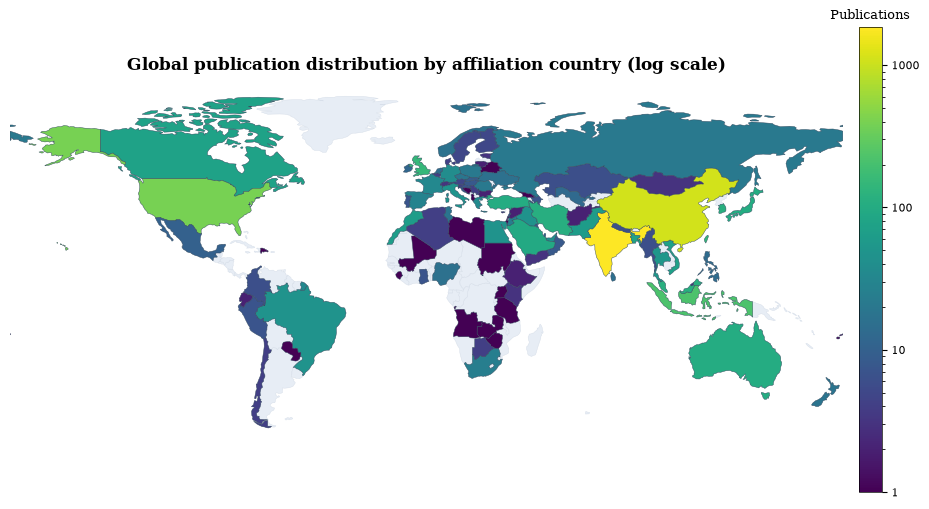

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.


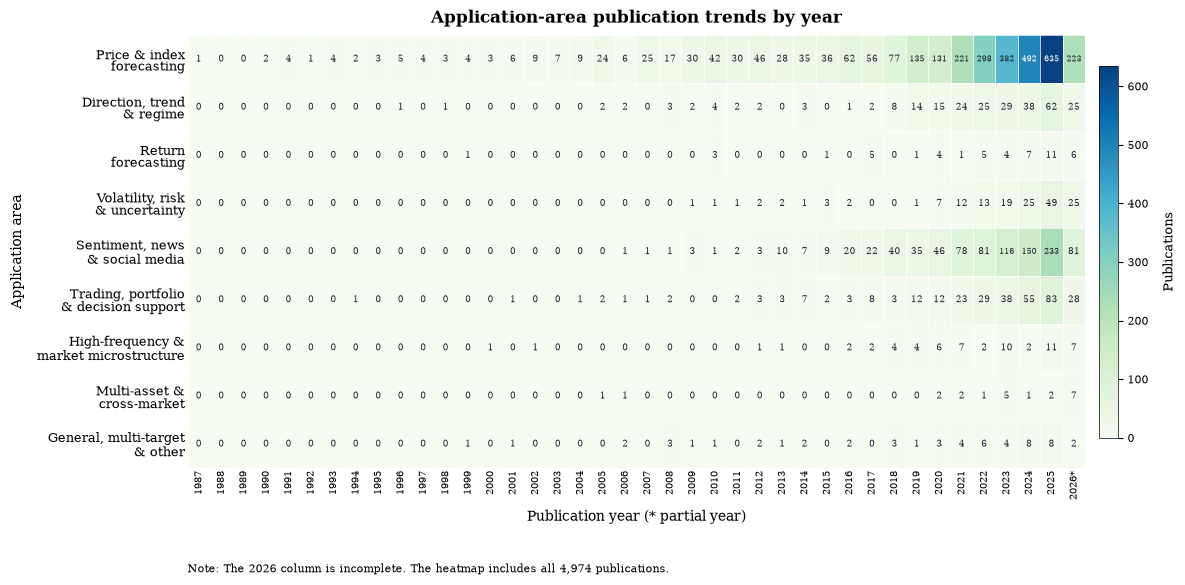


Completed successfully.

World map files:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Fig_World_Publication_Map.png
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Fig_World_Publication_Map.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Fig_World_Publication_Map.svg

Heatmap files:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Fig_Application_Area_Year_Heatmap.png
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Fig_Application_Area_Year_Heatmap.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/World_Map_Heatmap_Output_Separate_Figures/Fig_Application_Area_Year_Heatmap.svg

In [35]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd

from matplotlib.colors import LogNorm, Normalize
from matplotlib.ticker import ScalarFormatter


# ============================================================
# 1. USER SETTINGS
# ============================================================

# The folder in which the current notebook is located.
# Normally, no change is required.
PROJECT_DIR = Path.cwd()

# Leave these as None for automatic file detection.
COUNTRY_FILE = None
HEATMAP_FILE = None

# Optional local Natural Earth shapefile.
# Leave as None; the script will download it on the first run.
WORLD_SHAPEFILE = None

# Output folder will be created inside the project folder.
OUTPUT_DIR = (
    PROJECT_DIR
    / "World_Map_Heatmap_Output_Separate_Figures"
)

# True: show zero values inside heatmap cells.
# False: hide zeros for a cleaner heatmap.
SHOW_ZERO_ANNOTATIONS = True

PARTIAL_YEAR = 2026
EXPECTED_TOTAL = 4_974


# ============================================================
# 2. FONT AND FIGURE STYLE
# ============================================================

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Times",
        "DejaVu Serif"
    ],
    "font.size": 9,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. AUTOMATICALLY LOCATE INPUT FILES
# ============================================================

def find_input_file(filename: str) -> Path:
    """
    Find an input file in the notebook folder or inside the
    World_Map_Heatmap_Output folder.
    """

    candidates = [
        PROJECT_DIR / filename,
        PROJECT_DIR / "World_Map_Heatmap_Output" / filename,
        Path.cwd() / filename,
        Path.cwd() / "World_Map_Heatmap_Output" / filename,
    ]

    for path in candidates:
        if path.exists():
            return path.resolve()

    matches = list(PROJECT_DIR.rglob(filename))

    if matches:
        return matches[0].resolve()

    raise FileNotFoundError(
        f"\nCould not find:\n{filename}\n\n"
        "Place the file in the notebook folder or inside:\n"
        "World_Map_Heatmap_Output\n\n"
        "Alternatively, manually set PROJECT_DIR."
    )


if COUNTRY_FILE is None:
    country_path = find_input_file(
        "Country_Publication_Counts_Full_Counting.csv"
    )
else:
    country_path = Path(COUNTRY_FILE).resolve()


if HEATMAP_FILE is None:
    heatmap_path = find_input_file(
        "Application_Area_Year_Matrix.csv"
    )
else:
    heatmap_path = Path(HEATMAP_FILE).resolve()


print("Country file:")
print(country_path)

print("\nHeatmap file:")
print(heatmap_path)

print("\nOutput folder:")
print(OUTPUT_DIR.resolve())


# ============================================================
# 4. LOAD AND VALIDATE COUNTRY PUBLICATION COUNTS
# ============================================================

country_counts = pd.read_csv(country_path)

required_country_columns = {
    "ISO3",
    "Publications"
}

missing_country_columns = (
    required_country_columns
    - set(country_counts.columns)
)

if missing_country_columns:
    raise ValueError(
        "Country-count file is missing the following columns:\n"
        f"{sorted(missing_country_columns)}\n\n"
        f"Columns found:\n{list(country_counts.columns)}"
    )


country_counts = country_counts[
    ["ISO3", "Publications"]
].copy()

country_counts["ISO3"] = (
    country_counts["ISO3"]
    .astype(str)
    .str.strip()
    .str.upper()
)

country_counts["Publications"] = pd.to_numeric(
    country_counts["Publications"],
    errors="raise"
).astype(int)

country_counts = (
    country_counts
    .groupby("ISO3", as_index=False)["Publications"]
    .sum()
)


# Natural Earth 1:110m does not provide distinct visible polygons
# for Hong Kong and Macao.
# They are merged into China only for visual display on the map.
# The original audit CSV remains unchanged.

map_counts = country_counts.copy()

map_counts["ISO3"] = map_counts["ISO3"].replace({
    "HKG": "CHN",
    "MAC": "CHN"
})

map_counts = (
    map_counts
    .groupby("ISO3", as_index=False)["Publications"]
    .sum()
)

print(
    "\nCountries/territories in publication-count file:",
    len(country_counts)
)

print(
    "Maximum country publication count:",
    country_counts["Publications"].max()
)


# ============================================================
# 5. LOAD AND VALIDATE APPLICATION-AREA YEAR MATRIX
# ============================================================

heat_df = pd.read_csv(heatmap_path)

if "Application_Area" not in heat_df.columns:
    raise ValueError(
        "The heatmap file must contain a column named "
        "'Application_Area'.\n\n"
        f"Columns found:\n{list(heat_df.columns)}"
    )


year_columns = [
    column
    for column in heat_df.columns
    if str(column).isdigit()
    and 1900 <= int(column) <= 2100
]

if not year_columns:
    raise ValueError(
        "No publication-year columns were found in "
        "Application_Area_Year_Matrix.csv."
    )


year_columns = sorted(
    year_columns,
    key=int
)

heat_df = heat_df[
    ["Application_Area"] + year_columns
].copy()


for column in year_columns:
    heat_df[column] = pd.to_numeric(
        heat_df[column],
        errors="raise"
    ).astype(int)


heat_df = heat_df.set_index(
    "Application_Area"
)

heatmap_total = int(
    heat_df.to_numpy().sum()
)

print(
    "\nHeatmap publication total:",
    f"{heatmap_total:,}"
)

if heatmap_total != EXPECTED_TOTAL:
    raise ValueError(
        f"The heatmap contains {heatmap_total:,} publications, "
        f"but {EXPECTED_TOTAL:,} were expected.\n"
        "Check that the latest application-area matrix is being used."
    )


# ============================================================
# 6. LOAD NATURAL EARTH WORLD BOUNDARIES
# ============================================================

def load_world_boundaries() -> gpd.GeoDataFrame:
    """
    Load a local Natural Earth shapefile or download the official
    Natural Earth 1:110m country boundaries on the first run.
    """

    if WORLD_SHAPEFILE is not None:

        shapefile_path = Path(
            WORLD_SHAPEFILE
        )

        if not shapefile_path.exists():
            raise FileNotFoundError(
                "WORLD_SHAPEFILE does not exist:\n"
                f"{shapefile_path}"
            )

        return gpd.read_file(
            shapefile_path
        )


    local_candidates = [
        PROJECT_DIR
        / "Natural_Earth"
        / "ne_110m_admin_0_countries.shp",

        OUTPUT_DIR
        / "Natural_Earth"
        / "ne_110m_admin_0_countries.shp",
    ]


    for path in local_candidates:
        if path.exists():
            print(
                "\nUsing local Natural Earth shapefile:"
            )
            print(path)

            return gpd.read_file(path)


    natural_earth_directory = (
        OUTPUT_DIR
        / "Natural_Earth"
    )

    natural_earth_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    zip_path = (
        natural_earth_directory
        / "ne_110m_admin_0_countries.zip"
    )

    natural_earth_url = (
        "https://naturalearth.s3.amazonaws.com/"
        "110m_cultural/"
        "ne_110m_admin_0_countries.zip"
    )


    if not zip_path.exists():

        print(
            "\nDownloading Natural Earth country boundaries..."
        )

        try:
            urllib.request.urlretrieve(
                natural_earth_url,
                zip_path
            )

        except Exception as error:
            raise RuntimeError(
                "\nNatural Earth boundaries could not be downloaded.\n"
                "Check the internet connection and run the cell again.\n\n"
                "Alternatively, download the Natural Earth "
                "Admin 0 Countries shapefile manually and set:\n\n"
                "WORLD_SHAPEFILE = "
                "r'C:\\path\\to\\ne_110m_admin_0_countries.shp'"
            ) from error


    print(
        "\nUsing Natural Earth archive:"
    )
    print(zip_path)

    return gpd.read_file(
        f"zip://{zip_path}"
    )


world = load_world_boundaries()


# Find the ISO-3 country-code field.
iso_column = next(
    (
        column
        for column in [
            "ADM0_A3",
            "ISO_A3_EH",
            "ISO_A3",
            "iso_a3"
        ]
        if column in world.columns
    ),
    None
)


# Find the country-name field.
name_column = next(
    (
        column
        for column in [
            "ADMIN",
            "NAME",
            "NAME_EN",
            "name"
        ]
        if column in world.columns
    ),
    None
)


if iso_column is None:
    raise ValueError(
        "No ISO-3 country-code field was found in the "
        "Natural Earth boundary file.\n\n"
        f"Columns found:\n{list(world.columns)}"
    )


if name_column is None:
    raise ValueError(
        "No country-name field was found in the "
        "Natural Earth boundary file.\n\n"
        f"Columns found:\n{list(world.columns)}"
    )


world = world.copy()

world["ISO3"] = (
    world[iso_column]
    .astype(str)
    .str.upper()
)


# Correct known missing or -99 ISO codes in Natural Earth data.
country_iso_corrections = {
    "France": "FRA",
    "Norway": "NOR",
    "Kosovo": "XKX",
    "N. Cyprus": "CYP",
    "Somaliland": "SOM",
}


correction_mask = world[
    name_column
].isin(country_iso_corrections)


world.loc[
    correction_mask,
    "ISO3"
] = (
    world.loc[
        correction_mask,
        name_column
    ]
    .map(country_iso_corrections)
)


world = world.merge(
    map_counts,
    on="ISO3",
    how="left"
)


world["Publications"] = (
    world["Publications"]
    .fillna(0)
    .astype(int)
)


print(
    "\nWorld boundary polygons:",
    len(world)
)

print(
    "Countries with publication data:",
    int(
        (world["Publications"] > 0).sum()
    )
)


# ============================================================
# 7. FIGURE 1 — WORLD PUBLICATION MAP
# ============================================================

def create_world_publication_map() -> Path:

    fig, ax = plt.subplots(
        figsize=(9.2, 5.0)
    )


    positive_counts = world.loc[
        world["Publications"] > 0,
        "Publications"
    ]


    if positive_counts.empty:
        raise ValueError(
            "No positive country publication counts were found."
        )


    map_normalization = LogNorm(
        vmin=1,
        vmax=int(
            positive_counts.max()
        )
    )


    map_colormap = plt.get_cmap(
        "viridis"
    )


    # Countries with no publication data.
    world.loc[
        world["Publications"] == 0
    ].plot(
        ax=ax,
        color="#e7edf5",
        edgecolor="#d5dde8",
        linewidth=0.30
    )


    # Countries with publication data.
    world.loc[
        world["Publications"] > 0
    ].plot(
        column="Publications",
        ax=ax,
        cmap=map_colormap,
        norm=map_normalization,
        edgecolor="#34495e",
        linewidth=0.32
    )


    ax.set_xlim(
        -180,
        180
    )

    ax.set_ylim(
        -60,
        90
    )

    ax.set_axis_off()


    ax.set_title(
        "Global publication distribution by affiliation country "
        "(log scale)",
        fontweight="bold",
        fontsize=12,
        pad=8
    )


    scalar_mappable = mpl.cm.ScalarMappable(
        norm=map_normalization,
        cmap=map_colormap
    )

    scalar_mappable.set_array([])


    map_colorbar = fig.colorbar(
        scalar_mappable,
        ax=ax,
        fraction=0.028,
        pad=0.018
    )


    map_colorbar.ax.set_title(
        "Publications",
        fontsize=9,
        pad=6
    )


    map_ticks = [
        tick
        for tick in [
            1,
            10,
            100,
            1000,
            2000
        ]
        if tick <= positive_counts.max()
    ]


    map_colorbar.set_ticks(
        map_ticks
    )

    map_colorbar.ax.yaxis.set_major_formatter(
        ScalarFormatter()
    )

    map_colorbar.ax.tick_params(
        labelsize=8
    )

    map_colorbar.outline.set_linewidth(
        0.5
    )


    fig.tight_layout(
        pad=0.4
    )


    output_stem = (
        OUTPUT_DIR
        / "Fig_World_Publication_Map"
    )


    fig.savefig(
        output_stem.with_suffix(".png"),
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.04
    )


    fig.savefig(
        output_stem.with_suffix(".pdf"),
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.04
    )


    fig.savefig(
        output_stem.with_suffix(".svg"),
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.04
    )


    plt.show()
    plt.close(fig)

    return output_stem


# ============================================================
# 8. FIGURE 2 — APPLICATION-AREA YEAR HEATMAP
# ============================================================

def create_application_area_heatmap() -> Path:

    heatmap_values = heat_df.to_numpy()

    publication_years = [
        int(column)
        for column in year_columns
    ]


    row_labels = [
        "Price & index\nforecasting",

        "Direction, trend\n& regime",

        "Return\nforecasting",

        "Volatility, risk\n& uncertainty",

        "Sentiment, news\n& social media",

        "Trading, portfolio\n& decision support",

        "High-frequency &\nmarket microstructure",

        "Multi-asset &\ncross-market",

        "General, multi-target\n& other",
    ]


    if len(row_labels) != len(heat_df.index):
        row_labels = [
            str(label).replace(
                " & ",
                " &\n",
                1
            )
            for label in heat_df.index
        ]


    fig, ax = plt.subplots(
        figsize=(11.7, 6.1)
    )


    heatmap_normalization = Normalize(
        vmin=0,
        vmax=int(
            heatmap_values.max()
        )
    )


    heatmap_colormap = plt.get_cmap(
        "GnBu"
    )


    image = ax.imshow(
        heatmap_values,
        aspect="auto",
        interpolation="nearest",
        cmap=heatmap_colormap,
        norm=heatmap_normalization
    )


    # Row labels.
    ax.set_yticks(
        np.arange(
            len(row_labels)
        )
    )

    ax.set_yticklabels(
        row_labels,
        fontsize=9.2,
        linespacing=1.0
    )


    # Year labels.
    ax.set_xticks(
        np.arange(
            len(publication_years)
        )
    )


    year_labels = [
        f"{year}*"
        if year == PARTIAL_YEAR
        else str(year)
        for year in publication_years
    ]


    ax.set_xticklabels(
        year_labels,
        rotation=90,
        ha="center",
        va="top",
        fontsize=7.1
    )


    ax.set_xlabel(
        "Publication year (* partial year)",
        labelpad=7,
        fontsize=10
    )


    ax.set_ylabel(
        "Application area",
        labelpad=9,
        fontsize=10
    )


    ax.set_title(
        "Application-area publication trends by year",
        fontweight="bold",
        fontsize=12,
        pad=9
    )


    # White boundaries between cells.
    ax.set_xticks(
        np.arange(
            -0.5,
            len(publication_years),
            1
        ),
        minor=True
    )


    ax.set_yticks(
        np.arange(
            -0.5,
            len(row_labels),
            1
        ),
        minor=True
    )


    ax.grid(
        which="minor",
        color="white",
        linewidth=0.55,
        alpha=0.95
    )


    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


    ax.tick_params(
        axis="both",
        which="major",
        length=0,
        pad=2
    )


    for spine in ax.spines.values():
        spine.set_visible(False)


    # Add publication counts inside cells.
    for row_index in range(
        heatmap_values.shape[0]
    ):

        for column_index in range(
            heatmap_values.shape[1]
        ):

            value = int(
                heatmap_values[
                    row_index,
                    column_index
                ]
            )


            if (
                value == 0
                and not SHOW_ZERO_ANNOTATIONS
            ):
                continue


            cell_color = heatmap_colormap(
                heatmap_normalization(
                    value
                )
            )


            luminance = (
                0.2126 * cell_color[0]
                + 0.7152 * cell_color[1]
                + 0.0722 * cell_color[2]
            )


            annotation_color = (
                "white"
                if luminance < 0.50
                else "#1f2933"
            )


            annotation_font_size = (
                6.0
                if value >= 100
                else 6.6
            )


            ax.text(
                column_index,
                row_index,
                str(value),
                ha="center",
                va="center",
                fontsize=annotation_font_size,
                color=annotation_color,
                fontweight="medium"
            )


    heatmap_colorbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.020,
        pad=0.015
    )


    heatmap_colorbar.set_label(
        "Publications",
        rotation=90,
        labelpad=10,
        fontsize=9
    )


    heatmap_colorbar.ax.tick_params(
        labelsize=8
    )


    heatmap_colorbar.outline.set_linewidth(
        0.5
    )


    fig.text(
        0.16,
        0.015,
        "Note: The 2026 column is incomplete. "
        "The heatmap includes all 4,974 publications.",
        ha="left",
        va="bottom",
        fontsize=8
    )


    fig.subplots_adjust(
        left=0.16,
        right=0.955,
        top=0.90,
        bottom=0.19
    )


    output_stem = (
        OUTPUT_DIR
        / "Fig_Application_Area_Year_Heatmap"
    )


    fig.savefig(
        output_stem.with_suffix(".png"),
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.04
    )


    fig.savefig(
        output_stem.with_suffix(".pdf"),
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.04
    )


    fig.savefig(
        output_stem.with_suffix(".svg"),
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.04
    )


    plt.show()
    plt.close(fig)

    return output_stem


# ============================================================
# 9. GENERATE BOTH SEPARATE FIGURES
# ============================================================

world_map_output = create_world_publication_map()

heatmap_output = create_application_area_heatmap()


print("\nCompleted successfully.")

print("\nWorld map files:")
print(world_map_output.with_suffix(".png"))
print(world_map_output.with_suffix(".pdf"))
print(world_map_output.with_suffix(".svg"))

print("\nHeatmap files:")
print(heatmap_output.with_suffix(".png"))
print(heatmap_output.with_suffix(".pdf"))
print(heatmap_output.with_suffix(".svg"))

print("\nOutput folder:")
print(OUTPUT_DIR.resolve())

In [11]:
# Exact project directory shown in VS Code Explorer
PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

# Exact workbook name shown in the project folder
INPUT_XLSX = (
    PROJECT_DIR
    / "Thematic_Map_Evolution_Final_Audit (2).xlsx"
)

# Output directory
OUTPUT_DIR = (
    PROJECT_DIR
    / "Thematic_Evolution_Sankey_Python"
)

NODE_SHEET = "Evolution_Nodes"
EDGE_SHEET = "Evolution_Edges"

print("Project directory :", PROJECT_DIR)
print("Input workbook    :", INPUT_XLSX)
print("Workbook exists   :", INPUT_XLSX.exists())
print("Output directory  :", OUTPUT_DIR)

Project directory : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input workbook    : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Map_Evolution_Final_Audit (2).xlsx
Workbook exists   : True
Output directory  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Evolution_Sankey_Python


In [1]:
!pip install pandas openpyxl plotly kaleido

In [14]:
from pathlib import Path

# Current notebook working directory
PROJECT_DIR = Path.cwd().resolve()

print("Current working directory:")
print(PROJECT_DIR)

# Exact preferred workbook
preferred_file = (
    PROJECT_DIR
    / "Thematic_Map_Evolution_Final_Audit (2).xlsx"
)

if preferred_file.exists():
    INPUT_XLSX = preferred_file

else:
    # Search for matching audited workbooks
    candidates = sorted(
        PROJECT_DIR.glob(
            "Thematic_Map_Evolution_Final_Audit*.xlsx"
        )
    )

    # Exclude Windows Zone.Identifier metadata files
    candidates = [
        path
        for path in candidates
        if "Zone.Identifier" not in path.name
    ]

    if not candidates:
        raise FileNotFoundError(
            "No thematic-evolution audit workbook was found in:\n"
            f"{PROJECT_DIR}"
        )

    print("\nMatching workbooks found:")

    for index, path in enumerate(candidates, start=1):
        print(f"{index}. {path.name}")

    # Select the most recently modified matching workbook
    INPUT_XLSX = max(
        candidates,
        key=lambda path: path.stat().st_mtime,
    )

OUTPUT_DIR = (
    PROJECT_DIR
    / "Thematic_Evolution_Sankey_Python"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

NODE_SHEET = "Evolution_Nodes"
EDGE_SHEET = "Evolution_Edges"

print("\nSelected workbook:")
print(INPUT_XLSX)

print("\nWorkbook exists:")
print(INPUT_XLSX.exists())

print("\nOutput directory:")
print(OUTPUT_DIR)

Current working directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME

Selected workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Map_Evolution_Final_Audit (2).xlsx

Workbook exists:
True

Output directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Evolution_Sankey_Python


In [24]:
from __future__ import annotations

from pathlib import Path
from zipfile import ZipFile
import csv
import math
import re
import xml.etree.ElementTree as ET
from typing import Any, Iterable

import plotly.graph_objects as go


# ============================================================
# 1. USER SETTINGS
# ============================================================

PROJECT_DIR = Path(
    r"/home/harman/projects/SLR Stock Price Prediction/"
    r"Stock_Price_Prediction_SLR_ACME"
)


OUTPUT_DIR = (
    PROJECT_DIR
    / "Thematic_Evolution_Sankey_Python"
)

NODE_SHEET = "Evolution_Nodes"
EDGE_SHEET = "Evolution_Edges"

# Available measures in Evolution_Edges:
#   Inclusion
#   Inc_Weighted
#   Stability
#   PageRankIndex
#   lineage_strength
#
# Recommended composite measure:
FLOW_METRIC = "lineage_strength"

# Retain all positive audited links.
MIN_LINK_VALUE = 0.0

# None retains every link.
# Set to 3 only when the manuscript explicitly reports that
# only the three strongest outgoing links per source were shown.
TOP_K_LINKS_PER_SOURCE: int | None = None

# Show the interactive figure after generation.
SHOW_FIGURE = True


# ============================================================
# 2. JOURNAL-QUALITY FIGURE SETTINGS
# ============================================================

FIGURE_WIDTH = 1600
FIGURE_HEIGHT = 850
PNG_SCALE = 3

FONT_FAMILY = "Arial"

LABEL_FONT_SIZE = 25
PERIOD_FONT_SIZE = 31

NODE_THICKNESS = 20
NODE_LINE_WIDTH = 0.8
NODE_ALPHA = 0.88

COLOURED_LINK_ALPHA = 0.34
GREY_LINK_ALPHA = 0.075

ABBREVIATION_FONT_SIZE = 27
REGULAR_LABEL_FONT_SIZE = 21

# Scaling preserves relative ribbon widths.
FLOW_SCALE = 100.0

# Sankey domain within the figure.
DOMAIN_X0 = 0.025
DOMAIN_X1 = 0.955
DOMAIN_Y0 = 0.045
DOMAIN_Y1 = 0.900

# Vertical node-position settings.
TOP_NODE_MARGIN = 0.055
BOTTOM_NODE_MARGIN = 0.945
MIN_NODE_HEIGHT = 0.030
NODE_VERTICAL_GAP = 0.046

# Fixed period positions provide sufficient space between
# the 2023--2024 and 2025 columns.
CUSTOM_PERIOD_X = {
    1: 0.015,   # 1987--2005
    2: 0.205,   # 2006--2015
    3: 0.395,   # 2016--2020
    4: 0.585,   # 2021--2022
    5: 0.765,   # 2023--2024
    6: 0.965,   # 2025
}

# Short display labels prevent overlap.
# Full terms remain available in interactive hover text.
DISPLAY_LABEL_MAP = {
    "artificial neural networks": "ANN",
    "artificial neural network": "ANN",
    "long short-term memory": "LSTM",
    "support vector machine": "SVM",
    "autoregressive integrated moving average": "ARIMA",
    "decentralized finance": "DeFi",
    "time series analysis": "time-series analysis",
}

BOLD_DISPLAY_LABELS = {
    "ANN",
    "LSTM",
    "SVM",
    "ARIMA",
    "DeFi",
}


# ============================================================
# 3. LIGHTWEIGHT XLSX READER
# ============================================================
#
# This reader uses Python's standard library and therefore does
# not require pandas or openpyxl.
# ============================================================

MAIN_NS = (
    "http://schemas.openxmlformats.org/"
    "spreadsheetml/2006/main"
)

REL_NS = (
    "http://schemas.openxmlformats.org/"
    "officeDocument/2006/relationships"
)

PKG_REL_NS = (
    "http://schemas.openxmlformats.org/"
    "package/2006/relationships"
)


def excel_column_index(cell_reference: str) -> int:
    """Convert an Excel column reference such as A or AA to an index."""

    match = re.match(
        r"([A-Z]+)",
        cell_reference.upper(),
    )

    if not match:
        raise ValueError(
            f"Invalid Excel cell reference: "
            f"{cell_reference!r}"
        )

    value = 0

    for character in match.group(1):
        value = (
            value * 26
            + ord(character)
            - ord("A")
            + 1
        )

    return value - 1


def coerce_excel_value(
    raw: str,
    cell_type: str | None,
    shared_strings: list[str],
) -> Any:
    """Convert a raw XLSX cell value to a Python value."""

    if cell_type == "s":
        return shared_strings[int(raw)]

    if cell_type == "b":
        return raw == "1"

    if cell_type in {
        "str",
        "inlineStr",
    }:
        return raw

    try:
        number = float(raw)

        if number.is_integer():
            return int(number)

        return number

    except (TypeError, ValueError):
        return raw


def read_xlsx_sheet(
    path: Path,
    sheet_name: str,
) -> list[dict[str, Any]]:
    """
    Read one XLSX worksheet and return a list of dictionaries.

    The first worksheet row is interpreted as the header.
    """

    with ZipFile(path) as archive:

        workbook_root = ET.fromstring(
            archive.read("xl/workbook.xml")
        )

        relationships_root = ET.fromstring(
            archive.read(
                "xl/_rels/workbook.xml.rels"
            )
        )

        relationship_map = {
            element.attrib["Id"]:
                element.attrib["Target"]
            for element
            in relationships_root.findall(
                f"{{{PKG_REL_NS}}}Relationship"
            )
        }

        sheets_element = workbook_root.find(
            f"{{{MAIN_NS}}}sheets"
        )

        if sheets_element is None:
            raise ValueError(
                "The workbook does not contain "
                "a sheets collection."
            )

        sheet_target: str | None = None

        for sheet in sheets_element:

            if sheet.attrib.get("name") == sheet_name:

                relationship_id = sheet.attrib[
                    f"{{{REL_NS}}}id"
                ]

                sheet_target = relationship_map[
                    relationship_id
                ]

                break

        if sheet_target is None:

            available_sheets = [
                sheet.attrib.get("name", "")
                for sheet in sheets_element
            ]

            raise KeyError(
                f"Sheet '{sheet_name}' was not found. "
                f"Available sheets: {available_sheets}"
            )

        sheet_target = sheet_target.lstrip("/")

        if not sheet_target.startswith("xl/"):
            sheet_target = f"xl/{sheet_target}"

        shared_strings: list[str] = []

        if "xl/sharedStrings.xml" in archive.namelist():

            shared_root = ET.fromstring(
                archive.read(
                    "xl/sharedStrings.xml"
                )
            )

            for item in shared_root:

                text_value = "".join(
                    text.text or ""
                    for text in item.iter(
                        f"{{{MAIN_NS}}}t"
                    )
                )

                shared_strings.append(text_value)

        sheet_root = ET.fromstring(
            archive.read(sheet_target)
        )

        sheet_data = sheet_root.find(
            f"{{{MAIN_NS}}}sheetData"
        )

        if sheet_data is None:
            return []

        rows: list[list[Any]] = []

        for row_element in sheet_data:

            values_by_index: dict[int, Any] = {}

            for cell in row_element:

                reference = cell.attrib.get("r")

                if not reference:
                    continue

                column_index = excel_column_index(
                    reference
                )

                cell_type = cell.attrib.get("t")

                if cell_type == "inlineStr":

                    value = "".join(
                        text.text or ""
                        for text in cell.iter(
                            f"{{{MAIN_NS}}}t"
                        )
                    )

                else:

                    value_element = cell.find(
                        f"{{{MAIN_NS}}}v"
                    )

                    if (
                        value_element is None
                        or value_element.text is None
                    ):
                        value = ""

                    else:
                        value = coerce_excel_value(
                            value_element.text,
                            cell_type,
                            shared_strings,
                        )

                values_by_index[
                    column_index
                ] = value

            if values_by_index:

                maximum_index = max(
                    values_by_index
                )

                row_values = [
                    values_by_index.get(
                        index,
                        "",
                    )
                    for index
                    in range(maximum_index + 1)
                ]

                rows.append(row_values)

    if not rows:
        return []

    headers = [
        str(value).strip()
        for value in rows[0]
    ]

    records: list[dict[str, Any]] = []

    for row in rows[1:]:

        padded_row = (
            row
            + [""] * max(
                0,
                len(headers) - len(row),
            )
        )

        record = {
            headers[index]: padded_row[index]
            for index in range(len(headers))
            if headers[index]
        }

        if any(
            value not in ("", None)
            for value in record.values()
        ):
            records.append(record)

    return records


# ============================================================
# 4. DATA-VALIDATION HELPERS
# ============================================================

def require_columns(
    records: list[dict[str, Any]],
    required: Iterable[str],
    sheet_name: str,
) -> None:
    """Verify that all required columns are available."""

    if not records:
        raise ValueError(
            f"Sheet '{sheet_name}' contains "
            "no data rows."
        )

    available = set(records[0])

    missing = [
        column
        for column in required
        if column not in available
    ]

    if missing:
        raise ValueError(
            f"Sheet '{sheet_name}' is missing "
            f"columns {missing}. "
            f"Available columns: "
            f"{sorted(available)}"
        )


def as_int(
    value: Any,
    field: str,
) -> int:
    """Convert a cell value to an integer."""

    try:
        return int(float(value))

    except (TypeError, ValueError) as error:
        raise ValueError(
            f"Field '{field}' contains a "
            f"non-integer value: {value!r}"
        ) from error


def as_float(
    value: Any,
    field: str,
) -> float:
    """Convert a cell value to a finite float."""

    try:
        result = float(value)

    except (TypeError, ValueError) as error:
        raise ValueError(
            f"Field '{field}' contains a "
            f"non-numeric value: {value!r}"
        ) from error

    if not math.isfinite(result):
        raise ValueError(
            f"Field '{field}' contains a "
            f"non-finite value: {value!r}"
        )

    return result


# ============================================================
# 5. COLOUR AND LABEL HELPERS
# ============================================================

def parse_hex_colour(
    value: Any,
    alpha_override: float | None = None,
) -> str:
    """
    Convert #RRGGBB or #RRGGBBAA to Plotly rgba format.
    """

    text = str(
        value or ""
    ).strip().lstrip("#")

    if not re.fullmatch(
        r"[0-9A-Fa-f]{6}([0-9A-Fa-f]{2})?",
        text,
    ):
        return "rgba(190,190,190,0.50)"

    red = int(text[0:2], 16)
    green = int(text[2:4], 16)
    blue = int(text[4:6], 16)

    if len(text) == 8:
        source_alpha = (
            int(text[6:8], 16) / 255.0
        )
    else:
        source_alpha = 1.0

    alpha = (
        source_alpha
        if alpha_override is None
        else alpha_override
    )

    return (
        f"rgba({red},{green},{blue},"
        f"{alpha:.3f})"
    )


def is_grey_colour(value: Any) -> bool:
    """Identify neutral-grey workbook link colours."""

    text = str(
        value or ""
    ).strip().lstrip("#")

    if not re.fullmatch(
        r"[0-9A-Fa-f]{6}([0-9A-Fa-f]{2})?",
        text,
    ):
        return True

    red = int(text[0:2], 16)
    green = int(text[2:4], 16)
    blue = int(text[4:6], 16)

    return (
        max(red, green, blue)
        - min(red, green, blue)
        <= 10
    )


def display_period(group: Any) -> str:
    """Convert workbook period labels to manuscript notation."""

    text = str(group).strip()

    if text in {
        "2025-2025",
        "2025–2025",
    }:
        return "2025"

    return text.replace("-", "–")


def wrap_annotation_label(
    text: str,
    maximum_width: int = 24,
) -> str:
    """Wrap longer labels using Plotly HTML line breaks."""

    words = text.split()

    if not words:
        return ""

    lines: list[str] = []
    current: list[str] = []
    current_length = 0

    for word in words:

        proposed_length = (
            current_length
            + len(word)
            + (1 if current else 0)
        )

        if (
            current
            and proposed_length > maximum_width
        ):
            lines.append(
                " ".join(current)
            )

            current = [word]
            current_length = len(word)

        else:
            current.append(word)
            current_length = proposed_length

    if current:
        lines.append(
            " ".join(current)
        )

    return "<br>".join(lines)


# ============================================================
# 6. LOAD THE AUDITED WORKBOOK
# ============================================================

if not INPUT_XLSX.exists():
    raise FileNotFoundError(
        "Input workbook was not found.\n\n"
        f"Expected location:\n"
        f"{INPUT_XLSX}\n\n"
        "Edit PROJECT_DIR or INPUT_XLSX "
        "at the beginning of the script."
    )

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

raw_nodes = read_xlsx_sheet(
    INPUT_XLSX,
    NODE_SHEET,
)

raw_edges = read_xlsx_sheet(
    INPUT_XLSX,
    EDGE_SHEET,
)

require_columns(
    raw_nodes,
    [
        "name",
        "group",
        "slice",
        "color",
        "id",
        "freq",
    ],
    NODE_SHEET,
)

require_columns(
    raw_edges,
    [
        "from",
        "to",
        FLOW_METRIC,
        "color",
    ],
    EDGE_SHEET,
)


# ============================================================
# 7. CLEAN AND VALIDATE NODES
# ============================================================

nodes: list[dict[str, Any]] = []

for row_order, row in enumerate(raw_nodes):

    node = {
        **row,

        "name": str(
            row["name"]
        ).strip(),

        "group": str(
            row["group"]
        ).strip(),

        "slice": as_int(
            row["slice"],
            "slice",
        ),

        "id": as_int(
            row["id"],
            "id",
        ),

        "freq": as_int(
            row.get("freq", 0),
            "freq",
        ),

        "_row_order": row_order,
    }

    nodes.append(node)

node_ids = [
    row["id"]
    for row in nodes
]

if len(node_ids) != len(set(node_ids)):

    duplicate_ids = sorted({
        value
        for value in node_ids
        if node_ids.count(value) > 1
    })

    raise ValueError(
        f"Duplicate node IDs were found: "
        f"{duplicate_ids}"
    )

node_by_id = {
    row["id"]: row
    for row in nodes
}


# ============================================================
# 8. CLEAN AND VALIDATE EDGES
# ============================================================

edges: list[dict[str, Any]] = []

for row in raw_edges:

    source_id = as_int(
        row["from"],
        "from",
    )

    target_id = as_int(
        row["to"],
        "to",
    )

    raw_value = as_float(
        row[FLOW_METRIC],
        FLOW_METRIC,
    )

    if raw_value <= MIN_LINK_VALUE:
        continue

    if source_id not in node_by_id:
        raise ValueError(
            f"Edge source ID {source_id} "
            "does not exist in Evolution_Nodes."
        )

    if target_id not in node_by_id:
        raise ValueError(
            f"Edge target ID {target_id} "
            "does not exist in Evolution_Nodes."
        )

    source_slice = node_by_id[
        source_id
    ]["slice"]

    target_slice = node_by_id[
        target_id
    ]["slice"]

    if target_slice <= source_slice:
        raise ValueError(
            "A non-forward thematic link was found: "
            f"{source_id} -> {target_id}"
        )

    edge = {
        **row,

        "from_id": source_id,
        "to_id": target_id,

        "raw_value": raw_value,

        "plot_value": (
            raw_value * FLOW_SCALE
        ),

        "source_name": node_by_id[
            source_id
        ]["name"],

        "source_period": display_period(
            node_by_id[
                source_id
            ]["group"]
        ),

        "target_name": node_by_id[
            target_id
        ]["name"],

        "target_period": display_period(
            node_by_id[
                target_id
            ]["group"]
        ),
    }

    edges.append(edge)

if not edges:
    raise ValueError(
        "No links remained after applying "
        "MIN_LINK_VALUE."
    )


# ============================================================
# 9. OPTIONAL TOP-K LINK FILTER
# ============================================================

if TOP_K_LINKS_PER_SOURCE is not None:

    grouped_edges: dict[
        int,
        list[dict[str, Any]],
    ] = {}

    for edge in edges:

        grouped_edges.setdefault(
            edge["from_id"],
            [],
        ).append(edge)

    filtered_edges: list[
        dict[str, Any]
    ] = []

    for source_id in sorted(grouped_edges):

        ranked_edges = sorted(
            grouped_edges[source_id],

            key=lambda item:
                item["raw_value"],

            reverse=True,
        )

        filtered_edges.extend(
            ranked_edges[
                :TOP_K_LINKS_PER_SOURCE
            ]
        )

    edges = filtered_edges


# ============================================================
# 10. ORDER NODES AND DEFINE HORIZONTAL POSITIONS
# ============================================================

nodes.sort(
    key=lambda row: (
        row["slice"],
        row["_row_order"],
    )
)

id_to_index = {
    row["id"]: index
    for index, row in enumerate(nodes)
}

slice_values = sorted({
    row["slice"]
    for row in nodes
})

missing_positions = sorted(
    set(slice_values)
    - set(CUSTOM_PERIOD_X)
)

if missing_positions:
    raise ValueError(
        "CUSTOM_PERIOD_X does not contain "
        f"positions for slices "
        f"{missing_positions}."
    )

x_by_slice = {
    slice_number:
        CUSTOM_PERIOD_X[slice_number]
    for slice_number in slice_values
}

node_x = [
    x_by_slice[
        row["slice"]
    ]
    for row in nodes
]


# ============================================================
# 11. CALCULATE NON-OVERLAPPING VERTICAL POSITIONS
# ============================================================

def calculate_spaced_node_positions() -> list[float]:
    """
    Calculate fixed node centres while guaranteeing reasonable
    vertical separation within each publication period.
    """

    incoming: dict[int, float] = {}
    outgoing: dict[int, float] = {}

    for edge in edges:

        source_id = edge["from_id"]
        target_id = edge["to_id"]
        value = edge["plot_value"]

        outgoing[source_id] = (
            outgoing.get(
                source_id,
                0.0,
            )
            + value
        )

        incoming[target_id] = (
            incoming.get(
                target_id,
                0.0,
            )
            + value
        )

    positions = [
        0.5
    ] * len(nodes)

    for slice_number in slice_values:

        period_nodes = [
            row
            for row in nodes
            if row["slice"] == slice_number
        ]

        weights = [
            max(
                incoming.get(
                    row["id"],
                    0.0,
                ),

                outgoing.get(
                    row["id"],
                    0.0,
                ),

                1.0,
            )
            for row in period_nodes
        ]

        count = len(period_nodes)

        total_span = (
            BOTTOM_NODE_MARGIN
            - TOP_NODE_MARGIN
        )

        gap = NODE_VERTICAL_GAP

        minimum_required = (
            count * MIN_NODE_HEIGHT
            + max(
                count - 1,
                0,
            ) * gap
        )

        if minimum_required > total_span:

            gap = max(
                0.018,

                (
                    total_span
                    - count * MIN_NODE_HEIGHT
                )
                / max(
                    count - 1,
                    1,
                ),
            )

        remaining_height = max(
            total_span
            - count * MIN_NODE_HEIGHT
            - max(
                count - 1,
                0,
            ) * gap,

            0.0,
        )

        total_weight = sum(weights)

        heights = [
            MIN_NODE_HEIGHT
            + remaining_height
            * weight
            / total_weight

            for weight in weights
        ]

        cursor = TOP_NODE_MARGIN

        for row, height in zip(
            period_nodes,
            heights,
        ):

            node_index = id_to_index[
                row["id"]
            ]

            positions[node_index] = (
                cursor + height / 2.0
            )

            cursor += height + gap

    return positions


node_y = calculate_spaced_node_positions()


# ============================================================
# 12. NODE AND LINK COLOURS
# ============================================================

node_colours = [
    parse_hex_colour(
        row.get("color"),
        NODE_ALPHA,
    )
    for row in nodes
]

link_colours: list[str] = []

for edge in edges:

    colour = edge.get("color")

    if is_grey_colour(colour):
        alpha = GREY_LINK_ALPHA
    else:
        alpha = COLOURED_LINK_ALPHA

    link_colours.append(
        parse_hex_colour(
            colour,
            alpha,
        )
    )


# ============================================================
# 13. INTERACTIVE HOVER INFORMATION
# ============================================================

node_customdata = [
    [
        row["name"],
        display_period(
            row["group"]
        ),
        row["freq"],
    ]
    for row in nodes
]

link_customdata = [
    [
        edge["source_name"],
        edge["source_period"],
        edge["target_name"],
        edge["target_period"],
        edge["raw_value"],
        FLOW_METRIC,
    ]
    for edge in edges
]


# ============================================================
# 14. BUILD SANKEY WITHOUT NATIVE LABELS
# ============================================================

figure = go.Figure(
    go.Sankey(
        arrangement="fixed",
        orientation="h",

        domain={
            "x": [
                DOMAIN_X0,
                DOMAIN_X1,
            ],

            "y": [
                DOMAIN_Y0,
                DOMAIN_Y1,
            ],
        },

        node={
            "pad": 28,

            "thickness":
                NODE_THICKNESS,

            "line": {
                "color":
                    "rgba(50,50,50,0.72)",

                "width":
                    NODE_LINE_WIDTH,
            },

            # Native Plotly labels are disabled because their
            # automatic positioning causes overlap.
            "label": [
                ""
            ] * len(nodes),

            "color":
                node_colours,

            "x":
                node_x,

            "y":
                node_y,

            "customdata":
                node_customdata,

            "hovertemplate": (
                "<b>%{customdata[0]}</b><br>"
                "Period: %{customdata[1]}<br>"
                "Keyword frequency: "
                "%{customdata[2]:,}"
                "<extra></extra>"
            ),
        },

        link={
            "source": [
                id_to_index[
                    edge["from_id"]
                ]
                for edge in edges
            ],

            "target": [
                id_to_index[
                    edge["to_id"]
                ]
                for edge in edges
            ],

            "value": [
                edge["plot_value"]
                for edge in edges
            ],

            "color":
                link_colours,

            "customdata":
                link_customdata,

            "hovertemplate": (
                "<b>%{customdata[0]}</b> "
                "(%{customdata[1]})"
                " → "
                "<b>%{customdata[2]}</b> "
                "(%{customdata[3]})<br>"
                "%{customdata[5]}: "
                "%{customdata[4]:.4f}"
                "<extra></extra>"
            ),
        },
    )
)


# ============================================================
# 15. ADD PERIOD HEADINGS
# ============================================================

annotations: list[
    dict[str, Any]
] = []

for slice_number in slice_values:

    period_row = next(
        row
        for row in nodes
        if row["slice"] == slice_number
    )

    paper_x = (
        DOMAIN_X0
        + x_by_slice[slice_number]
        * (
            DOMAIN_X1 - DOMAIN_X0
        )
    )

    annotations.append({
        "x": paper_x,
        "y": 0.965,

        "xref": "paper",
        "yref": "paper",

        "text": (
            f"<b>"
            f"{display_period(period_row['group'])}"
            f"</b>"
        ),

        "showarrow": False,

        "xanchor": "center",
        "yanchor": "middle",

        "font": {
            "family":
                FONT_FAMILY,

            "size":
                PERIOD_FONT_SIZE,

            "color":
                "#2E2E2E",
        },
    })


# ============================================================
# 16. ADD ABBREVIATED CUSTOM NODE LABELS
# ============================================================

last_slice = max(
    slice_values
)

for node_index, row in enumerate(nodes):

    paper_x = (
        DOMAIN_X0
        + node_x[node_index]
        * (
            DOMAIN_X1 - DOMAIN_X0
        )
    )

    # Plotly Sankey y=0 is at the top, while annotation y=0
    # is at the bottom.
    paper_y = (
        DOMAIN_Y0
        + (
            1.0 - node_y[node_index]
        )
        * (
            DOMAIN_Y1 - DOMAIN_Y0
        )
    )

    is_last_period = (
        row["slice"] == last_slice
    )

    if is_last_period:
        label_x = paper_x - 0.010
        x_anchor = "right"
        alignment = "right"

    else:
        label_x = paper_x + 0.010
        x_anchor = "left"
        alignment = "left"

    full_label = row["name"]

    display_label = DISPLAY_LABEL_MAP.get(
        full_label.lower(),
        full_label,
    )

    display_text = wrap_annotation_label(
        display_label
    )

    if display_label in BOLD_DISPLAY_LABELS:
        display_text = (
            f"<b>{display_text}</b>"
        )

    is_abbreviation = display_label in BOLD_DISPLAY_LABELS
    display_font_size = (
    ABBREVIATION_FONT_SIZE
    if is_abbreviation
    else REGULAR_LABEL_FONT_SIZE
    
    )

    period_label = display_period(row["group"])
    keyword_key = str(row["name"]).strip().lower()
    x_shift, y_shift = LABEL_POSITION_ADJUSTMENTS.get(
    (period_label, keyword_key),
    (0.0, 0.0),)
    label_x += x_shift
    paper_y += y_shift

    annotations.append({
        "x": label_x,
        "y": paper_y,

        "xref": "paper",
        "yref": "paper",

        "text": display_text,

        "showarrow": False,

        "xanchor": x_anchor,
        "yanchor": "middle",

        "align": alignment,

        "font": {
            "family":
                FONT_FAMILY,

            "size":
                display_font_size,

            "color":
                "#303030",
        },

        # A translucent white background ensures that the
        # ribbons do not reduce label readability.
        "bgcolor":
            "rgba(255,255,255,0.76)",

        "bordercolor":
            "rgba(255,255,255,0)",

        "borderpad":
            1.5,
    })


LABEL_POSITION_ADJUSTMENTS = {
    ("2023–2024", "technical indicators"): (0.004, -0.018),
    ("2025", "sentiment analysis"): (-0.006, 0.012),
    ("2023–2024", "sentiment analysis"): (0.006, 0.006),
    ("2025", "machine learning"): (-0.006, 0.004),
}
# ============================================================
# 17. FINAL LAYOUT
# ============================================================

figure.update_layout(
    width=FIGURE_WIDTH,
    height=FIGURE_HEIGHT,

    paper_bgcolor="white",
    plot_bgcolor="white",

    font={
        "family":
            FONT_FAMILY,

        "size":
            LABEL_FONT_SIZE,

        "color":
            "#303030",
    },

    margin={
        "l": 38,
        "r": 60,
        "t": 50,
        "b": 30,
    },

    annotations=annotations,
)


# ============================================================
# 18. OUTPUT FILES
# ============================================================

base_name = (
    "Thematic_Evolution_Sankey_SCIE_Q1_Final"
)

html_path = (
    OUTPUT_DIR
    / f"{base_name}.html"
)

png_path = (
    OUTPUT_DIR
    / f"{base_name}.png"
)

svg_path = (
    OUTPUT_DIR
    / f"{base_name}.svg"
)

pdf_path = (
    OUTPUT_DIR
    / f"{base_name}.pdf"
)

nodes_csv_path = (
    OUTPUT_DIR
    / f"{base_name}_Displayed_Nodes.csv"
)

edges_csv_path = (
    OUTPUT_DIR
    / f"{base_name}_Displayed_Edges.csv"
)


# ============================================================
# 19. EXPORT INTERACTIVE HTML
# ============================================================

figure.write_html(
    html_path,

    # Produces a fully standalone HTML file.
    include_plotlyjs=True,

    full_html=True,

    config={
        "displaylogo": False,
        "responsive": True,

        "toImageButtonOptions": {
            "format": "png",
            "filename": base_name,
            "width": FIGURE_WIDTH,
            "height": FIGURE_HEIGHT,
            "scale": PNG_SCALE,
        },
    },
)


# ============================================================
# 20. EXPORT AUDIT CSV FILES
# ============================================================

with nodes_csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig",
) as file:

    node_fieldnames = list(
        nodes[0].keys()
    )

    writer = csv.DictWriter(
        file,
        fieldnames=node_fieldnames,
        extrasaction="ignore",
    )

    writer.writeheader()
    writer.writerows(nodes)


with edges_csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig",
) as file:

    edge_fieldnames = list(
        edges[0].keys()
    )

    writer = csv.DictWriter(
        file,
        fieldnames=edge_fieldnames,
        extrasaction="ignore",
    )

    writer.writeheader()
    writer.writerows(edges)


# ============================================================
# 21. EXPORT STATIC JOURNAL FILES
# ============================================================

static_export_ok = True

try:

    figure.write_image(
        png_path,

        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,
        scale=PNG_SCALE,
    )

    figure.write_image(
        svg_path,

        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,
        scale=1,
    )

    figure.write_image(
        pdf_path,

        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,
        scale=1,
    )

except Exception as error:

    static_export_ok = False

    print(
        "\nStatic export failed. "
        "The HTML and audit CSV files "
        "were still generated."
    )

    print(
        "\nInstall or upgrade Kaleido:"
    )

    print(
        "    pip install -U kaleido"
    )

    print(
        "\nFor recent Kaleido versions, "
        "install Chrome:"
    )

    print(
        "    plotly_get_chrome"
    )

    print(
        f"\nOriginal error:\n{error}"
    )


# ============================================================
# 22. DISPLAY FIGURE
# ============================================================

if SHOW_FIGURE:
    figure.show()


# ============================================================
# 23. FINAL AUDIT SUMMARY
# ============================================================

print(
    "\nSankey generation completed."
)

print(
    f"\nInput workbook:\n"
    f"{INPUT_XLSX}"
)

print(
    f"\nNodes displayed: "
    f"{len(nodes):,}"
)

print(
    f"Links displayed: "
    f"{len(edges):,}"
)

print(
    f"Flow metric: "
    f"{FLOW_METRIC}"
)

print(
    f"Minimum link value: "
    f"{MIN_LINK_VALUE}"
)

print(
    f"Top links per source: "
    f"{TOP_K_LINKS_PER_SOURCE}"
)

print(
    f"\nOutput directory:\n"
    f"{OUTPUT_DIR}"
)

print(
    f"\nInteractive HTML:\n"
    f"{html_path}"
)

if static_export_ok:

    print(
        f"\nHigh-resolution PNG:\n"
        f"{png_path}"
    )

    print(
        f"\nVector SVG:\n"
        f"{svg_path}"
    )

    print(
        f"\nVector PDF:\n"
        f"{pdf_path}"
    )

print(
    f"\nDisplayed-node audit CSV:\n"
    f"{nodes_csv_path}"
)

print(
    f"\nDisplayed-edge audit CSV:\n"
    f"{edges_csv_path}"
)


Sankey generation completed.

Input workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Map_Evolution_Final_Audit (2).xlsx

Nodes displayed: 27
Links displayed: 69
Flow metric: lineage_strength
Minimum link value: 0.0
Top links per source: None

Output directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Evolution_Sankey_Python

Interactive HTML:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Evolution_Sankey_Python/Thematic_Evolution_Sankey_SCIE_Q1_Final.html

High-resolution PNG:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Evolution_Sankey_Python/Thematic_Evolution_Sankey_SCIE_Q1_Final.png

Vector SVG:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Thematic_Evolution_Sankey_Python/Thematic_Evolution_Sankey_SCIE_Q1_Final.svg

Vector PDF:
/home/harman/projects/SLR Stock

In [10]:
from __future__ import annotations

from pathlib import Path
import csv
import re
from collections import Counter
from typing import Any

import plotly.graph_objects as go


# ============================================================
# 1. PROJECT SETTINGS
# ============================================================

PROJECT_ROOT = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

INPUT_CANDIDATES = [
    PROJECT_ROOT
    / "07_Systematic_Review_Dataset"
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "07_Reference_Outputs_Web"
    / "Section7_Final_Study_Level_Sankey_Input.csv",
]

OUTPUT_DIR = PROJECT_ROOT / "Figure17_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SHOW_FIGURE = True


# ============================================================
# 2. FROZEN MANUSCRIPT COUNTS
# ============================================================

FROZEN_PERIOD_COUNTS = {
    "2016-2020": 27,
    "2021-2022": 36,
    "2023-2024": 49,
    "2025-2026": 381,
}

FROZEN_FAMILY_COUNTS = {
    "Hybrid deep-learning models": 110,
    "Transformer/attention-based models": 68,
    "Deep-learning models": 117,
    "Metaheuristic-optimized models": 51,
    "Sentiment/NLP-driven models": 81,
    "Multimodal-fusion models": 13,
    "Graph-based models": 16,
    "Other/unclear": 2,
    "Ensemble/tree-based machine learning": 34,
    "ANN/neuro-fuzzy models": 1,
}

FROZEN_TARGET_COUNTS = {
    "Price level": 381,
    "Multi-target": 33,
    "Direction": 48,
    "Return": 17,
    "Trend or regime": 10,
    "Not reported": 4,
}

PERIOD_ORDER = list(FROZEN_PERIOD_COUNTS)
FAMILY_ORDER = list(FROZEN_FAMILY_COUNTS)
TARGET_ORDER = list(FROZEN_TARGET_COUNTS)


# ============================================================
# 3. INPUT COLUMN REQUIREMENTS
# ============================================================

REQUIRED_COLUMNS = {
    "Paper_ID",
    "Year",
    "Principal_Method_Family",
    "Target_Primary",
}


# ============================================================
# 4. NORMALIZATION ALIASES
# ============================================================

FAMILY_ALIASES = {
    "deep learning": "Deep-learning models",
    "deep learning models": "Deep-learning models",

    "hybrid deep learning": "Hybrid deep-learning models",
    "hybrid deep learning models": "Hybrid deep-learning models",

    "sentiment nlp": "Sentiment/NLP-driven models",
    "sentiment nlp driven models": "Sentiment/NLP-driven models",

    "transformer attention": "Transformer/attention-based models",
    "transformer attention based models":
        "Transformer/attention-based models",

    "metaheuristic optimized": "Metaheuristic-optimized models",
    "metaheuristic optimized models":
        "Metaheuristic-optimized models",

    "ensemble tree based machine learning":
        "Ensemble/tree-based machine learning",

    "graph based": "Graph-based models",
    "graph based models": "Graph-based models",

    "multimodal fusion": "Multimodal-fusion models",
    "multimodal fusion models": "Multimodal-fusion models",

    "other": "Other/unclear",
    "other unclear": "Other/unclear",

    "ann neuro fuzzy": "ANN/neuro-fuzzy models",
    "ann neuro fuzzy models": "ANN/neuro-fuzzy models",
}

TARGET_ALIASES = {
    "price": "Price level",
    "price level": "Price level",

    "return": "Return",

    "direction": "Direction",

    "trend regime": "Trend or regime",
    "trend or regime": "Trend or regime",

    "multi target": "Multi-target",

    "not reported": "Not reported",
}


# ============================================================
# 5. JOURNAL FIGURE SETTINGS
# ============================================================

FIGURE_WIDTH = 1800
FIGURE_HEIGHT = 1050
PNG_SCALE = 3

FONT_FAMILY = "Arial"

REGULAR_LABEL_FONT_SIZE = 19
COUNT_FONT_PERCENT = 78
COLUMN_HEADING_FONT_SIZE = 24

NODE_THICKNESS = 18
NODE_LINE_WIDTH = 0.75

# Sankey-relative node locations
PERIOD_X = 0.020
FAMILY_X = 0.500
TARGET_X = 0.970

# Leave sufficient external space for labels.
DOMAIN_X0 = 0.055
DOMAIN_X1 = 0.945
DOMAIN_Y0 = 0.040
DOMAIN_Y1 = 0.900

PERIOD_GAP = 0.050
FAMILY_GAP = 0.017
TARGET_GAP = 0.038

NODE_TOP = 0.025
NODE_BOTTOM = 0.975

PERIOD_LINK_ALPHA = 0.26
TARGET_LINK_ALPHA = 0.34

LABEL_BACKGROUND_ALPHA = 0.78

# Heading locations in complete figure coordinates.
# These are intentionally independent of node locations.
HEADING_POSITIONS = {
    "Publication period": 0.135,
    "Principal method family": 0.515,
    "Primary forecasting target": 0.865,
}


# ============================================================
# 6. COLOUR PALETTE
# ============================================================

PERIOD_COLOURS = {
    "2016-2020": "#5B8CC0",
    "2021-2022": "#4CA6A8",
    "2023-2024": "#F28E6B",
    "2025-2026": "#9B6CE3",
}

FAMILY_COLOURS = {
    "Hybrid deep-learning models": "#4CC9E8",
    "Transformer/attention-based models": "#A6D854",
    "Deep-learning models": "#F4A261",
    "Metaheuristic-optimized models": "#D96BC6",
    "Sentiment/NLP-driven models": "#E76F91",
    "Multimodal-fusion models": "#E76F51",
    "Graph-based models": "#6C8CD5",
    "Other/unclear": "#A7A7A7",
    "Ensemble/tree-based machine learning": "#E9B44C",
    "ANN/neuro-fuzzy models": "#8A9A5B",
}

TARGET_COLOURS = {
    "Price level": "#F4A261",
    "Multi-target": "#D96BC6",
    "Direction": "#E76F91",
    "Return": "#4CC9E8",
    "Trend or regime": "#8BC34A",
    "Not reported": "#E9B44C",
}


# ============================================================
# 7. DISPLAY LABELS
# ============================================================

DISPLAY_LABELS = {
    "Ensemble/tree-based machine learning":
        "Ensemble/tree-based ML",

    "Transformer/attention-based models":
        "Transformer/attention-based<br>models",

    "Hybrid deep-learning models":
        "Hybrid deep-learning<br>models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized<br>models",

    "Sentiment/NLP-driven models":
        "Sentiment/NLP-driven<br>models",

    "Multimodal-fusion models":
        "Multimodal-fusion models",

    "ANN/neuro-fuzzy models":
        "ANN/neuro-fuzzy models",

    "Trend or regime":
        "Trend or regime",

    "Not reported":
        "Not reported",
}


# ============================================================
# 8. TEXT HELPERS
# ============================================================

def clean(value: object) -> str:
    """Normalize surrounding and repeated whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def normalized_key(value: object) -> str:
    """Create a punctuation-independent lookup key."""

    text = clean(value).lower()

    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text,
    )

    return " ".join(text.split())


def hex_to_rgba(
    hexadecimal: str,
    alpha: float,
) -> str:
    """Convert #RRGGBB to Plotly rgba format."""

    text = hexadecimal.lstrip("#")

    if len(text) != 6:
        raise ValueError(
            f"Invalid hexadecimal colour: {hexadecimal}"
        )

    red = int(text[0:2], 16)
    green = int(text[2:4], 16)
    blue = int(text[4:6], 16)

    return (
        f"rgba({red},{green},{blue},{alpha:.3f})"
    )


def period_from_year(year_text: str) -> str:
    """Map publication year to the frozen review periods."""

    try:
        year = int(float(clean(year_text)))

    except ValueError as error:
        raise ValueError(
            f"Invalid publication year: {year_text!r}"
        ) from error

    if 2016 <= year <= 2020:
        return "2016-2020"

    if 2021 <= year <= 2022:
        return "2021-2022"

    if 2023 <= year <= 2024:
        return "2023-2024"

    if 2025 <= year <= 2026:
        return "2025-2026"

    raise ValueError(
        "Publication year lies outside the frozen "
        f"technical-synthesis periods: {year}"
    )


def normalize_family(value: str) -> str:
    """Normalize the principal method-family coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_FAMILY_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in FAMILY_ALIASES:
        return FAMILY_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized method family: {value!r}"
    )


def normalize_target(value: str) -> str:
    """Normalize the primary target coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_TARGET_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in TARGET_ALIASES:
        return TARGET_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized forecasting target: {value!r}"
    )


def journal_label(
    item: str,
    count: int,
) -> str:
    """Create a compact label with a smaller count line."""

    display = DISPLAY_LABELS.get(item, item)

    return (
        f"{display}<br>"
        f"<span style='font-size:{COUNT_FONT_PERCENT}%'>"
        f"(n={count:,})"
        f"</span>"
    )


# ============================================================
# 9. INPUT DISCOVERY
# ============================================================

def find_input() -> Path:
    """Locate the final 493-study Sankey input CSV."""

    for path in INPUT_CANDIDATES:
        if path.exists():
            return path

    matches: list[Path] = []

    for path in PROJECT_ROOT.rglob("*.csv"):

        try:
            with path.open(
                "r",
                encoding="utf-8-sig",
                newline="",
            ) as file:

                reader = csv.reader(file)
                header = next(reader, [])

        except Exception:
            continue

        if REQUIRED_COLUMNS.issubset(set(header)):
            matches.append(path)

    if len(matches) == 1:
        return matches[0]

    if not matches:
        raise FileNotFoundError(
            "No valid 493-row Sankey input CSV was found.\n"
            "Required columns:\n"
            "Paper_ID, Year, Principal_Method_Family, "
            "Target_Primary\n\n"
            "Expected filename:\n"
            "Section7_Final_Study_Level_Sankey_Input.csv"
        )

    raise RuntimeError(
        "More than one valid Sankey input CSV was found:\n"
        + "\n".join(str(path) for path in matches)
    )


# ============================================================
# 10. COUNT VALIDATION
# ============================================================

def assert_counts(
    label: str,
    observed: Counter,
    expected: dict[str, int],
) -> None:
    """Verify observed distributions against frozen counts."""

    observed_dict = dict(observed)

    if observed_dict == expected:
        return

    print(f"\n{label} count mismatch")

    print("\nObserved:")
    for item in expected:
        print(
            f"  {item}: "
            f"{observed_dict.get(item, 0)}"
        )

    print("\nExpected:")
    for item, count in expected.items():
        print(f"  {item}: {count}")

    unexpected = {
        item: count
        for item, count in observed_dict.items()
        if item not in expected
    }

    if unexpected:
        print("\nUnexpected categories:")
        for item, count in unexpected.items():
            print(f"  {item}: {count}")

    raise AssertionError(
        f"{label} counts do not match "
        "the frozen manuscript values."
    )


# ============================================================
# 11. NODE POSITIONING
# ============================================================

def calculate_column_centres(
    order: list[str],
    counts: dict[str, int],
    gap: float,
) -> dict[str, float]:
    """
    Calculate non-overlapping node centres proportional to
    node totals.

    Plotly Sankey uses y=0 at the top and y=1 at the bottom.
    """

    node_count = len(order)

    total_span = NODE_BOTTOM - NODE_TOP

    total_gap = (
        gap * max(node_count - 1, 0)
    )

    available_height = total_span - total_gap

    if available_height <= 0:
        raise ValueError(
            "The selected vertical gap is too large "
            "for this node column."
        )

    total_count = sum(
        counts[item]
        for item in order
    )

    cursor = NODE_TOP
    centres: dict[str, float] = {}

    for item in order:

        node_height = (
            available_height
            * counts[item]
            / total_count
        )

        centres[item] = (
            cursor + node_height / 2.0
        )

        cursor += node_height + gap

    return centres

def repel_label_positions(
    order: list[str],
    raw_positions: dict[str, float],
    minimum_gap: float,
    lower_limit: float = 0.035,
    upper_limit: float = 0.965,
) -> dict[str, float]:
    """
    Separate annotation positions without changing Sankey-node
    positions or ribbon values.

    Plotly Sankey coordinates increase from top to bottom.
    """

    ordered_items = sorted(
        order,
        key=lambda item: raw_positions[item],
    )

    adjusted = {
        item: min(
            max(raw_positions[item], lower_limit),
            upper_limit,
        )
        for item in ordered_items
    }

    # Forward pass
    for index in range(1, len(ordered_items)):

        previous_item = ordered_items[index - 1]
        current_item = ordered_items[index]

        minimum_position = (
            adjusted[previous_item]
            + minimum_gap
        )

        if adjusted[current_item] < minimum_position:
            adjusted[current_item] = minimum_position

    # Shift upward when the final label exceeds the limit.
    final_item = ordered_items[-1]

    if adjusted[final_item] > upper_limit:

        overflow = (
            adjusted[final_item]
            - upper_limit
        )

        for item in ordered_items:
            adjusted[item] -= overflow

    # Backward pass
    for index in range(
        len(ordered_items) - 2,
        -1,
        -1,
    ):

        current_item = ordered_items[index]
        next_item = ordered_items[index + 1]

        maximum_position = (
            adjusted[next_item]
            - minimum_gap
        )

        if adjusted[current_item] > maximum_position:
            adjusted[current_item] = maximum_position

    # Final lower-bound correction
    first_item = ordered_items[0]

    if adjusted[first_item] < lower_limit:

        underflow = (
            lower_limit
            - adjusted[first_item]
        )

        for item in ordered_items:
            adjusted[item] += underflow

    return adjusted


# ============================================================
# 12. CUSTOM ANNOTATIONS
# ============================================================

def add_node_annotation(
    annotations: list[dict[str, Any]],
    node_x: float,
    label_y: float,
    text: str,
    stage: str,
) -> None:
    """
    Add a manually positioned label without altering the
    underlying Sankey node or flow.
    """

    paper_x = (
        DOMAIN_X0
        + node_x
        * (DOMAIN_X1 - DOMAIN_X0)
    )

    paper_y = (
        DOMAIN_Y0
        + (1.0 - label_y)
        * (DOMAIN_Y1 - DOMAIN_Y0)
    )

    if stage == "period":

        label_x = paper_x + 0.012
        x_anchor = "left"
        alignment = "left"

    elif stage == "family":

        label_x = paper_x + 0.013
        x_anchor = "left"
        alignment = "left"

    elif stage == "target":

        label_x = paper_x - 0.012
        x_anchor = "right"
        alignment = "right"

    else:
        raise ValueError(
            f"Unsupported annotation stage: {stage}"
        )

    annotations.append(
        {
            "x": label_x,
            "y": paper_y,

            "xref": "paper",
            "yref": "paper",

            "text": text,
            "showarrow": False,

            "xanchor": x_anchor,
            "yanchor": "middle",
            "align": alignment,

            "font": {
                "family": FONT_FAMILY,
                "size": REGULAR_LABEL_FONT_SIZE,
                "color": "#303030",
            },

            "bgcolor": (
                "rgba(255,255,255,"
                f"{LABEL_BACKGROUND_ALPHA})"
            ),

            "bordercolor":
                "rgba(255,255,255,0)",

            "borderpad": 1.2,
        }
    )


# ============================================================
# 13. MAIN WORKFLOW
# ============================================================

def main() -> None:

    input_path = find_input()

    print("Input file:")
    print(input_path)

    with input_path.open(
        "r",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        rows = list(
            csv.DictReader(file)
        )

    if len(rows) != 493:
        raise AssertionError(
            f"Expected 493 rows; found {len(rows)}."
        )

    paper_ids = [
        clean(row["Paper_ID"])
        for row in rows
    ]

    if any(not paper_id for paper_id in paper_ids):
        raise AssertionError(
            "One or more Paper_ID values are blank."
        )

    if len(set(paper_ids)) != 493:

        duplicates = sorted(
            paper_id
            for paper_id, count
            in Counter(paper_ids).items()
            if count > 1
        )

        raise AssertionError(
            "Paper_ID values are not unique:\n"
            + "\n".join(duplicates)
        )

    normalized_rows: list[dict[str, str]] = []

    for row in rows:

        normalized_rows.append(
            {
                "Paper_ID": clean(
                    row["Paper_ID"]
                ),

                "Period": period_from_year(
                    row["Year"]
                ),

                "Method_Family": normalize_family(
                    row["Principal_Method_Family"]
                ),

                "Target": normalize_target(
                    row["Target_Primary"]
                ),
            }
        )

    period_counts = Counter(
        row["Period"]
        for row in normalized_rows
    )

    family_counts = Counter(
        row["Method_Family"]
        for row in normalized_rows
    )

    target_counts = Counter(
        row["Target"]
        for row in normalized_rows
    )

    assert_counts(
        "Period",
        period_counts,
        FROZEN_PERIOD_COUNTS,
    )

    assert_counts(
        "Method-family",
        family_counts,
        FROZEN_FAMILY_COUNTS,
    )

    assert_counts(
        "Target",
        target_counts,
        FROZEN_TARGET_COUNTS,
    )

    period_family = Counter(
        (
            row["Period"],
            row["Method_Family"],
        )
        for row in normalized_rows
    )

    family_target = Counter(
        (
            row["Method_Family"],
            row["Target"],
        )
        for row in normalized_rows
    )

    if sum(period_family.values()) != 493:
        raise AssertionError(
            "Period-to-method flows do not total 493."
        )

    if sum(family_target.values()) != 493:
        raise AssertionError(
            "Method-to-target flows do not total 493."
        )


# ========================================================
# 14. NODE DEFINITIONS
# ========================================================

node_items = (
    PERIOD_ORDER
    + FAMILY_ORDER
    + TARGET_ORDER
)

node_stage = (
    ["period"] * len(PERIOD_ORDER)
    + ["family"] * len(FAMILY_ORDER)
    + ["target"] * len(TARGET_ORDER)
)

node_counts = (
    [
        FROZEN_PERIOD_COUNTS[item]
        for item in PERIOD_ORDER
    ]
    + [
        FROZEN_FAMILY_COUNTS[item]
        for item in FAMILY_ORDER
    ]
    + [
        FROZEN_TARGET_COUNTS[item]
        for item in TARGET_ORDER
    ]
)

node_colours = (
    [
        PERIOD_COLOURS[item]
        for item in PERIOD_ORDER
    ]
    + [
        FAMILY_COLOURS[item]
        for item in FAMILY_ORDER
    ]
    + [
        TARGET_COLOURS[item]
        for item in TARGET_ORDER
    ]
)

period_y = calculate_column_centres(
    PERIOD_ORDER,
    FROZEN_PERIOD_COUNTS,
    PERIOD_GAP,
)

family_y = calculate_column_centres(
    FAMILY_ORDER,
    FROZEN_FAMILY_COUNTS,
    FAMILY_GAP,
)

target_y = calculate_column_centres(
    TARGET_ORDER,
    FROZEN_TARGET_COUNTS,
    TARGET_GAP,
)

node_x = (
    [PERIOD_X] * len(PERIOD_ORDER)
    + [FAMILY_X] * len(FAMILY_ORDER)
    + [TARGET_X] * len(TARGET_ORDER)
)

node_y = (
    [
        period_y[item]
        for item in PERIOD_ORDER
    ]
    + [
        family_y[item]
        for item in FAMILY_ORDER
    ]
    + [
        target_y[item]
        for item in TARGET_ORDER
    ]
)

node_index = {
    item: index
    for index, item
    in enumerate(node_items)
}

node_customdata = [
    [
        item,
        stage,
        count,
    ]
    for item, stage, count
    in zip(
        node_items,
        node_stage,
        node_counts,
    )
]

# Node positions determine ribbon geometry.
# Label positions are independently separated to prevent overlap.

period_label_y = repel_label_positions(
    order=PERIOD_ORDER,
    raw_positions=period_y,
    minimum_gap=0.100,
)

family_label_y = repel_label_positions(
    order=FAMILY_ORDER,
    raw_positions=family_y,
    minimum_gap=0.057,
)

target_label_y = repel_label_positions(
    order=TARGET_ORDER,
    raw_positions=target_y,
    minimum_gap=0.075,
)


    # ========================================================
    # 15. LINK DEFINITIONS
    # ========================================================

    sources: list[int] = []
    targets: list[int] = []
    values: list[int] = []
    link_colours: list[str] = []
    link_customdata: list[list[Any]] = []

    flow_rows: list[dict[str, Any]] = []

    for period in PERIOD_ORDER:

        for family in FAMILY_ORDER:

            count = period_family.get(
                (period, family),
                0,
            )

            if count <= 0:
                continue

            sources.append(
                node_index[period]
            )

            targets.append(
                node_index[family]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    FAMILY_COLOURS[family],
                    PERIOD_LINK_ALPHA,
                )
            )

            link_customdata.append(
                [
                    period,
                    family,
                    count,
                    "Publication period → method family",
                ]
            )

            flow_rows.append(
                {
                    "Stage": "Period_to_Method",
                    "Source": period,
                    "Target": family,
                    "Studies": count,
                }
            )

    for family in FAMILY_ORDER:

        for target in TARGET_ORDER:

            count = family_target.get(
                (family, target),
                0,
            )

            if count <= 0:
                continue

            sources.append(
                node_index[family]
            )

            targets.append(
                node_index[target]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    FAMILY_COLOURS[family],
                    TARGET_LINK_ALPHA,
                )
            )

            link_customdata.append(
                [
                    family,
                    target,
                    count,
                    "Method family → forecasting target",
                ]
            )

            flow_rows.append(
                {
                    "Stage": "Method_to_Target",
                    "Source": family,
                    "Target": target,
                    "Studies": count,
                }
            )


    # ========================================================
    # 16. BUILD THE SANKEY
    # ========================================================

    figure = go.Figure(
        go.Sankey(
            arrangement="fixed",
            orientation="h",

            domain={
                "x": [DOMAIN_X0, DOMAIN_X1],
                "y": [DOMAIN_Y0, DOMAIN_Y1],
            },

            node={
                "pad": 18,
                "thickness": NODE_THICKNESS,

                "line": {
                    "color":
                        "rgba(45,45,45,0.72)",

                    "width":
                        NODE_LINE_WIDTH,
                },

                # Labels are added as custom annotations.
                "label": [""] * len(node_items),

                "color": node_colours,
                "x": node_x,
                "y": node_y,

                "customdata":
                    node_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b><br>"
                    "Stage: %{customdata[1]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },

            link={
                "source": sources,
                "target": targets,
                "value": values,
                "color": link_colours,

                "customdata":
                    link_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b>"
                    " → "
                    "<b>%{customdata[1]}</b><br>"
                    "%{customdata[3]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },
        )
    )


    # ========================================================
    # 17. COLUMN HEADINGS
    # ========================================================

    annotations: list[dict[str, Any]] = []

    heading_specs = [
        (
            PERIOD_X,
            "Publication period",
        ),
        (
            FAMILY_X,
            "Principal method family",
        ),
        (
            TARGET_X,
            "Primary forecasting target",
        ),
    ]

    for sankey_x, heading in heading_specs:

        paper_x = (
            DOMAIN_X0
            + sankey_x
            * (DOMAIN_X1 - DOMAIN_X0)
        )

        annotations.append(
            {
                "x": paper_x,
                "y": 0.975,

                "xref": "paper",
                "yref": "paper",

                "text": f"<b>{heading}</b>",

                "showarrow": False,

                "xanchor": "center",
                "yanchor": "middle",

                "font": {
                    "family": FONT_FAMILY,
                    "size":
                        COLUMN_HEADING_FONT_SIZE,
                    "color": "#252525",
                },
            }
        )


    # ========================================================
    # 18. CUSTOM NODE LABELS
    # ========================================================

    for item in PERIOD_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=PERIOD_X,
            node_y=period_y[item],
            text=journal_label(
                item,
                FROZEN_PERIOD_COUNTS[item],
            ),
            stage="period",
        )

    for item in FAMILY_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=FAMILY_X,
            node_y=family_y[item],
            text=journal_label(
                item,
                FROZEN_FAMILY_COUNTS[item],
            ),
            stage="family",
        )

    for item in TARGET_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=TARGET_X,
            node_y=target_y[item],
            text=journal_label(
                item,
                FROZEN_TARGET_COUNTS[item],
            ),
            stage="target",
        )


    # ========================================================
    # 19. FINAL LAYOUT
    # ========================================================

    figure.update_layout(
        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,

        paper_bgcolor="white",
        plot_bgcolor="white",

        font={
            "family": FONT_FAMILY,
            "size":
                REGULAR_LABEL_FONT_SIZE,
            "color": "#303030",
        },

        margin={
            "l": 30,
            "r": 42,
            "t": 55,
            "b": 28,
        },

        annotations=annotations,
    )


    # ========================================================
    # 20. OUTPUT PATHS
    # ========================================================

    base_name = (
        "Figure17_Period_Method_Target_"
        "Sankey_SCIE_Q1"
    )

    pdf_path = (
        OUTPUT_DIR
        / f"{base_name}.pdf"
    )

    svg_path = (
        OUTPUT_DIR
        / f"{base_name}.svg"
    )

    png_path = (
        OUTPUT_DIR
        / f"{base_name}.png"
    )

    html_path = (
        OUTPUT_DIR
        / f"{base_name}.html"
    )

    flow_path = (
        OUTPUT_DIR
        / f"{base_name}_Flows.csv"
    )

    audit_path = (
        OUTPUT_DIR
        / f"{base_name}_Audit.csv"
    )


    # ========================================================
    # 21. EXPORT INTERACTIVE HTML
    # ========================================================

    figure.write_html(
        html_path,

        include_plotlyjs=True,
        full_html=True,

        config={
            "displaylogo": False,
            "responsive": True,

            "toImageButtonOptions": {
                "format": "png",
                "filename": base_name,
                "width": FIGURE_WIDTH,
                "height": FIGURE_HEIGHT,
                "scale": PNG_SCALE,
            },
        },
    )


    # ========================================================
    # 22. EXPORT VECTOR AND RASTER FILES
    # ========================================================

    static_export_ok = True

    try:

        figure.write_image(
            pdf_path,
            format="pdf",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        figure.write_image(
            svg_path,
            format="svg",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        figure.write_image(
            png_path,
            format="png",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=PNG_SCALE,
        )

    except Exception as error:

        static_export_ok = False

        print(
            "\nHTML and audit files were generated, "
            "but static export failed."
        )

        print(
            "\nInstall or update Kaleido:"
        )

        print(
            "    pip install -U kaleido"
        )

        print(
            "\nRecent Kaleido versions may require Chrome:"
        )

        print(
            "    plotly_get_chrome"
        )

        print(
            f"\nExport error:\n{error}"
        )


    # ========================================================
    # 23. FLOW AUDIT CSV
    # ========================================================

    with flow_path.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=[
                "Stage",
                "Source",
                "Target",
                "Studies",
            ],
        )

        writer.writeheader()
        writer.writerows(flow_rows)


    # ========================================================
    # 24. VALIDATION AUDIT CSV
    # ========================================================

    with audit_path.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        writer = csv.writer(file)

        writer.writerow(
            [
                "Audit_Item",
                "Observed",
                "Required",
                "Status",
            ]
        )

        writer.writerow(
            [
                "Study rows",
                len(normalized_rows),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Unique Paper_ID",
                len(set(paper_ids)),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Period-to-method total",
                sum(period_family.values()),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Method-to-target total",
                sum(family_target.values()),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Period counts",
                str(dict(period_counts)),
                str(FROZEN_PERIOD_COUNTS),
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Method-family counts",
                str(dict(family_counts)),
                str(FROZEN_FAMILY_COUNTS),
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Target counts",
                str(dict(target_counts)),
                str(FROZEN_TARGET_COUNTS),
                "PASS",
            ]
        )


    # ========================================================
    # 25. DISPLAY AND SUMMARY
    # ========================================================

    if SHOW_FIGURE:
        figure.show()

    print("\nFigure 17 Sankey audit passed.")

    print("\nInput:")
    print(input_path)

    print("\nOutput directory:")
    print(OUTPUT_DIR)

    print("\nFlow audit:")
    print(flow_path)

    print("\nValidation audit:")
    print(audit_path)

    print("\nInteractive HTML:")
    print(html_path)

    if static_export_ok:

        print("\nVector PDF:")
        print(pdf_path)

        print("\nVector SVG:")
        print(svg_path)

        print("\nHigh-resolution PNG:")
        print(png_path)


if __name__ == "__main__":
    main()

IndentationError: unexpected indent (51764836.py, line 981)

In [32]:


%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/generate_fig15_period_method_target_sankey.py"


Input file:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv



Figure 17 generation completed.
All frozen-count audits passed.

Input:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Output directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output

Interactive HTML:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output/Figure17_Period_Method_Target_Sankey_SCIE_Q1_Final.html

Flow audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output/Figure17_Period_Method_Target_Sankey_SCIE_Q1_Final_Flows.csv

Validation audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output/Figure17_Period_Method_Target_Sankey_SCIE_Q1_Final_Audit.csv

Vector PDF:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output/Figure17_Period_Method_Targ

In [ ]:

%run "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Figure17_Q1_Complete_Code_CORRECTED.py"
# home\harman\projects\SLR Stock Price Prediction\Stock_Price_Prediction_SLR_ACME\14_Sankey

Project directory : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input directory   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey
Method workbook   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section7_Sankey_Working_COMPLETED.xlsx
Audit workbook    : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section5_5_Review_264_Closed_45_Pending.xlsx
Output directory  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure18_Output

All required input files were found successfully.

Merged records: 493

METHOD-FAMILY TOTALS
Method_Group
Deep and hybrid deep learning         227
Transformer, graph, and multimodal     97
Metaheuristic and ensemble             85
Sentiment and NLP                      81
Sparse and other families               3
Name: count, dtype: int64

VALIDATION TOTALS
Val

In [42]:
from __future__ import annotations

from pathlib import Path
from typing import Any

import pandas as pd
import plotly.graph_objects as go


# ================================================================
# FIGURE 19
# Asset scope -> Forecast-horizon reporting
# -> Decision and robustness evidence
# ================================================================


# ----------------------------------------------------------------
# 1. PROJECT SETTINGS
# ----------------------------------------------------------------

FIGURE_NUMBER = 19

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

INPUT_CANDIDATES = [
    PROJECT_DIR
    / "Figure17_Output"
    / "Figure17_Study_Level_Audit.csv",

    PROJECT_DIR
    / "Figure17_Study_Level_Audit.csv",

    Path("/mnt/data/Figure17_Study_Level_Audit.csv"),
]

OUTPUT_DIR = (
    PROJECT_DIR
    / f"Figure{FIGURE_NUMBER}_Output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SHOW_FIGURE = True


# ----------------------------------------------------------------
# 2. SCIE Q1 FIGURE SETTINGS
# ----------------------------------------------------------------

FIGURE_WIDTH = 1700
FIGURE_HEIGHT = 1000
PNG_SCALE = 3

FONT_FAMILY = "Arial"

REGULAR_LABEL_FONT_SIZE = 23
SMALL_LABEL_FONT_SIZE = 20
COLUMN_HEADING_FONT_SIZE = 29
COUNT_FONT_PERCENT = 78

NODE_THICKNESS = 18
NODE_LINE_WIDTH = 0.75

# Fixed horizontal positions.
ASSET_X = 0.020
HORIZON_X = 0.500
EVIDENCE_X = 0.980

# Sankey domain in the complete figure.
DOMAIN_X0 = 0.060
DOMAIN_X1 = 0.940
DOMAIN_Y0 = 0.045
DOMAIN_Y1 = 0.895

# Available vertical space inside the Sankey.
NODE_TOP = 0.030
NODE_BOTTOM = 0.970

ASSET_GAP = 0.035
HORIZON_GAP = 0.070
EVIDENCE_GAP = 0.085

ASSET_TO_HORIZON_ALPHA = 0.37
HORIZON_TO_EVIDENCE_ALPHA = 0.42

LABEL_BACKGROUND_ALPHA = 0.64
LABEL_BORDER_PAD = 0.70

CONNECTOR_ALPHA = 0.22
CONNECTOR_WIDTH = 0.55


# ----------------------------------------------------------------
# 3. COLUMN HEADINGS
# ----------------------------------------------------------------

HEADING_SPECS = [
    {
        "text": "Asset scope",
        "x": 0.145,
    },
    {
        "text": "Forecast-horizon<br>reporting",
        "x": 0.500,
    },
    {
        "text": "Decision and robustness<br>evidence",
        "x": 0.835,
    },
]


# ----------------------------------------------------------------
# 4. FROZEN CATEGORY ORDER AND COUNTS
# ----------------------------------------------------------------

ASSET_ORDER = [
    "Multiple stocks",
    "Not reported",
    "Single stock",
    "Index based",
    "Cross-market or portfolio",
]

HORIZON_ORDER = [
    "Not reported",
    "Single stated horizon",
    "Multiple horizons",
]

EVIDENCE_ORDER = [
    "Neither established",
    "Economic evaluation only",
    "Robustness evaluation only",
    "Economic and robustness evidence",
]

FROZEN_ASSET_COUNTS = {
    "Multiple stocks": 153,
    "Not reported": 138,
    "Single stock": 104,
    "Index based": 84,
    "Cross-market or portfolio": 14,
}

FROZEN_HORIZON_COUNTS = {
    "Not reported": 326,
    "Single stated horizon": 122,
    "Multiple horizons": 45,
}

FROZEN_EVIDENCE_COUNTS = {
    "Neither established": 437,
    "Economic evaluation only": 37,
    "Robustness evaluation only": 18,
    "Economic and robustness evidence": 1,
}


# ----------------------------------------------------------------
# 5. REQUIRED STUDY-LEVEL COLUMNS
# ----------------------------------------------------------------

REQUIRED_COLUMNS = {
    "Paper_ID",
    "Asset_Scope_Group",
    "Horizon_Reporting",
    "Decision_Robustness_Tier",
}


# ----------------------------------------------------------------
# 6. DISPLAY LABELS
# ----------------------------------------------------------------

DISPLAY_LABELS = {
    "Multiple stocks":
        "Multiple stocks",

    "Not reported":
        "Not reported",

    "Single stock":
        "Single stock",

    "Index based":
        "Index based",

    "Cross-market or portfolio":
        "Cross-market or<br>portfolio",

    "Single stated horizon":
        "Single stated horizon",

    "Multiple horizons":
        "Multiple horizons",

    "Neither established":
        "Neither established",

    "Economic evaluation only":
        "Economic evaluation only",

    "Robustness evaluation only":
        "Robustness evaluation only",

    "Economic and robustness evidence":
        "Economic and<br>robustness evidence",
}

SMALL_ASSET_LABELS = {
    "Cross-market or portfolio",
}

SMALL_HORIZON_LABELS: set[str] = set()

SMALL_EVIDENCE_LABELS = {
    "Economic evaluation only",
    "Robustness evaluation only",
    "Economic and robustness evidence",
}


# ----------------------------------------------------------------
# 7. COLOUR-BLIND-CONSCIOUS PALETTE
# ----------------------------------------------------------------

ASSET_COLOURS = {
    "Multiple stocks": "#75B7D3",
    "Not reported": "#B0B7C6",
    "Single stock": "#8BCF86",
    "Index based": "#F2A064",
    "Cross-market or portfolio": "#92A8D1",
}

NEUTRAL_NODE_COLOUR = "#D2E7EA"
NEUTRAL_NODE_BORDER = "#607D85"
FONT_COLOUR = "#2F3D43"


# ----------------------------------------------------------------
# 8. GENERAL HELPERS
# ----------------------------------------------------------------

def clean(value: object) -> str:
    """Remove leading, trailing, and repeated whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def find_input_file() -> Path:
    """Find the verified 493-study audit CSV."""

    for candidate in INPUT_CANDIDATES:

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        "Figure17_Study_Level_Audit.csv was not found.\n\n"
        "Checked these locations:\n"
        + "\n".join(
            str(path)
            for path in INPUT_CANDIDATES
        )
    )


def hex_to_rgba(
    hex_colour: str,
    alpha: float,
) -> str:
    """Convert #RRGGBB to Plotly RGBA notation."""

    cleaned = (
        hex_colour
        .strip()
        .lstrip("#")
    )

    if len(cleaned) != 6:
        raise ValueError(
            f"Invalid hexadecimal colour: {hex_colour!r}"
        )

    red = int(cleaned[0:2], 16)
    green = int(cleaned[2:4], 16)
    blue = int(cleaned[4:6], 16)

    return (
        f"rgba({red},{green},{blue},{alpha:.3f})"
    )


def journal_label(
    category: str,
    count: int,
) -> str:
    """Create a manuscript label with a smaller count line."""

    display = DISPLAY_LABELS.get(
        category,
        category,
    )

    return (
        f"{display}"
        f"<br>"
        f"<span style='font-size:{COUNT_FONT_PERCENT}%'>"
        f"(n={count:,})"
        f"</span>"
    )


def assert_category_counts(
    label: str,
    observed: pd.Series,
    expected: dict[str, int],
) -> None:
    """Verify observed category totals against frozen values."""

    observed_dict = {
        category: int(observed.get(category, 0))
        for category in expected
    }

    if observed_dict == expected:
        return

    print(f"\n{label} count mismatch")

    print("\nObserved:")
    for category, count in observed_dict.items():
        print(f"  {category}: {count}")

    print("\nExpected:")
    for category, count in expected.items():
        print(f"  {category}: {count}")

    raise AssertionError(
        f"{label} counts do not match "
        "the frozen manuscript totals."
    )


# ----------------------------------------------------------------
# 9. CALCULATE FIXED NODE CENTRES
# ----------------------------------------------------------------

def calculate_column_centres(
    order: list[str],
    counts: dict[str, int],
    gap: float,
) -> dict[str, float]:
    """
    Calculate separated vertical node centres proportional to counts.

    Coordinates increase from the top of the Sankey domain.
    """

    if not order:
        raise ValueError(
            "The category order cannot be empty."
        )

    total_count = sum(
        int(counts[category])
        for category in order
    )

    if total_count <= 0:
        raise ValueError(
            "The total node count must be positive."
        )

    total_span = (
        NODE_BOTTOM
        - NODE_TOP
    )

    total_gap = (
        gap
        * max(
            len(order) - 1,
            0,
        )
    )

    available_height = (
        total_span
        - total_gap
    )

    if available_height <= 0:
        raise ValueError(
            "The vertical gap is too large for "
            "the available Sankey space."
        )

    centres: dict[str, float] = {}

    cursor = NODE_TOP

    for category in order:

        height = (
            available_height
            * int(counts[category])
            / total_count
        )

        centres[category] = (
            cursor
            + height / 2.0
        )

        cursor += (
            height
            + gap
        )

    return centres


# ----------------------------------------------------------------
# 10. COORDINATE CONVERSION
# ----------------------------------------------------------------

def sankey_to_paper_x(
    sankey_x: float,
) -> float:
    """Convert Sankey-domain x to full-figure x."""

    return (
        DOMAIN_X0
        + sankey_x
        * (
            DOMAIN_X1
            - DOMAIN_X0
        )
    )


def sankey_to_paper_y(
    sankey_y: float,
) -> float:
    """Convert top-origin Sankey y to bottom-origin paper y."""

    return (
        DOMAIN_Y0
        + (
            1.0
            - sankey_y
        )
        * (
            DOMAIN_Y1
            - DOMAIN_Y0
        )
    )


# ----------------------------------------------------------------
# 11. MAIN WORKFLOW
# ----------------------------------------------------------------

def main() -> None:

    input_file = find_input_file()

    print("Input file :", input_file)
    print("Output dir:", OUTPUT_DIR)

    df = pd.read_csv(
        input_file,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    df.columns = [
        clean(column)
        for column in df.columns
    ]

    for column in df.columns:

        df[column] = (
            df[column]
            .fillna("")
            .astype(str)
            .map(clean)
        )

    print(f"Rows loaded: {len(df):,}")

    if len(df) != 493:
        raise AssertionError(
            f"Expected 493 study rows; found {len(df)}."
        )

    missing_columns = sorted(
        REQUIRED_COLUMNS
        - set(df.columns)
    )

    if missing_columns:
        raise KeyError(
            "Required columns are missing:\n"
            f"{missing_columns}\n\n"
            "Available columns:\n"
            f"{list(df.columns)}"
        )

    if df["Paper_ID"].eq("").any():
        raise AssertionError(
            "One or more Paper_ID values are blank."
        )

    if not df["Paper_ID"].is_unique:

        duplicate_ids = (
            df.loc[
                df["Paper_ID"].duplicated(
                    keep=False
                ),
                "Paper_ID",
            ]
            .sort_values()
            .unique()
            .tolist()
        )

        raise AssertionError(
            "Duplicate Paper_ID values were found:\n"
            f"{duplicate_ids[:10]}"
        )


    # ============================================================
    # 12. USE FINAL MANUSCRIPT-READY CATEGORIES
    # ============================================================

    df["Asset_Category"] = (
        df["Asset_Scope_Group"]
        .map(clean)
    )

    df["Horizon_Category"] = (
        df["Horizon_Reporting"]
        .map(clean)
    )

    df["Evidence_Category"] = (
        df["Decision_Robustness_Tier"]
        .map(clean)
    )

    unexpected_assets = sorted(
        set(df["Asset_Category"])
        - set(ASSET_ORDER)
    )

    unexpected_horizons = sorted(
        set(df["Horizon_Category"])
        - set(HORIZON_ORDER)
    )

    unexpected_evidence = sorted(
        set(df["Evidence_Category"])
        - set(EVIDENCE_ORDER)
    )

    if unexpected_assets:
        raise ValueError(
            "Unexpected Asset_Scope_Group values:\n"
            f"{unexpected_assets}"
        )

    if unexpected_horizons:
        raise ValueError(
            "Unexpected Horizon_Reporting values:\n"
            f"{unexpected_horizons}"
        )

    if unexpected_evidence:
        raise ValueError(
            "Unexpected Decision_Robustness_Tier values:\n"
            f"{unexpected_evidence}"
        )


    # ============================================================
    # 13. VERIFY FROZEN COUNTS
    # ============================================================

    asset_counts = (
        df["Asset_Category"]
        .value_counts()
        .reindex(
            ASSET_ORDER,
            fill_value=0,
        )
    )

    horizon_counts = (
        df["Horizon_Category"]
        .value_counts()
        .reindex(
            HORIZON_ORDER,
            fill_value=0,
        )
    )

    evidence_counts = (
        df["Evidence_Category"]
        .value_counts()
        .reindex(
            EVIDENCE_ORDER,
            fill_value=0,
        )
    )

    assert_category_counts(
        "Asset scope",
        asset_counts,
        FROZEN_ASSET_COUNTS,
    )

    assert_category_counts(
        "Forecast-horizon reporting",
        horizon_counts,
        FROZEN_HORIZON_COUNTS,
    )

    assert_category_counts(
        "Decision and robustness evidence",
        evidence_counts,
        FROZEN_EVIDENCE_COUNTS,
    )

    print("\nASSET-SCOPE TOTALS")
    print(asset_counts)

    print("\nHORIZON-REPORTING TOTALS")
    print(horizon_counts)

    print("\nEVIDENCE TOTALS")
    print(evidence_counts)


    # ============================================================
    # 14. CREATE FLOW TABLES
    # ============================================================

    asset_horizon = (
        df.groupby(
            [
                "Asset_Category",
                "Horizon_Category",
            ],
            observed=True,
        )
        .size()
        .reset_index(name="Count")
    )

    asset_horizon = (
        asset_horizon[
            asset_horizon["Count"] > 0
        ]
        .copy()
    )

    asset_horizon_evidence = (
        df.groupby(
            [
                "Asset_Category",
                "Horizon_Category",
                "Evidence_Category",
            ],
            observed=True,
        )
        .size()
        .reset_index(name="Count")
    )

    asset_horizon_evidence = (
        asset_horizon_evidence[
            asset_horizon_evidence["Count"] > 0
        ]
        .copy()
    )

    if int(asset_horizon["Count"].sum()) != 493:
        raise AssertionError(
            "Asset-to-horizon flows do not total 493."
        )

    if int(
        asset_horizon_evidence["Count"].sum()
    ) != 493:
        raise AssertionError(
            "Horizon-to-evidence flows do not total 493."
        )


    # ============================================================
    # 15. CALCULATE NODE POSITIONS
    # ============================================================

    asset_y = calculate_column_centres(
        ASSET_ORDER,
        FROZEN_ASSET_COUNTS,
        ASSET_GAP,
    )

    horizon_y = calculate_column_centres(
        HORIZON_ORDER,
        FROZEN_HORIZON_COUNTS,
        HORIZON_GAP,
    )

    evidence_y = calculate_column_centres(
        EVIDENCE_ORDER,
        FROZEN_EVIDENCE_COUNTS,
        EVIDENCE_GAP,
    )

    asset_label_y = asset_y.copy()
    horizon_label_y = horizon_y.copy()
    evidence_label_y = evidence_y.copy()

    # Small label-only movements.
    asset_label_y[
        "Cross-market or portfolio"
    ] = 0.925

    horizon_label_y[
        "Multiple horizons"
    ] = 0.910

    evidence_label_y[
        "Economic evaluation only"
    ] = 0.720

    evidence_label_y[
        "Robustness evaluation only"
    ] = 0.825

    evidence_label_y[
        "Economic and robustness evidence"
    ] = 0.925


    # ============================================================
    # 16. DEFINE NODES WITH STAGE-QUALIFIED KEYS
    # ============================================================
    #
    # "Not reported" occurs in both Asset scope and Horizon.
    # Stage-qualified keys prevent one node from overwriting another.
    # ============================================================

    asset_keys = [
        ("asset", category)
        for category in ASSET_ORDER
    ]

    horizon_keys = [
        ("horizon", category)
        for category in HORIZON_ORDER
    ]

    evidence_keys = [
        ("evidence", category)
        for category in EVIDENCE_ORDER
    ]

    node_keys = (
        asset_keys
        + horizon_keys
        + evidence_keys
    )

    node_index = {
        key: index
        for index, key
        in enumerate(node_keys)
    }

    node_categories = (
        ASSET_ORDER
        + HORIZON_ORDER
        + EVIDENCE_ORDER
    )

    node_stage_names = (
        ["Asset scope"]
        * len(ASSET_ORDER)

        + ["Forecast-horizon reporting"]
        * len(HORIZON_ORDER)

        + ["Decision and robustness evidence"]
        * len(EVIDENCE_ORDER)
    )

    node_counts = (
        [
            FROZEN_ASSET_COUNTS[category]
            for category in ASSET_ORDER
        ]
        + [
            FROZEN_HORIZON_COUNTS[category]
            for category in HORIZON_ORDER
        ]
        + [
            FROZEN_EVIDENCE_COUNTS[category]
            for category in EVIDENCE_ORDER
        ]
    )

    node_colours = (
        [
            ASSET_COLOURS[category]
            for category in ASSET_ORDER
        ]
        + [
            NEUTRAL_NODE_COLOUR
            for _ in HORIZON_ORDER
        ]
        + [
            NEUTRAL_NODE_COLOUR
            for _ in EVIDENCE_ORDER
        ]
    )

    node_x = (
        [ASSET_X]
        * len(ASSET_ORDER)

        + [HORIZON_X]
        * len(HORIZON_ORDER)

        + [EVIDENCE_X]
        * len(EVIDENCE_ORDER)
    )

    node_y = (
        [
            asset_y[category]
            for category in ASSET_ORDER
        ]
        + [
            horizon_y[category]
            for category in HORIZON_ORDER
        ]
        + [
            evidence_y[category]
            for category in EVIDENCE_ORDER
        ]
    )

    node_customdata = [
        [
            category,
            stage,
            count,
        ]
        for category, stage, count
        in zip(
            node_categories,
            node_stage_names,
            node_counts,
        )
    ]


    # ============================================================
    # 17. BUILD LINKS
    # ============================================================

    sources: list[int] = []
    targets: list[int] = []
    values: list[int] = []

    link_colours: list[str] = []
    link_customdata: list[list[Any]] = []

    flow_rows: list[dict[str, Any]] = []


    # Stage 1: Asset scope -> Horizon reporting.
    for asset in ASSET_ORDER:

        for horizon in HORIZON_ORDER:

            matching = asset_horizon.loc[
                (
                    asset_horizon[
                        "Asset_Category"
                    ]
                    == asset
                )
                & (
                    asset_horizon[
                        "Horizon_Category"
                    ]
                    == horizon
                ),
                "Count",
            ]

            if matching.empty:
                continue

            count = int(
                matching.iloc[0]
            )

            if count <= 0:
                continue

            sources.append(
                node_index[
                    ("asset", asset)
                ]
            )

            targets.append(
                node_index[
                    ("horizon", horizon)
                ]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    ASSET_COLOURS[asset],
                    ASSET_TO_HORIZON_ALPHA,
                )
            )

            link_customdata.append(
                [
                    asset,
                    horizon,
                    count,
                    asset,
                ]
            )

            flow_rows.append(
                {
                    "Stage":
                        "Asset_to_Horizon",

                    "Origin_Asset_Scope":
                        asset,

                    "Source":
                        asset,

                    "Target":
                        horizon,

                    "Count":
                        count,
                }
            )


    # Stage 2: Horizon reporting -> Evidence.
    # The originating asset colour is preserved.
    for asset in ASSET_ORDER:

        for horizon in HORIZON_ORDER:

            for evidence in EVIDENCE_ORDER:

                matching = (
                    asset_horizon_evidence.loc[
                        (
                            asset_horizon_evidence[
                                "Asset_Category"
                            ]
                            == asset
                        )
                        & (
                            asset_horizon_evidence[
                                "Horizon_Category"
                            ]
                            == horizon
                        )
                        & (
                            asset_horizon_evidence[
                                "Evidence_Category"
                            ]
                            == evidence
                        ),
                        "Count",
                    ]
                )

                if matching.empty:
                    continue

                count = int(
                    matching.iloc[0]
                )

                if count <= 0:
                    continue

                sources.append(
                    node_index[
                        ("horizon", horizon)
                    ]
                )

                targets.append(
                    node_index[
                        ("evidence", evidence)
                    ]
                )

                values.append(count)

                link_colours.append(
                    hex_to_rgba(
                        ASSET_COLOURS[asset],
                        HORIZON_TO_EVIDENCE_ALPHA,
                    )
                )

                link_customdata.append(
                    [
                        horizon,
                        evidence,
                        count,
                        asset,
                    ]
                )

                flow_rows.append(
                    {
                        "Stage":
                            "Horizon_to_Evidence",

                        "Origin_Asset_Scope":
                            asset,

                        "Source":
                            horizon,

                        "Target":
                            evidence,

                        "Count":
                            count,
                    }
                )


    # ============================================================
    # 18. BUILD SANKEY
    # ============================================================

    fig = go.Figure(
        go.Sankey(
            arrangement="fixed",
            orientation="h",
            valueformat=".0f",

            domain={
                "x": [
                    DOMAIN_X0,
                    DOMAIN_X1,
                ],
                "y": [
                    DOMAIN_Y0,
                    DOMAIN_Y1,
                ],
            },

            node={
                "pad": 18,
                "thickness":
                    NODE_THICKNESS,

                "line": {
                    "color":
                        NEUTRAL_NODE_BORDER,

                    "width":
                        NODE_LINE_WIDTH,
                },

                # Custom annotations are used instead.
                "label": [
                    ""
                ] * len(node_keys),

                "color":
                    node_colours,

                "x":
                    node_x,

                "y":
                    node_y,

                "customdata":
                    node_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b><br>"
                    "Stage: %{customdata[1]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },

            link={
                "source":
                    sources,

                "target":
                    targets,

                "value":
                    values,

                "color":
                    link_colours,

                "customdata":
                    link_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b>"
                    " → "
                    "<b>%{customdata[1]}</b><br>"
                    "Studies: %{customdata[2]:,}<br>"
                    "Originating asset scope: "
                    "%{customdata[3]}"
                    "<extra></extra>"
                ),
            },
        )
    )


    # ============================================================
    # 19. CUSTOM LABELS
    # ============================================================

    annotations: list[
        dict[str, Any]
    ] = []

    connector_shapes: list[
        dict[str, Any]
    ] = []


    def add_node_annotation(
        *,
        node_x_value: float,
        node_y_value: float,
        label_y_value: float,
        text: str,
        stage: str,
        font_size: int,
    ) -> None:
        """Add one manually positioned node label."""

        node_paper_x = sankey_to_paper_x(
            node_x_value
        )

        node_paper_y = sankey_to_paper_y(
            node_y_value
        )

        label_paper_y = sankey_to_paper_y(
            label_y_value
        )

        if stage == "evidence":

            label_x = (
                node_paper_x
                - 0.012
            )

            x_anchor = "right"
            alignment = "right"

            connector_x0 = (
                node_paper_x
                - 0.004
            )

            connector_x1 = (
                label_x
                + 0.003
            )

        else:

            label_x = (
                node_paper_x
                + 0.012
            )

            x_anchor = "left"
            alignment = "left"

            connector_x0 = (
                node_paper_x
                + 0.004
            )

            connector_x1 = (
                label_x
                - 0.003
            )

        if abs(
            label_y_value
            - node_y_value
        ) >= 0.018:

            connector_shapes.append(
                {
                    "type": "line",

                    "xref": "paper",
                    "yref": "paper",

                    "x0":
                        connector_x0,

                    "y0":
                        node_paper_y,

                    "x1":
                        connector_x1,

                    "y1":
                        label_paper_y,

                    "line": {
                        "color": (
                            f"rgba(70,70,70,"
                            f"{CONNECTOR_ALPHA:.3f})"
                        ),

                        "width":
                            CONNECTOR_WIDTH,
                    },

                    "layer":
                        "above",
                }
            )

        annotations.append(
            {
                "x":
                    label_x,

                "y":
                    label_paper_y,

                "xref":
                    "paper",

                "yref":
                    "paper",

                "text":
                    text,

                "showarrow":
                    False,

                "xanchor":
                    x_anchor,

                "yanchor":
                    "middle",

                "align":
                    alignment,

                "font": {
                    "family":
                        FONT_FAMILY,

                    "size":
                        font_size,

                    "color":
                        FONT_COLOUR,
                },

                "bgcolor": (
                    f"rgba(255,255,255,"
                    f"{LABEL_BACKGROUND_ALPHA:.3f})"
                ),

                "bordercolor":
                    "rgba(255,255,255,0)",

                "borderpad":
                    LABEL_BORDER_PAD,
            }
        )


    # ============================================================
    # 20. ADD HEADINGS
    # ============================================================

    for heading in HEADING_SPECS:

        annotations.append(
            {
                "x":
                    heading["x"],

                "y":
                    0.965,

                "xref":
                    "paper",

                "yref":
                    "paper",

                "text":
                    f"<b>{heading['text']}</b>",

                "showarrow":
                    False,

                "xanchor":
                    "center",

                "yanchor":
                    "middle",

                "align":
                    "center",

                "font": {
                    "family":
                        FONT_FAMILY,

                    "size":
                        COLUMN_HEADING_FONT_SIZE,

                    "color":
                        "#252525",
                },
            }
        )


    # ============================================================
    # 21. ADD ASSET LABELS
    # ============================================================

    for asset in ASSET_ORDER:

        font_size = (
            SMALL_LABEL_FONT_SIZE
            if asset in SMALL_ASSET_LABELS
            else REGULAR_LABEL_FONT_SIZE
        )

        add_node_annotation(
            node_x_value=
                ASSET_X,

            node_y_value=
                asset_y[asset],

            label_y_value=
                asset_label_y[asset],

            text=
                journal_label(
                    asset,
                    FROZEN_ASSET_COUNTS[asset],
                ),

            stage=
                "asset",

            font_size=
                font_size,
        )


    # ============================================================
    # 22. ADD HORIZON LABELS
    # ============================================================

    for horizon in HORIZON_ORDER:

        font_size = (
            SMALL_LABEL_FONT_SIZE
            if horizon in SMALL_HORIZON_LABELS
            else REGULAR_LABEL_FONT_SIZE
        )

        add_node_annotation(
            node_x_value=
                HORIZON_X,

            node_y_value=
                horizon_y[horizon],

            label_y_value=
                horizon_label_y[horizon],

            text=
                journal_label(
                    horizon,
                    FROZEN_HORIZON_COUNTS[horizon],
                ),

            stage=
                "horizon",

            font_size=
                font_size,
        )


    # ============================================================
    # 23. ADD EVIDENCE LABELS
    # ============================================================
    SMALL_EVIDENCE_LABEL_SIZE=18
    for evidence in EVIDENCE_ORDER:

        font_size = (
            SMALL_EVIDENCE_LABEL_SIZE
            if evidence in SMALL_EVIDENCE_LABELS
            else REGULAR_LABEL_FONT_SIZE
        )

        add_node_annotation(
            node_x_value=EVIDENCE_X,
            node_y_value=evidence_y[evidence],
            label_y_value=evidence_label_y[evidence],
            text=journal_label(
                evidence,
                FROZEN_EVIDENCE_COUNTS[evidence],
            ),
            stage="evidence",
            font_size=font_size,
        )


    # ============================================================
    # 24. FINAL LAYOUT
    # ============================================================

    fig.update_layout(
        width=
            FIGURE_WIDTH,

        height=
            FIGURE_HEIGHT,

        paper_bgcolor=
            "white",

        plot_bgcolor=
            "white",

        font={
            "family":
                FONT_FAMILY,

            "size":
                REGULAR_LABEL_FONT_SIZE,

            "color":
                FONT_COLOUR,
        },

        margin={
            "l": 8,
            "r": 12,
            "t": 40,
            "b": 8,
        },

        annotations=
            annotations,

        shapes=
            connector_shapes,
    )


    # ============================================================
    # 25. OUTPUT FILES
    # ============================================================

    base_name = (
        f"Figure{FIGURE_NUMBER}_"
        "Asset_Horizon_Evidence_"
        "Sankey_SCIE_Q1_Final"
    )

    html_file = (
        OUTPUT_DIR
        / f"{base_name}.html"
    )

    png_file = (
        OUTPUT_DIR
        / f"{base_name}.png"
    )

    pdf_file = (
        OUTPUT_DIR
        / f"{base_name}.pdf"
    )

    svg_file = (
        OUTPUT_DIR
        / f"{base_name}.svg"
    )

    flow_csv_file = (
        OUTPUT_DIR
        / f"{base_name}_Flows.csv"
    )

    study_level_file = (
        OUTPUT_DIR
        / f"{base_name}_Study_Level_Audit.csv"
    )

    summary_file = (
        OUTPUT_DIR
        / f"{base_name}_Category_Totals.csv"
    )

    asset_horizon_crosstab_file = (
        OUTPUT_DIR
        / f"{base_name}_Asset_Horizon_Crosstab.csv"
    )

    horizon_evidence_crosstab_file = (
        OUTPUT_DIR
        / f"{base_name}_Horizon_Evidence_Crosstab.csv"
    )


    # ============================================================
    # 26. SAVE AUDIT FILES
    # ============================================================

    pd.DataFrame(
        flow_rows
    ).to_csv(
        flow_csv_file,
        index=False,
        encoding="utf-8-sig",
    )

    df[
        [
            "Paper_ID",
            "Asset_Scope",
            "Asset_Scope_Group",
            "Horizon_Bucket",
            "Horizon_Reporting",
            "Economic_Evaluation_Claimed",
            "Regime_Specific_Evaluation",
            "Shock_Period_Evaluation",
            "Economic_Evidence",
            "Robustness_Evidence",
            "Decision_Robustness_Tier",
            "Asset_Category",
            "Horizon_Category",
            "Evidence_Category",
        ]
    ].to_csv(
        study_level_file,
        index=False,
        encoding="utf-8-sig",
    )

    summary_rows: list[
        dict[str, Any]
    ] = []

    for category, count in (
        FROZEN_ASSET_COUNTS.items()
    ):

        summary_rows.append(
            {
                "Stage":
                    "Asset scope",

                "Category":
                    category,

                "Count":
                    count,
            }
        )

    for category, count in (
        FROZEN_HORIZON_COUNTS.items()
    ):

        summary_rows.append(
            {
                "Stage":
                    "Forecast-horizon reporting",

                "Category":
                    category,

                "Count":
                    count,
            }
        )

    for category, count in (
        FROZEN_EVIDENCE_COUNTS.items()
    ):

        summary_rows.append(
            {
                "Stage":
                    "Decision and robustness evidence",

                "Category":
                    category,

                "Count":
                    count,
            }
        )

    pd.DataFrame(
        summary_rows
    ).to_csv(
        summary_file,
        index=False,
        encoding="utf-8-sig",
    )

    asset_horizon_crosstab = (
        pd.crosstab(
            df["Asset_Category"],
            df["Horizon_Category"],
        )
        .reindex(
            index=ASSET_ORDER,
            columns=HORIZON_ORDER,
            fill_value=0,
        )
    )

    asset_horizon_crosstab.to_csv(
        asset_horizon_crosstab_file,
        encoding="utf-8-sig",
    )

    horizon_evidence_crosstab = (
        pd.crosstab(
            df["Horizon_Category"],
            df["Evidence_Category"],
        )
        .reindex(
            index=HORIZON_ORDER,
            columns=EVIDENCE_ORDER,
            fill_value=0,
        )
    )

    horizon_evidence_crosstab.to_csv(
        horizon_evidence_crosstab_file,
        encoding="utf-8-sig",
    )


    # ============================================================
    # 27. EXPORT INTERACTIVE HTML
    # ============================================================

    fig.write_html(
        html_file,
        include_plotlyjs=True,
        full_html=True,

        config={
            "displaylogo":
                False,

            "responsive":
                True,

            "toImageButtonOptions": {
                "format":
                    "png",

                "filename":
                    base_name,

                "width":
                    FIGURE_WIDTH,

                "height":
                    FIGURE_HEIGHT,

                "scale":
                    PNG_SCALE,
            },
        },
    )


    # ============================================================
    # 28. EXPORT STATIC FILES
    # ============================================================

    static_export_ok = True

    try:

        fig.write_image(
            png_file,
            format="png",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=PNG_SCALE,
        )

        fig.write_image(
            pdf_file,
            format="pdf",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        fig.write_image(
            svg_file,
            format="svg",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

    except Exception as error:

        static_export_ok = False

        print(
            "\nHTML and CSV files were created, "
            "but PDF/PNG/SVG export failed."
        )

        print(
            "\nInstall or update Kaleido:"
        )

        print(
            "    pip install -U kaleido"
        )

        print(
            "\nRecent Kaleido versions may require Chrome:"
        )

        print(
            "    plotly_get_chrome"
        )

        print(
            f"\nExport error:\n{error}"
        )


    # ============================================================
    # 29. FINAL AUDIT AND REPORT
    # ============================================================

    assert int(
        asset_horizon["Count"].sum()
    ) == 493

    assert int(
        asset_horizon_evidence["Count"].sum()
    ) == 493

    print(
        "\nFigure 19 generation completed successfully."
    )

    print(
        "All study-level and category-count audits passed."
    )

    print("\nCreated files:")

    output_files = [
        flow_csv_file,
        study_level_file,
        summary_file,
        asset_horizon_crosstab_file,
        horizon_evidence_crosstab_file,
        html_file,
        png_file,
        pdf_file,
        svg_file,
    ]

    for file_path in output_files:

        status = (
            "created"
            if file_path.exists()
            else "not created"
        )

        print(
            f"{status:12s} : {file_path}"
        )

    print(
        "\nWindows Explorer output path:\n"
        r"\\wsl.localhost\Ubuntu-24.04"
        r"\home\harman\projects"
        r"\SLR Stock Price Prediction"
        r"\Stock_Price_Prediction_SLR_ACME"
        r"\Figure19_Output"
    )

    if SHOW_FIGURE:
        fig.show()


if __name__ == "__main__":
    main()

Input file : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output/Figure17_Study_Level_Audit.csv
Output dir: /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure19_Output
Rows loaded: 493

ASSET-SCOPE TOTALS
Asset_Category
Multiple stocks              153
Not reported                 138
Single stock                 104
Index based                   84
Cross-market or portfolio     14
Name: count, dtype: int64

HORIZON-REPORTING TOTALS
Horizon_Category
Not reported             326
Single stated horizon    122
Multiple horizons         45
Name: count, dtype: int64

EVIDENCE TOTALS
Evidence_Category
Neither established                 437
Economic evaluation only             37
Robustness evaluation only           18
Economic and robustness evidence      1
Name: count, dtype: int64

Figure 19 generation completed successfully.
All study-level and category-count audits passed.

Created files:
created      : /ho

In [64]:
from __future__ import annotations

from pathlib import Path
import math

import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# FIGURE 14
# Explicit input-data and feature-representation modalities
# SCIE Q1-ready horizontal bar chart
# ============================================================


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

INPUT_FILE = (
    PROJECT_DIR
    / "06_Quality_Assessment"
    / "Section6_Input_Modality_Audit"
    / "Section6_Explicit_Modality_Coding_493.csv"
)

OUTPUT_DIR = PROJECT_DIR / "Figure14_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.is_file():
    raise FileNotFoundError(
        f"Input file was not found:\n{INPUT_FILE}"
    )


# ------------------------------------------------------------
# 2. SECTION 6 CORPUS BOUNDARY
# ------------------------------------------------------------

TECHNICAL_SYNTHESIS_SIZE = 493
SECTION6_APPLICABLE_SIZE = 492

# This review chapter is retained in the 493-record register but
# excluded from the input-modality prevalence analysis because it
# does not contain its own forecasting experiment.
NON_APPLICABLE_IDS = {
    "P00814",
}


# ------------------------------------------------------------
# 3. EXACT MODALITY COLUMNS IN THE FINAL CSV
# ------------------------------------------------------------

CATEGORY_META = {
    "Historical_Market_Data":
        "Historical market data",

    "Technical_Indicators":
        "Technical indicators",

    "Financial_News_Text":
        "Financial news and textual information",

    "Decomposition_Transforms":
        "Decomposition or transformed representations",

    "Social_Media_Public_Opinion":
        "Social media or public-opinion information",

    "Index_Sector_CrossMarket":
        "Index, sectoral, relational, or cross-market context",

    "Macroeconomic_Systemic":
        "Macroeconomic or systemic variables",

    "Fundamental_Accounting":
        "Fundamental or accounting information",

    "Alternative_Attention_Data":
        "Alternative or attention-related information",
}

CATEGORY_COLUMNS = list(CATEGORY_META)

MISSING_COLUMN = "No_Recoverable_Input_Category"
MISSING_LABEL = "Input modality not recoverable"


# ------------------------------------------------------------
# 4. FROZEN VERIFIED COUNTS
# ------------------------------------------------------------

EXPECTED_COUNTS = {
    "Historical_Market_Data": 293,
    "Technical_Indicators": 118,
    "Financial_News_Text": 93,
    "Decomposition_Transforms": 62,
    "Social_Media_Public_Opinion": 42,
    "Index_Sector_CrossMarket": 27,
    "Macroeconomic_Systemic": 21,
    "Fundamental_Accounting": 18,
    "Alternative_Attention_Data": 6,
    MISSING_COLUMN: 34,
}


# ------------------------------------------------------------
# 5. FIGURE SETTINGS
# ------------------------------------------------------------

FIGURE_WIDTH = 7.35
FIGURE_HEIGHT = 4.95
PNG_DPI = 600

MAIN_BAR_COLOUR = "#3F83A6"
SPECIAL_BAR_COLOUR = "#9FC3D5"
SPECIAL_BAR_EDGE = "#303030"
SPECIAL_BAR_HATCH = "///"

GRID_COLOUR = "#C8C8C8"
TEXT_COLOUR = "#222222"
SEPARATOR_COLOUR = "#72A9C6"

BAR_HEIGHT = 0.70

grid = fig.add_gridspec(
    nrows=1,
    ncols=2,
    left=0.090,
    right=0.970,
    top=0.925,
    bottom=0.145,
    width_ratios=[1.58, 1.08],
    wspace=0.42,
)


# ------------------------------------------------------------
# 6. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(
    INPUT_FILE,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

df.columns = [
    str(column).strip()
    for column in df.columns
]

for column in df.columns:
    df[column] = (
        df[column]
        .fillna("")
        .astype(str)
        .str.strip()
    )

print("\nInput file:")
print(INPUT_FILE)

print(f"\nRows loaded: {len(df):,}")


# ------------------------------------------------------------
# 7. VALIDATE THE 493-RECORD REGISTER
# ------------------------------------------------------------

required_columns = {
    "Paper_ID",
    *CATEGORY_COLUMNS,
}

missing_columns = sorted(
    required_columns - set(df.columns)
)

if missing_columns:
    raise KeyError(
        "The following required columns are missing:\n"
        f"{missing_columns}\n\n"
        "Available columns:\n"
        f"{list(df.columns)}"
    )

if len(df) != TECHNICAL_SYNTHESIS_SIZE:
    raise AssertionError(
        f"Expected {TECHNICAL_SYNTHESIS_SIZE} records; "
        f"found {len(df)}."
    )

if df["Paper_ID"].eq("").any():
    raise AssertionError(
        "One or more Paper_ID values are blank."
    )

if not df["Paper_ID"].is_unique:
    duplicate_ids = (
        df.loc[
            df["Paper_ID"].duplicated(keep=False),
            "Paper_ID",
        ]
        .sort_values()
        .unique()
        .tolist()
    )

    raise AssertionError(
        "Duplicate Paper_ID values were found:\n"
        f"{duplicate_ids[:20]}"
    )

for paper_id in NON_APPLICABLE_IDS:
    occurrences = int(
        df["Paper_ID"].eq(paper_id).sum()
    )

    if occurrences != 1:
        raise AssertionError(
            f"{paper_id} should occur exactly once; "
            f"found {occurrences}."
        )


# ------------------------------------------------------------
# 8. CREATE THE 492-STUDY APPLICABLE SUBSET
# ------------------------------------------------------------

analysis_df = df.loc[
    ~df["Paper_ID"].isin(NON_APPLICABLE_IDS)
].copy()

if len(analysis_df) != SECTION6_APPLICABLE_SIZE:
    raise AssertionError(
        f"Expected {SECTION6_APPLICABLE_SIZE} applicable records; "
        f"found {len(analysis_df)}."
    )


# ------------------------------------------------------------
# 9. VALIDATE BINARY MODALITY FLAGS
# ------------------------------------------------------------

for column in CATEGORY_COLUMNS:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column],
        errors="raise",
    ).astype(int)

    unexpected_values = sorted(
        set(analysis_df[column].unique()) - {0, 1}
    )

    if unexpected_values:
        raise ValueError(
            f"{column} contains non-binary values:\n"
            f"{unexpected_values}"
        )


# ------------------------------------------------------------
# 10. RECOMPUTE MODALITY RECOVERABILITY
# ------------------------------------------------------------

analysis_df["Identified_Category_Count_Recomputed"] = (
    analysis_df[CATEGORY_COLUMNS]
    .sum(axis=1)
)

analysis_df[MISSING_COLUMN] = (
    analysis_df[
        "Identified_Category_Count_Recomputed"
    ]
    .eq(0)
    .astype(int)
)

recoverable_count = int(
    analysis_df[
        "Identified_Category_Count_Recomputed"
    ]
    .gt(0)
    .sum()
)

not_recoverable_count = int(
    analysis_df[MISSING_COLUMN].sum()
)

if recoverable_count != 458:
    raise AssertionError(
        f"Expected 458 recoverable studies; "
        f"found {recoverable_count}."
    )

if not_recoverable_count != 34:
    raise AssertionError(
        f"Expected 34 non-recoverable studies; "
        f"found {not_recoverable_count}."
    )

if recoverable_count + not_recoverable_count != 492:
    raise AssertionError(
        "Recoverability counts do not total 492."
    )


# ------------------------------------------------------------
# 11. COMPUTE COUNTS AND PERCENTAGES
# ------------------------------------------------------------

summary_rows = []

for column in CATEGORY_COLUMNS:
    count = int(analysis_df[column].sum())

    summary_rows.append(
        {
            "Category_Key": column,
            "Display_Label": CATEGORY_META[column],
            "Studies": count,
            "Share_Percent":
                100 * count / SECTION6_APPLICABLE_SIZE,
            "Evidence_Class":
                "Explicit input modality",
        }
    )

summary_rows.append(
    {
        "Category_Key": MISSING_COLUMN,
        "Display_Label": MISSING_LABEL,
        "Studies": not_recoverable_count,
        "Share_Percent":
            100
            * not_recoverable_count
            / SECTION6_APPLICABLE_SIZE,
        "Evidence_Class":
            "Evidence-recovery status",
    }
)

summary_df = pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 12. DRIFT-DETECTION CHECK
# ------------------------------------------------------------

observed_counts = dict(
    zip(
        summary_df["Category_Key"],
        summary_df["Studies"],
    )
)

if observed_counts != EXPECTED_COUNTS:
    comparison_rows = []

    for category, expected in EXPECTED_COUNTS.items():
        comparison_rows.append(
            {
                "Category": category,
                "Expected": expected,
                "Observed": observed_counts.get(category),
            }
        )

    comparison_df = pd.DataFrame(comparison_rows)

    comparison_df = comparison_df.loc[
        comparison_df["Expected"]
        .ne(comparison_df["Observed"])
    ]

    raise AssertionError(
        "The final modality counts differ from the verified "
        "manuscript values:\n\n"
        + comparison_df.to_string(index=False)
    )

print("\nVerified modality counts:")

print(
    summary_df[
        [
            "Display_Label",
            "Studies",
            "Share_Percent",
        ]
    ]
    .assign(
        Share_Percent=lambda frame:
            frame["Share_Percent"].map(
                lambda value: f"{value:.1f}%"
            )
    )
    .to_string(index=False)
)


# ------------------------------------------------------------
# 13. PREPARE PLOT POSITIONS
# ------------------------------------------------------------

explicit_df = summary_df.loc[
    summary_df["Category_Key"].ne(MISSING_COLUMN)
].copy()

missing_df = summary_df.loc[
    summary_df["Category_Key"].eq(MISSING_COLUMN)
].copy()

# The explicit modality categories remain in the verified
# manuscript order. The non-recoverable evidence-status row is
# separated visually because it is not itself a modality.
plot_df = pd.concat(
    [explicit_df, missing_df],
    ignore_index=True,
)

explicit_count = len(explicit_df)

explicit_positions = list(
    range(explicit_count)
)

missing_position = explicit_count + 0.55

y_positions = (
    explicit_positions
    + [missing_position]
)


# ------------------------------------------------------------
# 14. MATPLOTLIB PUBLICATION SETTINGS
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Arial",
        "Liberation Sans",
        "DejaVu Sans",
    ],

    "font.size": 8.2,
    "axes.labelsize": 8.6,
    "axes.titlesize": 9.6,
    "xtick.labelsize": 7.6,
    "ytick.labelsize": 7.9,

    "axes.linewidth": 0.65,
    "axes.edgecolor": "#555555",

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

STEM_WIDTH = 1.45
DOT_SIZE = 30

# ------------------------------------------------------------
# 15. CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    )
)

bars = []

for position, (_, row) in zip(
    y_positions,
    plot_df.iterrows(),
):
    is_missing = (
        row["Category_Key"] == MISSING_COLUMN
    )

    if is_missing:
        container = ax.barh(
            position,
            row["Studies"],
            height=BAR_HEIGHT,
            color=SPECIAL_BAR_COLOUR,
            edgecolor=SPECIAL_BAR_EDGE,
            linewidth=0.55,
            hatch=SPECIAL_BAR_HATCH,
            zorder=3,
        )
    else:
        container = ax.barh(
            position,
            row["Studies"],
            height=BAR_HEIGHT,
            color=MAIN_BAR_COLOUR,
            edgecolor="none",
            linewidth=0,
            zorder=3,
        )

    bars.append(container.patches[0])


# ------------------------------------------------------------
# 16. AXES AND GRID
# ------------------------------------------------------------

ax.set_yticks(y_positions)

ax.set_yticklabels(
    plot_df["Display_Label"]
)

ax.invert_yaxis()

ax.set_xlabel(
    "Number of studies",
    labelpad=8,
)

ax.set_ylabel("")

maximum_count = int(
    plot_df["Studies"].max()
)

x_limit = int(
    math.ceil(
        (maximum_count * 1.18) / 50
    )
    * 50
)

ax.set_xlim(0, x_limit)

ax.set_xticks(
    range(
        0,
        x_limit + 1,
        50,
    )
)

ax.xaxis.grid(
    True,
    linestyle=(0, (2, 3)),
    linewidth=0.55,
    color=GRID_COLOUR,
    alpha=0.55,
    zorder=0,
)

ax.yaxis.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color(
    "#444444"
)

ax.tick_params(
    axis="y",
    length=0,
)

ax.tick_params(
    axis="x",
    direction="out",
    length=3.5,
    width=0.7,
    color="#444444",
)


# ------------------------------------------------------------
# 17. COUNT AND PERCENTAGE LABELS
# ------------------------------------------------------------

label_offset = max(
    2.0,
    maximum_count * 0.012,
)

for bar, (_, row) in zip(
    bars,
    plot_df.iterrows(),
):
    ax.text(
        bar.get_width() + label_offset,
        bar.get_y() + bar.get_height() / 2,
        (
            f"{int(row['Studies'])} "
            f"({float(row['Share_Percent']):.1f}%)"
        ),
        ha="left",
        va="center",
        fontsize=10,
        color=TEXT_COLOUR,
        clip_on=False,
        zorder=5,
    )


# ------------------------------------------------------------
# 18. SEPARATE THE EVIDENCE-STATUS ROW
# ------------------------------------------------------------

separator_y = (
    explicit_count - 0.10
)

ax.axhline(
    y=separator_y,
    color="#9CC7DA",
    linewidth=0.70,
    linestyle=(0, (1.2, 2.4)),
    alpha=0.75,
    zorder=2,
)


# ------------------------------------------------------------
# 19. LAYOUT
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.43,
    right=0.965,
    top=0.975,
    bottom=0.12,
)


# ------------------------------------------------------------
# 20. EXPORT
# ------------------------------------------------------------

BASE_NAME = (
    "Figure14_Input_Modality_"
    "Prevalence_SCIE_Q1"
)

PNG_FILE = OUTPUT_DIR / f"{BASE_NAME}.png"
PDF_FILE = OUTPUT_DIR / f"{BASE_NAME}.pdf"
SVG_FILE = OUTPUT_DIR / f"{BASE_NAME}.svg"
SUMMARY_FILE = OUTPUT_DIR / f"{BASE_NAME}_Counts.csv"

summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig",
    float_format="%.4f",
)

fig.savefig(
    PNG_FILE,
    dpi=PNG_DPI,
    bbox_inches="tight",
    pad_inches=0.04,
)

fig.savefig(
    PDF_FILE,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.04,
)

fig.savefig(
    SVG_FILE,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.04,
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 21. FINAL REPORT
# ------------------------------------------------------------

print("\nValidation passed:")
print(f"  Technical-synthesis register : {len(df):,}")
print(f"  Section 6 applicable subset  : {len(analysis_df):,}")
print(f"  Recoverable modalities       : {recoverable_count:,}")
print(f"  Not recoverable              : {not_recoverable_count:,}")

print("\nCreated files:")

for output_file in [
    PNG_FILE,
    PDF_FILE,
    SVG_FILE,
    SUMMARY_FILE,
]:
    status = (
        "created"
        if output_file.exists()
        else "not created"
    )

    print(
        f"{status:12s} : {output_file}"
    )


Input file:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section6_Input_Modality_Audit/Section6_Explicit_Modality_Coding_493.csv

Rows loaded: 493

Verified modality counts:
                                       Display_Label  Studies Share_Percent
                              Historical market data      293         59.6%
                                Technical indicators      118         24.0%
              Financial news and textual information       93         18.9%
        Decomposition or transformed representations       62         12.6%
          Social media or public-opinion information       42          8.5%
Index, sectoral, relational, or cross-market context       27          5.5%
                 Macroeconomic or systemic variables       21          4.3%
               Fundamental or accounting information       18          3.7%
        Alternative or attention-related information        6          1.2%
       

/tmp/ipykernel_1463/1561707226.py:699: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [59]:
from __future__ import annotations

from collections import Counter
from pathlib import Path
from typing import Final

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import pandas as pd


# ============================================================
# METHODOLOGICAL RELIABILITY OF THE 493-STUDY TECHNICAL SUBSET
#
# A. Validation-design reporting
# B. Explicitly documented methodological practices
# C. Passage-verified leakage signals
#
# SCIE Q1-ready alternative figure
# ============================================================


# ------------------------------------------------------------
# 1. PROJECT AND INPUT SETTINGS
# ------------------------------------------------------------

PROJECT_DIR: Final[Path] = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

WORKBOOK_NAME: Final[str] = (
    "Section5_5_Review_264_Closed_45_Pending.xlsx"
)

INPUT_CANDIDATES: Final[list[Path]] = [
    PROJECT_DIR / WORKBOOK_NAME,

    PROJECT_DIR
    / "06_Quality_Assessment"
    / WORKBOOK_NAME,

    PROJECT_DIR
    / "14_Sankey"
    / WORKBOOK_NAME,

    Path("/mnt/data") / WORKBOOK_NAME,
]

SHEET_NAME: Final[str] = (
    "Section5_5_Methodological_Audit"
)

OUTPUT_DIR: Final[Path] = (
    PROJECT_DIR
    / "Methodological_Reliability_Figure_Output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SHOW_FIGURE: Final[bool] = True
EXPECTED_STUDIES: Final[int] = 493


# ------------------------------------------------------------
# 2. VERIFIED VALIDATION-DESIGN COUNTS
# ------------------------------------------------------------

VALIDATION_LABELS: Final[dict[str, str]] = {
    "Chronological_Holdout":
        "Chronological holdout",

    "Walk_Forward":
        "Walk-forward",

    "Rolling_Window":
        "Rolling window",

    "Expanding_Window":
        "Expanding window",

    "Blocked_CV":
        "Blocked cross-validation",

    "Random_Shuffled":
        "Random or shuffled",

    "Unclear":
        "Unclear",
}

VALIDATION_DETAIL_ORDER: Final[list[str]] = [
    "Chronological_Holdout",
    "Walk_Forward",
    "Rolling_Window",
    "Expanding_Window",
    "Blocked_CV",
    "Random_Shuffled",
]

EXPECTED_VALIDATION_COUNTS: Final[dict[str, int]] = {
    "Chronological_Holdout": 59,
    "Walk_Forward": 11,
    "Rolling_Window": 4,
    "Expanding_Window": 2,
    "Blocked_CV": 1,
    "Random_Shuffled": 6,
    "Unclear": 410,
}


# ------------------------------------------------------------
# 3. VERIFIED METHODOLOGICAL-PRACTICE COUNTS
# ------------------------------------------------------------

PRACTICE_COLUMNS: Final[list[tuple[str, str]]] = [
    (
        "Chronological split",
        "Chronological_Split",
    ),
    (
        "Non-stationarity acknowledged",
        "Nonstationarity_Acknowledged",
    ),
    (
        "Shock context mentioned",
        "Shock_Context_Mentioned",
    ),
    (
        "Statistical testing",
        "Statistical_Testing",
    ),
    (
        "Economic evaluation",
        "Economic_Evaluation_Claimed",
    ),
    (
        "Shock-period evaluation",
        "Shock_Period_Evaluation",
    ),
    (
        "Transaction costs",
        "Transaction_Costs",
    ),
    (
        "Regime-specific evaluation",
        "Regime_Specific_Evaluation",
    ),
    (
        "Regime-aware model",
        "Regime_Aware_Model",
    ),
    (
        "Code available",
        "Code_Available",
    ),
    (
        "Data available",
        "Data_Available",
    ),
]

EXPECTED_PRACTICE_COUNTS: Final[dict[str, int]] = {
    "Chronological split": 104,
    "Non-stationarity acknowledged": 72,
    "Shock context mentioned": 57,
    "Statistical testing": 48,
    "Economic evaluation": 38,
    "Shock-period evaluation": 14,
    "Transaction costs": 14,
    "Regime-specific evaluation": 8,
    "Regime-aware model": 7,
    "Code available": 7,
    "Data available": 4,
}


# ------------------------------------------------------------
# 4. VERIFIED LEAKAGE-SIGNAL COUNTS
# ------------------------------------------------------------

LEAKAGE_LABELS: Final[dict[str, str]] = {
    "Global_Scaling":
        "Global scaling",

    "Full_Dataset_Feature_Selection":
        "Full-dataset feature selection",

    "Random_Split":
        "Random splitting",

    "Test_Set_Tuning":
        "Test-set tuning",

    "Overlapping_Windows":
        "Overlapping windows",

    "Label_Lookahead":
        "Label look-ahead",

    "Text_Timing":
        "Text-timing problem",

    "None_Explicitly_Identified":
        "No explicit signal identified",
}

LEAKAGE_ORDER: Final[list[str]] = [
    "Global_Scaling",
    "Full_Dataset_Feature_Selection",
    "Random_Split",
    "Test_Set_Tuning",
    "Overlapping_Windows",
    "Label_Lookahead",
    "Text_Timing",
    "None_Explicitly_Identified",
]

EXPECTED_LEAKAGE_COUNTS: Final[dict[str, int]] = {
    "Global_Scaling": 17,
    "Full_Dataset_Feature_Selection": 6,
    "Random_Split": 4,
    "Test_Set_Tuning": 2,
    "Overlapping_Windows": 1,
    "Label_Lookahead": 1,
    "Text_Timing": 1,
    "None_Explicitly_Identified": 7,
}


# ------------------------------------------------------------
# 5. FIGURE SETTINGS
# ------------------------------------------------------------

FIGURE_WIDTH: Final[float] = 14.6
FIGURE_HEIGHT: Final[float] = 9.4
PNG_DPI: Final[int] = 600

FONT_FAMILY: Final[str] = "Arial"

TEXT_COLOUR: Final[str] = "#252525"
GRID_COLOUR: Final[str] = "#D3D7DA"

VALIDATION_COLOUR: Final[str] = "#3F83A6"
RANDOM_COLOUR: Final[str] = "#D99245"
UNCLEAR_COLOUR: Final[str] = "#B8BDC5"

PRACTICE_COLOUR: Final[str] = "#4F9A73"

LEAKAGE_COLOUR: Final[str] = "#CB6C55"
NO_SIGNAL_COLOUR: Final[str] = "#A8AFB7"

SUMMARY_BAR_HEIGHT: Final[float] = 0.50
STEM_WIDTH: Final[float] = 2.15
DOT_SIZE: Final[int] = 58


# ------------------------------------------------------------
# 6. GENERAL HELPERS
# ------------------------------------------------------------

def clean(value: object) -> str:
    """Remove repeated, leading, and trailing whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def find_input_file() -> Path:
    """Find the methodological-audit workbook."""

    for candidate in INPUT_CANDIDATES:
        if candidate.is_file():
            return candidate

    matches = list(
        PROJECT_DIR.rglob(WORKBOOK_NAME)
    )

    if len(matches) == 1:
        return matches[0]

    if len(matches) > 1:
        raise RuntimeError(
            "More than one matching workbook was found:\n"
            + "\n".join(str(path) for path in matches)
            + "\n\nSet the intended path explicitly."
        )

    raise FileNotFoundError(
        "The methodological-audit workbook was not found.\n\n"
        "Checked:\n"
        + "\n".join(
            str(path)
            for path in INPUT_CANDIDATES
        )
    )


def is_yes(value: object) -> bool:
    """Identify an explicit affirmative audit value."""

    return clean(value).casefold() == "yes"


def percentage(count: int) -> float:
    """Calculate percentage using n=493."""

    return (
        100.0
        * count
        / EXPECTED_STUDIES
    )


def validate_counts(
    label: str,
    observed: dict[str, int],
    expected: dict[str, int],
) -> None:
    """Verify that observed values equal the frozen audit values."""

    if observed == expected:
        return

    comparison_rows = []

    for category, expected_count in expected.items():
        comparison_rows.append(
            {
                "Category": category,
                "Expected": expected_count,
                "Observed": observed.get(category, 0),
            }
        )

    comparison = pd.DataFrame(comparison_rows)

    comparison = comparison.loc[
        comparison["Expected"]
        .ne(comparison["Observed"])
    ]

    raise AssertionError(
        f"{label} counts differ from the verified audit:\n\n"
        + comparison.to_string(index=False)
    )


# ------------------------------------------------------------
# 7. JOURNAL-STYLE DOT PLOT
# ------------------------------------------------------------

def draw_dot_plot(
    *,
    ax: plt.Axes,
    labels: list[str],
    counts: list[int],
    colours: list[str],
    x_limit: float,
    tick_step: float,
    xlabel: str = "Number of studies",
    annotation_font_size: float = 9.6,
) -> None:
    """
    Draw a compact horizontal stem-and-dot chart.

    Counts are plotted on the x-axis. Each annotation reports
    count and percentage using n=493.
    """

    y_positions = list(
        range(len(labels))
    )

    for y, count, colour in zip(
        y_positions,
        counts,
        colours,
    ):
        ax.hlines(
            y=y,
            xmin=0,
            xmax=count,
            color=colour,
            linewidth=STEM_WIDTH,
            alpha=0.82,
            zorder=2,
        )

        ax.scatter(
            count,
            y,
            s=DOT_SIZE,
            color=colour,
            edgecolor="white",
            linewidth=0.7,
            zorder=3,
        )

    annotation_offset = (
        x_limit * 0.013
    )

    for y, count in zip(
        y_positions,
        counts,
    ):
        ax.text(
            count + annotation_offset,
            y,
            (
                f"{count} "
                f"({percentage(count):.1f}%)"
            ),
            ha="left",
            va="center",
            fontsize=annotation_font_size,
            color=TEXT_COLOUR,
            clip_on=False,
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.set_xlim(0, x_limit)
    ax.xaxis.set_major_locator(
        MultipleLocator(tick_step)
    )

    ax.set_xlabel(
        xlabel,
        labelpad=10,
    )

    ax.xaxis.grid(
        True,
        linestyle=(0, (2, 3)),
        linewidth=0.50,
        color=GRID_COLOUR,
        alpha=0.58,
        zorder=0,
    )

    ax.yaxis.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.spines["bottom"].set_color(
        "#545454"
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=4,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3.2,
        width=0.7,
        color="#555555",
    )


# ------------------------------------------------------------
# 8. LOAD THE WORKBOOK
# ------------------------------------------------------------

input_file = find_input_file()

print("\nInput workbook:")
print(input_file)

df = pd.read_excel(
    input_file,
    sheet_name=SHEET_NAME,
    dtype=str,
    keep_default_na=False,
)

df.columns = [
    clean(column)
    for column in df.columns
]

for column in df.columns:
    df[column] = (
        df[column]
        .fillna("")
        .astype(str)
        .map(clean)
    )

print(f"\nRows loaded: {len(df):,}")


# ------------------------------------------------------------
# 9. STUDY-LEVEL INTEGRITY CHECKS
# ------------------------------------------------------------

required_columns = {
    "Paper_ID",
    "Validation_Design",
    "Leakage_Signals",
    *[
        column
        for _, column in PRACTICE_COLUMNS
    ],
}

missing_columns = sorted(
    required_columns - set(df.columns)
)

if missing_columns:
    raise KeyError(
        "Required audit columns are missing:\n"
        f"{missing_columns}\n\n"
        "Available columns:\n"
        f"{list(df.columns)}"
    )

if len(df) != EXPECTED_STUDIES:
    raise AssertionError(
        f"Expected {EXPECTED_STUDIES} rows; "
        f"found {len(df)}."
    )

if df["Paper_ID"].eq("").any():
    raise AssertionError(
        "Blank Paper_ID values were found."
    )

if not df["Paper_ID"].is_unique:
    duplicate_ids = (
        df.loc[
            df["Paper_ID"].duplicated(keep=False),
            "Paper_ID",
        ]
        .sort_values()
        .unique()
        .tolist()
    )

    raise AssertionError(
        "Duplicate Paper_ID values were found:\n"
        f"{duplicate_ids[:20]}"
    )


# ------------------------------------------------------------
# 10. PANEL A COUNTS
# ------------------------------------------------------------

validation_counter = Counter(
    df["Validation_Design"]
)

validation_counts = {
    category:
        int(validation_counter.get(category, 0))
    for category in EXPECTED_VALIDATION_COUNTS
}

validate_counts(
    "Validation-design",
    validation_counts,
    EXPECTED_VALIDATION_COUNTS,
)

identified_design_count = (
    EXPECTED_STUDIES
    - validation_counts["Unclear"]
)

unclear_design_count = (
    validation_counts["Unclear"]
)

temporally_ordered_count = (
    validation_counts["Chronological_Holdout"]
    + validation_counts["Walk_Forward"]
    + validation_counts["Rolling_Window"]
    + validation_counts["Expanding_Window"]
    + validation_counts["Blocked_CV"]
)

if identified_design_count != 83:
    raise AssertionError(
        "Expected 83 studies with an identified design."
    )

if temporally_ordered_count != 77:
    raise AssertionError(
        "Expected 77 temporally ordered designs."
    )


# ------------------------------------------------------------
# 11. PANEL B COUNTS
# ------------------------------------------------------------

practice_counts: dict[str, int] = {}

for label, column in PRACTICE_COLUMNS:
    practice_counts[label] = int(
        df[column]
        .map(is_yes)
        .sum()
    )

validate_counts(
    "Methodological-practice",
    practice_counts,
    EXPECTED_PRACTICE_COUNTS,
)


# ------------------------------------------------------------
# 12. PANEL C COUNTS
# ------------------------------------------------------------

leakage_counter: Counter[str] = Counter()

for raw_value in df["Leakage_Signals"]:

    raw_value = clean(raw_value)

    if raw_value in {
        "",
        "Unclear",
    }:
        continue

    signals = [
        clean(token)
        for token in raw_value.split(";")
        if clean(token)
    ]

    for signal in signals:
        leakage_counter[signal] += 1

leakage_counts = {
    category:
        int(leakage_counter.get(category, 0))
    for category in EXPECTED_LEAKAGE_COUNTS
}

validate_counts(
    "Leakage-signal",
    leakage_counts,
    EXPECTED_LEAKAGE_COUNTS,
)


# ------------------------------------------------------------
# 13. SAVE VERIFIED COUNT TABLE
# ------------------------------------------------------------

summary_rows = []

for category, count in validation_counts.items():
    summary_rows.append(
        {
            "Panel": "A",
            "Measure": "Validation design",
            "Category": VALIDATION_LABELS[category],
            "Count": count,
            "Percentage": percentage(count),
        }
    )

for category, count in practice_counts.items():
    summary_rows.append(
        {
            "Panel": "B",
            "Measure": "Documented methodological practice",
            "Category": category,
            "Count": count,
            "Percentage": percentage(count),
        }
    )

for category, count in leakage_counts.items():
    summary_rows.append(
        {
            "Panel": "C",
            "Measure": "Passage-verified leakage signal",
            "Category": LEAKAGE_LABELS[category],
            "Count": count,
            "Percentage": percentage(count),
        }
    )

summary_df = pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 14. MATPLOTLIB SETTINGS
# ------------------------------------------------------------

plt.rcParams.update(
    {
        "font.family": "sans-serif",

        "font.sans-serif": [
            FONT_FAMILY,
            "Liberation Sans",
            "DejaVu Sans",
        ],

        "font.size": 10.2,

        "axes.labelsize": 10.8,
        "axes.titlesize": 12.8,

        "xtick.labelsize": 9.2,
        "ytick.labelsize": 9.5,

        "axes.linewidth": 0.75,
        "axes.edgecolor": "#555555",

        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)


# ------------------------------------------------------------
# 15. CREATE FIGURE GRID
# ------------------------------------------------------------

# ------------------------------------------------------------
# CREATE FIGURE GRID WITH RESERVED FOOTER SPACE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(14.8, 9.8),
    facecolor="white",
)

outer_grid = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[1.0, 1.04],
    width_ratios=[1.0, 1.08],

    left=0.155,
    right=0.985,
    top=0.955,
    bottom=0.105,

    hspace=0.48,
    wspace=0.75,
)

panel_a_grid = outer_grid[0, 0].subgridspec(
    nrows=2,
    ncols=1,
    height_ratios=[0.27, 0.73],
    hspace=0.30,
)

ax_a_summary = fig.add_subplot(panel_a_grid[0, 0])
ax_a_detail = fig.add_subplot(panel_a_grid[1, 0])

ax_b = fig.add_subplot(outer_grid[0, 1])
ax_c = fig.add_subplot(outer_grid[1, :])


# ------------------------------------------------------------
# PANEL A SUMMARY STRIP — NON-OVERLAPPING VERSION
# ------------------------------------------------------------

identified_share = percentage(
    identified_design_count
)

unclear_share = percentage(
    unclear_design_count
)

ax_a_summary.barh(
    y=0,
    width=identified_share,
    left=0,
    height=0.42,
    color=VALIDATION_COLOUR,
    edgecolor="white",
    linewidth=0.7,
)

ax_a_summary.barh(
    y=0,
    width=unclear_share,
    left=identified_share,
    height=0.42,
    color=UNCLEAR_COLOUR,
    edgecolor="white",
    linewidth=0.7,
)

# Keep only compact numerical information inside the narrow segments.
ax_a_summary.text(
    identified_share / 2,
    0,
    (
        f"{identified_design_count}\n"
        f"({identified_share:.1f}%)"
    ),
    ha="center",
    va="center",
    fontsize=8.5,
    color="white",
    weight="semibold",
    linespacing=1.0,
)

ax_a_summary.text(
    identified_share + unclear_share / 2,
    0,
    (
        f"{unclear_design_count}\n"
        f"({unclear_share:.1f}%)"
    ),
    ha="center",
    va="center",
    fontsize=8.7,
    color="#303030",
    weight="semibold",
    linespacing=1.0,
)

# Place category names outside the bars so that neither is clipped.
ax_a_summary.text(
    identified_share / 2,
    -0.36,
    "Design identified",
    ha="center",
    va="top",
    fontsize=8.7,
    color=VALIDATION_COLOUR,
    weight="semibold",
)

ax_a_summary.text(
    identified_share + unclear_share / 2,
    -0.36,
    "Unclear",
    ha="center",
    va="top",
    fontsize=8.7,
    color="#62676D",
    weight="semibold",
)

ax_a_summary.set_xlim(0, 100)
ax_a_summary.set_ylim(-0.64, 0.48)

ax_a_summary.set_xticks([])
ax_a_summary.set_yticks([])

for spine in ax_a_summary.spines.values():
    spine.set_visible(False)

ax_a_summary.set_title(
    "A. Validation-design reporting",
    loc="left",
    pad=11,
    fontsize=12.5,
    weight="semibold",
)


# ------------------------------------------------------------
# 17. PANEL A DETAILED DESIGNS
# ------------------------------------------------------------

validation_labels = [
    VALIDATION_LABELS[category]
    for category in VALIDATION_DETAIL_ORDER
]

validation_values = [
    validation_counts[category]
    for category in VALIDATION_DETAIL_ORDER
]

validation_colours = [
    (
        RANDOM_COLOUR
        if category == "Random_Shuffled"
        else VALIDATION_COLOUR
    )
    for category in VALIDATION_DETAIL_ORDER
]

draw_dot_plot(
    ax=ax_a_detail,
    labels=validation_labels,
    counts=validation_values,
    colours=validation_colours,
    x_limit=66,
    tick_step=10,
)


# ------------------------------------------------------------
# 18. PANEL B DOCUMENTED PRACTICES
# ------------------------------------------------------------

practice_labels = [
    label
    for label, _ in PRACTICE_COLUMNS
]

practice_values = [
    practice_counts[label]
    for label in practice_labels
]

draw_dot_plot(
    ax=ax_b,
    labels=practice_labels,
    counts=practice_values,
    colours=[
        PRACTICE_COLOUR
    ] * len(practice_labels),
    x_limit=116,
    tick_step=20,
)

ax_b.set_title(
    "B. Explicitly documented\nmethodological practices",
    loc="left",
    pad=11,
    fontsize=12.5,
    weight="semibold",
    linespacing=1.05,
)

# ------------------------------------------------------------
# 19. PANEL C LEAKAGE SIGNALS
# ------------------------------------------------------------

leakage_labels = [
    LEAKAGE_LABELS[category]
    for category in LEAKAGE_ORDER
]

leakage_values = [
    leakage_counts[category]
    for category in LEAKAGE_ORDER
]

leakage_colours = [
    (
        NO_SIGNAL_COLOUR
        if category == "None_Explicitly_Identified"
        else LEAKAGE_COLOUR
    )
    for category in LEAKAGE_ORDER
]

draw_dot_plot(
    ax=ax_c,
    labels=leakage_labels,
    counts=leakage_values,
    colours=leakage_colours,
    x_limit=20.5,
    tick_step=5
)

ax_c.set_title(
    "C. Passage-verified leakage signals",
    loc="left",
    pad=10,
    weight="semibold",
)


# ------------------------------------------------------------
# 20. FIGURE NOTE
# ------------------------------------------------------------

fig.text(
    0.985,
    0.030,
    (
        "All percentages use n = 493. Leakage-signal categories are "
        "non-mutually exclusive. “No explicit signal identified” "
        "does not imply that a study was leakage-free."
    ),
    ha="right",
    va="bottom",
    fontsize=8.4,
    color="#666666",
)


# ------------------------------------------------------------
# 21. EXPORT
# ------------------------------------------------------------

BASE_NAME: Final[str] = (
    "Methodological_Reliability_"
    "SCIE_Q1_Final"
)

PNG_FILE = OUTPUT_DIR / f"{BASE_NAME}.png"
PDF_FILE = OUTPUT_DIR / f"{BASE_NAME}.pdf"
SVG_FILE = OUTPUT_DIR / f"{BASE_NAME}.svg"
SUMMARY_FILE = OUTPUT_DIR / f"{BASE_NAME}_Counts.csv"

summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig",
    float_format="%.4f",
)

fig.savefig(
    PDF_FILE,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

fig.savefig(
    SVG_FILE,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.02,
)

fig.savefig(
    PNG_FILE,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.02,
)

if SHOW_FIGURE:
    plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 22. FINAL REPORT
# ------------------------------------------------------------

print("\nAll count and integrity checks passed.")

print("\nPanel A:")
print(
    f"  Design identified       : "
    f"{identified_design_count} "
    f"({identified_share:.1f}%)"
)
print(
    f"  Temporally ordered      : "
    f"{temporally_ordered_count} "
    f"({percentage(temporally_ordered_count):.1f}%)"
)
print(
    f"  Random or shuffled      : "
    f"{validation_counts['Random_Shuffled']} "
    f"({percentage(validation_counts['Random_Shuffled']):.1f}%)"
)
print(
    f"  Unclear                 : "
    f"{unclear_design_count} "
    f"({unclear_share:.1f}%)"
)

print("\nCreated files:")

for output_file in [
    PNG_FILE,
    PDF_FILE,
    SVG_FILE,
    SUMMARY_FILE,
]:
    status = (
        "created"
        if output_file.exists()
        else "not created"
    )

    print(
        f"{status:12s} : {output_file}"
    )


Input workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Review_264_Closed_45_Pending.xlsx

Rows loaded: 493

All count and integrity checks passed.

Panel A:
  Design identified       : 83 (16.8%)
  Temporally ordered      : 77 (15.6%)
  Random or shuffled      : 6 (1.2%)
  Unclear                 : 410 (83.2%)

Created files:
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Final.png
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Final.pdf
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Final.svg
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Pr

/tmp/ipykernel_1463/65496581.py:1060: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [60]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

# ============================================================
# 1. PATHS
# ============================================================

XLSX_PATH = Path(
    "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Review_264_Closed_45_Pending.xlsx"
)

OUTPUT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure12_Output"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PDF_FILE = OUTPUT_DIR / "Figure12_Taxonomic_Profile_SCIE_Q1.pdf"
PNG_FILE = OUTPUT_DIR / "Figure12_Taxonomic_Profile_SCIE_Q1.png"
SVG_FILE = OUTPUT_DIR / "Figure12_Taxonomic_Profile_SCIE_Q1.svg"

DPI = 600
N_TOTAL = 493

# ============================================================
# 2. LOAD DATA
# ============================================================

coding_all = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_Coding_Consolidated",
    dtype=str,
    engine="openpyxl"
).fillna("")

coding = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].eq("Included_High_Priority")
].copy()

assert len(coding) == 493, f"Expected 493 included studies, found {len(coding)}"
assert coding["Paper_ID"].nunique() == 493, "Duplicate Paper_ID values found"

print("Included studies:", len(coding))
print("Unique Paper_ID:", coding["Paper_ID"].nunique())

# ============================================================
# 3. STYLE SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8.2,
    "axes.titlesize": 9.8,
    "axes.labelsize": 8.8,
    "xtick.labelsize": 7.8,
    "ytick.labelsize": 7.9,
    "axes.linewidth": 0.7,
    "axes.edgecolor": "#555555",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

MAIN_COLOUR = "#2E7BB4"
SECONDARY_COLOUR = "#4E9AC7"
NOT_REPORTED_COLOUR = "#AEB6BF"
GRID_COLOUR = "#D6DADF"
TEXT_COLOUR = "#222222"

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def pct(x, denom=N_TOTAL):
    return 100.0 * x / denom

def wrap_label(text, width=28):
    return "\n".join(textwrap.wrap(str(text), width=width, break_long_words=False))

def compute_counts(series, order):
    vc = series.value_counts()
    return [int(vc.get(k, 0)) for k in order]

def draw_panel(ax, labels, values, title, x_label="Number of studies", x_pad=0.015):
    y = np.arange(len(labels))

    colours = []
    for lbl in labels:
        if "Not reported" in lbl:
            colours.append(NOT_REPORTED_COLOUR)
        else:
            colours.append(MAIN_COLOUR)

    bars = ax.barh(
        y,
        values,
        color=colours,
        edgecolor="white",
        linewidth=0.6
    )

    ax.set_yticks(y)
    ax.set_yticklabels([wrap_label(lbl, 30) for lbl in labels])
    ax.invert_yaxis()
    ax.set_title(title, loc="left", fontweight="semibold", pad=6)
    ax.set_xlabel(x_label)

    xmax = max(values) if max(values) > 0 else 1
    ax.set_xlim(0, xmax * 1.24)

    ax.xaxis.grid(
        True,
        linestyle=(0, (2, 2)),
        linewidth=0.55,
        color=GRID_COLOUR,
        alpha=0.9
    )
    ax.yaxis.grid(False)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")

    offset = xmax * x_pad
    for bar, v in zip(bars, values):
        ax.text(
            bar.get_width() + offset,
            bar.get_y() + bar.get_height() / 2,
            f"{v} ({pct(v):.1f}%)",
            va="center",
            ha="left",
            fontsize=7.6,
            color=TEXT_COLOUR
        )

# ============================================================
# 5. CATEGORY DEFINITIONS
# ============================================================

# A. Primary forecasting targets
target_order = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Not_Reported",
]
target_labels = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Not_Reported": "Not reported",
}

# B. Standardized forecast horizons
horizon_order = [
    "Intraday",
    "One_Day",
    "Short_Multiday_2_5",
    "Weekly_6_10",
    "Monthly_11_22",
    "Longer_Than_Monthly",
    "Multiple_Horizons",
    "Not_Reported",
]
horizon_labels = {
    "Intraday": "Intraday",
    "One_Day": "One trading day",
    "Short_Multiday_2_5": "2–5 trading days",
    "Weekly_6_10": "6–10 trading days",
    "Monthly_11_22": "11–22 trading days",
    "Longer_Than_Monthly": "Longer than one month",
    "Multiple_Horizons": "Multiple horizons",
    "Not_Reported": "Not reported",
}

# C. Learning formulations
formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]
formulation_labels = {
    "Regression": "Regression",
    "Binary_Classification": "Binary classification",
    "Multiclass_Classification": "Multiclass classification",
    "Probabilistic": "Probabilistic forecasting",
    "Multi_Task": "Multi-task learning",
    "Hybrid_Other": "Hybrid or other",
    "Not_Reported": "Not reported",
}

# D. Asset scope
asset_order = [
    "Single_Stock",
    "Multiple_Stocks",
    "Stock_Index",
    "Multiple_Indices",
    "Portfolio",
    "Cross_Market",
    "Not_Reported",
]
asset_labels = {
    "Single_Stock": "Single stock",
    "Multiple_Stocks": "Multiple stocks",
    "Stock_Index": "Single stock index",
    "Multiple_Indices": "Multiple indices",
    "Portfolio": "Portfolio",
    "Cross_Market": "Cross-market",
    "Not_Reported": "Not reported",
}

# ============================================================
# 6. COMPUTE COUNTS
# ============================================================

target_values = compute_counts(coding["Target_Primary"], target_order)
horizon_values = compute_counts(coding["Horizon_Bucket"], horizon_order)
formulation_values = compute_counts(coding["Learning_Formulation"], formulation_order)
asset_values = compute_counts(coding["Asset_Scope"], asset_order)

target_plot_labels = [target_labels[k] for k in target_order]
horizon_plot_labels = [horizon_labels[k] for k in horizon_order]
formulation_plot_labels = [formulation_labels[k] for k in formulation_order]
asset_plot_labels = [asset_labels[k] for k in asset_order]

# ============================================================
# 7. CREATE FIGURE
# ============================================================

fig = plt.figure(figsize=(7.25, 5.95), facecolor="white")

gs = fig.add_gridspec(
    2,
    2,
    left=0.10,
    right=0.985,
    top=0.965,
    bottom=0.085,
    wspace=0.42,
    hspace=0.34
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

draw_panel(
    ax1,
    target_plot_labels,
    target_values,
    "A. Primary forecasting targets"
)

draw_panel(
    ax2,
    horizon_plot_labels,
    horizon_values,
    "B. Standardized forecast horizons"
)

draw_panel(
    ax3,
    formulation_plot_labels,
    formulation_values,
    "C. Learning formulations"
)

draw_panel(
    ax4,
    asset_plot_labels,
    asset_values,
    "D. Asset scope"
)

# Optional small footer inside figure
fig.text(
    0.985,
    0.015,
    "Percentages use n = 493 studies.",
    ha="right",
    va="bottom",
    fontsize=7.6,
    color="#666666"
)

# ============================================================
# 8. EXPORT
# ============================================================

fig.savefig(PDF_FILE, format="pdf", bbox_inches="tight", pad_inches=0.02)
fig.savefig(SVG_FILE, format="svg", bbox_inches="tight", pad_inches=0.02)
fig.savefig(PNG_FILE, format="png", dpi=DPI, bbox_inches="tight", pad_inches=0.02)

plt.close(fig)

print("\nSaved files:")
print(PDF_FILE)
print(SVG_FILE)
print(PNG_FILE)

findfont: Failed to find font weight semibold, now using 700.


Included studies: 493
Unique Paper_ID: 493

Saved files:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure12_Output/Figure12_Taxonomic_Profile_SCIE_Q1.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure12_Output/Figure12_Taxonomic_Profile_SCIE_Q1.svg
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure12_Output/Figure12_Taxonomic_Profile_SCIE_Q1.png


In [14]:
from __future__ import annotations

from pathlib import Path
from typing import Final

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd


# ============================================================
# FIGURE 12
# Taxonomic profile of the 493-study technical synthesis
#
# A. Primary forecasting targets
# B. Standardized forecast horizons
# C. Learning formulations
# D. Asset scope
#
# SCIE Q1-ready lollipop-panel figure
# ============================================================


# ------------------------------------------------------------
# 1. PROJECT AND INPUT SETTINGS
# ------------------------------------------------------------

PROJECT_DIR: Final[Path] = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

WORKBOOK_NAME: Final[str] = (
    "Section5_5_Review_264_Closed_45_Pending.xlsx"
)

INPUT_CANDIDATES: Final[list[Path]] = [
    PROJECT_DIR / WORKBOOK_NAME,

    PROJECT_DIR
    / "06_Quality_Assessment"
    / WORKBOOK_NAME,

    PROJECT_DIR
    / "13_Systematic_Review_Section5"
    / WORKBOOK_NAME,

    PROJECT_DIR
    / "14_Sankey"
    / WORKBOOK_NAME,

    Path("/mnt/data") / WORKBOOK_NAME,
]

CODING_SHEET: Final[str] = "Section5_Coding_Consolidated"

OUTPUT_DIR: Final[Path] = PROJECT_DIR / "Figure12_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_STUDIES: Final[int] = 493
SHOW_FIGURE: Final[bool] = True


# ------------------------------------------------------------
# 2. OUTPUT SETTINGS
# ------------------------------------------------------------

BASE_NAME: Final[str] = (
    "Figure12_Taxonomic_Profile_SCIE_Q1_Final"
)

PDF_FILE = OUTPUT_DIR / f"{BASE_NAME}.pdf"
SVG_FILE = OUTPUT_DIR / f"{BASE_NAME}.svg"
PNG_FILE = OUTPUT_DIR / f"{BASE_NAME}.png"
SUMMARY_FILE = OUTPUT_DIR / f"{BASE_NAME}_Counts.csv"

PNG_DPI: Final[int] = 600

# Designed close to the final two-column printed width.
FIGURE_WIDTH: Final[float] = 7.35
FIGURE_HEIGHT: Final[float] = 6.20


# ------------------------------------------------------------
# 3. STYLE SETTINGS
# ------------------------------------------------------------

FONT_FAMILY: Final[str] = "Arial"

TEXT_COLOUR: Final[str] = "#252525"
GRID_COLOUR: Final[str] = "#D7DADD"
NEUTRAL_COLOUR: Final[str] = "#AAB1B9"

TARGET_COLOUR: Final[str] = "#347FA6"
HORIZON_COLOUR: Final[str] = "#4C9972"
FORMULATION_COLOUR: Final[str] = "#C86E51"
ASSET_COLOUR: Final[str] = "#826BA9"

STEM_WIDTH: Final[float] = 1.55
DOT_SIZE: Final[int] = 32

ANNOTATION_FONT_SIZE: Final[float] = 7.25
PANEL_TITLE_SIZE: Final[float] = 9.2
FOOTER_FONT_SIZE: Final[float] = 7.0


# ------------------------------------------------------------
# 4. TAXONOMIC DEFINITIONS
# ------------------------------------------------------------

TARGET_ORDER: Final[list[str]] = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Not_Reported",
]

TARGET_LABELS: Final[dict[str, str]] = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Not_Reported": "Not reported",
}


HORIZON_ORDER: Final[list[str]] = [
    "Intraday",
    "One_Day",
    "Short_Multiday_2_5",
    "Weekly_6_10",
    "Monthly_11_22",
    "Longer_Than_Monthly",
    "Multiple_Horizons",
    "Not_Reported",
]

HORIZON_LABELS: Final[dict[str, str]] = {
    "Intraday": "Intraday",
    "One_Day": "One trading day",
    "Short_Multiday_2_5": "2–5 trading days",
    "Weekly_6_10": "6–10 trading days",
    "Monthly_11_22": "11–22 trading days",
    "Longer_Than_Monthly": "Longer than one month",
    "Multiple_Horizons": "Multiple horizons",
    "Not_Reported": "Not reported",
}


FORMULATION_ORDER: Final[list[str]] = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

FORMULATION_LABELS: Final[dict[str, str]] = {
    "Regression": "Regression",
    "Binary_Classification": "Binary classification",
    "Multiclass_Classification": "Multiclass classification",
    "Probabilistic": "Probabilistic forecasting",
    "Multi_Task": "Multi-task learning",
    "Hybrid_Other": "Hybrid or other",
    "Not_Reported": "Not reported",
}


ASSET_ORDER: Final[list[str]] = [
    "Single_Stock",
    "Multiple_Stocks",
    "Stock_Index",
    "Multiple_Indices",
    "Portfolio",
    "Cross_Market",
    "Not_Reported",
]

ASSET_LABELS: Final[dict[str, str]] = {
    "Single_Stock": "Single stock",
    "Multiple_Stocks": "Multiple stocks",
    "Stock_Index": "Single stock index",
    "Multiple_Indices": "Multiple indices",
    "Portfolio": "Portfolio",
    "Cross_Market": "Cross-market",
    "Not_Reported": "Not reported",
}


# ------------------------------------------------------------
# 5. VERIFIED MANUSCRIPT COUNTS
# ------------------------------------------------------------
# These checks protect the published figure from silent coding drift.

EXPECTED_TARGET_COUNTS: Final[dict[str, int]] = {
    "Price": 381,
    "Direction": 48,
    "Multi_Target": 33,
    "Return": 17,
    "Trend_Regime": 10,
    "Not_Reported": 4,
}

EXPECTED_HORIZON_COUNTS: Final[dict[str, int]] = {
    "Intraday": 17,
    "One_Day": 77,
    "Short_Multiday_2_5": 4,
    "Weekly_6_10": 11,
    "Monthly_11_22": 4,
    "Longer_Than_Monthly": 9,
    "Multiple_Horizons": 45,
    "Not_Reported": 326,
}

EXPECTED_FORMULATION_COUNTS: Final[dict[str, int]] = {
    "Regression": 396,
    "Binary_Classification": 46,
    "Multiclass_Classification": 7,
    "Probabilistic": 5,
    "Multi_Task": 29,
    "Hybrid_Other": 7,
    "Not_Reported": 3,
}

EXPECTED_ASSET_COUNTS: Final[dict[str, int]] = {
    "Single_Stock": 105,
    "Multiple_Stocks": 155,
    "Stock_Index": 62,
    "Multiple_Indices": 19,
    "Portfolio": 1,
    "Cross_Market": 13,
    "Not_Reported": 137,
}


# ------------------------------------------------------------
# 6. HELPER FUNCTIONS
# ------------------------------------------------------------

def clean(value: object) -> str:
    """Normalize repeated, leading, and trailing whitespace."""

    return " ".join(str(value or "").strip().split())


def find_input_file() -> Path:
    """Locate the authoritative methodological-coding workbook."""

    for candidate in INPUT_CANDIDATES:
        if candidate.is_file():
            return candidate

    recursive_matches = list(
        PROJECT_DIR.rglob(WORKBOOK_NAME)
    )

    if len(recursive_matches) == 1:
        return recursive_matches[0]

    if len(recursive_matches) > 1:
        raise RuntimeError(
            "More than one matching workbook was found:\n"
            + "\n".join(str(path) for path in recursive_matches)
            + "\n\nSet the intended file explicitly in INPUT_CANDIDATES."
        )

    raise FileNotFoundError(
        f"{WORKBOOK_NAME} was not found.\n\n"
        "Checked locations:\n"
        + "\n".join(str(path) for path in INPUT_CANDIDATES)
    )


def percentage(
    count: int,
    denominator: int = EXPECTED_STUDIES,
) -> float:
    """Calculate the percentage of the complete technical subset."""

    return 100.0 * count / denominator


def extract_counts(
    series: pd.Series,
    order: list[str],
) -> dict[str, int]:
    """Extract category counts in the prescribed manuscript order."""

    observed = series.value_counts()

    return {
        category: int(observed.get(category, 0))
        for category in order
    }


def validate_counts(
    section_name: str,
    observed: dict[str, int],
    expected: dict[str, int],
) -> None:
    """Stop execution when plotted counts differ from verified values."""

    if observed == expected:
        return

    rows = []

    for category, expected_count in expected.items():
        observed_count = observed.get(category, 0)

        if observed_count != expected_count:
            rows.append(
                {
                    "Category": category,
                    "Expected": expected_count,
                    "Observed": observed_count,
                }
            )

    comparison = pd.DataFrame(rows)

    raise AssertionError(
        f"{section_name} counts differ from the verified manuscript "
        "values:\n\n"
        + comparison.to_string(index=False)
    )


def draw_lollipop_panel(
    *,
    ax: plt.Axes,
    categories: list[str],
    labels: dict[str, str],
    counts: dict[str, int],
    title: str,
    primary_colour: str,
    x_limit: float,
    tick_step: float,
) -> None:
    """
    Draw one SCIE Q1-ready horizontal lollipop panel.

    Not-reported values are shown in neutral grey.
    """

    display_labels = [
        labels[category]
        for category in categories
    ]

    values = [
        counts[category]
        for category in categories
    ]

    colours = [
        (
            NEUTRAL_COLOUR
            if category == "Not_Reported"
            else primary_colour
        )
        for category in categories
    ]

    y_positions = np.arange(len(categories))

    for y, value, colour in zip(
        y_positions,
        values,
        colours,
    ):
        ax.hlines(
            y=y,
            xmin=0,
            xmax=value,
            color=colour,
            linewidth=STEM_WIDTH,
            alpha=0.90,
            zorder=2,
        )

        ax.scatter(
            value,
            y,
            s=DOT_SIZE,
            color=colour,
            edgecolor="white",
            linewidth=0.55,
            zorder=3,
        )

    annotation_offset = x_limit * 0.014

    for y, value in zip(
        y_positions,
        values,
    ):
        ax.text(
            value + annotation_offset,
            y,
            f"{value} ({percentage(value):.1f}%)",
            ha="left",
            va="center",
            fontsize=ANNOTATION_FONT_SIZE,
            color=TEXT_COLOUR,
            clip_on=False,
            zorder=4,
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(display_labels)
    ax.invert_yaxis()

    ax.set_xlim(0, x_limit)
    ax.xaxis.set_major_locator(
        MultipleLocator(tick_step)
    )

    ax.set_xlabel(
        "Number of studies",
        labelpad=7,
    )

    ax.set_title(
        title,
        loc="left",
        pad=8,
        fontsize=PANEL_TITLE_SIZE,
        fontweight="semibold",
    )

    ax.xaxis.grid(
        True,
        linestyle=(0, (2, 3)),
        linewidth=0.48,
        color=GRID_COLOUR,
        alpha=0.64,
        zorder=0,
    )

    ax.yaxis.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.spines["bottom"].set_color("#555555")
    ax.spines["bottom"].set_linewidth(0.65)

    ax.tick_params(
        axis="y",
        length=0,
        pad=3,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3,
        width=0.65,
        color="#555555",
    )


# ------------------------------------------------------------
# 7. LOAD AUTHORITATIVE CODING DATA
# ------------------------------------------------------------

input_file = find_input_file()

print("\nInput workbook:")
print(input_file)

coding_all = pd.read_excel(
    input_file,
    sheet_name=CODING_SHEET,
    dtype=str,
    keep_default_na=False,
    engine="openpyxl",
)

coding_all.columns = [
    clean(column)
    for column in coding_all.columns
]

for column in coding_all.columns:
    coding_all[column] = (
        coding_all[column]
        .fillna("")
        .astype(str)
        .map(clean)
    )

required_columns = {
    "Paper_ID",
    "Systematic_Inclusion_Status",
    "Target_Primary",
    "Horizon_Bucket",
    "Learning_Formulation",
    "Asset_Scope",
}

missing_columns = sorted(
    required_columns - set(coding_all.columns)
)

if missing_columns:
    raise KeyError(
        "Required coding fields are missing:\n"
        f"{missing_columns}\n\n"
        "Available columns:\n"
        f"{list(coding_all.columns)}"
    )

coding = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].eq(
        "Included_High_Priority"
    )
].copy()

print(f"\nIncluded study rows: {len(coding):,}")


# ------------------------------------------------------------
# 8. STUDY-LEVEL INTEGRITY CHECKS
# ------------------------------------------------------------

if len(coding) != EXPECTED_STUDIES:
    raise AssertionError(
        f"Expected {EXPECTED_STUDIES} included studies; "
        f"found {len(coding)}."
    )

if coding["Paper_ID"].eq("").any():
    raise AssertionError(
        "One or more included records have a blank Paper_ID."
    )

if not coding["Paper_ID"].is_unique:
    duplicate_ids = (
        coding.loc[
            coding["Paper_ID"].duplicated(keep=False),
            "Paper_ID",
        ]
        .sort_values()
        .unique()
        .tolist()
    )

    raise AssertionError(
        "Duplicate Paper_ID values were found:\n"
        f"{duplicate_ids[:20]}"
    )


# ------------------------------------------------------------
# 9. EXTRACT AND VERIFY COUNTS
# ------------------------------------------------------------

target_counts = extract_counts(
    coding["Target_Primary"],
    TARGET_ORDER,
)

horizon_counts = extract_counts(
    coding["Horizon_Bucket"],
    HORIZON_ORDER,
)

formulation_counts = extract_counts(
    coding["Learning_Formulation"],
    FORMULATION_ORDER,
)

asset_counts = extract_counts(
    coding["Asset_Scope"],
    ASSET_ORDER,
)

validate_counts(
    "Primary forecasting target",
    target_counts,
    EXPECTED_TARGET_COUNTS,
)

validate_counts(
    "Forecast horizon",
    horizon_counts,
    EXPECTED_HORIZON_COUNTS,
)

validate_counts(
    "Learning formulation",
    formulation_counts,
    EXPECTED_FORMULATION_COUNTS,
)

validate_counts(
    "Asset scope",
    asset_counts,
    EXPECTED_ASSET_COUNTS,
)

for name, values in {
    "Target": target_counts,
    "Horizon": horizon_counts,
    "Formulation": formulation_counts,
    "Asset": asset_counts,
}.items():
    total = sum(values.values())

    if total != EXPECTED_STUDIES:
        raise AssertionError(
            f"{name} counts total {total}, not {EXPECTED_STUDIES}."
        )


# ------------------------------------------------------------
# 10. SAVE VERIFIED COUNT TABLE
# ------------------------------------------------------------

summary_rows = []

for category in TARGET_ORDER:
    summary_rows.append(
        {
            "Panel": "A",
            "Dimension": "Primary forecasting target",
            "Category": TARGET_LABELS[category],
            "Count": target_counts[category],
            "Percentage": percentage(target_counts[category]),
        }
    )

for category in HORIZON_ORDER:
    summary_rows.append(
        {
            "Panel": "B",
            "Dimension": "Standardized forecast horizon",
            "Category": HORIZON_LABELS[category],
            "Count": horizon_counts[category],
            "Percentage": percentage(horizon_counts[category]),
        }
    )

for category in FORMULATION_ORDER:
    summary_rows.append(
        {
            "Panel": "C",
            "Dimension": "Learning formulation",
            "Category": FORMULATION_LABELS[category],
            "Count": formulation_counts[category],
            "Percentage": percentage(formulation_counts[category]),
        }
    )

for category in ASSET_ORDER:
    summary_rows.append(
        {
            "Panel": "D",
            "Dimension": "Asset scope",
            "Category": ASSET_LABELS[category],
            "Count": asset_counts[category],
            "Percentage": percentage(asset_counts[category]),
        }
    )

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig",
    float_format="%.4f",
)


# ------------------------------------------------------------
# 11. MATPLOTLIB PUBLICATION SETTINGS
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 8.0,
    "axes.labelsize": 8.4,
    "xtick.labelsize": 7.3,
    "ytick.labelsize": 7.5,
})

ANNOTATION_FONT_SIZE = 7.45
PANEL_TITLE_SIZE = 9.4


# ------------------------------------------------------------
# 12. CREATE THE FOUR-PANEL FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    ),
    facecolor="white",
)

grid = fig.add_gridspec(
    nrows=2,
    ncols=2,
    left=0.175,
    right=0.985,
    top=0.955,
    bottom=0.075,
    wspace=0.69,
    hspace=0.43,
)

ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[1, 0])
ax_d = fig.add_subplot(grid[1, 1])


# ------------------------------------------------------------
# 13. PANEL A — FORECASTING TARGETS
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_a,
    categories=TARGET_ORDER,
    labels=TARGET_LABELS,
    counts=target_counts,
    title="A. Primary forecasting targets",
    primary_colour=TARGET_COLOUR,
    x_limit=430,
    tick_step=100,
)


# ------------------------------------------------------------
# 14. PANEL B — FORECAST HORIZONS
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_b,
    categories=HORIZON_ORDER,
    labels=HORIZON_LABELS,
    counts=horizon_counts,
    title="B. Standardized forecast horizons",
    primary_colour=HORIZON_COLOUR,
    x_limit=390,
    tick_step=50,
)


# ------------------------------------------------------------
# 15. PANEL C — LEARNING FORMULATIONS
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_c,
    categories=FORMULATION_ORDER,
    labels=FORMULATION_LABELS,
    counts=formulation_counts,
    title="C. Learning formulations",
    primary_colour=FORMULATION_COLOUR,
    x_limit=445,
    tick_step=100,
)


# ------------------------------------------------------------
# 16. PANEL D — ASSET SCOPE
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_d,
    categories=ASSET_ORDER,
    labels=ASSET_LABELS,
    counts=asset_counts,
    title="D. Asset scope",
    primary_colour=ASSET_COLOUR,
    x_limit=185,
    tick_step=25,
)


# ------------------------------------------------------------
# 17. FIGURE NOTE
# ------------------------------------------------------------




# ------------------------------------------------------------
# 18. EXPORT
# ------------------------------------------------------------

fig.savefig(
    PDF_FILE,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.025,
)

fig.savefig(
    SVG_FILE,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.025,
)

fig.savefig(
    PNG_FILE,
    format="png",
    dpi=PNG_DPI,
    bbox_inches="tight",
    pad_inches=0.025,
)

if SHOW_FIGURE:
    plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 19. FINAL REPORT
# ------------------------------------------------------------

print("\nAll Figure 12 count and integrity checks passed.")

print("\nPrimary forecasting targets:")
for category in TARGET_ORDER:
    count = target_counts[category]
    print(
        f"  {TARGET_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nStandardized forecast horizons:")
for category in HORIZON_ORDER:
    count = horizon_counts[category]
    print(
        f"  {HORIZON_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nLearning formulations:")
for category in FORMULATION_ORDER:
    count = formulation_counts[category]
    print(
        f"  {FORMULATION_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nAsset scope:")
for category in ASSET_ORDER:
    count = asset_counts[category]
    print(
        f"  {ASSET_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nCreated files:")

for output_file in [
    PDF_FILE,
    SVG_FILE,
    PNG_FILE,
    SUMMARY_FILE,
]:
    status = (
        "created"
        if output_file.exists()
        else "not created"
    )

    print(
        f"{status:12s} : {output_file}"
    )


Input workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Review_264_Closed_45_Pending.xlsx

Included study rows: 493


AssertionError: Asset scope counts differ from the verified manuscript values:

       Category  Expected  Observed
   Single_Stock       105       104
Multiple_Stocks       155       153
    Stock_Index        62        65
   Not_Reported       137       138

In [73]:
from __future__ import annotations

from pathlib import Path
from typing import Final

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd


# ============================================================
# FIGURE 9
# Strategic thematic map of normalized source-keyword clusters
#
# Panel A: Centrality-density strategic thematic map
# Panel B: Cluster-frequency profile
#
# Authoritative plotting source:
# Thematic_Map_Evolution_Final_Audit(1).xlsx
# ============================================================


# ------------------------------------------------------------
# 1. PROJECT SETTINGS
# ------------------------------------------------------------

PROJECT_DIR: Final[Path] = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

OUTPUT_DIR: Final[Path] = (
    PROJECT_DIR
    / "08_Figures"
    / "Figure9_Thematic_Map"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SHOW_FIGURE: Final[bool] = True


# ------------------------------------------------------------
# 2. WORKBOOK NAMES
# ------------------------------------------------------------

FINAL_AUDIT_NAMES: Final[list[str]] = [
    "Thematic_Map_Evolution_Final_Audit(1).xlsx",
    "Thematic_Map_Evolution_Final_Audit.xlsx",
]

FIELD_AUDIT_NAMES: Final[list[str]] = [
    "Thematic_Field_Integrity_and_Period_Audit.xlsx",
]

KEYWORD_AUDIT_NAMES: Final[list[str]] = [
    "Thematic_Analysis_Input_Keyword_Audit(2).xlsx",
    "Thematic_Analysis_Input_Keyword_Audit(1).xlsx",
    "Thematic_Analysis_Input_Keyword_Audit.xlsx",
]


# ------------------------------------------------------------
# 3. OUTPUT FILES
# ------------------------------------------------------------

BASE_NAME: Final[str] = (
    "Figure9_Thematic_Map_SCIE_Q1_Final"
)

PDF_FILE = OUTPUT_DIR / f"{BASE_NAME}.pdf"
SVG_FILE = OUTPUT_DIR / f"{BASE_NAME}.svg"
PNG_FILE = OUTPUT_DIR / f"{BASE_NAME}.png"

CLUSTER_CSV_FILE = (
    OUTPUT_DIR
    / f"{BASE_NAME}_Cluster_Audit.csv"
)

SETTINGS_FILE = (
    OUTPUT_DIR
    / f"{BASE_NAME}_Settings.txt"
)

PNG_DPI: Final[int] = 600


# ------------------------------------------------------------
# 4. FIGURE SETTINGS
# ------------------------------------------------------------

# Created close to final two-column manuscript width.
FIGURE_WIDTH: Final[float] = 7.35
FIGURE_HEIGHT: Final[float] = 4.85

FONT_FAMILY: Final[str] = "Arial"

TEXT_COLOUR: Final[str] = "#263238"
GRID_COLOUR: Final[str] = "#D7DBDE"
REFERENCE_LINE_COLOUR: Final[str] = "#6F777D"
BOUNDARY_BAND_COLOUR: Final[str] = "#AEB5BB"

# Quadrant colours
NICHE_COLOUR: Final[str] = "#9B78AA"
MOTOR_COLOUR: Final[str] = "#71A978"
BASIC_COLOUR: Final[str] = "#6E9DC2"
EMERGING_COLOUR: Final[str] = "#D39A60"

# Bubble-area limits in points squared.
MIN_BUBBLE_AREA: Final[float] = 250
MAX_BUBBLE_AREA: Final[float] = 1350

QUADRANT_ALPHA: Final[float] = 0.055
BOUNDARY_BAND_ALPHA: Final[float] = 0.105
BUBBLE_ALPHA: Final[float] = 0.68


# ------------------------------------------------------------
# 5. FIXED AXIS LIMITS
# ------------------------------------------------------------

CENTRALITY_MIN: Final[float] = 0.30
CENTRALITY_MAX: Final[float] = 1.43

DENSITY_MIN: Final[float] = 3.20
DENSITY_MAX: Final[float] = 4.38

CENTRALITY_BOUNDARY_WIDTH: Final[float] = 0.030
DENSITY_BOUNDARY_WIDTH: Final[float] = 0.030


# ------------------------------------------------------------
# 6. VERIFIED CLUSTER VALUES
# ------------------------------------------------------------
#
# These checks protect the figure from silent changes in the
# authoritative plotting workbook.
# ------------------------------------------------------------

EXPECTED_CLUSTER_VALUES: Final[dict[int, dict[str, float | int]]] = {
    1: {
        "n": 74,
        "centrality": 1.314521744993887,
        "density": 3.703925212287998,
        "freq": 8234,
    },
    2: {
        "n": 47,
        "centrality": 0.9794436825412811,
        "density": 3.554646669105623,
        "freq": 4318,
    },
    3: {
        "n": 77,
        "centrality": 1.089076496235453,
        "density": 4.236121623900460,
        "freq": 5378,
    },
    4: {
        "n": 36,
        "centrality": 0.7005180637679188,
        "density": 3.730401278179649,
        "freq": 2579,
    },
    5: {
        "n": 16,
        "centrality": 0.4082318009954167,
        "density": 3.346891822807486,
        "freq": 818,
    },
}


# ------------------------------------------------------------
# 7. DISPLAY LABELS
# ------------------------------------------------------------

SHORT_LABELS: Final[dict[int, str]] = {
    1: "LSTM and\ndeep learning",
    2: "Machine learning\nand SVM",
    3: "ANN and AI",
    4: "Sentiment analysis\nand data mining",
    5: "Risk management\nand trading",
}


# ------------------------------------------------------------
# 8. MANUAL MAP-LABEL POSITIONS
# ------------------------------------------------------------
#
# These positions affect labels only; bubble geometry remains
# determined by the audited centrality and density values.
# ------------------------------------------------------------

LABEL_POSITIONS = {
    1: {
        # LSTM/deep learning
        "xytext": (1.285, 3.845),
        "ha": "center",
        "va": "bottom",
    },
    2: {
        # Machine learning/SVM
        "xytext": (1.060, 3.415),
        "ha": "center",
        "va": "top",
    },
    3: {
        # ANN/AI
        "xytext": (1.085, 4.105),
        "ha": "center",
        "va": "top",
    },
    4: {
        # Sentiment/data mining
        "xytext": (0.600, 3.865),
        "ha": "center",
        "va": "bottom",
    },
    5: {
        # Risk management/trading
        "xytext": (0.505, 3.500),
        "ha": "left",
        "va": "bottom",
    },
}


# ------------------------------------------------------------
# 9. GENERAL HELPERS
# ------------------------------------------------------------

def clean(value: object) -> str:
    """Remove repeated, leading, and trailing whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def find_workbook(
    possible_names: list[str],
    *,
    required: bool,
) -> Path | None:
    """
    Locate a workbook in the project or active data directory.

    Direct candidate locations are checked first. If none match,
    the project is searched recursively.
    """

    search_directories = [
        PROJECT_DIR,
        PROJECT_DIR / "12_Bibliometrix_Output",
        PROJECT_DIR / "08_Figures",
        PROJECT_DIR / "09_Tables",
        PROJECT_DIR / "10_VOSviewer_Input",
        PROJECT_DIR / "11_VOSviewer_Output",
        Path("/mnt/data"),
    ]

    for directory in search_directories:
        for filename in possible_names:
            candidate = directory / filename

            if candidate.is_file():
                return candidate

    recursive_matches: list[Path] = []

    for filename in possible_names:
        recursive_matches.extend(
            PROJECT_DIR.rglob(filename)
        )

    # Remove duplicate paths while preserving deterministic order.
    recursive_matches = sorted(
        set(recursive_matches),
        key=lambda path: (
            len(path.parts),
            len(str(path)),
            str(path),
        ),
    )

    if recursive_matches:
        return recursive_matches[0]

    if required:
        raise FileNotFoundError(
            "Required workbook was not found.\n\n"
            "Expected one of:\n"
            + "\n".join(possible_names)
        )

    return None


def normalise_hex_colour(
    value: object,
    fallback: str,
) -> str:
    """
    Convert #RRGGBBAA or #RRGGBB to a Matplotlib-compatible
    opaque hexadecimal colour.
    """

    colour = clean(value)

    if not colour.startswith("#"):
        return fallback

    if len(colour) == 9:
        return colour[:7]

    if len(colour) == 7:
        return colour

    return fallback


def scale_bubble_area(
    frequencies: np.ndarray | pd.Series | list[float],
    minimum_frequency: float,
    maximum_frequency: float,
) -> np.ndarray:
    """
    Scale marker area linearly with aggregate cluster frequency.

    Matplotlib's scatter 's' parameter is area in points squared.
    Therefore, a linear transformation makes displayed area
    proportional to frequency.
    """

    values = np.asarray(
        frequencies,
        dtype=float,
    )

    if maximum_frequency <= minimum_frequency:
        return np.full(
            values.shape,
            (MIN_BUBBLE_AREA + MAX_BUBBLE_AREA) / 2,
            dtype=float,
        )

    return (
        MIN_BUBBLE_AREA
        + (
            values - minimum_frequency
        )
        / (
            maximum_frequency - minimum_frequency
        )
        * (
            MAX_BUBBLE_AREA - MIN_BUBBLE_AREA
        )
    )


def classify_theme(
    centrality: float,
    density: float,
    centrality_threshold: float,
    density_threshold: float,
) -> str:
    """
    Classify each cluster while preserving threshold-boundary cases.
    """

    centrality_equal = np.isclose(
        centrality,
        centrality_threshold,
        rtol=0,
        atol=1e-10,
    )

    density_equal = np.isclose(
        density,
        density_threshold,
        rtol=0,
        atol=1e-10,
    )

    if centrality_equal and density_equal:
        return "Central threshold intersection"

    if density_equal and centrality > centrality_threshold:
        return "Basic–motor boundary"

    if density_equal and centrality < centrality_threshold:
        return "Emerging–niche boundary"

    if centrality_equal and density > density_threshold:
        return "Niche–motor boundary"

    if centrality_equal and density < density_threshold:
        return "Emerging–basic boundary"

    if (
        centrality > centrality_threshold
        and density > density_threshold
    ):
        return "Motor theme"

    if (
        centrality < centrality_threshold
        and density > density_threshold
    ):
        return "Niche theme"

    if (
        centrality > centrality_threshold
        and density < density_threshold
    ):
        return "Basic theme"

    return "Emerging or declining theme"


# ------------------------------------------------------------
# 10. LOCATE INPUT WORKBOOKS
# ------------------------------------------------------------

FINAL_AUDIT_FILE = find_workbook(
    FINAL_AUDIT_NAMES,
    required=True,
)

FIELD_AUDIT_FILE = find_workbook(
    FIELD_AUDIT_NAMES,
    required=False,
)

KEYWORD_AUDIT_FILE = find_workbook(
    KEYWORD_AUDIT_NAMES,
    required=False,
)

print("\nAuthoritative plotting workbook:")
print(FINAL_AUDIT_FILE)

print("\nSupporting field-integrity workbook:")
print(FIELD_AUDIT_FILE or "Not found")

print("\nPreliminary keyword-audit workbook:")
print(KEYWORD_AUDIT_FILE or "Not found")


# ------------------------------------------------------------
# 11. LOAD FINAL AUDIT SHEETS
# ------------------------------------------------------------

cluster_df = pd.read_excel(
    FINAL_AUDIT_FILE,
    sheet_name="Thematic_Map_Clusters",
    engine="openpyxl",
)

settings_df = pd.read_excel(
    FINAL_AUDIT_FILE,
    sheet_name="Settings",
    engine="openpyxl",
)

period_df = pd.read_excel(
    FINAL_AUDIT_FILE,
    sheet_name="Period_Counts",
    engine="openpyxl",
)


# ------------------------------------------------------------
# 12. CLEAN FINAL AUDIT DATA
# ------------------------------------------------------------

cluster_df.columns = [
    clean(column)
    for column in cluster_df.columns
]

cluster_df = cluster_df.dropna(
    subset=["groups"]
).copy()

required_cluster_columns = {
    "groups",
    "name_full",
    "n",
    "centrality",
    "density",
    "name",
    "color",
    "freq",
}

missing_cluster_columns = sorted(
    required_cluster_columns
    - set(cluster_df.columns)
)

if missing_cluster_columns:
    raise KeyError(
        "Thematic_Map_Clusters is missing required fields:\n"
        f"{missing_cluster_columns}\n\n"
        "Available fields:\n"
        f"{list(cluster_df.columns)}"
    )

cluster_df["groups"] = pd.to_numeric(
    cluster_df["groups"],
    errors="raise",
).astype(int)

for numeric_column in [
    "n",
    "centrality",
    "density",
    "freq",
]:
    cluster_df[numeric_column] = pd.to_numeric(
        cluster_df[numeric_column],
        errors="raise",
    )

cluster_df["n"] = cluster_df["n"].astype(int)
cluster_df["freq"] = cluster_df["freq"].astype(int)

cluster_df["name_full"] = (
    cluster_df["name_full"]
    .fillna("")
    .astype(str)
    .str.strip()
)

cluster_df["plot_colour"] = [
    normalise_hex_colour(
        colour,
        fallback="#4C78A8",
    )
    for colour in cluster_df["color"]
]

cluster_df = cluster_df.sort_values(
    "groups"
).reset_index(drop=True)


# ------------------------------------------------------------
# 13. VALIDATE CLUSTER INTEGRITY
# ------------------------------------------------------------

if len(cluster_df) != 5:
    raise AssertionError(
        "Expected five thematic-map clusters; "
        f"found {len(cluster_df)}."
    )

if not cluster_df["groups"].is_unique:
    raise AssertionError(
        "Duplicate thematic-map cluster identifiers were found."
    )

if (cluster_df["freq"] <= 0).any():
    raise AssertionError(
        "Every thematic cluster must have positive frequency."
    )

for cluster_id, expected in EXPECTED_CLUSTER_VALUES.items():

    row = cluster_df.loc[
        cluster_df["groups"].eq(cluster_id)
    ]

    if len(row) != 1:
        raise AssertionError(
            f"Cluster {cluster_id} was not found exactly once."
        )

    row = row.iloc[0]

    if int(row["n"]) != int(expected["n"]):
        raise AssertionError(
            f"Cluster {cluster_id} term count changed: "
            f"expected {expected['n']}, observed {row['n']}."
        )

    if int(row["freq"]) != int(expected["freq"]):
        raise AssertionError(
            f"Cluster {cluster_id} frequency changed: "
            f"expected {expected['freq']}, observed {row['freq']}."
        )

    if not np.isclose(
        float(row["centrality"]),
        float(expected["centrality"]),
        rtol=0,
        atol=1e-10,
    ):
        raise AssertionError(
            f"Cluster {cluster_id} centrality changed."
        )

    if not np.isclose(
        float(row["density"]),
        float(expected["density"]),
        rtol=0,
        atol=1e-10,
    ):
        raise AssertionError(
            f"Cluster {cluster_id} density changed."
        )


# ------------------------------------------------------------
# 14. VALIDATE FINAL SETTINGS
# ------------------------------------------------------------

settings_df.columns = [
    clean(column)
    for column in settings_df.columns
]

settings_df = settings_df.dropna(
    subset=["Setting"]
).copy()

settings = {
    clean(row["Setting"]): clean(row["Value"])
    for _, row in settings_df.iterrows()
}

expected_settings = {
    "Originally loaded records": "5022",
    "Valid-year records in audited input": "5014",
    "Records retained through 2025": "4610",
    "Records from 2026 excluded": "404",
    "Records with normalized keywords": "4528",
    "Thematic-map terms": "250",
    "Thematic-map minimum frequency": "5",
    "Thematic-evolution terms per period": "100",
    "Thematic-evolution minimum frequency": "2",
    "Clustering method": "Louvain",
    "Random seed": "1234",
    "Stemming": "FALSE",
}

for setting_name, expected_value in expected_settings.items():

    observed_value = settings.get(setting_name)

    if observed_value != expected_value:
        raise AssertionError(
            f"Unexpected value for {setting_name!r}:\n"
            f"Expected: {expected_value!r}\n"
            f"Observed: {observed_value!r}"
        )

expected_keyword_field = (
    "Normalized source keywords stored in KW_Merged"
)

if settings.get("Primary keyword field") != expected_keyword_field:
    raise AssertionError(
        "The primary keyword-field decision has changed."
    )


# ------------------------------------------------------------
# 15. VALIDATE PERIOD COUNTS
# ------------------------------------------------------------

period_df = period_df.dropna(
    subset=["Thematic_Period"]
).copy()

period_df["Documents"] = pd.to_numeric(
    period_df["Documents"],
    errors="raise",
).astype(int)

if int(period_df["Documents"].sum()) != 4610:
    raise AssertionError(
        "Final thematic-evolution periods do not total 4,610."
    )

expected_periods = {
    "1987-2005": 107,
    "2006-2015": 404,
    "2016-2020": 752,
    "2021-2022": 861,
    "2023-2024": 1391,
    "2025": 1095,
}

observed_periods = dict(
    zip(
        period_df["Thematic_Period"].astype(str),
        period_df["Documents"],
    )
)

if observed_periods != expected_periods:
    raise AssertionError(
        "Final thematic-evolution period counts changed.\n\n"
        f"Observed: {observed_periods}\n"
        f"Expected: {expected_periods}"
    )


# ------------------------------------------------------------
# 16. OPTIONAL FIELD-INTEGRITY VALIDATION
# ------------------------------------------------------------

field_audit_summary: dict[str, str] = {}

if FIELD_AUDIT_FILE is not None:

    field_comparison_df = pd.read_excel(
        FIELD_AUDIT_FILE,
        sheet_name="Field_Comparison",
        engine="openpyxl",
    )

    field_comparison_df = field_comparison_df.dropna(
        subset=["Metric"]
    )

    field_audit_summary = {
        clean(row["Metric"]): clean(row["Value"])
        for _, row in field_comparison_df.iterrows()
    }

    expected_field_metrics = {
        "Total records": "5014",
        "Records with non-empty DE": "4931",
        "Records with non-empty ID": "4931",
        "Records with both DE and ID": "4931",
        "Rows with exactly equal DE and ID sets": "4931",
        "Exact-equality percentage among non-empty pairs": "100",
        "Mean DE–ID Jaccard similarity": "1",
        "Median DE–ID Jaccard similarity": "1",
    }

    for metric, expected_value in expected_field_metrics.items():

        observed_value = field_audit_summary.get(metric)

        if observed_value != expected_value:
            raise AssertionError(
                f"Field-integrity metric changed for {metric!r}.\n"
                f"Expected: {expected_value!r}\n"
                f"Observed: {observed_value!r}"
            )


# ------------------------------------------------------------
# 17. OPTIONAL KEYWORD-COVERAGE VALIDATION
# ------------------------------------------------------------

keyword_coverage_summary: dict[str, float] = {}

if KEYWORD_AUDIT_FILE is not None:

    keyword_coverage_df = pd.read_excel(
        KEYWORD_AUDIT_FILE,
        sheet_name="Keyword_Coverage",
        engine="openpyxl",
    )

    keyword_coverage_df = keyword_coverage_df.dropna(
        subset=["Field"]
    )

    keyword_coverage_summary = {
        clean(row["Field"]): float(row["Coverage_Percentage"])
        for _, row in keyword_coverage_df.iterrows()
    }

    if not np.isclose(
        keyword_coverage_summary.get("KW_Merged", np.nan),
        98.34,
        atol=1e-8,
    ):
        raise AssertionError(
            "KW_Merged coverage differs from the audited 98.34%."
        )


# ------------------------------------------------------------
# 18. CALCULATE THRESHOLDS AND CLASSIFICATIONS
# ------------------------------------------------------------

CENTRALITY_THRESHOLD = float(
    cluster_df["centrality"].median()
)

DENSITY_THRESHOLD = float(
    cluster_df["density"].median()
)

if not np.isclose(
    CENTRALITY_THRESHOLD,
    0.9794436825412811,
    rtol=0,
    atol=1e-10,
):
    raise AssertionError(
        "Unexpected median centrality threshold."
    )

if not np.isclose(
    DENSITY_THRESHOLD,
    3.703925212287998,
    rtol=0,
    atol=1e-10,
):
    raise AssertionError(
        "Unexpected median density threshold."
    )

cluster_df["interpretation"] = [
    classify_theme(
        centrality=float(row["centrality"]),
        density=float(row["density"]),
        centrality_threshold=CENTRALITY_THRESHOLD,
        density_threshold=DENSITY_THRESHOLD,
    )
    for _, row in cluster_df.iterrows()
]

expected_interpretations = {
    1: "Basic–motor boundary",
    2: "Emerging–basic boundary",
    3: "Motor theme",
    4: "Niche theme",
    5: "Emerging or declining theme",
}

observed_interpretations = dict(
    zip(
        cluster_df["groups"],
        cluster_df["interpretation"],
    )
)

if observed_interpretations != expected_interpretations:
    raise AssertionError(
        "Unexpected thematic-cluster interpretation:\n"
        f"{observed_interpretations}"
    )


# ------------------------------------------------------------
# 19. CALCULATE BUBBLE AREAS
# ------------------------------------------------------------

frequency_minimum = float(
    cluster_df["freq"].min()
)

frequency_maximum = float(
    cluster_df["freq"].max()
)

cluster_df["bubble_area"] = scale_bubble_area(
    frequencies=cluster_df["freq"],
    minimum_frequency=frequency_minimum,
    maximum_frequency=frequency_maximum,
)


# ------------------------------------------------------------
# 20. MATPLOTLIB SETTINGS
# ------------------------------------------------------------

plt.rcParams.update(
    {
        "font.family": "sans-serif",

        "font.sans-serif": [
            FONT_FAMILY,
            "Liberation Sans",
            "DejaVu Sans",
        ],

        "font.size": 7.8,

        "axes.labelsize": 8.3,
        "axes.titlesize": 9.5,

        "xtick.labelsize": 7.1,
        "ytick.labelsize": 7.1,

        "axes.linewidth": 0.65,
        "axes.edgecolor": "#4D555A",

        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",

        # Preserve editable vector text.
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)


# ------------------------------------------------------------
# 21. CREATE FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    ),
    facecolor="white",
)

grid = fig.add_gridspec(
    nrows=1,
    ncols=2,

    left=0.090,
    right=0.970,
    top=0.935,
    bottom=0.145,



    width_ratios=[
        1.58,
        1.08,
    ],

    wspace=0.42
)

ax_map = fig.add_subplot(
    grid[0, 0]
)

ax_profile = fig.add_subplot(
    grid[0, 1]
)


# ============================================================
# PANEL A — STRATEGIC THEMATIC MAP
# ============================================================


# ------------------------------------------------------------
# 22. ADD SUBTLE QUADRANT SHADING
# ------------------------------------------------------------

quadrants = [
    {
        "xy": (
            CENTRALITY_MIN,
            DENSITY_THRESHOLD,
        ),
        "width":
            CENTRALITY_THRESHOLD - CENTRALITY_MIN,
        "height":
            DENSITY_MAX - DENSITY_THRESHOLD,
        "colour":
            NICHE_COLOUR,
    },
    {
        "xy": (
            CENTRALITY_THRESHOLD,
            DENSITY_THRESHOLD,
        ),
        "width":
            CENTRALITY_MAX - CENTRALITY_THRESHOLD,
        "height":
            DENSITY_MAX - DENSITY_THRESHOLD,
        "colour":
            MOTOR_COLOUR,
    },
    {
        "xy": (
            CENTRALITY_MIN,
            DENSITY_MIN,
        ),
        "width":
            CENTRALITY_THRESHOLD - CENTRALITY_MIN,
        "height":
            DENSITY_THRESHOLD - DENSITY_MIN,
        "colour":
            EMERGING_COLOUR,
    },
    {
        "xy": (
            CENTRALITY_THRESHOLD,
            DENSITY_MIN,
        ),
        "width":
            CENTRALITY_MAX - CENTRALITY_THRESHOLD,
        "height":
            DENSITY_THRESHOLD - DENSITY_MIN,
        "colour":
            BASIC_COLOUR,
    },
]

for quadrant in quadrants:

    ax_map.add_patch(
        Rectangle(
            xy=quadrant["xy"],
            width=quadrant["width"],
            height=quadrant["height"],
            facecolor=quadrant["colour"],
            edgecolor="none",
            alpha=QUADRANT_ALPHA,
            zorder=0,
        )
    )


# ------------------------------------------------------------
# 23. ADD THRESHOLD-BOUNDARY BANDS
# ------------------------------------------------------------

ax_map.axvspan(
    CENTRALITY_THRESHOLD - CENTRALITY_BOUNDARY_WIDTH,
    CENTRALITY_THRESHOLD + CENTRALITY_BOUNDARY_WIDTH,
    color=BOUNDARY_BAND_COLOUR,
    alpha=BOUNDARY_BAND_ALPHA,
    zorder=1,
)

ax_map.axhspan(
    DENSITY_THRESHOLD - DENSITY_BOUNDARY_WIDTH,
    DENSITY_THRESHOLD + DENSITY_BOUNDARY_WIDTH,
    color=BOUNDARY_BAND_COLOUR,
    alpha=BOUNDARY_BAND_ALPHA,
    zorder=1,
)


# ------------------------------------------------------------
# 24. ADD MEDIAN REFERENCE LINES
# ------------------------------------------------------------

ax_map.axvline(
    CENTRALITY_THRESHOLD,
    color=REFERENCE_LINE_COLOUR,
    linewidth=0.85,
    linestyle=(0, (4, 3)),
    zorder=2,
)

ax_map.axhline(
    DENSITY_THRESHOLD,
    color=REFERENCE_LINE_COLOUR,
    linewidth=0.85,
    linestyle=(0, (4, 3)),
    zorder=2,
)


# ------------------------------------------------------------
# 25. PLOT BUBBLES
# ------------------------------------------------------------

for _, row in cluster_df.iterrows():

    ax_map.scatter(
        float(row["centrality"]),
        float(row["density"]),
        s=float(row["bubble_area"]),
        color=row["plot_colour"],
        alpha=BUBBLE_ALPHA,
        edgecolor=row["plot_colour"],
        linewidth=0.75,
        zorder=4,
    )

    # Small centre marker makes the exact position clearer.
    ax_map.scatter(
        float(row["centrality"]),
        float(row["density"]),
        s=17,
        color=row["plot_colour"],
        edgecolor="white",
        linewidth=0.50,
        zorder=5,
    )


# ------------------------------------------------------------
# 26. ADD THEME LABELS AND LEADER LINES
# ------------------------------------------------------------

for _, row in cluster_df.iterrows():

    cluster_id = int(row["groups"])

    label_settings = LABEL_POSITIONS[
        cluster_id
    ]

    theme_label = clean(
        str(row["name_full"]).replace(
            "\n",
            " / ",
        )
    )

    # Reintroduce a line break for compact map presentation.
    if " / " in theme_label:
        theme_label = theme_label.replace(
            " / ",
            "\n",
            1,
        )
        annotation_text = (
            f"{theme_label}\n"
            f"{row['interpretation']}"
            )

   # ------------------------------------------------------------
# MAP LABELS — ALL FIVE THEMATIC CLUSTERS
# ------------------------------------------------------------

THEME_DISPLAY_LABELS = {
    1: "long short-term memory\ndeep learning",
    2: "machine learning\nsupport vector machine",
    3: "artificial neural networks\nartificial intelligence",
    4: "sentiment analysis\ndata mining",
    5: "risk management\ntrading strategies",
}

# Label positions are independent of bubble positions.
# Cluster 5 is right-aligned so its box expands to the left
# and does not cover the blue ML/SVM bubble.
LABEL_POSITIONS = {
    1: {
        "xytext": (1.285, 3.835),
        "ha": "center",
        "va": "bottom",
    },
    2: {
        "xytext": (1.055, 3.415),
        "ha": "center",
        "va": "top",
    },
    3: {
        "xytext": (1.085, 4.105),
        "ha": "center",
        "va": "top",
    },
    4: {
        "xytext": (0.605, 3.855),
        "ha": "center",
        "va": "bottom",
    },
    5: {
        "xytext": (0.905, 3.515),
        "ha": "right",
        "va": "center",
    },
}

for _, row in cluster_df.iterrows():

    cluster_id = int(row["groups"])
    position = LABEL_POSITIONS[cluster_id]

    annotation_text = (
        f"{THEME_DISPLAY_LABELS[cluster_id]}\n"
        f"{row['interpretation']}"
    )

    ax_map.annotate(
        annotation_text,

        # Exact audited bubble position
        xy=(
            float(row["centrality"]),
            float(row["density"]),
        ),

        # Manually separated label position
        xytext=position["xytext"],
        textcoords="data",

        ha=position["ha"],
        va=position["va"],

        fontsize=6.55,
        color=TEXT_COLOUR,
        linespacing=1.06,

        bbox={
            "boxstyle": "round,pad=0.17",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
        },

        arrowprops={
            "arrowstyle": "-",
            "color": row["plot_colour"],
            "linewidth": 0.70,
            "alpha": 0.90,
            "shrinkA": 2,
            "shrinkB": 8,
        },

        zorder=10,
        annotation_clip=False,
    )

# ------------------------------------------------------------
# 27. ADD QUADRANT HEADINGS
# ------------------------------------------------------------

quadrant_font = {
    "fontsize": 6.9,
    "fontweight": "semibold",
    "alpha": 0.88,
}

ax_map.text(
    CENTRALITY_MIN + 0.025,
    DENSITY_MAX - 0.035,
    "Niche themes",
    ha="left",
    va="top",
    color="#7A5D87",
    **quadrant_font,
)

ax_map.text(
    CENTRALITY_MAX - 0.025,
    DENSITY_MAX - 0.035,
    "Motor themes",
    ha="right",
    va="top",
    color="#537F59",
    **quadrant_font,
)

ax_map.text(
    CENTRALITY_MIN + 0.025,
    DENSITY_MIN + 0.035,
    "Emerging or declining themes",
    ha="left",
    va="bottom",
    color="#9A693E",
    **quadrant_font,
)

ax_map.text(
    CENTRALITY_MAX - 0.025,
    DENSITY_MIN + 0.035,
    "Basic themes",
    ha="right",
    va="bottom",
    color="#4F7596",
    **quadrant_font,
)


# ------------------------------------------------------------
# 28. FORMAT MAP AXES
# ------------------------------------------------------------

ax_map.set_xlim(0.30, 1.43)
ax_map.set_ylim(3.20, 4.40)

ax_map.set_xticks(
    np.arange(
        0.4,
        1.41,
        0.2,
    )
)

ax_map.set_yticks(
    np.arange(
        3.2,
        4.41,
        0.2,
    )
)

ax_map.set_xlabel(
    "Relevance degree (centrality)",
    labelpad=7,
)

ax_map.set_ylabel(
    "Development degree (density)",
    labelpad=7,
)

ax_map.set_title(
    "A. Strategic thematic map",
    loc="left",
    pad=8,
    fontsize=9.2,
    fontweight="semibold",
)

ax_profile.set_title(
    "B. Cluster-frequency profile",
    loc="left",
    pad=8,
    fontsize=9.2,
    fontweight="semibold",
)

ax_map.grid(
    True,
    linestyle=(0, (2, 3)),
    linewidth=0.42,
    color=GRID_COLOUR,
    alpha=0.48,
    zorder=0,
)

ax_map.spines["top"].set_visible(False)
ax_map.spines["right"].set_visible(False)


# ============================================================
# PANEL B — CLUSTER-FREQUENCY PROFILE
# ============================================================


# ------------------------------------------------------------
# 29. PREPARE RANKED CLUSTER PROFILE
# ------------------------------------------------------------

profile_df = cluster_df.sort_values(
    "freq",
    ascending=False,
).reset_index(drop=True)

profile_y = np.arange(
    len(profile_df)
)

profile_maximum = int(
    profile_df["freq"].max()
)

profile_x_limit = 10000


# ------------------------------------------------------------
# 30. DRAW PROFILE LOLLIPOPS
# ------------------------------------------------------------

for y, (_, row) in zip(
    profile_y,
    profile_df.iterrows(),
):

    frequency = int(
        row["freq"]
    )

    ax_profile.hlines(
        y=y,
        xmin=0,
        xmax=frequency,
        color=row["plot_colour"],
        linewidth=1.75,
        alpha=0.84,
        zorder=2,
    )

    ax_profile.scatter(
        frequency,
        y,
        s=38,
        color=row["plot_colour"],
        edgecolor="white",
        linewidth=0.60,
        zorder=3,
    )

    ax_profile.text(
        frequency + profile_x_limit * 0.018,
        y,
        (
            f"{frequency:,}\n"
            f"{int(row['n'])} terms"
        ),
        ha="left",
        va="center",
        fontsize=6.85,
        linespacing=1.08,
        color=TEXT_COLOUR,
        clip_on=False,
    )


# ------------------------------------------------------------
# 31. PROFILE LABELS
# ------------------------------------------------------------

profile_labels = [
    SHORT_LABELS[int(row["groups"])]
    for _, row in profile_df.iterrows()
]

ax_profile.set_yticks(
    profile_y
)

ax_profile.set_yticklabels(
    profile_labels
)

ax_profile.invert_yaxis()


# ------------------------------------------------------------
# 32. FORMAT PROFILE AXES
# ------------------------------------------------------------

ax_profile.set_xlim(
    0,
    profile_x_limit,
)

ax_profile.xaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position:
            f"{int(value):,}"
    )
)

ax_profile.set_xlabel(
    "Aggregate keyword frequency",
    labelpad=7,
)

ax_profile.set_title(
    "B. Cluster-frequency profile",
    loc="left",
    pad=9,
    fontweight="semibold",
)

ax_profile.grid(
    axis="x",
    linestyle=(0, (2, 3)),
    linewidth=0.42,
    color=GRID_COLOUR,
    alpha=0.60,
    zorder=0,
)

ax_profile.yaxis.grid(False)

ax_profile.spines["top"].set_visible(False)
ax_profile.spines["right"].set_visible(False)
ax_profile.spines["left"].set_visible(False)

ax_profile.tick_params(
    axis="y",
    length=0,
    pad=4,
)


# ------------------------------------------------------------
# 33. EXPORT CLUSTER AUDIT CSV
# ------------------------------------------------------------

cluster_export = cluster_df[
    [
        "groups",
        "name_full",
        "n",
        "centrality",
        "density",
        "freq",
        "interpretation",
        "plot_colour",
        "bubble_area",
    ]
].copy()

cluster_export = cluster_export.rename(
    columns={
        "groups": "Cluster",
        "name_full": "Principal_Theme",
        "n": "Normalized_Term_Count",
        "centrality": "Centrality",
        "density": "Density",
        "freq": "Aggregate_Keyword_Frequency",
        "interpretation": "Strategic_Interpretation",
        "plot_colour": "Plot_Colour",
        "bubble_area": "Bubble_Area_Points_Squared",
    }
)

cluster_export["Principal_Theme"] = (
    cluster_export["Principal_Theme"]
    .astype(str)
    .str.replace(
        "\n",
        " / ",
        regex=False,
    )
)

cluster_export.to_csv(
    CLUSTER_CSV_FILE,
    index=False,
    encoding="utf-8-sig",
    float_format="%.10f",
)


# ------------------------------------------------------------
# 34. WRITE SETTINGS AND VALIDATION REPORT
# ------------------------------------------------------------

settings_lines = [
    "FIGURE 9 THEMATIC MAP — FINAL AUDIT",
    "=" * 60,
    "",
    f"Authoritative workbook: {FINAL_AUDIT_FILE}",
    f"Field-integrity workbook: {FIELD_AUDIT_FILE}",
    f"Keyword-audit workbook: {KEYWORD_AUDIT_FILE}",
    "",
    "CORPUS SETTINGS",
    f"Originally loaded records: {settings['Originally loaded records']}",
    (
        "Valid-year records: "
        f"{settings['Valid-year records in audited input']}"
    ),
    (
        "Records retained through 2025: "
        f"{settings['Records retained through 2025']}"
    ),
    (
        "Records from 2026 excluded: "
        f"{settings['Records from 2026 excluded']}"
    ),
    (
        "Records with normalized keywords: "
        f"{settings['Records with normalized keywords']}"
    ),
    f"Primary keyword field: {settings['Primary keyword field']}",
    f"DE-ID relationship: {settings['DE-ID relationship']}",
    f"Thematic-map terms: {settings['Thematic-map terms']}",
    (
        "Thematic-map minimum frequency: "
        f"{settings['Thematic-map minimum frequency']}"
    ),
    f"Clustering method: {settings['Clustering method']}",
    f"Random seed: {settings['Random seed']}",
    f"Stemming: {settings['Stemming']}",
    "",
    "THRESHOLDS",
    (
        "Median centrality threshold: "
        f"{CENTRALITY_THRESHOLD:.10f}"
    ),
    (
        "Median density threshold: "
        f"{DENSITY_THRESHOLD:.10f}"
    ),
    "",
    "BUBBLE DEFINITION",
    (
        "Bubble area is proportional to aggregate cluster "
        "keyword frequency (freq), not term count."
    ),
    "",
    "FINAL PERIODS",
]

for _, row in period_df.iterrows():

    settings_lines.append(
        f"{row['Thematic_Period']}: "
        f"{int(row['Documents']):,} documents "
        f"({float(row['Percentage']):.2f}%)"
    )

if field_audit_summary:

    settings_lines.extend(
        [
            "",
            "FIELD-INTEGRITY AUDIT",
            (
                "Records with non-empty DE: "
                f"{field_audit_summary['Records with non-empty DE']}"
            ),
            (
                "Records with non-empty ID: "
                f"{field_audit_summary['Records with non-empty ID']}"
            ),
            (
                "Exactly equal DE and ID sets: "
                f"{field_audit_summary[
                    'Rows with exactly equal DE and ID sets'
                ]}"
            ),
            (
                "Mean DE-ID Jaccard similarity: "
                f"{field_audit_summary[
                    'Mean DE–ID Jaccard similarity'
                ]}"
            ),
        ]
    )

if keyword_coverage_summary:

    settings_lines.extend(
        [
            "",
            "KEYWORD COVERAGE",
            (
                "KW_Merged coverage: "
                f"{keyword_coverage_summary['KW_Merged']:.2f}%"
            ),
        ]
    )

SETTINGS_FILE.write_text(
    "\n".join(settings_lines),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 35. EXPORT FIGURE
# ------------------------------------------------------------

fig.savefig(
    PDF_FILE,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.035,
)

fig.savefig(
    SVG_FILE,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.035,
)

fig.savefig(
    PNG_FILE,
    format="png",
    dpi=PNG_DPI,
    bbox_inches="tight",
    pad_inches=0.035,
)

if SHOW_FIGURE:
    plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 36. FINAL REPORT
# ------------------------------------------------------------

print("\nAll thematic-map validation checks passed.")

print(
    "\nMedian centrality threshold: "
    f"{CENTRALITY_THRESHOLD:.10f}"
)

print(
    "Median density threshold: "
    f"{DENSITY_THRESHOLD:.10f}"
)

print("\nVerified thematic clusters:")

for _, row in cluster_df.iterrows():

    theme_name = (
        str(row["name_full"])
        .replace(
            "\n",
            " / ",
        )
    )

    print(
        f"  Cluster {int(row['groups'])}: "
        f"{theme_name}; "
        f"terms={int(row['n'])}; "
        f"frequency={int(row['freq']):,}; "
        f"centrality={float(row['centrality']):.4f}; "
        f"density={float(row['density']):.4f}; "
        f"{row['interpretation']}"
    )

print("\nCreated files:")

for output_file in [
    PDF_FILE,
    SVG_FILE,
    PNG_FILE,
    CLUSTER_CSV_FILE,
    SETTINGS_FILE,
]:

    status = (
        "created"
        if output_file.exists()
        else "not created"
    )

    print(
        f"{status:12s} : {output_file}"
    )

    ax_profile.text(
    frequency + profile_x_limit * 0.018,
    y,
    (
        f"{frequency:,}; {int(row['n'])} terms\n"
        f"{row['interpretation']}"
    ),
    ha="left",
    va="center",
    fontsize=6.65,
    linespacing=1.08,
    color=TEXT_COLOUR,
    clip_on=False,
)


Authoritative plotting workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/12_Bibliometrix_Output/01_Thematic_Map_Evolution/Thematic_Map_Evolution_Final_Audit.xlsx

Supporting field-integrity workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/12_Bibliometrix_Output/01_Thematic_Map_Evolution/Thematic_Field_Integrity_and_Period_Audit.xlsx

Preliminary keyword-audit workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/12_Bibliometrix_Output/01_Thematic_Map_Evolution/Thematic_Analysis_Input_Keyword_Audit.xlsx

All thematic-map validation checks passed.

Median centrality threshold: 0.9794436825
Median density threshold: 3.7039252123

Verified thematic clusters:
  Cluster 1: long short-term memory / deep learning; terms=74; frequency=8,234; centrality=1.3145; density=3.7039; Basic–motor boundary
  Cluster 2: machine learning / support vector machine; terms=47; frequency=4,31

/tmp/ipykernel_1463/787186378.py:1676: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [3]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATHS
# ============================================================

XLSX_PATH = Path(
    r"Section5_5_Review_264_Closed_45_Pending.xlsx"
)

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DPI = 600


# ============================================================
# 2. LOAD AUTHORITATIVE WORKBOOK SHEETS
# ============================================================

coding_all = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_Coding_Consolidated",
    dtype=str,
    engine="openpyxl",
).fillna("")

audit = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_5_Methodological_Audit",
    dtype=str,
    engine="openpyxl",
).fillna("")


# Retain only the authoritative included set.
coding = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].eq(
        "Included_High_Priority"
    )
].copy()


# ============================================================
# 3. INTEGRITY CHECKS
# ============================================================

assert len(coding) == 493, (
    f"Expected 493 included studies, found {len(coding)}."
)

assert coding["Paper_ID"].nunique() == 493, (
    "Duplicate Paper_ID found in the included coding set."
)

assert len(audit) == 493, (
    f"Expected 493 methodological-audit rows, found {len(audit)}."
)

assert audit["Paper_ID"].nunique() == 493, (
    "Duplicate Paper_ID found in the methodological audit."
)

excluded_status = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].ne(
        "Included_High_Priority"
    ),
    "Systematic_Inclusion_Status",
].value_counts()

print("Included studies:", len(coding))
print("Methodological audit rows:", len(audit))
print("\nExcluded/reconciled records:")
print(excluded_status)


# ============================================================
# 4. GENERAL PLOT SETTINGS
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 150,
        "savefig.dpi": DPI,
    }
)

N = 493


def percentage(value, denominator=N):
    return 100.0 * value / denominator


def save_figure(fig, filename):
    """
    Save every plot as vector PDF and high-resolution PNG.
    """
    fig.savefig(
        OUTPUT_DIR / f"{filename}.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)


def horizontal_bar_plot(
    labels,
    values,
    title,
    filename,
    denominator=N,
    xlabel="Number of studies",
):
    """
    Create one horizontal bar chart.
    """
    fig, ax = plt.subplots(
        figsize=(7.4, max(3.5, 0.48 * len(labels) + 1.5))
    )

    y_positions = np.arange(len(labels))
    bars = ax.barh(y_positions, values)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.25)

    maximum = max(values) if values else 1
    ax.set_xlim(0, maximum * 1.23)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_width() + maximum * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value} ({percentage(value, denominator):.1f}%)",
            va="center",
            fontsize=8.5,
        )

    fig.tight_layout()
    save_figure(fig, filename)


# ============================================================
# 5. PUBLICATION-YEAR COVERAGE
# ============================================================

years = (
    pd.to_numeric(coding["Year"], errors="coerce")
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8.0, 4.5))

bars = ax.bar(
    years.index.astype(str),
    years.values,
)

ax.set_title(
    "Publication-year coverage of the 493-study technical subset",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Publication year")
ax.set_ylabel("Number of studies")
ax.grid(axis="y", alpha=0.25)

largest = years.max()

for bar, count in zip(bars, years.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + largest * 0.012,
        str(count),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

ax.text(
    0.99,
    0.96,
    "2026 represents partial-year coverage",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
)

fig.tight_layout()
save_figure(fig, "fig_sec5_year_coverage")


# ============================================================
# 6. FORECASTING-TARGET DISTRIBUTION
# ============================================================

target_order = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Not_Reported",
]

target_labels = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Not_Reported": "Not reported",
}

target_counts = coding["Target_Primary"].value_counts()

horizontal_bar_plot(
    labels=[target_labels[item] for item in target_order],
    values=[int(target_counts.get(item, 0)) for item in target_order],
    title="A. Primary forecasting targets",
    filename="fig_sec5_targets",
)


# ============================================================
# 7. FORECAST-HORIZON DISTRIBUTION
# ============================================================

horizon_order = [
    "Intraday",
    "One_Day",
    "Short_Multiday_2_5",
    "Weekly_6_10",
    "Monthly_11_22",
    "Longer_Than_Monthly",
    "Multiple_Horizons",
    "Not_Reported",
]

horizon_labels = {
    "Intraday": "Intraday",
    "One_Day": "One trading day",
    "Short_Multiday_2_5": "2–5 trading days",
    "Weekly_6_10": "6–10 trading days",
    "Monthly_11_22": "11–22 trading days",
    "Longer_Than_Monthly": "Longer than one month",
    "Multiple_Horizons": "Multiple horizons",
    "Not_Reported": "Not reported",
}

horizon_counts = coding["Horizon_Bucket"].value_counts()

horizontal_bar_plot(
    labels=[horizon_labels[item] for item in horizon_order],
    values=[
        int(horizon_counts.get(item, 0))
        for item in horizon_order
    ],
    title="B. Standardized forecast horizons",
    filename="fig_sec5_horizons",
)


# ============================================================
# 8. LEARNING-FORMULATION DISTRIBUTION
# ============================================================

formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

formulation_labels = {
    "Regression": "Regression",
    "Binary_Classification": "Binary classification",
    "Multiclass_Classification": "Multiclass classification",
    "Probabilistic": "Probabilistic forecasting",
    "Multi_Task": "Multi-task learning",
    "Hybrid_Other": "Hybrid or other",
    "Not_Reported": "Not reported",
}

formulation_counts = coding[
    "Learning_Formulation"
].value_counts()

horizontal_bar_plot(
    labels=[
        formulation_labels[item]
        for item in formulation_order
    ],
    values=[
        int(formulation_counts.get(item, 0))
        for item in formulation_order
    ],
    title="C. Learning formulations",
    filename="fig_sec5_formulations",
)


# ============================================================
# 9. ASSET-SCOPE DISTRIBUTION
# ============================================================

asset_order = [
    "Single_Stock",
    "Multiple_Stocks",
    "Stock_Index",
    "Multiple_Indices",
    "Portfolio",
    "Cross_Market",
    "Not_Reported",
]

asset_labels = {
    "Single_Stock": "Single stock",
    "Multiple_Stocks": "Multiple stocks",
    "Stock_Index": "Single stock index",
    "Multiple_Indices": "Multiple indices",
    "Portfolio": "Portfolio",
    "Cross_Market": "Cross-market",
    "Not_Reported": "Not reported",
}

asset_counts = coding["Asset_Scope"].value_counts()

horizontal_bar_plot(
    labels=[asset_labels[item] for item in asset_order],
    values=[
        int(asset_counts.get(item, 0))
        for item in asset_order
    ],
    title="D. Asset scope",
    filename="fig_sec5_assets",
)


# ============================================================
# 10. TARGET × FORMULATION HEATMAP
# ============================================================

heatmap_target_order = [
    "Price",
    "Return",
    "Direction",
    "Trend_Regime",
    "Multi_Target",
    "Not_Reported",
]

heatmap_formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

cross_table = pd.crosstab(
    coding["Target_Primary"],
    coding["Learning_Formulation"],
).reindex(
    index=heatmap_target_order,
    columns=heatmap_formulation_order,
    fill_value=0,
)

matrix = cross_table.to_numpy()

fig, ax = plt.subplots(figsize=(10.0, 5.2))

image = ax.imshow(
    matrix,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(heatmap_formulation_order))
)

ax.set_xticklabels(
    [
        formulation_labels[item]
        for item in heatmap_formulation_order
    ],
    rotation=35,
    ha="right",
)

ax.set_yticks(
    np.arange(len(heatmap_target_order))
)

ax.set_yticklabels(
    [
        target_labels[item]
        for item in heatmap_target_order
    ]
)

ax.set_title(
    "Coupling between forecasting targets and learning formulations",
    loc="left",
    fontweight="bold",
)

for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = int(matrix[row_index, column_index])

        if value > 0:
            ax.text(
                column_index,
                row_index,
                str(value),
                ha="center",
                va="center",
                fontsize=9,
            )

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Number of studies")

fig.tight_layout()
save_figure(
    fig,
    "fig_sec5_target_formulation_heatmap",
)


# ============================================================
# 11. VALIDATION-DESIGN DISTRIBUTION
# ============================================================

validation_order = [
    "Chronological_Holdout",
    "Walk_Forward",
    "Rolling_Window",
    "Expanding_Window",
    "Blocked_CV",
    "Random_Shuffled",
    "Unclear",
]

validation_labels = {
    "Chronological_Holdout": "Chronological holdout",
    "Walk_Forward": "Walk-forward",
    "Rolling_Window": "Rolling window",
    "Expanding_Window": "Expanding window",
    "Blocked_CV": "Blocked cross-validation",
    "Random_Shuffled": "Random or shuffled",
    "Unclear": "Unclear",
}

validation_counts = audit[
    "Validation_Design"
].value_counts()

horizontal_bar_plot(
    labels=[
        validation_labels[item]
        for item in validation_order
    ],
    values=[
        int(validation_counts.get(item, 0))
        for item in validation_order
    ],
    title="A. Evidence-supported validation designs",
    filename="fig_sec5_validation_design",
)


# ============================================================
# 12. CRITICAL METHODOLOGICAL PRACTICES
# ============================================================

critical_fields = [
    (
        "Chronological_Split",
        "Chronological split",
    ),
    (
        "Nonstationarity_Acknowledged",
        "Non-stationarity acknowledged",
    ),
    (
        "Shock_Context_Mentioned",
        "Shock context mentioned",
    ),
    (
        "Statistical_Testing",
        "Statistical testing",
    ),
    (
        "Economic_Evaluation_Claimed",
        "Economic evaluation",
    ),
    (
        "Shock_Period_Evaluation",
        "Shock-period evaluation",
    ),
    (
        "Transaction_Costs",
        "Transaction costs",
    ),
    (
        "Regime_Specific_Evaluation",
        "Regime-specific evaluation",
    ),
    (
        "Regime_Aware_Model",
        "Regime-aware model",
    ),
    (
        "Code_Available",
        "Code available",
    ),
    (
        "Data_Available",
        "Data available",
    ),
]

critical_results = []

for field_name, display_name in critical_fields:
    yes_count = int(
        audit[field_name]
        .eq("Yes")
        .sum()
    )

    critical_results.append(
        (display_name, yes_count)
    )

critical_results.sort(
    key=lambda item: item[1],
    reverse=True,
)

critical_labels = [
    item[0]
    for item in critical_results
]

critical_values = [
    item[1]
    for item in critical_results
]

fig, ax = plt.subplots(figsize=(8.0, 6.0))

y_positions = np.arange(
    len(critical_labels)
)

bars = ax.barh(
    y_positions,
    [
        percentage(value)
        for value in critical_values
    ],
)

ax.set_yticks(y_positions)
ax.set_yticklabels(critical_labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Studies with explicit supporting evidence (%)"
)

ax.set_title(
    "B. Explicitly documented methodological practices",
    loc="left",
    fontweight="bold",
)

ax.grid(axis="x", alpha=0.25)

largest_percentage = max(
    percentage(value)
    for value in critical_values
)

ax.set_xlim(
    0,
    largest_percentage * 1.30,
)

for bar, count in zip(
    bars,
    critical_values,
):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage(count):.1f}%)",
        va="center",
        fontsize=8.5,
    )

fig.tight_layout()

save_figure(
    fig,
    "fig_sec5_critical_practices",
)


# ============================================================
# 13. LEAKAGE-SIGNAL DISTRIBUTION
# ============================================================

leakage_patterns = [
    (
        "Global_Scaling",
        "Global scaling",
    ),
    (
        "Full_Dataset_Feature_Selection",
        "Full-dataset feature selection",
    ),
    (
        "Random_Split",
        "Random splitting",
    ),
    (
        "Test_Set_Tuning",
        "Test-set tuning",
    ),
    (
        "Overlapping_Windows",
        "Overlapping windows",
    ),
    (
        "Label_Lookahead",
        "Label look-ahead",
    ),
    (
        "Text_Timing",
        "Text-timing problem",
    ),
    (
        "None_Explicitly_Identified",
        "No explicit signal identified",
    ),
]

leakage_labels = []
leakage_values = []

for pattern, display_name in leakage_patterns:
    count = int(
        audit["Leakage_Signals"]
        .str.contains(
            pattern,
            regex=False,
            na=False,
        )
        .sum()
    )

    leakage_labels.append(display_name)
    leakage_values.append(count)

horizontal_bar_plot(
    labels=leakage_labels,
    values=leakage_values,
    title="C. Passage-verified leakage signals",
    filename="fig_sec5_leakage_signals",
)


# ============================================================
# 14. PRINT AND EXPORT EXACT SUMMARY TABLES
# ============================================================

summary_rows = []


def add_summary(section, category, count, denominator=N):
    summary_rows.append(
        {
            "Section": section,
            "Category": category,
            "Studies": int(count),
            "Percentage": round(
                percentage(count, denominator),
                1,
            ),
        }
    )


for item in target_order:
    add_summary(
        "Forecasting target",
        target_labels[item],
        int(target_counts.get(item, 0)),
    )

for item in horizon_order:
    add_summary(
        "Forecast horizon",
        horizon_labels[item],
        int(horizon_counts.get(item, 0)),
    )

for item in formulation_order:
    add_summary(
        "Learning formulation",
        formulation_labels[item],
        int(formulation_counts.get(item, 0)),
    )

for item in asset_order:
    add_summary(
        "Asset scope",
        asset_labels[item],
        int(asset_counts.get(item, 0)),
    )

for item in validation_order:
    add_summary(
        "Validation design",
        validation_labels[item],
        int(validation_counts.get(item, 0)),
    )


summary_table = pd.DataFrame(summary_rows)

summary_table.to_csv(
    OUTPUT_DIR / "section5_plot_counts.csv",
    index=False,
)


# Full-text validation sensitivity
full_text = audit.loc[
    audit["Evidence_Scope"].eq("Full_Text")
].copy()

full_text_validation = (
    full_text["Validation_Design"]
    .value_counts()
    .reindex(
        validation_order,
        fill_value=0,
    )
)

full_text_validation_table = pd.DataFrame(
    {
        "Validation_Design": [
            validation_labels[item]
            for item in validation_order
        ],
        "All_Studies": [
            int(validation_counts.get(item, 0))
            for item in validation_order
        ],
        "All_Studies_Percentage": [
            round(
                percentage(
                    int(validation_counts.get(item, 0))
                ),
                1,
            )
            for item in validation_order
        ],
        "Full_Text_Studies": [
            int(full_text_validation.get(item, 0))
            for item in validation_order
        ],
        "Full_Text_Percentage": [
            round(
                100
                * int(full_text_validation.get(item, 0))
                / len(full_text),
                1,
            )
            for item in validation_order
        ],
    }
)

full_text_validation_table.to_csv(
    OUTPUT_DIR
    / "section5_validation_fulltext_sensitivity.csv",
    index=False,
)


# ============================================================
# 15. FINAL VERIFICATION OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("SECTION 5 VERIFICATION")
print("=" * 70)

print("\nPublication years:")
print(years.to_dict())

print("\nForecasting targets:")
print(
    {
        target_labels[item]:
        int(target_counts.get(item, 0))
        for item in target_order
    }
)

print("\nForecast horizons:")
print(
    {
        horizon_labels[item]:
        int(horizon_counts.get(item, 0))
        for item in horizon_order
    }
)

print("\nLearning formulations:")
print(
    {
        formulation_labels[item]:
        int(formulation_counts.get(item, 0))
        for item in formulation_order
    }
)

print("\nAsset scope:")
print(
    {
        asset_labels[item]:
        int(asset_counts.get(item, 0))
        for item in asset_order
    }
)

print("\nEvidence scope:")
print(
    audit["Evidence_Scope"]
    .value_counts()
    .to_dict()
)

print("\nValidation design:")
print(
    {
        validation_labels[item]:
        int(validation_counts.get(item, 0))
        for item in validation_order
    }
)

print("\nPreprocessing boundary:")
print(
    audit["Preprocessing_Boundary"]
    .value_counts()
    .to_dict()
)

print("\nLeakage risk:")
print(
    audit["Leakage_Risk"]
    .value_counts()
    .to_dict()
)

print("\nFigures saved in:")
print(OUTPUT_DIR.resolve())

print("\nExpected final totals:")
print("Included studies = 493")
print("Full-text = 379")
print("Abstract-only = 89")
print("Metadata-only = 25")
print("Manual review required = 0")

Included studies: 493
Methodological audit rows: 493

Excluded/reconciled records:
Systematic_Inclusion_Status
Excluded_Off_Topic_Metadata_Mismatch    1
Name: count, dtype: int64

SECTION 5 VERIFICATION

Publication years:
{2016: 3, 2017: 3, 2018: 7, 2019: 5, 2020: 9, 2021: 20, 2022: 16, 2023: 15, 2024: 34, 2025: 264, 2026: 117}

Forecasting targets:
{'Price level': 381, 'Direction': 48, 'Multi-target': 33, 'Return': 17, 'Trend or regime': 10, 'Not reported': 4}

Forecast horizons:
{'Intraday': 17, 'One trading day': 77, '2–5 trading days': 4, '6–10 trading days': 11, '11–22 trading days': 4, 'Longer than one month': 9, 'Multiple horizons': 45, 'Not reported': 326}

Learning formulations:
{'Regression': 396, 'Binary classification': 46, 'Multiclass classification': 7, 'Probabilistic forecasting': 5, 'Multi-task learning': 29, 'Hybrid or other': 7, 'Not reported': 3}

Asset scope:
{'Single stock': 104, 'Multiple stocks': 153, 'Single stock index': 65, 'Multiple indices': 19, 'Portfolio'

In [8]:
%reset -f

In [11]:
%run regenerate_target_formulation_heatmap.py

Heatmap normalization: Normalize (vmin=0.0, vmax=100.0)

Cross-table:
Learning_Formulation  Regression  Binary_Classification  \
Target_Primary                                            
Price                        375                      0   
Return                        16                      1   
Direction                      0                     42   
Trend_Regime                   5                      1   
Multi_Target                   0                      0   
Not_Reported                   0                      2   

Learning_Formulation  Multiclass_Classification  Probabilistic  Multi_Task  \
Target_Primary                                                               
Price                                         0              4           0   
Return                                        0              0           0   
Direction                                     4              0           0   
Trend_Regime                                  3              0     

Explicit override rows applied: 220
Distinct studies affected: 148

Studies with at least one explicit category:
458
Input category not recoverable:
35


The regenerated explicit counts do not match the current adjudication summary:

                 Category_Key  Expected_Count  Observed_Count  Difference  Matches
     Decomposition_Transforms              58              62           4    False
          Financial_News_Text              90              93           3    False
       Fundamental_Accounting              16              18           2    False
       Historical_Market_Data             260             293          33    False
     Index_Sector_CrossMarket              24              27           3    False
       Macroeconomic_Systemic              16              21           5    False
No_Recoverable_Input_Category              71              35         -36    False
  Social_Media_Public_Opinion              40              42           2    False
         Technical_

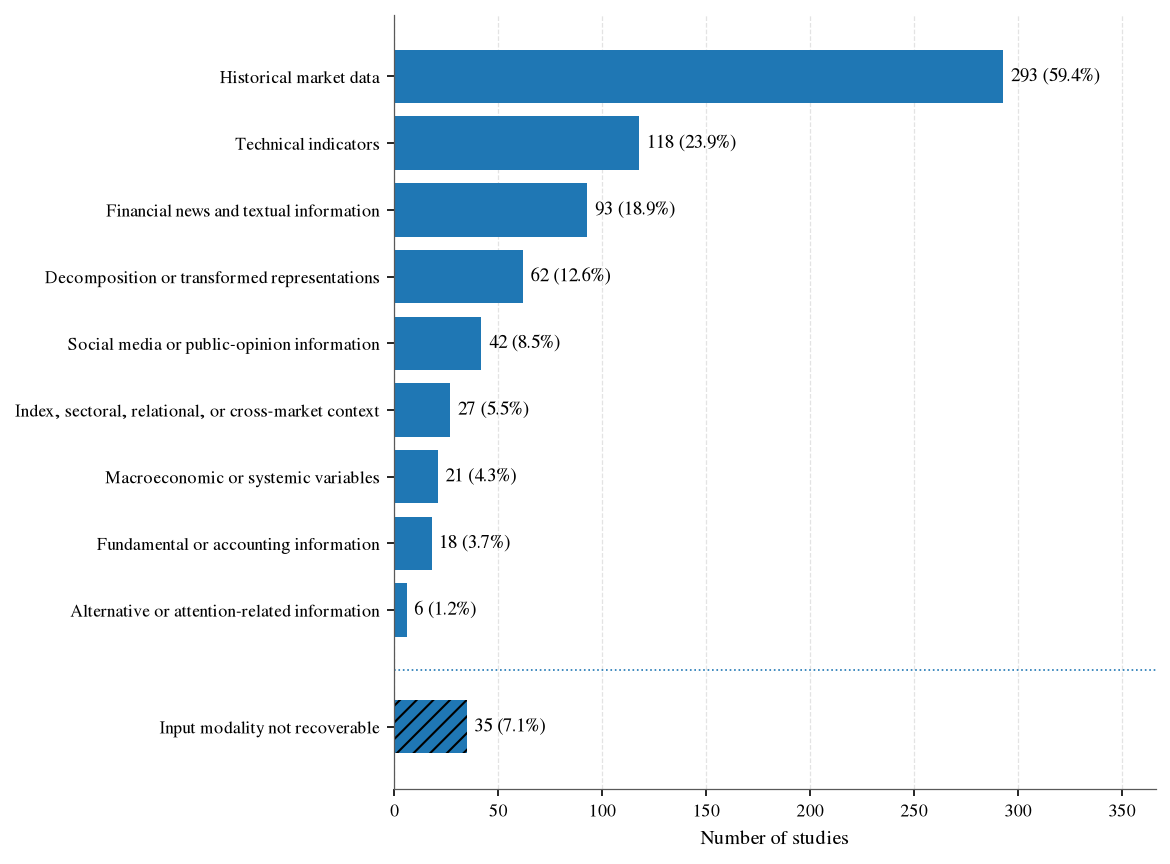


Figure 13 saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/results/figures/Fig13_Input_Modality_Prevalence_DRAFT.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/results/figures/Fig13_Input_Modality_Prevalence_DRAFT.png

WITHIN-PERIOD EXPLICIT-EVIDENCE MATRIX (%)
------------------------------------------
Publication_Period                                    2016–2020  2021–2022  2023–2024  2025–2026
Historical market data                                     55.6       61.1       61.2       59.3
Technical indicators                                       29.6       19.4       26.5       23.6
Financial news and textual information                     11.1       19.4       14.3       19.9
Decomposition or transformed representations               18.5       11.1        6.1       13.1
Social media or public-opinion information                  3.7       11.1        8.2        8.7
Index, sectoral, relational, or cro

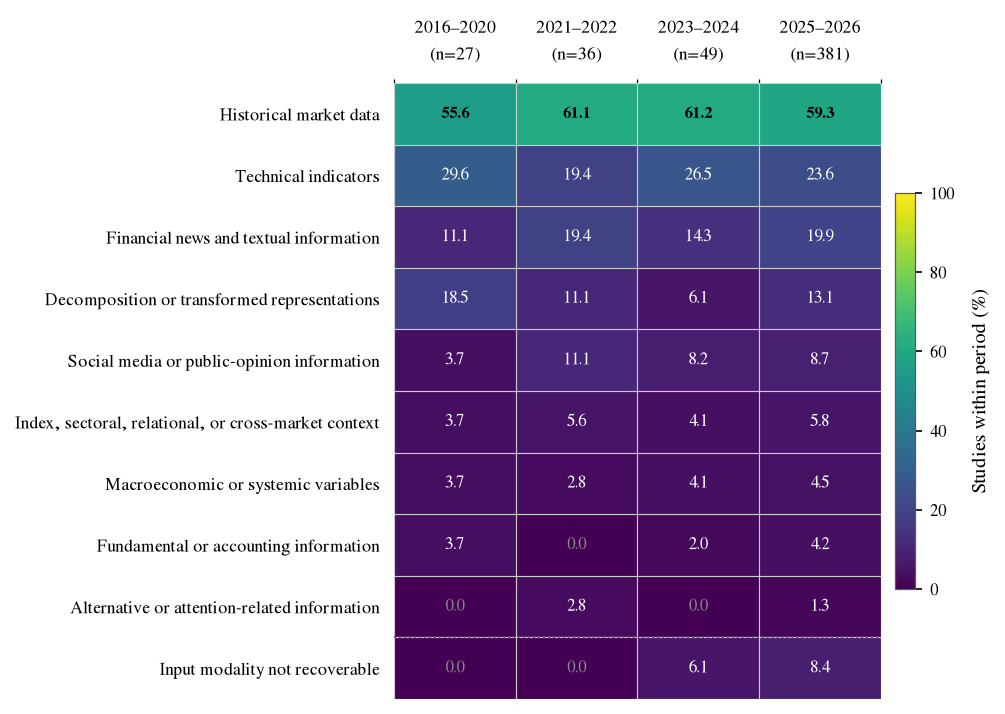


Figure 15 saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/results/figures/Fig15_Input_Modality_Period_Heatmap_DRAFT.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/results/figures/Fig15_Input_Modality_Period_Heatmap_DRAFT.svg
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/results/figures/Fig15_Input_Modality_Period_Heatmap_DRAFT.png
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/results/figures/Fig15_Input_Modality_Period_Heatmap_DRAFT.tiff

SECTION 6 FIGURE GENERATION STATUS
Evidence basis: explicit-evidence adjudication
Studies: 493
Explicit override rows: 220
Input category not recoverable: 35
Full-text verification pending: 42
Manuscript-ready mode: False

Draft figures generated. Do not remove the '_DRAFT' suffix until the remaining full-text cases have been resolved and the explicit override file has been updated.


In [13]:
%reset -f
%run Section6_Figure15_heatmap_publication_ready.py

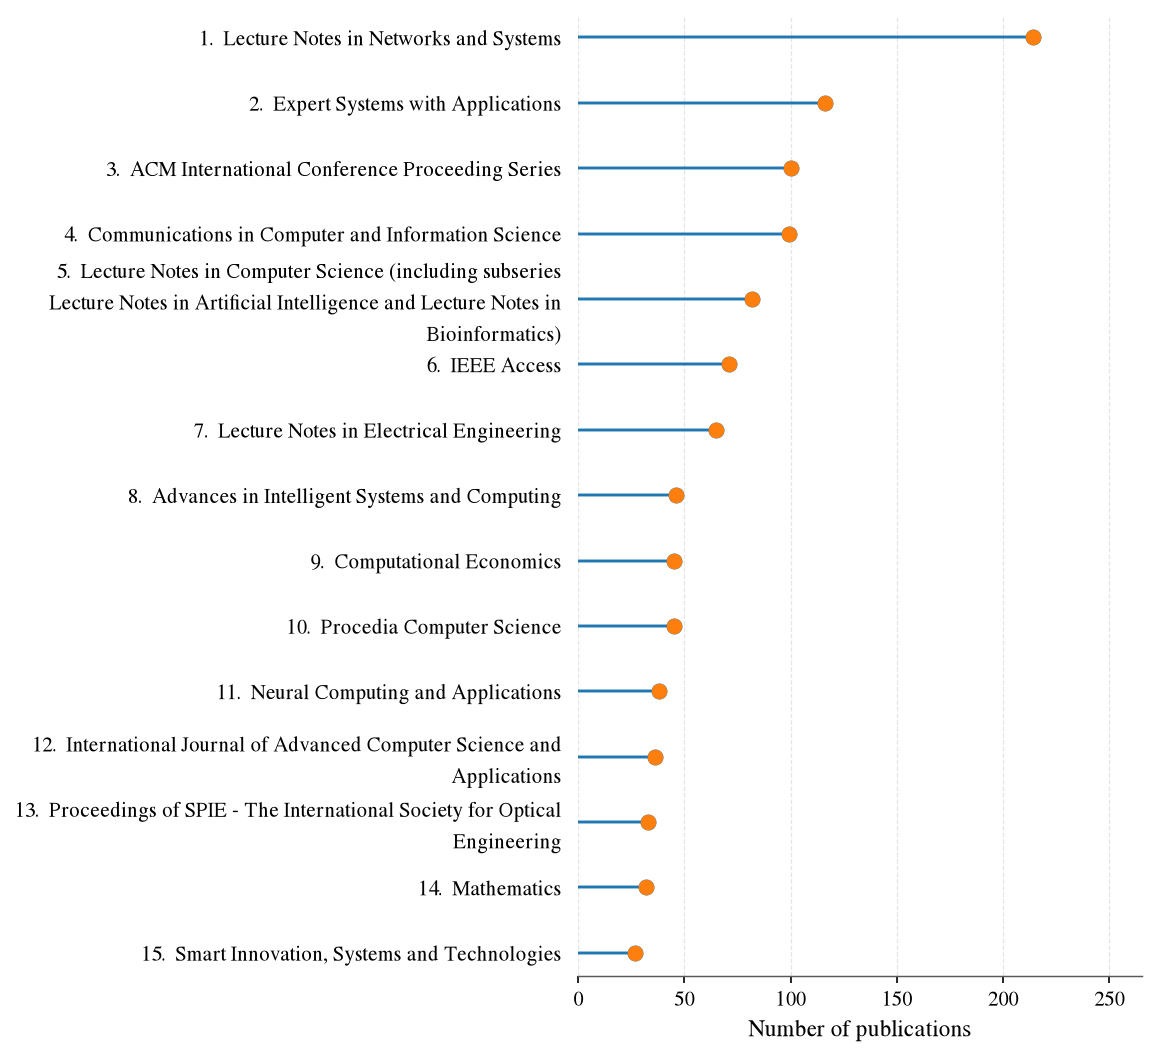


Workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/09_Tables/Table_Top_15_Sources_Final.xlsx

Output directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure3_Top15_Sources_DotPlot

Top-source total shown:
1049

Files saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure3_Top15_Sources_DotPlot/Fig3_Top15_Publication_Sources_Ranked_DotPlot_Q1.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure3_Top15_Sources_DotPlot/Fig3_Top15_Publication_Sources_Ranked_DotPlot_Q1.svg
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure3_Top15_Sources_DotPlot/Fig3_Top15_Publication_Sources_Ranked_DotPlot_Q1.png
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure3_Top15_Sources_DotPlot/Fig3_Top15_Publication_Sources_Ran

In [23]:
%reset -f
%run regenerate_top15_publication_sources_q1.py

Multiple heatmap matrices found; using:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/02_Merged_Data/World_Map_Heatmap_Output_Large_Font/Application_Area_Year_Matrix.csv


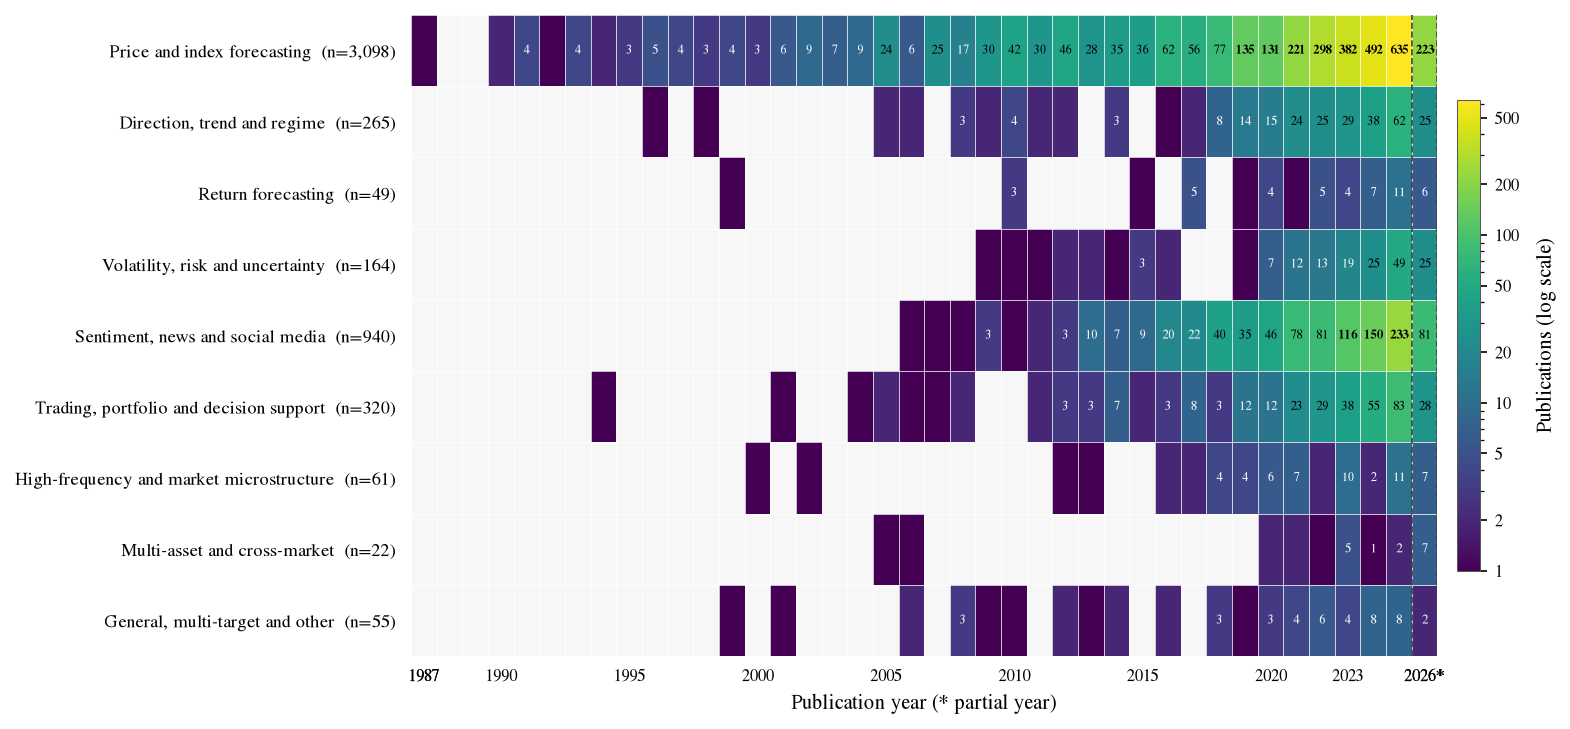


Input matrix:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/02_Merged_Data/World_Map_Heatmap_Output_Large_Font/Application_Area_Year_Matrix.csv

Publication total:
4,974

Maximum annual cell:
635

Row totals:
Price and index forecasting  (n=3,098) = 3098
Direction, trend and regime  (n=265) = 265
Return forecasting  (n=49) = 49
Volatility, risk and uncertainty  (n=164) = 164
Sentiment, news and social media  (n=940) = 940
Trading, portfolio and decision support  (n=320) = 320
High-frequency and market microstructure  (n=61) = 61
Multi-asset and cross-market  (n=22) = 22
General, multi-target and other  (n=55) = 55

Files saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure5_Application_Area_Heatmap/Fig5_Application_Area_Annual_Heatmap_Q1.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/08_Figures/Figure5_Application_Area_Heatmap/Fig5_Application_Area_Annual_Heatm

In [26]:
%reset -f
%run regenerate_application_area_heatmap_q1.py

In [7]:
%reset -f
%run regenerate_figure15_corrected.py

Saved:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure15_Output/Figure15_Input_Modality_Period_Heatmap_SCIEQ1.pdf
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure15_Output/Figure15_Input_Modality_Period_Heatmap_SCIEQ1.png
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure15_Output/Figure15_Input_Modality_Period_Heatmap_SCIEQ1.svg

Corrected percentage matrix:
                                                    2016–2020  2021–2022  \
Historical market data                                   55.6       61.1   
Technical indicators                                     29.6       19.4   
Financial news and textual information                   11.1       19.4   
Decomposition or transformed representations             18.5       11.1   
Social media or public-opinion information                3.7       11.1   
Index, sectoral, relational, or cross-market co...        3.7     

In [9]:
from pathlib import Path
import re

import numpy as np
import pandas as pd


# ============================================================
# 1. LOCATE THE WORKBOOK
# ============================================================

PROJECT_DIR = Path.cwd()

workbook_candidates = sorted(
    PROJECT_DIR.glob(
        "Section5_5_Review_264_Closed_45_Pending*.xlsx"
    )
)

if not workbook_candidates:
    raise FileNotFoundError(
        "No matching workbook was found in:\n"
        f"{PROJECT_DIR.resolve()}"
    )

if len(workbook_candidates) > 1:
    print("Multiple matching workbooks were found:")

    for number, path in enumerate(
        workbook_candidates,
        start=1,
    ):
        print(f"{number}. {path.name}")

    raise RuntimeError(
        "Specify the exact final workbook filename because more than "
        "one matching file is present."
    )

WORKBOOK_PATH = workbook_candidates[0]

print("Workbook selected:")
print(WORKBOOK_PATH.resolve())


# ============================================================
# 2. LOAD THE METHODOLOGICAL-AUDIT SHEET
# ============================================================

audit = pd.read_excel(
    WORKBOOK_PATH,
    sheet_name="Section5_5_Methodological_Audit",
    dtype=str,
    engine="openpyxl",
).fillna("")

audit.columns = [
    str(column).strip()
    for column in audit.columns
]

required_columns = {
    "Paper_ID",
    "Leakage_Signals",
    "Leakage_Risk",
}

missing_columns = required_columns.difference(
    audit.columns
)

if missing_columns:
    raise KeyError(
        "The following required columns are missing:\n"
        f"{sorted(missing_columns)}\n\n"
        f"Available columns:\n{list(audit.columns)}"
    )

for column in required_columns:
    audit[column] = (
        audit[column]
        .astype(str)
        .str.strip()
    )

if len(audit) != 493:
    raise AssertionError(
        f"Expected 493 methodological-audit rows; found {len(audit)}."
    )

if audit["Paper_ID"].nunique() != 493:
    raise AssertionError(
        "Duplicate Paper_ID values were found in the audit sheet."
    )

print("\nMethodological-audit rows:", len(audit))


# ============================================================
# 3. DEFINE PASSAGE-VERIFIED LEAKAGE SIGNALS
# ============================================================

signal_text = audit["Leakage_Signals"]

specific_signal_patterns = [
    "Global_Scaling",
    "Full_Dataset_Feature_Selection",
    "Random_Split",
    "Test_Set_Tuning",
    "Overlapping_Windows",
    "Label_Lookahead",
    "Text_Timing",
]

specific_signal_regex = "|".join(
    re.escape(pattern)
    for pattern in specific_signal_patterns
)

has_specific_signal = signal_text.str.contains(
    specific_signal_regex,
    regex=True,
    na=False,
)

no_explicit_signal = signal_text.str.contains(
    "None_Explicitly_Identified",
    regex=False,
    na=False,
)


# ============================================================
# 4. CHECK FOR CONFLICTING CODING
# ============================================================

conflicting_signal_code = (
    has_specific_signal
    & no_explicit_signal
)

if conflicting_signal_code.any():
    conflicting_records = audit.loc[
        conflicting_signal_code,
        [
            "Paper_ID",
            "Leakage_Signals",
            "Leakage_Risk",
        ],
    ]

    raise AssertionError(
        "Some studies contain both a specific leakage signal and "
        "'None_Explicitly_Identified':\n\n"
        + conflicting_records.to_string(index=False)
    )


# ============================================================
# 5. CREATE THE SIGNAL-LEVEL CLASSIFICATION
# ============================================================

audit["Leakage_Signal_Status"] = np.select(
    [
        has_specific_signal,
        no_explicit_signal,
    ],
    [
        "At least one passage-verified signal",
        "No explicit passage-verified signal identified",
    ],
    default="Specific leakage mechanism not classifiable",
)


# ============================================================
# 6. CHECK THE EXPECTED MARGINAL COUNTS
# ============================================================

signal_status_counts = (
    audit["Leakage_Signal_Status"]
    .value_counts()
)

risk_counts = (
    audit["Leakage_Risk"]
    .value_counts()
)

print("\nLeakage-signal status:")
print(signal_status_counts.to_string())

print("\nOverall leakage risk:")
print(risk_counts.to_string())


expected_unclassifiable = 458
observed_unclassifiable = int(
    signal_status_counts.get(
        "Specific leakage mechanism not classifiable",
        0,
    )
)

if observed_unclassifiable != expected_unclassifiable:
    raise AssertionError(
        "Expected 458 studies for which a specific leakage mechanism "
        "was not classifiable; found "
        f"{observed_unclassifiable}."
    )

expected_risk_counts = {
    "High": 33,
    "Low": 7,
    "Unclear": 453,
}

for risk_category, expected_count in expected_risk_counts.items():
    observed_count = int(
        risk_counts.get(
            risk_category,
            0,
        )
    )

    if observed_count != expected_count:
        raise AssertionError(
            f"Expected {expected_count} studies with Leakage_Risk = "
            f"'{risk_category}'; found {observed_count}."
        )


# ============================================================
# 7. GENERATE THE CROSS-TABULATION
# ============================================================

risk_order = [
    "High",
    "Low",
    "Unclear",
]

signal_order = [
    "At least one passage-verified signal",
    "No explicit passage-verified signal identified",
    "Specific leakage mechanism not classifiable",
]

leakage_cross_tab = pd.crosstab(
    audit["Leakage_Signal_Status"],
    audit["Leakage_Risk"],
).reindex(
    index=signal_order,
    columns=risk_order,
    fill_value=0,
)

leakage_cross_tab["Total"] = (
    leakage_cross_tab.sum(axis=1)
)

total_row = pd.DataFrame(
    [leakage_cross_tab.sum(axis=0)],
    index=["Total"],
)

leakage_cross_tab = pd.concat(
    [
        leakage_cross_tab,
        total_row,
    ]
)


# ============================================================
# 8. DISPLAY AND EXPORT
# ============================================================

print("\n" + "=" * 78)
print("LEAKAGE-SIGNAL STATUS × OVERALL LEAKAGE-RISK")
print("=" * 78)

print(leakage_cross_tab.to_string())

OUTPUT_FILE = (
    PROJECT_DIR
    / "leakage_signal_status_by_overall_risk.csv"
)

leakage_cross_tab.to_csv(
    OUTPUT_FILE,
    encoding="utf-8-sig",
)

print("\nCross-tabulation saved to:")
print(OUTPUT_FILE.resolve())

Workbook selected:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Review_264_Closed_45_Pending.xlsx

Methodological-audit rows: 493

Leakage-signal status:
Leakage_Signal_Status
Specific leakage mechanism not classifiable       458
At least one passage-verified signal               28
No explicit passage-verified signal identified      7

Overall leakage risk:
Leakage_Risk
Unclear    453
High        33
Low          7

LEAKAGE-SIGNAL STATUS × OVERALL LEAKAGE-RISK
Leakage_Risk                                    High  Low  Unclear  Total
At least one passage-verified signal              28    0        0     28
No explicit passage-verified signal identified     0    7        0      7
Specific leakage mechanism not classifiable        5    0      453    458
Total                                             33    7      453    493

Cross-tabulation saved to:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/leakage_s

In [10]:
five_high_unclassifiable = audit.loc[
    audit["Leakage_Signal_Status"].eq(
        "Specific leakage mechanism not classifiable"
    )
    & audit["Leakage_Risk"].eq("High")
].copy()

columns_to_show = [
    "Paper_ID",
    "Leakage_Signals",
    "Leakage_Risk",
    "Validation_Design",
    "Preprocessing_Boundary",
    "Chronological_Split",
]

available_columns = [
    column
    for column in columns_to_show
    if column in five_high_unclassifiable.columns
]

print(
    five_high_unclassifiable[
        available_columns
    ].to_string(index=False)
)

five_high_unclassifiable[
    available_columns
].to_csv(
    "five_high_risk_without_classifiable_specific_signal.csv",
    index=False,
    encoding="utf-8-sig",
)

Paper_ID Leakage_Signals Leakage_Risk     Validation_Design Preprocessing_Boundary Chronological_Split
  P00022         Unclear         High Chronological_Holdout           Full_Dataset                 Yes
  P00321         Unclear         High        Rolling_Window                Unclear                 Yes
  P00509         Unclear         High       Random_Shuffled                Unclear                  No
  P00601         Unclear         High               Unclear                Unclear             Unclear
  P02642         Unclear         High       Random_Shuffled                Unclear                  No


In [11]:
import pandas as pd

candidate_ids = [
    "P00022",
    "P00321",
    "P00509",
    "P00601",
    "P02642",
]

# Select all fields likely to explain leakage-risk coding.
search_terms = [
    "leak",
    "valid",
    "split",
    "chron",
    "preprocess",
    "scal",
    "normal",
    "decom",
    "feature",
    "timing",
    "overlap",
    "window",
    "target",
    "label",
    "look",
    "tuning",
    "hyper",
    "test",
    "text",
    "evidence",
    "passage",
    "reason",
    "note",
    "comment",
]

relevant_columns = [
    column
    for column in audit.columns
    if (
        column == "Paper_ID"
        or any(
            term in column.lower()
            for term in search_terms
        )
    )
]

five_records = audit.loc[
    audit["Paper_ID"].isin(candidate_ids),
    relevant_columns,
].copy()

print("Selected columns:")
for column in relevant_columns:
    print(" -", column)

for paper_id in candidate_ids:
    record = five_records.loc[
        five_records["Paper_ID"].eq(paper_id)
    ]

    print("\n" + "=" * 90)
    print(paper_id)
    print("=" * 90)

    if record.empty:
        print("Record not found.")
    else:
        display_record = (
            record.T
            .rename(columns={record.index[0]: "Value"})
        )

        display_record = display_record.loc[
            display_record["Value"]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
        ]

        print(display_record.to_string())

five_records.to_csv(
    "five_high_risk_mechanism_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nSaved: five_high_risk_mechanism_audit.csv")

Selected columns:
 - Paper_ID
 - Target_Primary
 - Raw_Validation_Method
 - Raw_Input_Features
 - Existing_FullText_Status
 - Evidence_Scope
 - Shock_Context_Mentioned
 - Validation_Design
 - Chronological_Split
 - Preprocessing_Boundary
 - Decomposition_FS_Timing
 - Overlap_Control
 - Leakage_Risk
 - Leakage_Signals
 - Statistical_Testing
 - Evidence_Basis
 - Rule_Evidence
 - Full_Text_Priority
 - Priority_Reason
 - Human_Reviewer_Notes
 - Evidence_Quote
 - Leakage_Signal_Status

P00022
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

In [12]:
risk_reason_updates = {
    "P00022": (
        "High risk due to full-dataset preprocessing; "
        "the specific transformation was not recoverable."
    ),
    "P00509": (
        "High risk due to random/shuffled validation and "
        "absence of a chronological split."
    ),
    "P02642": (
        "High risk due to random/shuffled validation and "
        "absence of a chronological split."
    ),
}

if "Leakage_Risk_Reason" not in audit.columns:
    audit["Leakage_Risk_Reason"] = ""

for paper_id, reason in risk_reason_updates.items():
    audit.loc[
        audit["Paper_ID"].eq(paper_id),
        "Leakage_Risk_Reason",
    ] = reason

In [13]:
import numpy as np
import pandas as pd


# ============================================================
# 1. KEEP AN UNCHANGED COPY
# ============================================================

audit_before_reconciliation = audit.copy(deep=True)

if "Final_Leakage_Rationale" not in audit.columns:
    audit["Final_Leakage_Rationale"] = ""

if "Final_Reconciliation_Status" not in audit.columns:
    audit["Final_Reconciliation_Status"] = ""


# ============================================================
# 2. EVIDENCE-BASED FINAL CORRECTIONS
# ============================================================

corrections = {
    "P00022": {
        "Preprocessing_Boundary": "Unclear",
        "Leakage_Signals": "Unclear",
        "Leakage_Risk": "Unclear",
        "Final_Leakage_Rationale": (
            "Min-Max normalization was reported, but the available "
            "passage did not establish that it was fitted before "
            "splitting or on the complete dataset. Global scaling and "
            "full-dataset preprocessing were therefore not confirmed."
        ),
    },

    "P00321": {
        "Validation_Design": "Rolling_Window",
        "Chronological_Split": "Yes",
        "Preprocessing_Boundary": "Unclear",
        "Leakage_Signals": "Future_Aware_Imputation",
        "Leakage_Risk": "High",
        "Final_Leakage_Rationale": (
            "Missing-value imputation used information from preceding "
            "and subsequent periods. This creates a future-aware "
            "input-construction mechanism, although it is not label "
            "look-ahead."
        ),
    },

    "P00509": {
        "Validation_Design": "Rolling_Window",
        "Chronological_Split": "Yes",
        "Preprocessing_Boundary": "Unclear",
        "Leakage_Signals": "Unclear",
        "Leakage_Risk": "Unclear",
        "Final_Leakage_Rationale": (
            "The article explicitly described a rolling-window design "
            "used instead of random splitting and stated that past "
            "observations were used to predict future values. No "
            "specific leakage mechanism remained established."
        ),
    },

    "P00601": {
        "Validation_Design": "Unclear",
        "Chronological_Split": "Unclear",
        "Preprocessing_Boundary": "Unclear",
        "Decomposition_FS_Timing": "Mixed_Boundaries",
        "Leakage_Signals": "Test_Set_Fitted_Transformation",
        "Leakage_Risk": "High",
        "Final_Leakage_Rationale": (
            "Standardization and PCA were fitted separately on the "
            "test set. The resulting test representation therefore "
            "used test-distribution information rather than an "
            "unchanged training-fitted transformation."
        ),
    },

    "P02642": {
        "Validation_Design": "Random_Shuffled",
        "Chronological_Split": "No",
        "Preprocessing_Boundary": "Unclear",
        "Leakage_Signals": "Random_Split",
        "Leakage_Risk": "High",
        "Final_Leakage_Rationale": (
            "The article explicitly stated that training observations "
            "were divided randomly into ten subsets and evaluated "
            "using tenfold cross-validation, which is temporally "
            "invalid for stock-market forecasting."
        ),
    },
}


# ============================================================
# 3. APPLY THE CORRECTIONS
# ============================================================

reconciliation_rows = []

for paper_id, field_updates in corrections.items():

    record_mask = audit["Paper_ID"].eq(paper_id)

    if int(record_mask.sum()) != 1:
        raise AssertionError(
            f"{paper_id} should occur exactly once; "
            f"found {int(record_mask.sum())}."
        )

    for field_name, new_value in field_updates.items():

        if field_name not in audit.columns:
            audit[field_name] = ""

        old_value = str(
            audit.loc[
                record_mask,
                field_name,
            ].iloc[0]
        )

        audit.loc[
            record_mask,
            field_name,
        ] = new_value

        reconciliation_rows.append(
            {
                "Paper_ID": paper_id,
                "Field": field_name,
                "Previous_Value": old_value,
                "Corrected_Value": new_value,
            }
        )

    audit.loc[
        record_mask,
        "Final_Reconciliation_Status",
    ] = "Completed_2026_08_01"


reconciliation_log = pd.DataFrame(
    reconciliation_rows
)


# ============================================================
# 4. RECOMPUTE THE SIGNAL-STATUS VARIABLE
# ============================================================

specific_signal_patterns = [
    "Global_Scaling",
    "Full_Dataset_Feature_Selection",
    "Random_Split",
    "Test_Set_Tuning",
    "Overlapping_Windows",
    "Label_Lookahead",
    "Text_Timing",
    "Future_Aware_Imputation",
    "Test_Set_Fitted_Transformation",
]

signal_text = (
    audit["Leakage_Signals"]
    .fillna("")
    .astype(str)
    .str.strip()
)

specific_signal_regex = "|".join(
    specific_signal_patterns
)

has_specific_signal = signal_text.str.contains(
    specific_signal_regex,
    regex=True,
    na=False,
)

no_explicit_signal = signal_text.str.contains(
    "None_Explicitly_Identified",
    regex=False,
    na=False,
)

audit["Leakage_Signal_Status"] = np.select(
    [
        has_specific_signal,
        no_explicit_signal,
    ],
    [
        "At least one passage-verified signal",
        "No explicit passage-verified signal identified",
    ],
    default="Specific leakage mechanism not classifiable",
)


# ============================================================
# 5. VERIFY CORRECTED TOTALS
# ============================================================

risk_counts = (
    audit["Leakage_Risk"]
    .value_counts()
)

signal_status_counts = (
    audit["Leakage_Signal_Status"]
    .value_counts()
)

expected_risk_counts = {
    "High": 31,
    "Low": 7,
    "Unclear": 455,
}

expected_signal_counts = {
    "At least one passage-verified signal": 31,
    "No explicit passage-verified signal identified": 7,
    "Specific leakage mechanism not classifiable": 455,
}

for category, expected in expected_risk_counts.items():
    observed = int(
        risk_counts.get(category, 0)
    )

    if observed != expected:
        raise AssertionError(
            f"Leakage_Risk '{category}': "
            f"expected {expected}, found {observed}."
        )

for category, expected in expected_signal_counts.items():
    observed = int(
        signal_status_counts.get(category, 0)
    )

    if observed != expected:
        raise AssertionError(
            f"Leakage_Signal_Status '{category}': "
            f"expected {expected}, found {observed}."
        )


# ============================================================
# 6. REVISED CROSS-TABULATION
# ============================================================

signal_order = [
    "At least one passage-verified signal",
    "No explicit passage-verified signal identified",
    "Specific leakage mechanism not classifiable",
]

risk_order = [
    "High",
    "Low",
    "Unclear",
]

revised_cross_tab = pd.crosstab(
    audit["Leakage_Signal_Status"],
    audit["Leakage_Risk"],
).reindex(
    index=signal_order,
    columns=risk_order,
    fill_value=0,
)

revised_cross_tab["Total"] = (
    revised_cross_tab.sum(axis=1)
)

revised_cross_tab.loc["Total"] = (
    revised_cross_tab.sum(axis=0)
)

print("\nCorrected overall leakage risk:")
print(risk_counts.to_string())

print("\nCorrected leakage-signal status:")
print(signal_status_counts.to_string())

print("\nCorrected cross-tabulation:")
print(revised_cross_tab.to_string())


# ============================================================
# 7. EXPORT AUDIT FILES
# ============================================================

reconciliation_log.to_csv(
    "leakage_coding_reconciliation_log.csv",
    index=False,
    encoding="utf-8-sig",
)

audit.to_csv(
    "Section5_5_Methodological_Audit_Reconciled.csv",
    index=False,
    encoding="utf-8-sig",
)

revised_cross_tab.to_csv(
    "leakage_signal_status_by_overall_risk_revised.csv",
    encoding="utf-8-sig",
)

print("\nSaved:")
print("leakage_coding_reconciliation_log.csv")
print("Section5_5_Methodological_Audit_Reconciled.csv")
print("leakage_signal_status_by_overall_risk_revised.csv")


Corrected overall leakage risk:
Leakage_Risk
Unclear    455
High        31
Low          7

Corrected leakage-signal status:
Leakage_Signal_Status
Specific leakage mechanism not classifiable       455
At least one passage-verified signal               31
No explicit passage-verified signal identified      7

Corrected cross-tabulation:
Leakage_Risk                                    High  Low  Unclear  Total
Leakage_Signal_Status                                                    
At least one passage-verified signal              31    0        0     31
No explicit passage-verified signal identified     0    7        0      7
Specific leakage mechanism not classifiable        0    0      455    455
Total                                             31    7      455    493

Saved:
leakage_coding_reconciliation_log.csv
Section5_5_Methodological_Audit_Reconciled.csv
leakage_signal_status_by_overall_risk_revised.csv


In [14]:
from pathlib import Path
import pandas as pd


# ============================================================
# LOAD THE RECONCILED AUDIT
# ============================================================

AUDIT_FILE = Path(
    "Section5_5_Methodological_Audit_Reconciled.csv"
)

audit_final = pd.read_csv(
    AUDIT_FILE,
    dtype=str,
    keep_default_na=False,
)

audit_final.columns = [
    str(column).strip()
    for column in audit_final.columns
]

if len(audit_final) != 493:
    raise AssertionError(
        f"Expected 493 rows; found {len(audit_final)}."
    )


# ============================================================
# PASSAGE-VERIFIED SIGNAL CATEGORIES
# ============================================================

signal_definitions = [
    (
        "Global_Scaling",
        "Global scaling",
    ),
    (
        "Full_Dataset_Feature_Selection",
        "Full-dataset feature selection",
    ),
    (
        "Random_Split",
        "Random or shuffled splitting",
    ),
    (
        "Test_Set_Tuning",
        "Test-set tuning",
    ),
    (
        "Overlapping_Windows",
        "Overlapping windows",
    ),
    (
        "Label_Lookahead",
        "Label look-ahead",
    ),
    (
        "Text_Timing",
        "Text-timing problem",
    ),
    (
        "Future_Aware_Imputation",
        "Future-aware imputation",
    ),
    (
        "Test_Set_Fitted_Transformation",
        "Test-set-fitted transformation",
    ),
]

signal_text = (
    audit_final["Leakage_Signals"]
    .fillna("")
    .astype(str)
    .str.strip()
)

rows = []

for signal_code, display_name in signal_definitions:

    count = int(
        signal_text.str.contains(
            signal_code,
            regex=False,
            na=False,
        ).sum()
    )

    rows.append(
        {
            "Leakage_Signal": display_name,
            "Studies": count,
            "Share_of_493": round(
                100 * count / 493,
                1,
            ),
        }
    )


# ============================================================
# MUTUALLY EXCLUSIVE STATUS COUNTS
# ============================================================

status_counts = (
    audit_final["Leakage_Signal_Status"]
    .value_counts()
)

rows.extend(
    [
        {
            "Leakage_Signal":
                "No explicit passage-verified signal identified",
            "Studies": int(
                status_counts.get(
                    "No explicit passage-verified signal identified",
                    0,
                )
            ),
            "Share_of_493": round(
                100
                * int(
                    status_counts.get(
                        "No explicit passage-verified signal identified",
                        0,
                    )
                )
                / 493,
                1,
            ),
        },
        {
            "Leakage_Signal":
                "Specific leakage mechanism not classifiable",
            "Studies": int(
                status_counts.get(
                    "Specific leakage mechanism not classifiable",
                    0,
                )
            ),
            "Share_of_493": round(
                100
                * int(
                    status_counts.get(
                        "Specific leakage mechanism not classifiable",
                        0,
                    )
                )
                / 493,
                1,
            ),
        },
    ]
)

table_s9 = pd.DataFrame(rows)

print(table_s9.to_string(index=False))

table_s9.to_csv(
    "Table_S9_Reconciled_Leakage_Signals.csv",
    index=False,
    encoding="utf-8-sig",
)

                                Leakage_Signal  Studies  Share_of_493
                                Global scaling       17           3.4
                Full-dataset feature selection        6           1.2
                  Random or shuffled splitting        5           1.0
                               Test-set tuning        2           0.4
                           Overlapping windows        1           0.2
                              Label look-ahead        1           0.2
                           Text-timing problem        1           0.2
                       Future-aware imputation        1           0.2
                Test-set-fitted transformation        1           0.2
No explicit passage-verified signal identified        7           1.4
   Specific leakage mechanism not classifiable      455          92.3


In [9]:
from __future__ import annotations

from pathlib import Path
import csv
import re
from collections import Counter
from typing import Any

import plotly.graph_objects as go


# ============================================================
# 1. PROJECT SETTINGS
# ============================================================

PROJECT_ROOT = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

INPUT_CANDIDATES = [
    PROJECT_ROOT
    / "07_Systematic_Review_Dataset"
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "07_Reference_Outputs_Web"
    / "Section7_Final_Study_Level_Sankey_Input.csv",
]

OUTPUT_DIR = PROJECT_ROOT / "Figure17_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SHOW_FIGURE = True


# ============================================================
# 2. FROZEN MANUSCRIPT COUNTS
# ============================================================

FROZEN_PERIOD_COUNTS = {
    "2016-2020": 27,
    "2021-2022": 36,
    "2023-2024": 49,
    "2025-2026": 381,
}

FROZEN_FAMILY_COUNTS = {
    "Hybrid deep-learning models": 110,
    "Transformer/attention-based models": 68,
    "Deep-learning models": 117,
    "Metaheuristic-optimized models": 51,
    "Sentiment/NLP-driven models": 81,
    "Multimodal-fusion models": 13,
    "Graph-based models": 16,
    "Other/unclear": 2,
    "Ensemble/tree-based machine learning": 34,
    "ANN/neuro-fuzzy models": 1,
}

FROZEN_TARGET_COUNTS = {
    "Price level": 381,
    "Multi-target": 33,
    "Direction": 48,
    "Return": 17,
    "Trend or regime": 10,
    "Not reported": 4,
}

PERIOD_ORDER = list(FROZEN_PERIOD_COUNTS)
FAMILY_ORDER = list(FROZEN_FAMILY_COUNTS)
TARGET_ORDER = list(FROZEN_TARGET_COUNTS)


# ============================================================
# 3. INPUT COLUMN REQUIREMENTS
# ============================================================

REQUIRED_COLUMNS = {
    "Paper_ID",
    "Year",
    "Principal_Method_Family",
    "Target_Primary",
}


# ============================================================
# 4. NORMALIZATION ALIASES
# ============================================================

FAMILY_ALIASES = {
    "deep learning": "Deep-learning models",
    "deep learning models": "Deep-learning models",

    "hybrid deep learning": "Hybrid deep-learning models",
    "hybrid deep learning models": "Hybrid deep-learning models",

    "sentiment nlp": "Sentiment/NLP-driven models",
    "sentiment nlp driven models": "Sentiment/NLP-driven models",

    "transformer attention": "Transformer/attention-based models",
    "transformer attention based models":
        "Transformer/attention-based models",

    "metaheuristic optimized": "Metaheuristic-optimized models",
    "metaheuristic optimized models":
        "Metaheuristic-optimized models",

    "ensemble tree based machine learning":
        "Ensemble/tree-based machine learning",

    "graph based": "Graph-based models",
    "graph based models": "Graph-based models",

    "multimodal fusion": "Multimodal-fusion models",
    "multimodal fusion models": "Multimodal-fusion models",

    "other": "Other/unclear",
    "other unclear": "Other/unclear",

    "ann neuro fuzzy": "ANN/neuro-fuzzy models",
    "ann neuro fuzzy models": "ANN/neuro-fuzzy models",
}

TARGET_ALIASES = {
    "price": "Price level",
    "price level": "Price level",

    "return": "Return",

    "direction": "Direction",

    "trend regime": "Trend or regime",
    "trend or regime": "Trend or regime",

    "multi target": "Multi-target",

    "not reported": "Not reported",
}


# ============================================================
# 5. JOURNAL FIGURE SETTINGS
# ============================================================

FIGURE_WIDTH = 1800
FIGURE_HEIGHT = 1050
PNG_SCALE = 3

FONT_FAMILY = "Arial"

REGULAR_LABEL_FONT_SIZE = 19
COUNT_FONT_PERCENT = 78
COLUMN_HEADING_FONT_SIZE = 24

NODE_THICKNESS = 18
NODE_LINE_WIDTH = 0.75

# Sankey-relative node locations
PERIOD_X = 0.020
FAMILY_X = 0.500
TARGET_X = 0.970

# Leave sufficient external space for labels.
DOMAIN_X0 = 0.055
DOMAIN_X1 = 0.945
DOMAIN_Y0 = 0.040
DOMAIN_Y1 = 0.900

PERIOD_GAP = 0.050
FAMILY_GAP = 0.017
TARGET_GAP = 0.038

NODE_TOP = 0.025
NODE_BOTTOM = 0.975

PERIOD_LINK_ALPHA = 0.26
TARGET_LINK_ALPHA = 0.34

LABEL_BACKGROUND_ALPHA = 0.78

# Heading locations in complete figure coordinates.
# These are intentionally independent of node locations.
HEADING_POSITIONS = {
    "Publication period": 0.135,
    "Principal method family": 0.515,
    "Primary forecasting target": 0.865,
}


# ============================================================
# 6. COLOUR PALETTE
# ============================================================

PERIOD_COLOURS = {
    "2016-2020": "#5B8CC0",
    "2021-2022": "#4CA6A8",
    "2023-2024": "#F28E6B",
    "2025-2026": "#9B6CE3",
}

FAMILY_COLOURS = {
    "Hybrid deep-learning models": "#4CC9E8",
    "Transformer/attention-based models": "#A6D854",
    "Deep-learning models": "#F4A261",
    "Metaheuristic-optimized models": "#D96BC6",
    "Sentiment/NLP-driven models": "#E76F91",
    "Multimodal-fusion models": "#E76F51",
    "Graph-based models": "#6C8CD5",
    "Other/unclear": "#A7A7A7",
    "Ensemble/tree-based machine learning": "#E9B44C",
    "ANN/neuro-fuzzy models": "#8A9A5B",
}

TARGET_COLOURS = {
    "Price level": "#F4A261",
    "Multi-target": "#D96BC6",
    "Direction": "#E76F91",
    "Return": "#4CC9E8",
    "Trend or regime": "#8BC34A",
    "Not reported": "#E9B44C",
}


# ============================================================
# 7. DISPLAY LABELS
# ============================================================

DISPLAY_LABELS = {
    "Ensemble/tree-based machine learning":
        "Ensemble/tree-based ML",

    "Transformer/attention-based models":
        "Transformer/attention-based<br>models",

    "Hybrid deep-learning models":
        "Hybrid deep-learning<br>models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized<br>models",

    "Sentiment/NLP-driven models":
        "Sentiment/NLP-driven<br>models",

    "Multimodal-fusion models":
        "Multimodal-fusion models",

    "ANN/neuro-fuzzy models":
        "ANN/neuro-fuzzy models",

    "Trend or regime":
        "Trend or regime",

    "Not reported":
        "Not reported",
}


# ============================================================
# 8. TEXT HELPERS
# ============================================================

def clean(value: object) -> str:
    """Normalize surrounding and repeated whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def normalized_key(value: object) -> str:
    """Create a punctuation-independent lookup key."""

    text = clean(value).lower()

    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text,
    )

    return " ".join(text.split())


def hex_to_rgba(
    hexadecimal: str,
    alpha: float,
) -> str:
    """Convert #RRGGBB to Plotly rgba format."""

    text = hexadecimal.lstrip("#")

    if len(text) != 6:
        raise ValueError(
            f"Invalid hexadecimal colour: {hexadecimal}"
        )

    red = int(text[0:2], 16)
    green = int(text[2:4], 16)
    blue = int(text[4:6], 16)

    return (
        f"rgba({red},{green},{blue},{alpha:.3f})"
    )


def period_from_year(year_text: str) -> str:
    """Map publication year to the frozen review periods."""

    try:
        year = int(float(clean(year_text)))

    except ValueError as error:
        raise ValueError(
            f"Invalid publication year: {year_text!r}"
        ) from error

    if 2016 <= year <= 2020:
        return "2016-2020"

    if 2021 <= year <= 2022:
        return "2021-2022"

    if 2023 <= year <= 2024:
        return "2023-2024"

    if 2025 <= year <= 2026:
        return "2025-2026"

    raise ValueError(
        "Publication year lies outside the frozen "
        f"technical-synthesis periods: {year}"
    )


def normalize_family(value: str) -> str:
    """Normalize the principal method-family coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_FAMILY_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in FAMILY_ALIASES:
        return FAMILY_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized method family: {value!r}"
    )


def normalize_target(value: str) -> str:
    """Normalize the primary target coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_TARGET_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in TARGET_ALIASES:
        return TARGET_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized forecasting target: {value!r}"
    )


def journal_label(
    item: str,
    count: int,
) -> str:
    """Create a compact label with a smaller count line."""

    display = DISPLAY_LABELS.get(item, item)

    return (
        f"{display}<br>"
        f"<span style='font-size:{COUNT_FONT_PERCENT}%'>"
        f"(n={count:,})"
        f"</span>"
    )


# ============================================================
# 9. INPUT DISCOVERY
# ============================================================

def find_input() -> Path:
    """Locate the final 493-study Sankey input CSV."""

    for path in INPUT_CANDIDATES:
        if path.exists():
            return path

    matches: list[Path] = []

    for path in PROJECT_ROOT.rglob("*.csv"):

        try:
            with path.open(
                "r",
                encoding="utf-8-sig",
                newline="",
            ) as file:

                reader = csv.reader(file)
                header = next(reader, [])

        except Exception:
            continue

        if REQUIRED_COLUMNS.issubset(set(header)):
            matches.append(path)

    if len(matches) == 1:
        return matches[0]

    if not matches:
        raise FileNotFoundError(
            "No valid 493-row Sankey input CSV was found.\n"
            "Required columns:\n"
            "Paper_ID, Year, Principal_Method_Family, "
            "Target_Primary\n\n"
            "Expected filename:\n"
            "Section7_Final_Study_Level_Sankey_Input.csv"
        )

    raise RuntimeError(
        "More than one valid Sankey input CSV was found:\n"
        + "\n".join(str(path) for path in matches)
    )


# ============================================================
# 10. COUNT VALIDATION
# ============================================================

def assert_counts(
    label: str,
    observed: Counter,
    expected: dict[str, int],
) -> None:
    """Verify observed distributions against frozen counts."""

    observed_dict = dict(observed)

    if observed_dict == expected:
        return

    print(f"\n{label} count mismatch")

    print("\nObserved:")
    for item in expected:
        print(
            f"  {item}: "
            f"{observed_dict.get(item, 0)}"
        )

    print("\nExpected:")
    for item, count in expected.items():
        print(f"  {item}: {count}")

    unexpected = {
        item: count
        for item, count in observed_dict.items()
        if item not in expected
    }

    if unexpected:
        print("\nUnexpected categories:")
        for item, count in unexpected.items():
            print(f"  {item}: {count}")

    raise AssertionError(
        f"{label} counts do not match "
        "the frozen manuscript values."
    )


# ============================================================
# 11. NODE POSITIONING
# ============================================================

def calculate_column_centres(
    order: list[str],
    counts: dict[str, int],
    gap: float,
) -> dict[str, float]:
    """
    Calculate non-overlapping node centres proportional to
    node totals.

    Plotly Sankey uses y=0 at the top and y=1 at the bottom.
    """

    node_count = len(order)

    total_span = NODE_BOTTOM - NODE_TOP

    total_gap = (
        gap * max(node_count - 1, 0)
    )

    available_height = total_span - total_gap

    if available_height <= 0:
        raise ValueError(
            "The selected vertical gap is too large "
            "for this node column."
        )

    total_count = sum(
        counts[item]
        for item in order
    )

    cursor = NODE_TOP
    centres: dict[str, float] = {}

    for item in order:

        node_height = (
            available_height
            * counts[item]
            / total_count
        )

        centres[item] = (
            cursor + node_height / 2.0
        )

        cursor += node_height + gap

    return centres

def repel_label_positions(
    order: list[str],
    raw_positions: dict[str, float],
    minimum_gap: float,
    lower_limit: float = 0.035,
    upper_limit: float = 0.965,
) -> dict[str, float]:
    """
    Separate annotation positions without changing Sankey-node
    positions or ribbon values.

    Plotly Sankey coordinates increase from top to bottom.
    """

    ordered_items = sorted(
        order,
        key=lambda item: raw_positions[item],
    )

    adjusted = {
        item: min(
            max(raw_positions[item], lower_limit),
            upper_limit,
        )
        for item in ordered_items
    }

    # Forward pass
    for index in range(1, len(ordered_items)):

        previous_item = ordered_items[index - 1]
        current_item = ordered_items[index]

        minimum_position = (
            adjusted[previous_item]
            + minimum_gap
        )

        if adjusted[current_item] < minimum_position:
            adjusted[current_item] = minimum_position

    # Shift upward when the final label exceeds the limit.
    final_item = ordered_items[-1]

    if adjusted[final_item] > upper_limit:

        overflow = (
            adjusted[final_item]
            - upper_limit
        )

        for item in ordered_items:
            adjusted[item] -= overflow

    # Backward pass
    for index in range(
        len(ordered_items) - 2,
        -1,
        -1,
    ):

        current_item = ordered_items[index]
        next_item = ordered_items[index + 1]

        maximum_position = (
            adjusted[next_item]
            - minimum_gap
        )

        if adjusted[current_item] > maximum_position:
            adjusted[current_item] = maximum_position

    # Final lower-bound correction
    first_item = ordered_items[0]

    if adjusted[first_item] < lower_limit:

        underflow = (
            lower_limit
            - adjusted[first_item]
        )

        for item in ordered_items:
            adjusted[item] += underflow

    return adjusted


# ============================================================
# 12. CUSTOM ANNOTATIONS
# ============================================================

def add_node_annotation(
    annotations: list[dict[str, Any]],
    node_x: float,
    label_y: float,
    text: str,
    stage: str,
) -> None:
    """
    Add a manually positioned label without altering the
    underlying Sankey node or flow.
    """

    paper_x = (
        DOMAIN_X0
        + node_x
        * (DOMAIN_X1 - DOMAIN_X0)
    )

    paper_y = (
        DOMAIN_Y0
        + (1.0 - label_y)
        * (DOMAIN_Y1 - DOMAIN_Y0)
    )

    if stage == "period":

        label_x = paper_x + 0.012
        x_anchor = "left"
        alignment = "left"

    elif stage == "family":

        label_x = paper_x + 0.013
        x_anchor = "left"
        alignment = "left"

    elif stage == "target":

        label_x = paper_x - 0.012
        x_anchor = "right"
        alignment = "right"

    else:
        raise ValueError(
            f"Unsupported annotation stage: {stage}"
        )

    annotations.append(
        {
            "x": label_x,
            "y": paper_y,

            "xref": "paper",
            "yref": "paper",

            "text": text,
            "showarrow": False,

            "xanchor": x_anchor,
            "yanchor": "middle",
            "align": alignment,

            "font": {
                "family": FONT_FAMILY,
                "size": REGULAR_LABEL_FONT_SIZE,
                "color": "#303030",
            },

            "bgcolor": (
                "rgba(255,255,255,"
                f"{LABEL_BACKGROUND_ALPHA})"
            ),

            "bordercolor":
                "rgba(255,255,255,0)",

            "borderpad": 1.2,
        }
    )


# ============================================================
# 13. MAIN WORKFLOW
# ============================================================

def main() -> None:

    input_path = find_input()

    print("Input file:")
    print(input_path)

    with input_path.open(
        "r",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        rows = list(
            csv.DictReader(file)
        )

    if len(rows) != 493:
        raise AssertionError(
            f"Expected 493 rows; found {len(rows)}."
        )

    paper_ids = [
        clean(row["Paper_ID"])
        for row in rows
    ]

    if any(not paper_id for paper_id in paper_ids):
        raise AssertionError(
            "One or more Paper_ID values are blank."
        )

    if len(set(paper_ids)) != 493:

        duplicates = sorted(
            paper_id
            for paper_id, count
            in Counter(paper_ids).items()
            if count > 1
        )

        raise AssertionError(
            "Paper_ID values are not unique:\n"
            + "\n".join(duplicates)
        )

    normalized_rows: list[dict[str, str]] = []

    for row in rows:

        normalized_rows.append(
            {
                "Paper_ID": clean(
                    row["Paper_ID"]
                ),

                "Period": period_from_year(
                    row["Year"]
                ),

                "Method_Family": normalize_family(
                    row["Principal_Method_Family"]
                ),

                "Target": normalize_target(
                    row["Target_Primary"]
                ),
            }
        )

    period_counts = Counter(
        row["Period"]
        for row in normalized_rows
    )

    family_counts = Counter(
        row["Method_Family"]
        for row in normalized_rows
    )

    target_counts = Counter(
        row["Target"]
        for row in normalized_rows
    )

    assert_counts(
        "Period",
        period_counts,
        FROZEN_PERIOD_COUNTS,
    )

    assert_counts(
        "Method-family",
        family_counts,
        FROZEN_FAMILY_COUNTS,
    )

    assert_counts(
        "Target",
        target_counts,
        FROZEN_TARGET_COUNTS,
    )

    period_family = Counter(
        (
            row["Period"],
            row["Method_Family"],
        )
        for row in normalized_rows
    )

    family_target = Counter(
        (
            row["Method_Family"],
            row["Target"],
        )
        for row in normalized_rows
    )

    if sum(period_family.values()) != 493:
        raise AssertionError(
            "Period-to-method flows do not total 493."
        )

    if sum(family_target.values()) != 493:
        raise AssertionError(
            "Method-to-target flows do not total 493."
        )


# ========================================================
# 14. NODE DEFINITIONS
# ========================================================

node_items = (
    PERIOD_ORDER
    + FAMILY_ORDER
    + TARGET_ORDER
)

node_stage = (
    ["period"] * len(PERIOD_ORDER)
    + ["family"] * len(FAMILY_ORDER)
    + ["target"] * len(TARGET_ORDER)
)

node_counts = (
    [
        FROZEN_PERIOD_COUNTS[item]
        for item in PERIOD_ORDER
    ]
    + [
        FROZEN_FAMILY_COUNTS[item]
        for item in FAMILY_ORDER
    ]
    + [
        FROZEN_TARGET_COUNTS[item]
        for item in TARGET_ORDER
    ]
)

node_colours = (
    [
        PERIOD_COLOURS[item]
        for item in PERIOD_ORDER
    ]
    + [
        FAMILY_COLOURS[item]
        for item in FAMILY_ORDER
    ]
    + [
        TARGET_COLOURS[item]
        for item in TARGET_ORDER
    ]
)

period_y = calculate_column_centres(
    PERIOD_ORDER,
    FROZEN_PERIOD_COUNTS,
    PERIOD_GAP,
)

family_y = calculate_column_centres(
    FAMILY_ORDER,
    FROZEN_FAMILY_COUNTS,
    FAMILY_GAP,
)

target_y = calculate_column_centres(
    TARGET_ORDER,
    FROZEN_TARGET_COUNTS,
    TARGET_GAP,
)

node_x = (
    [PERIOD_X] * len(PERIOD_ORDER)
    + [FAMILY_X] * len(FAMILY_ORDER)
    + [TARGET_X] * len(TARGET_ORDER)
)

node_y = (
    [
        period_y[item]
        for item in PERIOD_ORDER
    ]
    + [
        family_y[item]
        for item in FAMILY_ORDER
    ]
    + [
        target_y[item]
        for item in TARGET_ORDER
    ]
)

node_index = {
    item: index
    for index, item
    in enumerate(node_items)
}

node_customdata = [
    [
        item,
        stage,
        count,
    ]
    for item, stage, count
    in zip(
        node_items,
        node_stage,
        node_counts,
    )
]

# Node positions determine ribbon geometry.
# Label positions are independently separated to prevent overlap.

    # Node positions determine ribbon geometry.
    # Label positions are independently separated to prevent overlap.

    period_label_y = repel_label_positions(
        order=PERIOD_ORDER,
        raw_positions=period_y,
        minimum_gap=0.100,
    )

    family_label_y = repel_label_positions(
        order=FAMILY_ORDER,
        raw_positions=family_y,
        minimum_gap=0.057,
    )

    target_label_y = repel_label_positions(
        order=TARGET_ORDER,
        raw_positions=target_y,
        minimum_gap=0.075,
    )


    # ========================================================
    # 15. LINK DEFINITIONS
    # ========================================================

    sources: list[int] = []
    targets: list[int] = []
    values: list[int] = []
    link_colours: list[str] = []
    link_customdata: list[list[Any]] = []

    flow_rows: list[dict[str, Any]] = []

    for period in PERIOD_ORDER:

        for family in FAMILY_ORDER:

            count = period_family.get(
                (period, family),
                0,
            )

            if count <= 0:
                continue

            sources.append(
                node_index[period]
            )

            targets.append(
                node_index[family]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    FAMILY_COLOURS[family],
                    PERIOD_LINK_ALPHA,
                )
            )

            link_customdata.append(
                [
                    period,
                    family,
                    count,
                    "Publication period → method family",
                ]
            )

            flow_rows.append(
                {
                    "Stage": "Period_to_Method",
                    "Source": period,
                    "Target": family,
                    "Studies": count,
                }
            )

    for family in FAMILY_ORDER:

        for target in TARGET_ORDER:

            count = family_target.get(
                (family, target),
                0,
            )

            if count <= 0:
                continue

            sources.append(
                node_index[family]
            )

            targets.append(
                node_index[target]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    FAMILY_COLOURS[family],
                    TARGET_LINK_ALPHA,
                )
            )

            link_customdata.append(
                [
                    family,
                    target,
                    count,
                    "Method family → forecasting target",
                ]
            )

            flow_rows.append(
                {
                    "Stage": "Method_to_Target",
                    "Source": family,
                    "Target": target,
                    "Studies": count,
                }
            )


    # ========================================================
    # 16. BUILD THE SANKEY
    # ========================================================

    figure = go.Figure(
        go.Sankey(
            arrangement="fixed",
            orientation="h",

            domain={
                "x": [DOMAIN_X0, DOMAIN_X1],
                "y": [DOMAIN_Y0, DOMAIN_Y1],
            },

            node={
                "pad": 18,
                "thickness": NODE_THICKNESS,

                "line": {
                    "color":
                        "rgba(45,45,45,0.72)",

                    "width":
                        NODE_LINE_WIDTH,
                },

                # Labels are added as custom annotations.
                "label": [""] * len(node_items),

                "color": node_colours,
                "x": node_x,
                "y": node_y,

                "customdata":
                    node_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b><br>"
                    "Stage: %{customdata[1]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },

            link={
                "source": sources,
                "target": targets,
                "value": values,
                "color": link_colours,

                "customdata":
                    link_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b>"
                    " → "
                    "<b>%{customdata[1]}</b><br>"
                    "%{customdata[3]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },
        )
    )


    # ========================================================
    # 17. COLUMN HEADINGS
    # ========================================================

    annotations: list[dict[str, Any]] = []

    heading_specs = [
        (
            PERIOD_X,
            "Publication period",
        ),
        (
            FAMILY_X,
            "Principal method family",
        ),
        (
            TARGET_X,
            "Primary forecasting target",
        ),
    ]

    for sankey_x, heading in heading_specs:

        paper_x = (
            DOMAIN_X0
            + sankey_x
            * (DOMAIN_X1 - DOMAIN_X0)
        )

        annotations.append(
            {
                "x": paper_x,
                "y": 0.975,

                "xref": "paper",
                "yref": "paper",

                "text": f"<b>{heading}</b>",

                "showarrow": False,

                "xanchor": "center",
                "yanchor": "middle",

                "font": {
                    "family": FONT_FAMILY,
                    "size":
                        COLUMN_HEADING_FONT_SIZE,
                    "color": "#252525",
                },
            }
        )


    # ========================================================
    # 18. CUSTOM NODE LABELS
    # ========================================================

    for item in PERIOD_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=PERIOD_X,
            node_y=period_y[item],
            text=journal_label(
                item,
                FROZEN_PERIOD_COUNTS[item],
            ),
            stage="period",
        )

    for item in FAMILY_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=FAMILY_X,
            node_y=family_y[item],
            text=journal_label(
                item,
                FROZEN_FAMILY_COUNTS[item],
            ),
            stage="family",
        )

    for item in TARGET_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=TARGET_X,
            node_y=target_y[item],
            text=journal_label(
                item,
                FROZEN_TARGET_COUNTS[item],
            ),
            stage="target",
        )


    # ========================================================
    # 19. FINAL LAYOUT
    # ========================================================

    figure.update_layout(
        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,

        paper_bgcolor="white",
        plot_bgcolor="white",

        font={
            "family": FONT_FAMILY,
            "size":
                REGULAR_LABEL_FONT_SIZE,
            "color": "#303030",
        },

        margin={
            "l": 30,
            "r": 42,
            "t": 55,
            "b": 28,
        },

        annotations=annotations,
    )


    # ========================================================
    # 20. OUTPUT PATHS
    # ========================================================

    base_name = (
        "Figure17_Period_Method_Target_"
        "Sankey_SCIE_Q1"
    )

    pdf_path = (
        OUTPUT_DIR
        / f"{base_name}.pdf"
    )

    svg_path = (
        OUTPUT_DIR
        / f"{base_name}.svg"
    )

    png_path = (
        OUTPUT_DIR
        / f"{base_name}.png"
    )

    html_path = (
        OUTPUT_DIR
        / f"{base_name}.html"
    )

    flow_path = (
        OUTPUT_DIR
        / f"{base_name}_Flows.csv"
    )

    audit_path = (
        OUTPUT_DIR
        / f"{base_name}_Audit.csv"
    )


    # ========================================================
    # 21. EXPORT INTERACTIVE HTML
    # ========================================================

    figure.write_html(
        html_path,

        include_plotlyjs=True,
        full_html=True,

        config={
            "displaylogo": False,
            "responsive": True,

            "toImageButtonOptions": {
                "format": "png",
                "filename": base_name,
                "width": FIGURE_WIDTH,
                "height": FIGURE_HEIGHT,
                "scale": PNG_SCALE,
            },
        },
    )


    # ========================================================
    # 22. EXPORT VECTOR AND RASTER FILES
    # ========================================================

    static_export_ok = True

    try:

        figure.write_image(
            pdf_path,
            format="pdf",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        figure.write_image(
            svg_path,
            format="svg",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        figure.write_image(
            png_path,
            format="png",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=PNG_SCALE,
        )

    except Exception as error:

        static_export_ok = False

        print(
            "\nHTML and audit files were generated, "
            "but static export failed."
        )

        print(
            "\nInstall or update Kaleido:"
        )

        print(
            "    pip install -U kaleido"
        )

        print(
            "\nRecent Kaleido versions may require Chrome:"
        )

        print(
            "    plotly_get_chrome"
        )

        print(
            f"\nExport error:\n{error}"
        )


    # ========================================================
    # 23. FLOW AUDIT CSV
    # ========================================================

    with flow_path.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=[
                "Stage",
                "Source",
                "Target",
                "Studies",
            ],
        )

        writer.writeheader()
        writer.writerows(flow_rows)


    # ========================================================
    # 24. VALIDATION AUDIT CSV
    # ========================================================

    with audit_path.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        writer = csv.writer(file)

        writer.writerow(
            [
                "Audit_Item",
                "Observed",
                "Required",
                "Status",
            ]
        )

        writer.writerow(
            [
                "Study rows",
                len(normalized_rows),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Unique Paper_ID",
                len(set(paper_ids)),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Period-to-method total",
                sum(period_family.values()),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Method-to-target total",
                sum(family_target.values()),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Period counts",
                str(dict(period_counts)),
                str(FROZEN_PERIOD_COUNTS),
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Method-family counts",
                str(dict(family_counts)),
                str(FROZEN_FAMILY_COUNTS),
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Target counts",
                str(dict(target_counts)),
                str(FROZEN_TARGET_COUNTS),
                "PASS",
            ]
        )


    # ========================================================
    # 25. DISPLAY AND SUMMARY
    # ========================================================

    if SHOW_FIGURE:
        figure.show()

    print("\nFigure 17 Sankey audit passed.")

    print("\nInput:")
    print(input_path)

    print("\nOutput directory:")
    print(OUTPUT_DIR)

    print("\nFlow audit:")
    print(flow_path)

    print("\nValidation audit:")
    print(audit_path)

    print("\nInteractive HTML:")
    print(html_path)

    if static_export_ok:

        print("\nVector PDF:")
        print(pdf_path)

        print("\nVector SVG:")
        print(svg_path)

        print("\nHigh-resolution PNG:")
        print(png_path)


if __name__ == "__main__":
    main()

IndentationError: unexpected indent (3430325856.py, line 961)


Input workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Methodological_Audit_Reconciled.csv

Rows loaded: 493


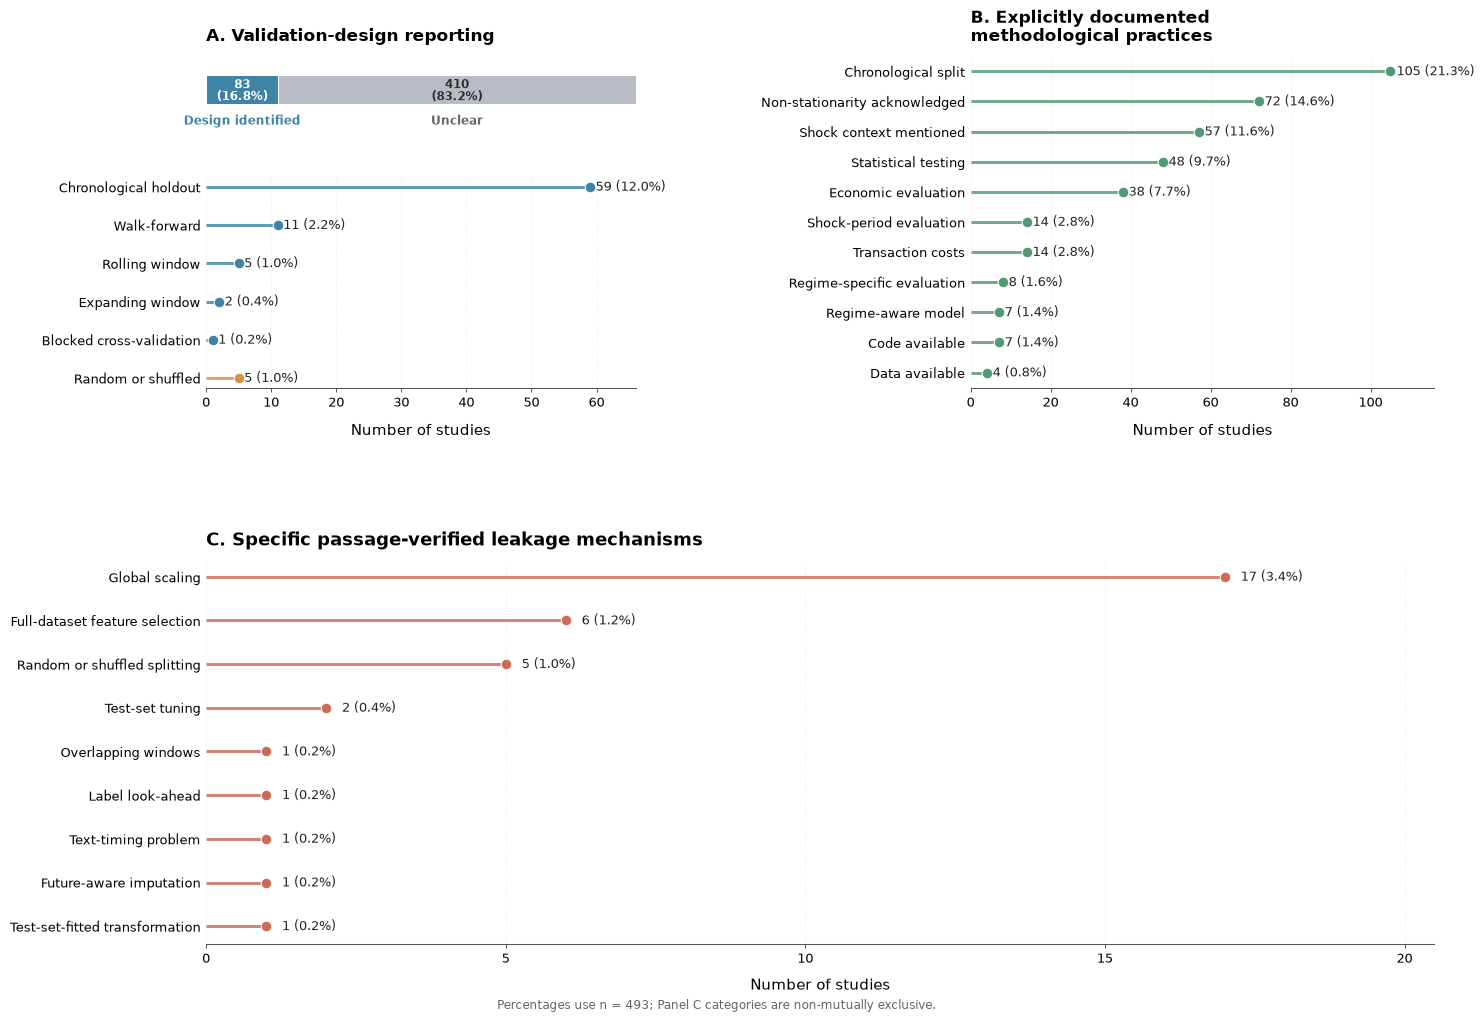


All count and integrity checks passed.

Panel A:
  Design identified       : 83 (16.8%)
  Temporally ordered      : 78 (15.8%)
  Random or shuffled      : 5 (1.0%)
  Unclear                 : 410 (83.2%)

Panel C:
  Mechanism assignments   : 35
  Unique high-risk studies: 31
  Low-risk studies        : 7
  Unclear-risk studies    : 455

Created files:
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Reconciled.png
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Reconciled.pdf
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Reconciled.svg
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Predicti

In [4]:
%reset -f
%run regenerate_figure13_reconciled.py

In [7]:
%reset -f
%run regenerate_table18_reconciled_v3.py


Reconciled audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Methodological_Audit_Reconciled.csv

Frozen method-family register:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Reconciled totals:
  Temporally ordered                :  78 (15.8%)
  Training-only preprocessing       :  21 (4.3%)
  Explicit high leakage risk        :  31 (6.3%)
  Economic evaluation               :  38 (7.7%)
  Formal statistical testing        :  48 (9.7%)
  Code available                    :   7 (1.4%)

RECONCILED TABLE 18
Method family                              | Studies | Temporally ordered   | Training-only preprocessing  | Explicit high leakage risk | Economic evaluation  | Formal statistical testing  | Code available  
---------------------------------------------------------------------------------------------------------------------------

In [2]:
%reset -f
%run Figure18_Q1_Complete_Code_RECONCILED_v2.py

Project directory : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input directory   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey
Method workbook   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section7_Sankey_Working_COMPLETED.xlsx
Reconciled audit  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Section5_5_Methodological_Audit_Reconciled.csv
Output directory  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure18_Output

All required input files were found successfully.

Merged records: 493

METHOD-FAMILY TOTALS
Method_Group
Deep and hybrid deep learning         227
Transformer, graph, and multimodal     97
Metaheuristic and ensemble             85
Sentiment and NLP                      81
Sparse and other families               3
Name: count, dtype: int64

VALIDATION TOTALS
Validation_

In [11]:
from __future__ import annotations

from pathlib import Path
import csv
import re
from collections import Counter
from typing import Any

import plotly.graph_objects as go


# ============================================================
# 1. PROJECT SETTINGS
# ============================================================

PROJECT_ROOT = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

INPUT_CANDIDATES = [
    PROJECT_ROOT
    / "07_Systematic_Review_Dataset"
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "07_Reference_Outputs_Web"
    / "Section7_Final_Study_Level_Sankey_Input.csv",
]

OUTPUT_DIR = PROJECT_ROOT / "Figure17_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SHOW_FIGURE = True


# ============================================================
# 2. FROZEN MANUSCRIPT COUNTS
# ============================================================

FROZEN_PERIOD_COUNTS = {
    "2016-2020": 27,
    "2021-2022": 36,
    "2023-2024": 49,
    "2025-2026": 381,
}

FROZEN_FAMILY_COUNTS = {
    "Hybrid deep-learning models": 110,
    "Transformer/attention-based models": 68,
    "Deep-learning models": 117,
    "Metaheuristic-optimized models": 51,
    "Sentiment/NLP-driven models": 81,
    "Multimodal-fusion models": 13,
    "Graph-based models": 16,
    "Other/unclear": 2,
    "Ensemble/tree-based machine learning": 34,
    "ANN/neuro-fuzzy models": 1,
}

FROZEN_TARGET_COUNTS = {
    "Price level": 381,
    "Multi-target": 33,
    "Direction": 48,
    "Return": 17,
    "Trend or regime": 10,
    "Not reported": 4,
}

PERIOD_ORDER = list(FROZEN_PERIOD_COUNTS)
FAMILY_ORDER = list(FROZEN_FAMILY_COUNTS)
TARGET_ORDER = list(FROZEN_TARGET_COUNTS)


# ============================================================
# 3. INPUT COLUMN REQUIREMENTS
# ============================================================

REQUIRED_COLUMNS = {
    "Paper_ID",
    "Year",
    "Principal_Method_Family",
    "Target_Primary",
}


# ============================================================
# 4. NORMALIZATION ALIASES
# ============================================================

FAMILY_ALIASES = {
    "deep learning": "Deep-learning models",
    "deep learning models": "Deep-learning models",

    "hybrid deep learning": "Hybrid deep-learning models",
    "hybrid deep learning models": "Hybrid deep-learning models",

    "sentiment nlp": "Sentiment/NLP-driven models",
    "sentiment nlp driven models": "Sentiment/NLP-driven models",

    "transformer attention": "Transformer/attention-based models",
    "transformer attention based models":
        "Transformer/attention-based models",

    "metaheuristic optimized": "Metaheuristic-optimized models",
    "metaheuristic optimized models":
        "Metaheuristic-optimized models",

    "ensemble tree based machine learning":
        "Ensemble/tree-based machine learning",

    "graph based": "Graph-based models",
    "graph based models": "Graph-based models",

    "multimodal fusion": "Multimodal-fusion models",
    "multimodal fusion models": "Multimodal-fusion models",

    "other": "Other/unclear",
    "other unclear": "Other/unclear",

    "ann neuro fuzzy": "ANN/neuro-fuzzy models",
    "ann neuro fuzzy models": "ANN/neuro-fuzzy models",
}

TARGET_ALIASES = {
    "price": "Price level",
    "price level": "Price level",

    "return": "Return",

    "direction": "Direction",

    "trend regime": "Trend or regime",
    "trend or regime": "Trend or regime",

    "multi target": "Multi-target",

    "not reported": "Not reported",
}


# ============================================================
# 5. JOURNAL FIGURE SETTINGS
# ============================================================

FIGURE_WIDTH = 1800
FIGURE_HEIGHT = 1050
PNG_SCALE = 3

FONT_FAMILY = "Arial"

REGULAR_LABEL_FONT_SIZE = 19
COUNT_FONT_PERCENT = 78
COLUMN_HEADING_FONT_SIZE = 24

NODE_THICKNESS = 18
NODE_LINE_WIDTH = 0.75

# Sankey-relative node locations
PERIOD_X = 0.020
FAMILY_X = 0.500
TARGET_X = 0.970

# Leave sufficient external space for labels.
DOMAIN_X0 = 0.055
DOMAIN_X1 = 0.945
DOMAIN_Y0 = 0.040
DOMAIN_Y1 = 0.900

PERIOD_GAP = 0.050
FAMILY_GAP = 0.017
TARGET_GAP = 0.038

NODE_TOP = 0.025
NODE_BOTTOM = 0.975

PERIOD_LINK_ALPHA = 0.26
TARGET_LINK_ALPHA = 0.34

LABEL_BACKGROUND_ALPHA = 0.78

# Heading locations in complete figure coordinates.
# These are intentionally independent of node locations.
HEADING_POSITIONS = {
    "Publication period": 0.135,
    "Principal method family": 0.515,
    "Primary forecasting target": 0.865,
}


# ============================================================
# 6. COLOUR PALETTE
# ============================================================

PERIOD_COLOURS = {
    "2016-2020": "#5B8CC0",
    "2021-2022": "#4CA6A8",
    "2023-2024": "#F28E6B",
    "2025-2026": "#9B6CE3",
}

FAMILY_COLOURS = {
    "Hybrid deep-learning models": "#4CC9E8",
    "Transformer/attention-based models": "#A6D854",
    "Deep-learning models": "#F4A261",
    "Metaheuristic-optimized models": "#D96BC6",
    "Sentiment/NLP-driven models": "#E76F91",
    "Multimodal-fusion models": "#E76F51",
    "Graph-based models": "#6C8CD5",
    "Other/unclear": "#A7A7A7",
    "Ensemble/tree-based machine learning": "#E9B44C",
    "ANN/neuro-fuzzy models": "#8A9A5B",
}

TARGET_COLOURS = {
    "Price level": "#F4A261",
    "Multi-target": "#D96BC6",
    "Direction": "#E76F91",
    "Return": "#4CC9E8",
    "Trend or regime": "#8BC34A",
    "Not reported": "#E9B44C",
}


# ============================================================
# 7. DISPLAY LABELS
# ============================================================

DISPLAY_LABELS = {
    "Ensemble/tree-based machine learning":
        "Ensemble/tree-based ML",

    "Transformer/attention-based models":
        "Transformer/attention-based<br>models",

    "Hybrid deep-learning models":
        "Hybrid deep-learning<br>models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized<br>models",

    "Sentiment/NLP-driven models":
        "Sentiment/NLP-driven<br>models",

    "Multimodal-fusion models":
        "Multimodal-fusion models",

    "ANN/neuro-fuzzy models":
        "ANN/neuro-fuzzy models",

    "Trend or regime":
        "Trend or regime",

    "Not reported":
        "Not reported",
}


# ============================================================
# 8. TEXT HELPERS
# ============================================================

def clean(value: object) -> str:
    """Normalize surrounding and repeated whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def normalized_key(value: object) -> str:
    """Create a punctuation-independent lookup key."""

    text = clean(value).lower()

    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text,
    )

    return " ".join(text.split())


def hex_to_rgba(
    hexadecimal: str,
    alpha: float,
) -> str:
    """Convert #RRGGBB to Plotly rgba format."""

    text = hexadecimal.lstrip("#")

    if len(text) != 6:
        raise ValueError(
            f"Invalid hexadecimal colour: {hexadecimal}"
        )

    red = int(text[0:2], 16)
    green = int(text[2:4], 16)
    blue = int(text[4:6], 16)

    return (
        f"rgba({red},{green},{blue},{alpha:.3f})"
    )


def period_from_year(year_text: str) -> str:
    """Map publication year to the frozen review periods."""

    try:
        year = int(float(clean(year_text)))

    except ValueError as error:
        raise ValueError(
            f"Invalid publication year: {year_text!r}"
        ) from error

    if 2016 <= year <= 2020:
        return "2016-2020"

    if 2021 <= year <= 2022:
        return "2021-2022"

    if 2023 <= year <= 2024:
        return "2023-2024"

    if 2025 <= year <= 2026:
        return "2025-2026"

    raise ValueError(
        "Publication year lies outside the frozen "
        f"technical-synthesis periods: {year}"
    )


def normalize_family(value: str) -> str:
    """Normalize the principal method-family coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_FAMILY_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in FAMILY_ALIASES:
        return FAMILY_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized method family: {value!r}"
    )


def normalize_target(value: str) -> str:
    """Normalize the primary target coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_TARGET_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in TARGET_ALIASES:
        return TARGET_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized forecasting target: {value!r}"
    )


def journal_label(
    item: str,
    count: int,
) -> str:
    """Create a compact label with a smaller count line."""

    display = DISPLAY_LABELS.get(item, item)

    return (
        f"{display}<br>"
        f"<span style='font-size:{COUNT_FONT_PERCENT}%'>"
        f"(n={count:,})"
        f"</span>"
    )


# ============================================================
# 9. INPUT DISCOVERY
# ============================================================

def find_input() -> Path:
    """Locate the final 493-study Sankey input CSV."""

    for path in INPUT_CANDIDATES:
        if path.exists():
            return path

    matches: list[Path] = []

    for path in PROJECT_ROOT.rglob("*.csv"):

        try:
            with path.open(
                "r",
                encoding="utf-8-sig",
                newline="",
            ) as file:

                reader = csv.reader(file)
                header = next(reader, [])

        except Exception:
            continue

        if REQUIRED_COLUMNS.issubset(set(header)):
            matches.append(path)

    if len(matches) == 1:
        return matches[0]

    if not matches:
        raise FileNotFoundError(
            "No valid 493-row Sankey input CSV was found.\n"
            "Required columns:\n"
            "Paper_ID, Year, Principal_Method_Family, "
            "Target_Primary\n\n"
            "Expected filename:\n"
            "Section7_Final_Study_Level_Sankey_Input.csv"
        )

    raise RuntimeError(
        "More than one valid Sankey input CSV was found:\n"
        + "\n".join(str(path) for path in matches)
    )


# ============================================================
# 10. COUNT VALIDATION
# ============================================================

def assert_counts(
    label: str,
    observed: Counter,
    expected: dict[str, int],
) -> None:
    """Verify observed distributions against frozen counts."""

    observed_dict = dict(observed)

    if observed_dict == expected:
        return

    print(f"\n{label} count mismatch")

    print("\nObserved:")
    for item in expected:
        print(
            f"  {item}: "
            f"{observed_dict.get(item, 0)}"
        )

    print("\nExpected:")
    for item, count in expected.items():
        print(f"  {item}: {count}")

    unexpected = {
        item: count
        for item, count in observed_dict.items()
        if item not in expected
    }

    if unexpected:
        print("\nUnexpected categories:")
        for item, count in unexpected.items():
            print(f"  {item}: {count}")

    raise AssertionError(
        f"{label} counts do not match "
        "the frozen manuscript values."
    )


# ============================================================
# 11. NODE POSITIONING
# ============================================================

def calculate_column_centres(
    order: list[str],
    counts: dict[str, int],
    gap: float,
) -> dict[str, float]:
    """
    Calculate non-overlapping node centres proportional to
    node totals.

    Plotly Sankey uses y=0 at the top and y=1 at the bottom.
    """

    node_count = len(order)

    total_span = NODE_BOTTOM - NODE_TOP

    total_gap = (
        gap * max(node_count - 1, 0)
    )

    available_height = total_span - total_gap

    if available_height <= 0:
        raise ValueError(
            "The selected vertical gap is too large "
            "for this node column."
        )

    total_count = sum(
        counts[item]
        for item in order
    )

    cursor = NODE_TOP
    centres: dict[str, float] = {}

    for item in order:

        node_height = (
            available_height
            * counts[item]
            / total_count
        )

        centres[item] = (
            cursor + node_height / 2.0
        )

        cursor += node_height + gap

    return centres

def repel_label_positions(
    order: list[str],
    raw_positions: dict[str, float],
    minimum_gap: float,
    lower_limit: float = 0.035,
    upper_limit: float = 0.965,
) -> dict[str, float]:
    """
    Separate annotation positions without changing Sankey-node
    positions or ribbon values.

    Plotly Sankey coordinates increase from top to bottom.
    """

    ordered_items = sorted(
        order,
        key=lambda item: raw_positions[item],
    )

    adjusted = {
        item: min(
            max(raw_positions[item], lower_limit),
            upper_limit,
        )
        for item in ordered_items
    }

    # Forward pass
    for index in range(1, len(ordered_items)):

        previous_item = ordered_items[index - 1]
        current_item = ordered_items[index]

        minimum_position = (
            adjusted[previous_item]
            + minimum_gap
        )

        if adjusted[current_item] < minimum_position:
            adjusted[current_item] = minimum_position

    # Shift upward when the final label exceeds the limit.
    final_item = ordered_items[-1]

    if adjusted[final_item] > upper_limit:

        overflow = (
            adjusted[final_item]
            - upper_limit
        )

        for item in ordered_items:
            adjusted[item] -= overflow

    # Backward pass
    for index in range(
        len(ordered_items) - 2,
        -1,
        -1,
    ):

        current_item = ordered_items[index]
        next_item = ordered_items[index + 1]

        maximum_position = (
            adjusted[next_item]
            - minimum_gap
        )

        if adjusted[current_item] > maximum_position:
            adjusted[current_item] = maximum_position

    # Final lower-bound correction
    first_item = ordered_items[0]

    if adjusted[first_item] < lower_limit:

        underflow = (
            lower_limit
            - adjusted[first_item]
        )

        for item in ordered_items:
            adjusted[item] += underflow

    return adjusted


# ============================================================
# 12. CUSTOM ANNOTATIONS
# ============================================================

def add_node_annotation(
    annotations: list[dict[str, Any]],
    node_x: float,
    label_y: float,
    text: str,
    stage: str,
) -> None:
    """
    Add a manually positioned label without altering the
    underlying Sankey node or flow.
    """

    paper_x = (
        DOMAIN_X0
        + node_x
        * (DOMAIN_X1 - DOMAIN_X0)
    )

    paper_y = (
        DOMAIN_Y0
        + (1.0 - label_y)
        * (DOMAIN_Y1 - DOMAIN_Y0)
    )

    if stage == "period":

        label_x = paper_x + 0.012
        x_anchor = "left"
        alignment = "left"

    elif stage == "family":

        label_x = paper_x + 0.013
        x_anchor = "left"
        alignment = "left"

    elif stage == "target":

        label_x = paper_x - 0.012
        x_anchor = "right"
        alignment = "right"

    else:
        raise ValueError(
            f"Unsupported annotation stage: {stage}"
        )

    annotations.append(
        {
            "x": label_x,
            "y": paper_y,

            "xref": "paper",
            "yref": "paper",

            "text": text,
            "showarrow": False,

            "xanchor": x_anchor,
            "yanchor": "middle",
            "align": alignment,

            "font": {
                "family": FONT_FAMILY,
                "size": REGULAR_LABEL_FONT_SIZE,
                "color": "#303030",
            },

            "bgcolor": (
                "rgba(255,255,255,"
                f"{LABEL_BACKGROUND_ALPHA})"
            ),

            "bordercolor":
                "rgba(255,255,255,0)",

            "borderpad": 1.2,
        }
    )


# ============================================================
# 13. MAIN WORKFLOW
# ============================================================

def main() -> None:

    input_path = find_input()

    print("Input file:")
    print(input_path)

    with input_path.open(
        "r",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        rows = list(
            csv.DictReader(file)
        )

    if len(rows) != 493:
        raise AssertionError(
            f"Expected 493 rows; found {len(rows)}."
        )

    paper_ids = [
        clean(row["Paper_ID"])
        for row in rows
    ]

    if any(not paper_id for paper_id in paper_ids):
        raise AssertionError(
            "One or more Paper_ID values are blank."
        )

    if len(set(paper_ids)) != 493:

        duplicates = sorted(
            paper_id
            for paper_id, count
            in Counter(paper_ids).items()
            if count > 1
        )

        raise AssertionError(
            "Paper_ID values are not unique:\n"
            + "\n".join(duplicates)
        )

    normalized_rows: list[dict[str, str]] = []

    for row in rows:

        normalized_rows.append(
            {
                "Paper_ID": clean(
                    row["Paper_ID"]
                ),

                "Period": period_from_year(
                    row["Year"]
                ),

                "Method_Family": normalize_family(
                    row["Principal_Method_Family"]
                ),

                "Target": normalize_target(
                    row["Target_Primary"]
                ),
            }
        )

    period_counts = Counter(
        row["Period"]
        for row in normalized_rows
    )

    family_counts = Counter(
        row["Method_Family"]
        for row in normalized_rows
    )

    target_counts = Counter(
        row["Target"]
        for row in normalized_rows
    )

    assert_counts(
        "Period",
        period_counts,
        FROZEN_PERIOD_COUNTS,
    )

    assert_counts(
        "Method-family",
        family_counts,
        FROZEN_FAMILY_COUNTS,
    )

    assert_counts(
        "Target",
        target_counts,
        FROZEN_TARGET_COUNTS,
    )

    period_family = Counter(
        (
            row["Period"],
            row["Method_Family"],
        )
        for row in normalized_rows
    )

    family_target = Counter(
        (
            row["Method_Family"],
            row["Target"],
        )
        for row in normalized_rows
    )

    if sum(period_family.values()) != 493:
        raise AssertionError(
            "Period-to-method flows do not total 493."
        )

    if sum(family_target.values()) != 493:
        raise AssertionError(
            "Method-to-target flows do not total 493."
        )


    # ========================================================
    # 14. NODE DEFINITIONS
    # ========================================================

    node_items = (
        PERIOD_ORDER
        + FAMILY_ORDER
        + TARGET_ORDER
    )

    node_stage = (
        ["period"] * len(PERIOD_ORDER)
        + ["family"] * len(FAMILY_ORDER)
        + ["target"] * len(TARGET_ORDER)
    )

    node_counts = (
        [
            FROZEN_PERIOD_COUNTS[item]
            for item in PERIOD_ORDER
        ]
        + [
            FROZEN_FAMILY_COUNTS[item]
            for item in FAMILY_ORDER
        ]
        + [
            FROZEN_TARGET_COUNTS[item]
            for item in TARGET_ORDER
        ]
    )

    node_colours = (
        [
            PERIOD_COLOURS[item]
            for item in PERIOD_ORDER
        ]
        + [
            FAMILY_COLOURS[item]
            for item in FAMILY_ORDER
        ]
        + [
            TARGET_COLOURS[item]
            for item in TARGET_ORDER
        ]
    )

    period_y = calculate_column_centres(
        PERIOD_ORDER,
        FROZEN_PERIOD_COUNTS,
        PERIOD_GAP,
    )

    family_y = calculate_column_centres(
        FAMILY_ORDER,
        FROZEN_FAMILY_COUNTS,
        FAMILY_GAP,
    )

    target_y = calculate_column_centres(
        TARGET_ORDER,
        FROZEN_TARGET_COUNTS,
        TARGET_GAP,
    )

    node_x = (
        [PERIOD_X] * len(PERIOD_ORDER)
        + [FAMILY_X] * len(FAMILY_ORDER)
        + [TARGET_X] * len(TARGET_ORDER)
    )

    node_y = (
        [
            period_y[item]
            for item in PERIOD_ORDER
        ]
        + [
            family_y[item]
            for item in FAMILY_ORDER
        ]
        + [
            target_y[item]
            for item in TARGET_ORDER
        ]
    )

    node_index = {
        item: index
        for index, item
        in enumerate(node_items)
    }

    node_customdata = [
        [
            item,
            stage,
            count,
        ]
        for item, stage, count
        in zip(
            node_items,
            node_stage,
            node_counts,
        )
    ]

# Node positions determine ribbon geometry.
# Label positions are independently separated to prevent overlap.

period_label_y = repel_label_positions(
    order=PERIOD_ORDER,
    raw_positions=period_y,
    minimum_gap=0.100,
)

family_label_y = repel_label_positions(
    order=FAMILY_ORDER,
    raw_positions=family_y,
    minimum_gap=0.057,
)

target_label_y = repel_label_positions(
    order=TARGET_ORDER,
    raw_positions=target_y,
    minimum_gap=0.075,
)


    # ========================================================
    # 15. LINK DEFINITIONS
    # ========================================================

sources: list[int] = []
targets: list[int] = []
values: list[int] = []
link_colours: list[str] = []
link_customdata: list[list[Any]] = []

flow_rows: list[dict[str, Any]] = []

for period in PERIOD_ORDER:

    for family in FAMILY_ORDER:

        count = period_family.get(
            (period, family),
            0,
        )

        if count <= 0:
            continue

        sources.append(
            node_index[period]
        )

        targets.append(
            node_index[family]
        )

        values.append(count)

        link_colours.append(
            hex_to_rgba(
                FAMILY_COLOURS[family],
                PERIOD_LINK_ALPHA,
            )
        )

        link_customdata.append(
            [
                period,
                family,
                count,
                "Publication period → method family",
            ]
        )

        flow_rows.append(
            {
                "Stage": "Period_to_Method",
                "Source": period,
                "Target": family,
                "Studies": count,
            }
        )

for family in FAMILY_ORDER:

    for target in TARGET_ORDER:

        count = family_target.get(
            (family, target),
            0,
        )

        if count <= 0:
            continue

        sources.append(
            node_index[family]
        )

        targets.append(
            node_index[target]
        )

        values.append(count)

        link_colours.append(
            hex_to_rgba(
                FAMILY_COLOURS[family],
                TARGET_LINK_ALPHA,
            )
        )

        link_customdata.append(
            [
                family,
                target,
                count,
                "Method family → forecasting target",
            ]
        )

        flow_rows.append(
            {
                "Stage": "Method_to_Target",
                "Source": family,
                "Target": target,
                "Studies": count,
            }
        )


# ========================================================
# 16. BUILD THE SANKEY
# ========================================================

figure = go.Figure(
    go.Sankey(
        arrangement="fixed",
        orientation="h",

        domain={
            "x": [DOMAIN_X0, DOMAIN_X1],
            "y": [DOMAIN_Y0, DOMAIN_Y1],
        },

        node={
            "pad": 18,
            "thickness": NODE_THICKNESS,

            "line": {
                "color":
                    "rgba(45,45,45,0.72)",

                "width":
                    NODE_LINE_WIDTH,
            },

            # Labels are added as custom annotations.
            "label": [""] * len(node_items),

            "color": node_colours,
            "x": node_x,
            "y": node_y,

            "customdata":
                node_customdata,

            "hovertemplate": (
                "<b>%{customdata[0]}</b><br>"
                "Stage: %{customdata[1]}<br>"
                "Studies: %{customdata[2]:,}"
                "<extra></extra>"
            ),
        },

        link={
            "source": sources,
            "target": targets,
            "value": values,
            "color": link_colours,

            "customdata":
                link_customdata,

            "hovertemplate": (
                "<b>%{customdata[0]}</b>"
                " → "
                "<b>%{customdata[1]}</b><br>"
                "%{customdata[3]}<br>"
                "Studies: %{customdata[2]:,}"
                "<extra></extra>"
            ),
        },
    )
)


# ========================================================
# 17. COLUMN HEADINGS
# ========================================================

annotations: list[dict[str, Any]] = []

heading_specs = [
    (
        PERIOD_X,
        "Publication period",
    ),
    (
        FAMILY_X,
        "Principal method family",
    ),
    (
        TARGET_X,
        "Primary forecasting target",
    ),
]

for sankey_x, heading in heading_specs:

    paper_x = (
        DOMAIN_X0
        + sankey_x
        * (DOMAIN_X1 - DOMAIN_X0)
    )

    annotations.append(
        {
            "x": paper_x,
            "y": 0.975,

            "xref": "paper",
            "yref": "paper",

            "text": f"<b>{heading}</b>",

            "showarrow": False,

            "xanchor": "center",
            "yanchor": "middle",

            "font": {
                "family": FONT_FAMILY,
                "size":
                    COLUMN_HEADING_FONT_SIZE,
                "color": "#252525",
            },
        }
    )


# ========================================================
# 18. CUSTOM NODE LABELS
# ========================================================

for item in PERIOD_ORDER:

    add_node_annotation(
        annotations=annotations,
        node_x=PERIOD_X,
        label_y=period_label_y[item],
        text=journal_label(
            item,
            FROZEN_PERIOD_COUNTS[item],
        ),
        stage="period",
    )

for item in FAMILY_ORDER:

    add_node_annotation(
        annotations=annotations,
        node_x=FAMILY_X,
        label_y=family_label_y[item],
        text=journal_label(
            item,
            FROZEN_FAMILY_COUNTS[item],
        ),
        stage="family",
    )

for item in TARGET_ORDER:

    add_node_annotation(
        annotations=annotations,
        node_x=TARGET_X,
        label_y=target_label_y[item],
        text=journal_label(
            item,
            FROZEN_TARGET_COUNTS[item],
        ),
        stage="target",
    )


# ========================================================
# 19. FINAL LAYOUT
# ========================================================

figure.update_layout(
    width=FIGURE_WIDTH,
    height=FIGURE_HEIGHT,

    paper_bgcolor="white",
    plot_bgcolor="white",

    font={
        "family": FONT_FAMILY,
        "size":
            REGULAR_LABEL_FONT_SIZE,
        "color": "#303030",
    },

    margin={
        "l": 30,
        "r": 42,
        "t": 55,
        "b": 28,
    },

    annotations=annotations,
)


# ========================================================
# 20. OUTPUT PATHS
# ========================================================

base_name = (
    "Figure17_Period_Method_Target_"
    "Sankey_SCIE_Q1"
)

pdf_path = (
    OUTPUT_DIR
    / f"{base_name}.pdf"
)

svg_path = (
    OUTPUT_DIR
    / f"{base_name}.svg"
)

png_path = (
    OUTPUT_DIR
    / f"{base_name}.png"
)

html_path = (
    OUTPUT_DIR
    / f"{base_name}.html"
)

flow_path = (
    OUTPUT_DIR
    / f"{base_name}_Flows.csv"
)

audit_path = (
    OUTPUT_DIR
    / f"{base_name}_Audit.csv"
)


# ========================================================
# 21. EXPORT INTERACTIVE HTML
# ========================================================

figure.write_html(
    html_path,

    include_plotlyjs=True,
    full_html=True,

    config={
        "displaylogo": False,
        "responsive": True,

        "toImageButtonOptions": {
            "format": "png",
            "filename": base_name,
            "width": FIGURE_WIDTH,
            "height": FIGURE_HEIGHT,
            "scale": PNG_SCALE,
        },
    },
)


# ========================================================
# 22. EXPORT VECTOR AND RASTER FILES
# ========================================================

static_export_ok = True

try:

    figure.write_image(
        pdf_path,
        format="pdf",
        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,
        scale=1,
    )

    figure.write_image(
        svg_path,
        format="svg",
        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,
        scale=1,
    )

    figure.write_image(
        png_path,
        format="png",
        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,
        scale=PNG_SCALE,
    )

except Exception as error:

    static_export_ok = False

    print(
        "\nHTML and audit files were generated, "
        "but static export failed."
    )

    print(
        "\nInstall or update Kaleido:"
    )

    print(
        "    pip install -U kaleido"
    )

    print(
        "\nRecent Kaleido versions may require Chrome:"
    )

    print(
        "    plotly_get_chrome"
    )

    print(
        f"\nExport error:\n{error}"
    )


# ========================================================
# 23. FLOW AUDIT CSV
# ========================================================

with flow_path.open(
    "w",
    encoding="utf-8-sig",
    newline="",
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "Stage",
            "Source",
            "Target",
            "Studies",
        ],
    )

    writer.writeheader()
    writer.writerows(flow_rows)


# ========================================================
# 24. VALIDATION AUDIT CSV
# ========================================================

with audit_path.open(
    "w",
    encoding="utf-8-sig",
    newline="",
) as file:

    writer = csv.writer(file)

    writer.writerow(
        [
            "Audit_Item",
            "Observed",
            "Required",
            "Status",
        ]
    )

    writer.writerow(
        [
            "Study rows",
            len(normalized_rows),
            493,
            "PASS",
        ]
    )

    writer.writerow(
        [
            "Unique Paper_ID",
            len(set(paper_ids)),
            493,
            "PASS",
        ]
    )

    writer.writerow(
        [
            "Period-to-method total",
            sum(period_family.values()),
            493,
            "PASS",
        ]
    )

    writer.writerow(
        [
            "Method-to-target total",
            sum(family_target.values()),
            493,
            "PASS",
        ]
    )

    writer.writerow(
        [
            "Period counts",
            str(dict(period_counts)),
            str(FROZEN_PERIOD_COUNTS),
            "PASS",
        ]
    )

    writer.writerow(
        [
            "Method-family counts",
            str(dict(family_counts)),
            str(FROZEN_FAMILY_COUNTS),
            "PASS",
        ]
    )

    writer.writerow(
        [
            "Target counts",
            str(dict(target_counts)),
            str(FROZEN_TARGET_COUNTS),
            "PASS",
        ]
    )


# ========================================================
# 25. DISPLAY AND SUMMARY
# ========================================================

if SHOW_FIGURE:
    figure.show()

print("\nFigure 17 Sankey audit passed.")

print("\nInput:")
print(input_path)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nFlow audit:")
print(flow_path)

print("\nValidation audit:")
print(audit_path)

print("\nInteractive HTML:")
print(html_path)

if static_export_ok:
    print("\nVector PDF:")
    print(pdf_path)

    print("\nVector SVG:")
    print(svg_path)

    print("\nHigh-resolution PNG:")
    print(png_path)
if __name__ == "__main__":
    main()

NameError: name 'period_y' is not defined

In [3]:
from __future__ import annotations

from pathlib import Path
import csv
import re
from collections import Counter
from typing import Any

import plotly.graph_objects as go


# ============================================================
# 1. PROJECT SETTINGS
# ============================================================

PROJECT_ROOT = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

INPUT_CANDIDATES = [
    PROJECT_ROOT
    / "07_Systematic_Review_Dataset"
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "Section7_Final_Study_Level_Sankey_Input.csv",

    PROJECT_ROOT
    / "07_Reference_Outputs_Web"
    / "Section7_Final_Study_Level_Sankey_Input.csv",
]

OUTPUT_DIR = PROJECT_ROOT / "Figure16_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SHOW_FIGURE = True


# ============================================================
# 2. FROZEN MANUSCRIPT COUNTS
# ============================================================

FROZEN_PERIOD_COUNTS = {
    "2016-2020": 27,
    "2021-2022": 36,
    "2023-2024": 48,
    "2025-2026": 382,
}

FROZEN_FAMILY_COUNTS = {
    "Hybrid deep-learning models": 110,
    "Transformer/attention-based models": 68,
    "Deep-learning models": 117,
    "Metaheuristic-optimized models": 51,
    "Sentiment/NLP-driven models": 81,
    "Multimodal-fusion models": 13,
    "Graph-based models": 16,
    "Other/unclear": 2,
    "Ensemble/tree-based machine learning": 34,
    "ANN/neuro-fuzzy models": 1,
}

FROZEN_TARGET_COUNTS = {
    "Price level": 381,
    "Multi-target": 33,
    "Direction": 48,
    "Return": 17,
    "Trend or regime": 10,
    "Not reported": 4,
}

PERIOD_ORDER = list(FROZEN_PERIOD_COUNTS)
FAMILY_ORDER = list(FROZEN_FAMILY_COUNTS)
TARGET_ORDER = list(FROZEN_TARGET_COUNTS)


# ============================================================
# 3. INPUT COLUMN REQUIREMENTS
# ============================================================

REQUIRED_COLUMNS = {
    "Paper_ID",
    "Year",
    "Principal_Method_Family",
    "Target_Primary",
}


# ============================================================
# 4. NORMALIZATION ALIASES
# ============================================================

FAMILY_ALIASES = {
    "deep learning": "Deep-learning models",
    "deep learning models": "Deep-learning models",

    "hybrid deep learning": "Hybrid deep-learning models",
    "hybrid deep learning models": "Hybrid deep-learning models",

    "sentiment nlp": "Sentiment/NLP-driven models",
    "sentiment nlp driven models": "Sentiment/NLP-driven models",

    "transformer attention": "Transformer/attention-based models",
    "transformer attention based models":
        "Transformer/attention-based models",

    "metaheuristic optimized": "Metaheuristic-optimized models",
    "metaheuristic optimized models":
        "Metaheuristic-optimized models",

    "ensemble tree based machine learning":
        "Ensemble/tree-based machine learning",

    "graph based": "Graph-based models",
    "graph based models": "Graph-based models",

    "multimodal fusion": "Multimodal-fusion models",
    "multimodal fusion models": "Multimodal-fusion models",

    "other": "Other/unclear",
    "other unclear": "Other/unclear",

    "ann neuro fuzzy": "ANN/neuro-fuzzy models",
    "ann neuro fuzzy models": "ANN/neuro-fuzzy models",
}

TARGET_ALIASES = {
    "price": "Price level",
    "price level": "Price level",

    "return": "Return",

    "direction": "Direction",

    "trend regime": "Trend or regime",
    "trend or regime": "Trend or regime",

    "multi target": "Multi-target",

    "not reported": "Not reported",
}


# ============================================================
# 5. JOURNAL FIGURE SETTINGS
# ============================================================

FIGURE_WIDTH = 1800
FIGURE_HEIGHT = 1200
PNG_SCALE = 3

FONT_FAMILY = "Arial"

REGULAR_LABEL_FONT_SIZE = 19
COUNT_FONT_PERCENT = 78
COLUMN_HEADING_FONT_SIZE = 24

NODE_THICKNESS = 18
NODE_LINE_WIDTH = 0.75

# Sankey-relative node locations
PERIOD_X = 0.020
FAMILY_X = 0.470
TARGET_X = 0.975

# Leave sufficient external space for labels.
DOMAIN_X0 = 0.055
DOMAIN_X1 = 0.945
DOMAIN_Y0 = 0.040
DOMAIN_Y1 = 0.900

PERIOD_GAP = 0.050
FAMILY_GAP = 0.017
TARGET_GAP = 0.038

NODE_TOP = 0.025
NODE_BOTTOM = 0.975

PERIOD_LINK_ALPHA = 0.34
TARGET_LINK_ALPHA = 0.44

LABEL_BACKGROUND_ALPHA = 0.20

# Heading locations in complete figure coordinates.
# These are intentionally independent of node locations.
HEADING_POSITIONS = {
    "Publication period": 0.135,
    "Principal method family": 0.515,
    "Primary forecasting target": 0.865,
}


# ============================================================
# 6. COLOUR PALETTE
# ============================================================

PERIOD_COLOURS = {
    "2016-2020": "#5B8CC0",
    "2021-2022": "#4CA6A8",
    "2023-2024": "#F28E6B",
    "2025-2026": "#9B6CE3",
}

FAMILY_COLOURS = {
    "Hybrid deep-learning models": "#4CC9E8",
    "Transformer/attention-based models": "#A6D854",
    "Deep-learning models": "#F4A261",
    "Metaheuristic-optimized models": "#D96BC6",
    "Sentiment/NLP-driven models": "#E76F91",
    "Multimodal-fusion models": "#E76F51",
    "Graph-based models": "#6C8CD5",
    "Other/unclear": "#A7A7A7",
    "Ensemble/tree-based machine learning": "#E9B44C",
    "ANN/neuro-fuzzy models": "#8A9A5B",
}

TARGET_COLOURS = {
    "Price level": "#6E6E6E",
    "Multi-target": "#8A8A8A",
    "Direction": "#9C9C9C",
    "Return": "#ADADAD",
    "Trend or regime": "#BDBDBD",
    "Not reported": "#D0D0D0",
}


# ============================================================
# 7. DISPLAY LABELS
# ============================================================

DISPLAY_LABELS = {
    "Ensemble/tree-based machine learning":
        "Ensemble/tree-based ML",

    "Transformer/attention-based models":
        "Transformer/attention-based<br>models",

    "Hybrid deep-learning models":
        "Hybrid deep-learning<br>models",

    "Metaheuristic-optimized models":
        "Metaheuristic-optimized<br>models",

    "Sentiment/NLP-driven models":
        "Sentiment/NLP-driven<br>models",

    "Multimodal-fusion models":
        "Multimodal-fusion models",

    "ANN/neuro-fuzzy models":
        "ANN/neuro-fuzzy models",

    "Trend or regime":
        "Trend or regime",

    "Not reported":
        "Not reported",
}


# ============================================================
# 8. TEXT HELPERS
# ============================================================

def clean(value: object) -> str:
    """Normalize surrounding and repeated whitespace."""

    return " ".join(
        str(value or "").strip().split()
    )


def normalized_key(value: object) -> str:
    """Create a punctuation-independent lookup key."""

    text = clean(value).lower()

    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text,
    )

    return " ".join(text.split())


def hex_to_rgba(
    hexadecimal: str,
    alpha: float,
) -> str:
    """Convert #RRGGBB to Plotly rgba format."""

    text = hexadecimal.lstrip("#")

    if len(text) != 6:
        raise ValueError(
            f"Invalid hexadecimal colour: {hexadecimal}"
        )

    red = int(text[0:2], 16)
    green = int(text[2:4], 16)
    blue = int(text[4:6], 16)

    return (
        f"rgba({red},{green},{blue},{alpha:.3f})"
    )


def period_from_year(year_text: str) -> str:
    """Map publication year to the frozen review periods."""

    try:
        year = int(float(clean(year_text)))

    except ValueError as error:
        raise ValueError(
            f"Invalid publication year: {year_text!r}"
        ) from error

    if 2016 <= year <= 2020:
        return "2016-2020"

    if 2021 <= year <= 2022:
        return "2021-2022"

    if 2023 <= year <= 2024:
        return "2023-2024"

    if 2025 <= year <= 2026:
        return "2025-2026"

    raise ValueError(
        "Publication year lies outside the frozen "
        f"technical-synthesis periods: {year}"
    )


def normalize_family(value: str) -> str:
    """Normalize the principal method-family coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_FAMILY_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in FAMILY_ALIASES:
        return FAMILY_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized method family: {value!r}"
    )


def normalize_target(value: str) -> str:
    """Normalize the primary target coding."""

    cleaned = clean(value)

    if cleaned in FROZEN_TARGET_COUNTS:
        return cleaned

    lookup = normalized_key(cleaned)

    if lookup in TARGET_ALIASES:
        return TARGET_ALIASES[lookup]

    raise ValueError(
        f"Unrecognized forecasting target: {value!r}"
    )


def journal_label(
    item: str,
    count: int,
) -> str:
    """Create a compact label with a smaller count line."""

    display = DISPLAY_LABELS.get(item, item)

    return (
        f"{display}<br>"
        f"<span style='font-size:{COUNT_FONT_PERCENT}%'>"
        f"(n={count:,})"
        f"</span>"
    )

DISPLAY_LABELS.update({
    "2016-2020": "2016–2020",
    "2021-2022": "2021–2022",
    "2023-2024": "2023–2024",
    "2025-2026": "2025–2026",
})


# ============================================================
# 9. INPUT DISCOVERY
# ============================================================

def find_input() -> Path:
    """Locate the final 493-study Sankey input CSV."""

    for path in INPUT_CANDIDATES:
        if path.exists():
            return path

    matches: list[Path] = []

    for path in PROJECT_ROOT.rglob("*.csv"):

        try:
            with path.open(
                "r",
                encoding="utf-8-sig",
                newline="",
            ) as file:

                reader = csv.reader(file)
                header = next(reader, [])

        except Exception:
            continue

        if REQUIRED_COLUMNS.issubset(set(header)):
            matches.append(path)

    if len(matches) == 1:
        return matches[0]

    if not matches:
        raise FileNotFoundError(
            "No valid 493-row Sankey input CSV was found.\n"
            "Required columns:\n"
            "Paper_ID, Year, Principal_Method_Family, "
            "Target_Primary\n\n"
            "Expected filename:\n"
            "Section7_Final_Study_Level_Sankey_Input.csv"
        )

    raise RuntimeError(
        "More than one valid Sankey input CSV was found:\n"
        + "\n".join(str(path) for path in matches)
    )


# ============================================================
# 10. COUNT VALIDATION
# ============================================================

def assert_counts(
    label: str,
    observed: Counter,
    expected: dict[str, int],
) -> None:
    """Verify observed distributions against frozen counts."""

    observed_dict = dict(observed)

    if observed_dict == expected:
        return

    print(f"\n{label} count mismatch")

    print("\nObserved:")
    for item in expected:
        print(
            f"  {item}: "
            f"{observed_dict.get(item, 0)}"
        )

    print("\nExpected:")
    for item, count in expected.items():
        print(f"  {item}: {count}")

    unexpected = {
        item: count
        for item, count in observed_dict.items()
        if item not in expected
    }

    if unexpected:
        print("\nUnexpected categories:")
        for item, count in unexpected.items():
            print(f"  {item}: {count}")

    raise AssertionError(
        f"{label} counts do not match "
        "the frozen manuscript values."
    )


# ============================================================
# 11. NODE POSITIONING
# ============================================================

def calculate_column_centres(
    order: list[str],
    counts: dict[str, int],
    gap: float,
) -> dict[str, float]:
    """
    Calculate non-overlapping node centres proportional to
    node totals.

    Plotly Sankey uses y=0 at the top and y=1 at the bottom.
    """

    node_count = len(order)

    total_span = NODE_BOTTOM - NODE_TOP

    total_gap = (
        gap * max(node_count - 1, 0)
    )

    available_height = total_span - total_gap

    if available_height <= 0:
        raise ValueError(
            "The selected vertical gap is too large "
            "for this node column."
        )

    total_count = sum(
        counts[item]
        for item in order
    )

    cursor = NODE_TOP
    centres: dict[str, float] = {}

    for item in order:

        node_height = (
            available_height
            * counts[item]
            / total_count
        )

        centres[item] = (
            cursor + node_height / 2.0
        )

        cursor += node_height + gap

    return centres

def repel_label_positions(
    order: list[str],
    raw_positions: dict[str, float],
    minimum_gap: float,
    lower_limit: float = 0.035,
    upper_limit: float = 0.965,
) -> dict[str, float]:
    """
    Separate annotation positions without changing Sankey-node
    positions or ribbon values.

    Plotly Sankey coordinates increase from top to bottom.
    """

    ordered_items = sorted(
        order,
        key=lambda item: raw_positions[item],
    )

    adjusted = {
        item: min(
            max(raw_positions[item], lower_limit),
            upper_limit,
        )
        for item in ordered_items
    }

    # Forward pass
    for index in range(1, len(ordered_items)):

        previous_item = ordered_items[index - 1]
        current_item = ordered_items[index]

        minimum_position = (
            adjusted[previous_item]
            + minimum_gap
        )

        if adjusted[current_item] < minimum_position:
            adjusted[current_item] = minimum_position

    # Shift upward when the final label exceeds the limit.
    final_item = ordered_items[-1]

    if adjusted[final_item] > upper_limit:

        overflow = (
            adjusted[final_item]
            - upper_limit
        )

        for item in ordered_items:
            adjusted[item] -= overflow

    # Backward pass
    for index in range(
        len(ordered_items) - 2,
        -1,
        -1,
    ):

        current_item = ordered_items[index]
        next_item = ordered_items[index + 1]

        maximum_position = (
            adjusted[next_item]
            - minimum_gap
        )

        if adjusted[current_item] > maximum_position:
            adjusted[current_item] = maximum_position

    # Final lower-bound correction
    first_item = ordered_items[0]

    if adjusted[first_item] < lower_limit:

        underflow = (
            lower_limit
            - adjusted[first_item]
        )

        for item in ordered_items:
            adjusted[item] += underflow

    return adjusted


# ============================================================
# 12. CUSTOM ANNOTATIONS
# ============================================================

def add_node_annotation(
    annotations: list[dict[str, Any]],
    node_x: float,
    label_y: float,
    text: str,
    stage: str,
) -> None:
    """
    Add a manually positioned label without altering the
    underlying Sankey node or flow.
    """

    paper_x = (
        DOMAIN_X0
        + node_x
        * (DOMAIN_X1 - DOMAIN_X0)
    )

    paper_y = (
        DOMAIN_Y0
        + (1.0 - label_y)
        * (DOMAIN_Y1 - DOMAIN_Y0)
    )

    if stage == "period":

        label_x = paper_x + 0.012
        x_anchor = "left"
        alignment = "left"

    elif stage == "family":

        label_x = paper_x + 0.013
        x_anchor = "left"
        alignment = "left"

    elif stage == "target":

        label_x = paper_x - 0.012
        x_anchor = "right"
        alignment = "right"

    else:
        raise ValueError(
            f"Unsupported annotation stage: {stage}"
        )

    annotations.append(
        {
            "x": label_x,
            "y": paper_y,

            "xref": "paper",
            "yref": "paper",

            "text": text,
            "showarrow": False,

            "xanchor": x_anchor,
            "yanchor": "middle",
            "align": alignment,

            "font": {
                "family": FONT_FAMILY,
                "size": REGULAR_LABEL_FONT_SIZE,
                "color": "#303030",
            },

            "bgcolor": (
                "rgba(255,255,255,"
                f"{LABEL_BACKGROUND_ALPHA})"
            ),

            "bordercolor":
                "rgba(255,255,255,0)",

            "borderpad": 1.2,
        }
    )


# ============================================================
# 13. MAIN WORKFLOW
# ============================================================

def main() -> None:

    input_path = find_input()

    print("Input file:")
    print(input_path)

    with input_path.open(
        "r",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        rows = list(
            csv.DictReader(file)
        )

    if len(rows) != 493:
        raise AssertionError(
            f"Expected 493 rows; found {len(rows)}."
        )

    paper_ids = [
        clean(row["Paper_ID"])
        for row in rows
    ]

    if any(not paper_id for paper_id in paper_ids):
        raise AssertionError(
            "One or more Paper_ID values are blank."
        )

    if len(set(paper_ids)) != 493:

        duplicates = sorted(
            paper_id
            for paper_id, count
            in Counter(paper_ids).items()
            if count > 1
        )

        raise AssertionError(
            "Paper_ID values are not unique:\n"
            + "\n".join(duplicates)
        )

    normalized_rows: list[dict[str, str]] = []

    for row in rows:

        normalized_rows.append(
            {
                "Paper_ID": clean(
                    row["Paper_ID"]
                ),

                "Period": period_from_year(
                    row["Year"]
                ),

                "Method_Family": normalize_family(
                    row["Principal_Method_Family"]
                ),

                "Target": normalize_target(
                    row["Target_Primary"]
                ),
            }
        )

    period_counts = Counter(
        row["Period"]
        for row in normalized_rows
    )

    family_counts = Counter(
        row["Method_Family"]
        for row in normalized_rows
    )

    target_counts = Counter(
        row["Target"]
        for row in normalized_rows
    )

    assert_counts(
        "Period",
        period_counts,
        FROZEN_PERIOD_COUNTS,
    )

    assert_counts(
        "Method-family",
        family_counts,
        FROZEN_FAMILY_COUNTS,
    )

    assert_counts(
        "Target",
        target_counts,
        FROZEN_TARGET_COUNTS,
    )

    period_family = Counter(
        (
            row["Period"],
            row["Method_Family"],
        )
        for row in normalized_rows
    )

    family_target = Counter(
        (
            row["Method_Family"],
            row["Target"],
        )
        for row in normalized_rows
    )

    if sum(period_family.values()) != 493:
        raise AssertionError(
            "Period-to-method flows do not total 493."
        )

    if sum(family_target.values()) != 493:
        raise AssertionError(
            "Method-to-target flows do not total 493."
        )


    # ========================================================
    # 14. NODE DEFINITIONS
    # ========================================================

    node_items = (
        PERIOD_ORDER
        + FAMILY_ORDER
        + TARGET_ORDER
    )

    node_stage = (
        ["period"] * len(PERIOD_ORDER)
        + ["family"] * len(FAMILY_ORDER)
        + ["target"] * len(TARGET_ORDER)
    )

    node_counts = (
        [
            FROZEN_PERIOD_COUNTS[item]
            for item in PERIOD_ORDER
        ]
        + [
            FROZEN_FAMILY_COUNTS[item]
            for item in FAMILY_ORDER
        ]
        + [
            FROZEN_TARGET_COUNTS[item]
            for item in TARGET_ORDER
        ]
    )

    node_colours = (
        [
            PERIOD_COLOURS[item]
            for item in PERIOD_ORDER
        ]
        + [
            FAMILY_COLOURS[item]
            for item in FAMILY_ORDER
        ]
        + [
            TARGET_COLOURS[item]
            for item in TARGET_ORDER
        ]
    )

    period_y = calculate_column_centres(
        PERIOD_ORDER,
        FROZEN_PERIOD_COUNTS,
        PERIOD_GAP,
    )

    family_y = calculate_column_centres(
        FAMILY_ORDER,
        FROZEN_FAMILY_COUNTS,
        FAMILY_GAP,
    )

    target_y = calculate_column_centres(
        TARGET_ORDER,
        FROZEN_TARGET_COUNTS,
        TARGET_GAP,
    )

    node_x = (
        [PERIOD_X] * len(PERIOD_ORDER)
        + [FAMILY_X] * len(FAMILY_ORDER)
        + [TARGET_X] * len(TARGET_ORDER)
    )

    node_y = (
        [
            period_y[item]
            for item in PERIOD_ORDER
        ]
        + [
            family_y[item]
            for item in FAMILY_ORDER
        ]
        + [
            target_y[item]
            for item in TARGET_ORDER
        ]
    )

    node_index = {
        item: index
        for index, item
        in enumerate(node_items)
    }

    node_customdata = [
        [
            item,
            stage,
            count,
        ]
        for item, stage, count
        in zip(
            node_items,
            node_stage,
            node_counts,
        )
    ]

    # Node positions determine ribbon geometry.
    # Label positions are independently separated to prevent overlap.

    period_label_y = repel_label_positions(
    order=PERIOD_ORDER,
    raw_positions=period_y,
    minimum_gap=0.100,
    )

    family_label_y = repel_label_positions(
    order=FAMILY_ORDER,
    raw_positions=family_y,
    minimum_gap=0.064,
    )

    target_label_y = repel_label_positions(
    order=TARGET_ORDER,
    raw_positions=target_y,
    minimum_gap=0.085,
    )


    # ========================================================
    # 15. LINK DEFINITIONS
    # ========================================================

    sources: list[int] = []
    targets: list[int] = []
    values: list[int] = []
    link_colours: list[str] = []
    link_customdata: list[list[Any]] = []

    flow_rows: list[dict[str, Any]] = []

    for period in PERIOD_ORDER:

        for family in FAMILY_ORDER:

            count = period_family.get(
                (period, family),
                0,
            )

            if count <= 0:
                continue

            sources.append(
                node_index[period]
            )

            targets.append(
                node_index[family]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    FAMILY_COLOURS[family],
                    PERIOD_LINK_ALPHA,
                )
            )

            link_customdata.append(
                [
                    period,
                    family,
                    count,
                    "Publication period → method family",
                ]
            )

            flow_rows.append(
                {
                    "Stage": "Period_to_Method",
                    "Source": period,
                    "Target": family,
                    "Studies": count,
                }
            )

    for family in FAMILY_ORDER:

        for target in TARGET_ORDER:

            count = family_target.get(
                (family, target),
                0,
            )

            if count <= 0:
                continue

            sources.append(
                node_index[family]
            )

            targets.append(
                node_index[target]
            )

            values.append(count)

            link_colours.append(
                hex_to_rgba(
                    FAMILY_COLOURS[family],
                    TARGET_LINK_ALPHA,
                )
            )

            link_customdata.append(
                [
                    family,
                    target,
                    count,
                    "Method family → forecasting target",
                ]
            )

            flow_rows.append(
                {
                    "Stage": "Method_to_Target",
                    "Source": family,
                    "Target": target,
                    "Studies": count,
                }
            )


    # ========================================================
    # 16. BUILD THE SANKEY
    # ========================================================

    figure = go.Figure(
        go.Sankey(
            arrangement="fixed",
            orientation="h",

            domain={
                "x": [DOMAIN_X0, DOMAIN_X1],
                "y": [DOMAIN_Y0, DOMAIN_Y1],
            },

            node={
                "pad": 18,
                "thickness": NODE_THICKNESS,

                "line": {
                    "color":
                        "rgba(45,45,45,0.72)",

                    "width":
                        NODE_LINE_WIDTH,
                },

                # Labels are added as custom annotations.
                "label": [""] * len(node_items),

                "color": node_colours,
                "x": node_x,
                "y": node_y,

                "customdata":
                    node_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b><br>"
                    "Stage: %{customdata[1]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },

            link={
                "source": sources,
                "target": targets,
                "value": values,
                "color": link_colours,

                "customdata":
                    link_customdata,

                "hovertemplate": (
                    "<b>%{customdata[0]}</b>"
                    " → "
                    "<b>%{customdata[1]}</b><br>"
                    "%{customdata[3]}<br>"
                    "Studies: %{customdata[2]:,}"
                    "<extra></extra>"
                ),
            },
        )
    )


    # ========================================================
    # 17. COLUMN HEADINGS
    # ========================================================

    annotations: list[dict[str, Any]] = []

    heading_specs = [
        (
            PERIOD_X,
            "Publication period",
        ),
        (
            FAMILY_X,
            "Principal method family",
        ),
        (
            TARGET_X,
            "Primary forecasting target",
        ),
    ]

    for sankey_x, heading in heading_specs:

        paper_x = (
            DOMAIN_X0
            + sankey_x
            * (DOMAIN_X1 - DOMAIN_X0)
        )

        annotations.append(
            {
                "x": paper_x,
                "y": 0.975,

                "xref": "paper",
                "yref": "paper",

                "text": f"<b>{heading}</b>",

                "showarrow": False,

                "xanchor": "center",
                "yanchor": "middle",

                "font": {
                    "family": FONT_FAMILY,
                    "size":
                        COLUMN_HEADING_FONT_SIZE,
                    "color": "#252525",
                },
            }
        )


    # ========================================================
    # 18. CUSTOM NODE LABELS
    # ========================================================

    for item in PERIOD_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=PERIOD_X,
            label_y=period_label_y[item],
            text=journal_label(
                item,
                FROZEN_PERIOD_COUNTS[item],
            ),
            stage="period",
        )

    for item in FAMILY_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=FAMILY_X,
            label_y=family_label_y[item],
            text=journal_label(
                item,
                FROZEN_FAMILY_COUNTS[item],
            ),
            stage="family",
        )

    for item in TARGET_ORDER:

        add_node_annotation(
            annotations=annotations,
            node_x=TARGET_X,
            label_y=target_label_y[item],
            text=journal_label(
                item,
                FROZEN_TARGET_COUNTS[item],
            ),
            stage="target",
        )


    # ========================================================
    # 19. FINAL LAYOUT
    # ========================================================

    figure.update_layout(
        width=FIGURE_WIDTH,
        height=FIGURE_HEIGHT,

        paper_bgcolor="white",
        plot_bgcolor="white",

        font={
            "family": FONT_FAMILY,
            "size":
                REGULAR_LABEL_FONT_SIZE,
            "color": "#303030",
        },

        margin={
            "l": 30,
            "r": 42,
            "t": 55,
            "b": 28,
        },

        annotations=annotations,
    )


    # ========================================================
    # 20. OUTPUT PATHS
    # ========================================================

    base_name = (
        "Figure16_Period_Method_Target_"
        "Sankey_SCIE_Q1"
    )

    pdf_path = (
        OUTPUT_DIR
        / f"{base_name}.pdf"
    )

    svg_path = (
        OUTPUT_DIR
        / f"{base_name}.svg"
    )

    png_path = (
        OUTPUT_DIR
        / f"{base_name}.png"
    )

    html_path = (
        OUTPUT_DIR
        / f"{base_name}.html"
    )

    flow_path = (
        OUTPUT_DIR
        / f"{base_name}_Flows.csv"
    )

    audit_path = (
        OUTPUT_DIR
        / f"{base_name}_Audit.csv"
    )


    # ========================================================
    # 21. EXPORT INTERACTIVE HTML
    # ========================================================

    figure.write_html(
        html_path,

        include_plotlyjs=True,
        full_html=True,

        config={
            "displaylogo": False,
            "responsive": True,

            "toImageButtonOptions": {
                "format": "png",
                "filename": base_name,
                "width": FIGURE_WIDTH,
                "height": FIGURE_HEIGHT,
                "scale": PNG_SCALE,
            },
        },
    )


    # ========================================================
    # 22. EXPORT VECTOR AND RASTER FILES
    # ========================================================

    static_export_ok = True

    try:

        figure.write_image(
            pdf_path,
            format="pdf",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        figure.write_image(
            svg_path,
            format="svg",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=1,
        )

        figure.write_image(
            png_path,
            format="png",
            width=FIGURE_WIDTH,
            height=FIGURE_HEIGHT,
            scale=PNG_SCALE,
        )

    except Exception as error:

        static_export_ok = False

        print(
            "\nHTML and audit files were generated, "
            "but static export failed."
        )

        print(
            "\nInstall or update Kaleido:"
        )

        print(
            "    pip install -U kaleido"
        )

        print(
            "\nRecent Kaleido versions may require Chrome:"
        )

        print(
            "    plotly_get_chrome"
        )

        print(
            f"\nExport error:\n{error}"
        )


    # ========================================================
    # 23. FLOW AUDIT CSV
    # ========================================================

    with flow_path.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=[
                "Stage",
                "Source",
                "Target",
                "Studies",
            ],
        )

        writer.writeheader()
        writer.writerows(flow_rows)


    # ========================================================
    # 24. VALIDATION AUDIT CSV
    # ========================================================

    with audit_path.open(
        "w",
        encoding="utf-8-sig",
        newline="",
    ) as file:

        writer = csv.writer(file)

        writer.writerow(
            [
                "Audit_Item",
                "Observed",
                "Required",
                "Status",
            ]
        )

        writer.writerow(
            [
                "Study rows",
                len(normalized_rows),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Unique Paper_ID",
                len(set(paper_ids)),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Period-to-method total",
                sum(period_family.values()),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Method-to-target total",
                sum(family_target.values()),
                493,
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Period counts",
                str(dict(period_counts)),
                str(FROZEN_PERIOD_COUNTS),
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Method-family counts",
                str(dict(family_counts)),
                str(FROZEN_FAMILY_COUNTS),
                "PASS",
            ]
        )

        writer.writerow(
            [
                "Target counts",
                str(dict(target_counts)),
                str(FROZEN_TARGET_COUNTS),
                "PASS",
            ]
        )


    # ========================================================
    # 25. DISPLAY AND SUMMARY
    # ========================================================

    if SHOW_FIGURE:
        figure.show()

    print("\nFigure 16 Sankey audit passed.")

    print("\nInput:")
    print(input_path)

    print("\nOutput directory:")
    print(OUTPUT_DIR)

    print("\nFlow audit:")
    print(flow_path)

    print("\nValidation audit:")
    print(audit_path)

    print("\nInteractive HTML:")
    print(html_path)

    if static_export_ok:

        print("\nVector PDF:")
        print(pdf_path)

        print("\nVector SVG:")
        print(svg_path)

        print("\nHigh-resolution PNG:")
        print(png_path)


if __name__ == "__main__":
    main()

Input file:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv



Figure 16 Sankey audit passed.

Input:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Output directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output

Flow audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1_Flows.csv

Validation audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1_Audit.csv

Interactive HTML:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1.html

Vector PDF:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1.pdf

Vector SVG:
/home/harman/pro

In [18]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATHS
# ============================================================

XLSX_PATH = Path(
    r"Compiled Files.xlsx"
)

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DPI = 600


# ============================================================
# 2. LOAD AUTHORITATIVE WORKBOOK SHEETS
# ============================================================

coding_all = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_Coding_Consolidated",
    dtype=str,
    engine="openpyxl",
).fillna("")

audit = pd.read_excel(
    XLSX_PATH,
    sheet_name="Section5_5_Methodological_Audit",
    dtype=str,
    engine="openpyxl",
).fillna("")


# Retain only the authoritative included set.
coding = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].eq(
        "Included_High_Priority"
    )
].copy()




# ============================================================
# 3. INTEGRITY CHECKS — FROZEN 492-STUDY DATASET
# ============================================================

assert len(coding) == 492, (
    f"Expected 492 included studies, found {len(coding)}."
)

assert coding["Paper_ID"].nunique() == 492, (
    "Duplicate Paper_ID found in the included coding set."
)

assert len(audit) == 492, (
    f"Expected 492 methodological-audit rows, found {len(audit)}."
)

assert audit["Paper_ID"].nunique() == 492, (
    "Duplicate Paper_ID found in the methodological audit."
)

assert set(coding["Paper_ID"]) == set(audit["Paper_ID"]), (
    "Paper_ID mismatch between coding and methodological audit."
)

excluded_status = coding_all.loc[
    coding_all["Systematic_Inclusion_Status"].ne(
        "Included_High_Priority"
    ),
    "Systematic_Inclusion_Status",
].value_counts()

print("Included studies:", len(coding))
print("Methodological audit rows:", len(audit))
print("\nExcluded/reconciled records:")
print(excluded_status)


# ============================================================
# 4. GENERAL PLOT SETTINGS
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 150,
        "savefig.dpi": DPI,
    }
)

N = 492


def percentage(value, denominator=N):
    return 100.0 * value / denominator


def save_figure(fig, filename):
    """
    Save every plot as vector PDF and high-resolution PNG.
    """
    fig.savefig(
        OUTPUT_DIR / f"{filename}.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)


def horizontal_bar_plot(
    labels,
    values,
    title,
    filename,
    denominator=N,
    xlabel="Number of studies",
):
    """
    Create one horizontal bar chart.
    """
    fig, ax = plt.subplots(
        figsize=(7.4, max(3.5, 0.48 * len(labels) + 1.5))
    )

    y_positions = np.arange(len(labels))
    bars = ax.barh(y_positions, values)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.25)

    maximum = max(values) if values else 1
    ax.set_xlim(0, maximum * 1.23)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_width() + maximum * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value} ({percentage(value, denominator):.1f}%)",
            va="center",
            fontsize=8.5,
        )

    fig.tight_layout()
    save_figure(fig, filename)


# ============================================================
# 5. PUBLICATION-YEAR COVERAGE
# ============================================================

years = (
    pd.to_numeric(coding["Year"], errors="coerce")
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8.0, 4.5))

bars = ax.bar(
    years.index.astype(str),
    years.values,
)

ax.set_title(
    "Publication-year coverage of the 493-study technical subset",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Publication year")
ax.set_ylabel("Number of studies")
ax.grid(axis="y", alpha=0.25)

largest = years.max()

for bar, count in zip(bars, years.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + largest * 0.012,
        str(count),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

ax.text(
    0.99,
    0.96,
    "2026 represents partial-year coverage",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
)

fig.tight_layout()
save_figure(fig, "fig_sec5_year_coverage")


# ============================================================
# 6. FORECASTING-TARGET DISTRIBUTION
# ============================================================

target_order = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Not_Reported",
]

target_labels = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Not_Reported": "Not reported",
}

target_counts = coding["Target_Primary"].value_counts()

horizontal_bar_plot(
    labels=[target_labels[item] for item in target_order],
    values=[int(target_counts.get(item, 0)) for item in target_order],
    title="A. Primary forecasting targets",
    filename="fig_sec5_targets",
)


# ============================================================
# 7. FORECAST-HORIZON DISTRIBUTION
# ============================================================

horizon_order = [
    "Intraday",
    "One_Day",
    "Short_Multiday_2_5",
    "Weekly_6_10",
    "Monthly_11_22",
    "Longer_Than_Monthly",
    "Multiple_Horizons",
    "Not_Reported",
]

horizon_labels = {
    "Intraday": "Intraday",
    "One_Day": "One trading day",
    "Short_Multiday_2_5": "2–5 trading days",
    "Weekly_6_10": "6–10 trading days",
    "Monthly_11_22": "11–22 trading days",
    "Longer_Than_Monthly": "Longer than one month",
    "Multiple_Horizons": "Multiple horizons",
    "Not_Reported": "Not reported",
}

horizon_counts = coding["Horizon_Bucket"].value_counts()

horizontal_bar_plot(
    labels=[horizon_labels[item] for item in horizon_order],
    values=[
        int(horizon_counts.get(item, 0))
        for item in horizon_order
    ],
    title="B. Standardized forecast horizons",
    filename="fig_sec5_horizons",
)


# ============================================================
# 8. LEARNING-FORMULATION DISTRIBUTION
# ============================================================

formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

formulation_labels = {
    "Regression": "Regression",
    "Binary_Classification": "Binary\nclassification",
    "Multiclass_Classification": "Multiclass\nclassification",
    "Probabilistic": "Probabilistic\nforecasting",
    "Multi_Task": "Multi-task\nlearning",
    "Hybrid_Other": "Hybrid or\nother",
    "Not_Reported": "Not\nreported",
}

formulation_counts = coding[
    "Learning_Formulation"
].value_counts()

horizontal_bar_plot(
    labels=[
        formulation_labels[item]
        for item in formulation_order
    ],
    values=[
        int(formulation_counts.get(item, 0))
        for item in formulation_order
    ],
    title="C. Learning formulations",
    filename="fig_sec5_formulations",
)


# ============================================================
# 9. ASSET-SCOPE DISTRIBUTION
# ============================================================

asset_order = [
    "Single_Stock",
    "Multiple_Stocks",
    "Stock_Index",
    "Multiple_Indices",
    "Portfolio",
    "Cross_Market",
    "Not_Reported",
]

asset_labels = {
    "Single_Stock": "Single stock",
    "Multiple_Stocks": "Multiple stocks",
    "Stock_Index": "Single stock index",
    "Multiple_Indices": "Multiple indices",
    "Portfolio": "Portfolio",
    "Cross_Market": "Cross-market",
    "Not_Reported": "Not reported",
}

asset_counts = coding["Asset_Scope"].value_counts()

horizontal_bar_plot(
    labels=[asset_labels[item] for item in asset_order],
    values=[
        int(asset_counts.get(item, 0))
        for item in asset_order
    ],
    title="D. Asset scope",
    filename="fig_sec5_assets",
)


# ============================================================
# 10. TARGET × FORMULATION HEATMAP
# ============================================================

heatmap_target_order = [
    "Price",
    "Return",
    "Direction",
    "Trend_Regime",
    "Volatility",
    "Multi_Target",
    "Not_Reported",
]

heatmap_formulation_order = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

# ============================================================
# 10. TARGET × FORMULATION HEATMAP
# ============================================================

target_order = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Volatility",
    "Not_Reported",
]

target_labels = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Volatility": "Volatility",
    "Not_Reported": "Not reported",
}

# ------------------------------------------------------------
# 10.1 Check for unexpected categories before reindexing
# ------------------------------------------------------------

observed_targets = set(coding["Target_Primary"].unique())
expected_targets = set(heatmap_target_order)

unexpected_targets = observed_targets - expected_targets

assert not unexpected_targets, (
    "Unexpected Target_Primary categories detected: "
    f"{sorted(unexpected_targets)}"
)


observed_formulations = set(
    coding["Learning_Formulation"].unique()
)

expected_formulations = set(
    heatmap_formulation_order
)

unexpected_formulations = (
    observed_formulations - expected_formulations
)

assert not unexpected_formulations, (
    "Unexpected Learning_Formulation categories detected: "
    f"{sorted(unexpected_formulations)}"
)


# ------------------------------------------------------------
# 10.2 Build target × formulation matrix
# ------------------------------------------------------------

cross_table = pd.crosstab(
    coding["Target_Primary"],
    coding["Learning_Formulation"],
).reindex(
    index=heatmap_target_order,
    columns=heatmap_formulation_order,
    fill_value=0,
)


# ------------------------------------------------------------
# 10.3 Frozen matrix QA
# ------------------------------------------------------------

expected_cross_table = pd.DataFrame(
    [
        [375, 0, 0, 4,  0, 2, 0],  # Price
        [16,  1, 0, 0,  0, 0, 0],  # Return
        [0,  42, 4, 0,  0, 2, 0],  # Direction
        [5,   1, 2, 0,  0, 0, 1],  # Trend/regime
        [1,   0, 0, 0,  0, 0, 0],  # Volatility
        [0,   0, 0, 1, 28, 3, 0],  # Multi-target
        [0,   2, 0, 0,  0, 0, 2],  # Not reported
    ],
    index=heatmap_target_order,
    columns=heatmap_formulation_order,
)


assert cross_table.equals(expected_cross_table), (
    "\nFigure 10 matrix does not match the frozen "
    "492-study technical register.\n\n"
    f"Observed matrix:\n{cross_table}\n\n"
    f"Expected matrix:\n{expected_cross_table}"
)


assert int(cross_table.to_numpy().sum()) == 492, (
    "Figure 10 matrix does not sum to 492 studies."
)


# ------------------------------------------------------------
# 10.4 Marginal totals
# ------------------------------------------------------------

row_totals = cross_table.sum(axis=1)
column_totals = cross_table.sum(axis=0)


expected_row_totals = {
    "Price": 381,
    "Return": 17,
    "Direction": 48,
    "Trend_Regime": 9,
    "Volatility": 1,
    "Multi_Target": 32,
    "Not_Reported": 4,
}

expected_column_totals = {
    "Regression": 397,
    "Binary_Classification": 46,
    "Multiclass_Classification": 6,
    "Probabilistic": 5,
    "Multi_Task": 28,
    "Hybrid_Other": 7,
    "Not_Reported": 3,
}


assert row_totals.to_dict() == expected_row_totals

assert column_totals.to_dict() == expected_column_totals


# ------------------------------------------------------------
# 10.5 Calculate within-target percentages
# ------------------------------------------------------------

row_percentages = (
    cross_table
    .div(row_totals, axis=0)
    .mul(100)
)

count_matrix = cross_table.to_numpy()
percentage_matrix = row_percentages.to_numpy()


# ------------------------------------------------------------
# 10.6 Create heatmap with previous visual style
# ------------------------------------------------------------

# Convert zero cells to NaN so they appear as blank gray cells
display_matrix = percentage_matrix.copy()
display_matrix[count_matrix == 0] = np.nan

cmap = plt.cm.viridis.copy()
cmap.set_bad(color="#e6e6e6")   # blank cells same style as previous plot

fig, ax = plt.subplots(figsize=(10.8, 6.3))
ax.set_xticklabels(
    [
        f"{formulation_labels[item]}\n(n={int(column_totals[item])})"
        for item in heatmap_formulation_order
    ],
    fontsize=9,
    linespacing=1.25,
)

fig.subplots_adjust(top=0.82)

ax.tick_params(axis="x", labelsize=9)

ax.set_facecolor("#e6e6e6")

image = ax.imshow(
    display_matrix,
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=100,
)

# ------------------------------------------------------------
# 10.7 X-axis labels at TOP + formulation marginal totals
# ------------------------------------------------------------

ax.set_xticks(np.arange(len(heatmap_formulation_order)))
ax.set_xticklabels(
    [
        f"{formulation_labels[item]}\n(n={int(column_totals[item])})"
        for item in heatmap_formulation_order
    ],
    fontsize=8.8,
    linespacing=1.15,
    ha="center",
)

ax.set_yticklabels(
    [
        f"{target_labels[item]}  "
        f"(n={int(row_totals[item])})"
        for item in heatmap_target_order
    ],
    fontsize=9.6,
)

ax.xaxis.tick_top()
ax.tick_params(
    top=True,
    bottom=False,
    labeltop=True,
    labelbottom=False,
    pad=12,
)

# ------------------------------------------------------------
# 10.8 Y-axis labels + target marginal totals
# ------------------------------------------------------------

ax.set_yticks(np.arange(len(heatmap_target_order)))
ax.set_yticklabels(
    [
        f"{target_labels[item]}  (n={int(row_totals[item])})"
        for item in heatmap_target_order
    ]
)

# ------------------------------------------------------------
# 10.9 Title and axis labels
# ------------------------------------------------------------

ax.set_title(
    "Coupling between forecasting targets and learning formulations",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=28,
)

# optional: do not show axis labels, since the figure is self-explanatory
ax.set_xlabel("")
ax.set_ylabel("")

# ------------------------------------------------------------
# 10.10 Light cell boundaries
# ------------------------------------------------------------

ax.set_xticks(np.arange(-0.5, len(heatmap_formulation_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heatmap_target_order), 1), minor=True)

ax.grid(
    which="minor",
    color="#bfbfbf",
    linewidth=1.0,
)

ax.tick_params(
    axis="x",
    pad=12
)

# ------------------------------------------------------------
# 10.11 Cell annotations: count + within-target %
# ------------------------------------------------------------

# ------------------------------------------------------------
# Cell annotations: larger count + percentage
# ------------------------------------------------------------

for row_index in range(count_matrix.shape[0]):
    for column_index in range(count_matrix.shape[1]):

        count = int(
            count_matrix[row_index, column_index]
        )

        share = float(
            percentage_matrix[row_index, column_index]
        )

        if count == 0:
            continue

        # Text colour chosen for contrast with heatmap colour
        text_colour = (
            "black"
            if share >= 70
            else "white"
        )

        # Main count
        ax.text(
            column_index,
            row_index - 0.10,
            f"{count}",
            ha="center",
            va="center",
            fontsize=10.2,
            color=text_colour,
            fontweight="bold",
        )

        # Percentage
        ax.text(
            column_index,
            row_index + 0.13,
            f"({share:.1f}%)",
            ha="center",
            va="center",
            fontsize=8.8,
            color=text_colour,
            fontweight="normal",
        )

# ------------------------------------------------------------
# 10.12 Colorbar
# ------------------------------------------------------------

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03,
)
colorbar.set_label("Within-target share (%)")

fig.tight_layout()

# ------------------------------------------------------------
# 10.13 Export audit matrices
# ------------------------------------------------------------

cross_table.to_csv(
    OUTPUT_DIR / "figure10_target_formulation_counts.csv"
)

row_percentages.to_csv(
    OUTPUT_DIR / "figure10_target_formulation_percentages.csv"
)

# ------------------------------------------------------------
# 10.14 Save Figure 10
# ------------------------------------------------------------

save_figure(
    fig,
    "fig_sec5_target_formulation_heatmap",
)

# ============================================================
# 11. VALIDATION-DESIGN DISTRIBUTION
# ============================================================

validation_order = [
    "Chronological_Holdout",
    "Walk_Forward",
    "Rolling_Window",
    "Expanding_Window",
    "Blocked_CV",
    "Random_Shuffled",
    "Unclear",
]

validation_labels = {
    "Chronological_Holdout": "Chronological holdout",
    "Walk_Forward": "Walk-forward",
    "Rolling_Window": "Rolling window",
    "Expanding_Window": "Expanding window",
    "Blocked_CV": "Blocked cross-validation",
    "Random_Shuffled": "Random or shuffled",
    "Unclear": "Unclear",
}

validation_counts = audit[
    "Validation_Design"
].value_counts()

horizontal_bar_plot(
    labels=[
        validation_labels[item]
        for item in validation_order
    ],
    values=[
        int(validation_counts.get(item, 0))
        for item in validation_order
    ],
    title="A. Evidence-supported validation designs",
    filename="fig_sec5_validation_design",
)


# ============================================================
# 12. CRITICAL METHODOLOGICAL PRACTICES
# ============================================================

critical_fields = [
    (
        "Chronological_Split",
        "Chronological split",
    ),
    (
        "Nonstationarity_Acknowledged",
        "Non-stationarity acknowledged",
    ),
    (
        "Shock_Context_Mentioned",
        "Shock context mentioned",
    ),
    (
        "Statistical_Testing",
        "Statistical testing",
    ),
    (
        "Economic_Evaluation_Claimed",
        "Economic evaluation",
    ),
    (
        "Shock_Period_Evaluation",
        "Shock-period evaluation",
    ),
    (
        "Transaction_Costs",
        "Transaction costs",
    ),
    (
        "Regime_Specific_Evaluation",
        "Regime-specific evaluation",
    ),
    (
        "Regime_Aware_Model",
        "Regime-aware model",
    ),
    (
        "Code_Available",
        "Code available",
    ),
    (
        "Data_Available",
        "Data available",
    ),
]

critical_results = []

for field_name, display_name in critical_fields:
    yes_count = int(
        audit[field_name]
        .eq("Yes")
        .sum()
    )

    critical_results.append(
        (display_name, yes_count)
    )

critical_results.sort(
    key=lambda item: item[1],
    reverse=True,
)

critical_labels = [
    item[0]
    for item in critical_results
]

critical_values = [
    item[1]
    for item in critical_results
]

fig, ax = plt.subplots(figsize=(11.8, 6.6))

y_positions = np.arange(
    len(critical_labels)
)

bars = ax.barh(
    y_positions,
    [
        percentage(value)
        for value in critical_values
    ],
)

ax.set_yticks(y_positions)
ax.set_yticklabels(critical_labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Studies with explicit supporting evidence (%)"
)

ax.set_title(
    "B. Explicitly documented methodological practices",
    loc="left",
    fontweight="bold",
)

ax.grid(
    which="minor",
    color="#c7c7c7",
    linewidth=0.8,
)

largest_percentage = max(
    percentage(value)
    for value in critical_values
)

ax.set_xlim(
    0,
    largest_percentage * 1.30,
)

for bar, count in zip(
    bars,
    critical_values,
):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage(count):.1f}%)",
        va="center",
        fontsize=8.5,
    )

fig.tight_layout()

fig.tight_layout(rect=[0, 0, 0.96, 0.90])

save_figure(
    fig,
    "fig_sec5_critical_practices",
)


# ============================================================
# 13. LEAKAGE-SIGNAL DISTRIBUTION
# ============================================================

leakage_patterns = [
    (
        "Global_Scaling",
        "Global scaling",
    ),
    (
        "Full_Dataset_Feature_Selection",
        "Full-dataset feature selection",
    ),
    (
        "Random_Split",
        "Random splitting",
    ),
    (
        "Test_Set_Tuning",
        "Test-set tuning",
    ),
    (
        "Overlapping_Windows",
        "Overlapping windows",
    ),
    (
        "Label_Lookahead",
        "Label look-ahead",
    ),
    (
        "Text_Timing",
        "Text-timing problem",
    ),
    (
        "None_Explicitly_Identified",
        "No explicit signal identified",
    ),
]

leakage_labels = []
leakage_values = []

for pattern, display_name in leakage_patterns:
    count = int(
        audit["Leakage_Signals"]
        .str.contains(
            pattern,
            regex=False,
            na=False,
        )
        .sum()
    )

    leakage_labels.append(display_name)
    leakage_values.append(count)

horizontal_bar_plot(
    labels=leakage_labels,
    values=leakage_values,
    title="C. Passage-verified leakage signals",
    filename="fig_sec5_leakage_signals",
)


# ============================================================
# 14. PRINT AND EXPORT EXACT SUMMARY TABLES
# ============================================================

summary_rows = []


def add_summary(section, category, count, denominator=N):
    summary_rows.append(
        {
            "Section": section,
            "Category": category,
            "Studies": int(count),
            "Percentage": round(
                percentage(count, denominator),
                1,
            ),
        }
    )


for item in target_order:
    add_summary(
        "Forecasting target",
        target_labels[item],
        int(target_counts.get(item, 0)),
    )

for item in horizon_order:
    add_summary(
        "Forecast horizon",
        horizon_labels[item],
        int(horizon_counts.get(item, 0)),
    )

for item in formulation_order:
    add_summary(
        "Learning formulation",
        formulation_labels[item],
        int(formulation_counts.get(item, 0)),
    )

for item in asset_order:
    add_summary(
        "Asset scope",
        asset_labels[item],
        int(asset_counts.get(item, 0)),
    )

for item in validation_order:
    add_summary(
        "Validation design",
        validation_labels[item],
        int(validation_counts.get(item, 0)),
    )


summary_table = pd.DataFrame(summary_rows)

summary_table.to_csv(
    OUTPUT_DIR / "section5_plot_counts.csv",
    index=False,
)


# Full-text validation sensitivity
full_text = audit.loc[
    audit["Evidence_Scope"].eq("Full_Text")
].copy()

full_text_validation = (
    full_text["Validation_Design"]
    .value_counts()
    .reindex(
        validation_order,
        fill_value=0,
    )
)

full_text_validation_table = pd.DataFrame(
    {
        "Validation_Design": [
            validation_labels[item]
            for item in validation_order
        ],
        "All_Studies": [
            int(validation_counts.get(item, 0))
            for item in validation_order
        ],
        "All_Studies_Percentage": [
            round(
                percentage(
                    int(validation_counts.get(item, 0))
                ),
                1,
            )
            for item in validation_order
        ],
        "Full_Text_Studies": [
            int(full_text_validation.get(item, 0))
            for item in validation_order
        ],
        "Full_Text_Percentage": [
            round(
                100
                * int(full_text_validation.get(item, 0))
                / len(full_text),
                1,
            )
            for item in validation_order
        ],
    }
)

full_text_validation_table.to_csv(
    OUTPUT_DIR
    / "section5_validation_fulltext_sensitivity.csv",
    index=False,
)


# ============================================================
# 15. FINAL VERIFICATION OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("SECTION 5 VERIFICATION")
print("=" * 70)

print("\nPublication years:")
print(years.to_dict())

print("\nForecasting targets:")
print(
    {
        target_labels[item]:
        int(target_counts.get(item, 0))
        for item in target_order
    }
)

print("\nForecast horizons:")
print(
    {
        horizon_labels[item]:
        int(horizon_counts.get(item, 0))
        for item in horizon_order
    }
)

print("\nLearning formulations:")
print(
    {
        formulation_labels[item]:
        int(formulation_counts.get(item, 0))
        for item in formulation_order
    }
)

print("\nAsset scope:")
print(
    {
        asset_labels[item]:
        int(asset_counts.get(item, 0))
        for item in asset_order
    }
)

print("\nEvidence scope:")
print(
    audit["Evidence_Scope"]
    .value_counts()
    .to_dict()
)

print("\nValidation design:")
print(
    {
        validation_labels[item]:
        int(validation_counts.get(item, 0))
        for item in validation_order
    }
)

print("\nPreprocessing boundary:")
print(
    audit["Preprocessing_Boundary"]
    .value_counts()
    .to_dict()
)

print("\nLeakage risk:")
print(
    audit["Leakage_Risk"]
    .value_counts()
    .to_dict()
)

print("\nFigures saved in:")
print(OUTPUT_DIR.resolve())

print("\nExpected final totals:")
print("Included studies = 493")
print("Full-text = 379")
print("Abstract-only = 89")
print("Metadata-only = 25")
print("Manual review required = 0")

Included studies: 492
Methodological audit rows: 492

Excluded/reconciled records:
Systematic_Inclusion_Status
Excluded_Off_Topic_Metadata_Mismatch    1
Name: count, dtype: int64


/tmp/ipykernel_1488/3357192848.py:565: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(
/tmp/ipykernel_1488/3357192848.py:603: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(



SECTION 5 VERIFICATION

Publication years:
{2016: 3, 2017: 3, 2018: 7, 2019: 5, 2020: 9, 2021: 21, 2022: 15, 2023: 14, 2024: 33, 2025: 266, 2026: 116}

Forecasting targets:
{'Price level': 381, 'Direction': 48, 'Multi-target': 32, 'Return': 17, 'Trend or regime': 9, 'Volatility': 1, 'Not reported': 4}

Forecast horizons:
{'Intraday': 17, 'One trading day': 80, '2–5 trading days': 4, '6–10 trading days': 11, '11–22 trading days': 4, 'Longer than one month': 9, 'Multiple horizons': 45, 'Not reported': 322}

Learning formulations:
{'Regression': 397, 'Binary\nclassification': 46, 'Multiclass\nclassification': 6, 'Probabilistic\nforecasting': 5, 'Multi-task\nlearning': 28, 'Hybrid or\nother': 7, 'Not\nreported': 3}

Asset scope:
{'Single stock': 105, 'Multiple stocks': 155, 'Single stock index': 62, 'Multiple indices': 19, 'Portfolio': 1, 'Cross-market': 13, 'Not reported': 137}

Evidence scope:
{'Full_Text': 379, 'Abstract_Only': 88, 'Metadata_Only': 25}

Validation design:
{'Chronologic


Input workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Compiled Files.xlsx

Included study rows: 492

Observed asset counts:
{'Single_Stock': 105, 'Multiple_Stocks': 155, 'Stock_Index': 62, 'Multiple_Indices': 19, 'Portfolio': 1, 'Cross_Market': 13, 'Not_Reported': 137}

Expected asset counts:
{'Single_Stock': 105, 'Multiple_Stocks': 155, 'Stock_Index': 62, 'Multiple_Indices': 19, 'Portfolio': 1, 'Cross_Market': 13, 'Not_Reported': 137}

Observed asset total:
492


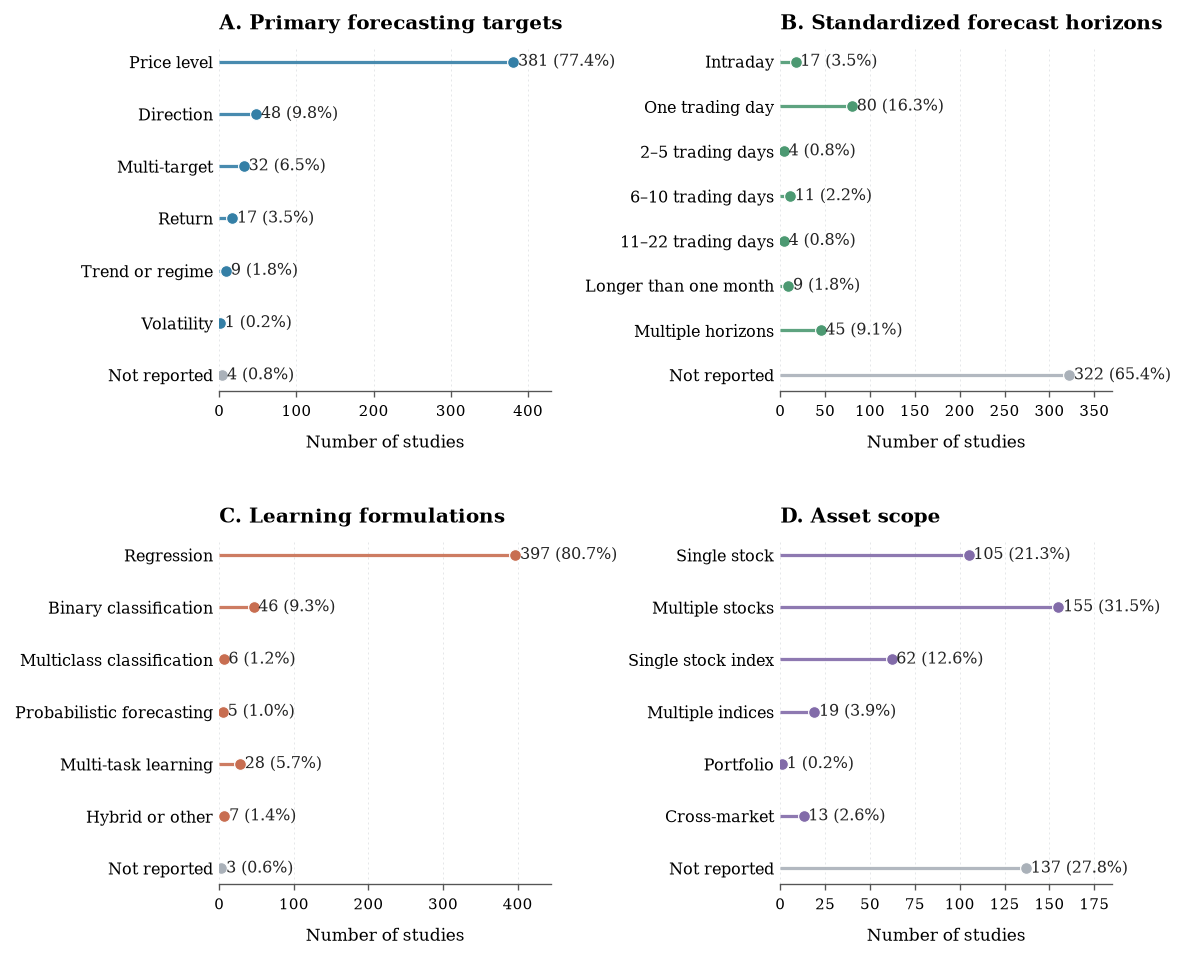


All Figure 12 count and integrity checks passed.

Primary forecasting targets:
  Price level                    381 (77.4%)
  Direction                       48 ( 9.8%)
  Multi-target                    32 ( 6.5%)
  Return                          17 ( 3.5%)
  Trend or regime                  9 ( 1.8%)
  Volatility                       1 ( 0.2%)
  Not reported                     4 ( 0.8%)

Standardized forecast horizons:
  Intraday                        17 ( 3.5%)
  One trading day                 80 (16.3%)
  2–5 trading days                 4 ( 0.8%)
  6–10 trading days               11 ( 2.2%)
  11–22 trading days               4 ( 0.8%)
  Longer than one month            9 ( 1.8%)
  Multiple horizons               45 ( 9.1%)
  Not reported                   322 (65.4%)

Learning formulations:
  Regression                     397 (80.7%)
  Binary classification           46 ( 9.3%)
  Multiclass classification        6 ( 1.2%)
  Probabilistic forecasting        5 ( 1.0%)
  Multi-

In [ ]:
from __future__ import annotations

from pathlib import Path
from typing import Final

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd


# ============================================================
# FIGURE 12
# Taxonomic profile of the 492-study technical synthesis
#
# A. Primary forecasting targets
# B. Standardized forecast horizons
# C. Learning formulations
# D. Asset scope
#
# SCIE Q1-ready lollipop-panel figure
# ============================================================


# ------------------------------------------------------------
# 1. PROJECT AND INPUT SETTINGS
# ------------------------------------------------------------

PROJECT_DIR: Final[Path] = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

WORKBOOK_NAME: Final[str] = (
    "Compiled Files.xlsx"
)

INPUT_CANDIDATES: Final[list[Path]] = [
    PROJECT_DIR / WORKBOOK_NAME,

    PROJECT_DIR
    / "06_Quality_Assessment"
    / WORKBOOK_NAME,

    PROJECT_DIR
    / "13_Systematic_Review_Section5"
    / WORKBOOK_NAME,

    PROJECT_DIR
    / "14_Sankey"
    / WORKBOOK_NAME,

    Path("/mnt/data") / WORKBOOK_NAME,
]

CODING_SHEET: Final[str] = "Section5_Coding_Consolidated"

OUTPUT_DIR: Final[Path] = PROJECT_DIR / "Figure12_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_STUDIES: Final[int] = 492
SHOW_FIGURE: Final[bool] = True


# ------------------------------------------------------------
# 2. OUTPUT SETTINGS
# ------------------------------------------------------------

BASE_NAME: Final[str] = (
    "Figure12_Taxonomic_Profile_SCIE_Q1_Final"
)

PDF_FILE = OUTPUT_DIR / f"{BASE_NAME}.pdf"
SVG_FILE = OUTPUT_DIR / f"{BASE_NAME}.svg"
PNG_FILE = OUTPUT_DIR / f"{BASE_NAME}.png"
SUMMARY_FILE = OUTPUT_DIR / f"{BASE_NAME}_Counts.csv"

PNG_DPI: Final[int] = 600

# Designed close to the final two-column printed width.
FIGURE_WIDTH: Final[float] = 7.35
FIGURE_HEIGHT: Final[float] = 6.35


# ------------------------------------------------------------
# 3. STYLE SETTINGS
# ------------------------------------------------------------

FONT_FAMILY: Final[str] = "Arial"

TEXT_COLOUR: Final[str] = "#252525"
GRID_COLOUR: Final[str] = "#D7DADD"
NEUTRAL_COLOUR: Final[str] = "#AAB1B9"

TARGET_COLOUR: Final[str] = "#347FA6"
HORIZON_COLOUR: Final[str] = "#4C9972"
FORMULATION_COLOUR: Final[str] = "#C86E51"
ASSET_COLOUR: Final[str] = "#826BA9"

STEM_WIDTH: Final[float] = 1.55
DOT_SIZE: Final[int] = 32

ANNOTATION_FONT_SIZE: Final[float] = 7.25
PANEL_TITLE_SIZE: Final[float] = 9.2
FOOTER_FONT_SIZE: Final[float] = 7.0


# ------------------------------------------------------------
# 4. TAXONOMIC DEFINITIONS
# ------------------------------------------------------------

TARGET_ORDER: Final[list[str]] = [
    "Price",
    "Direction",
    "Multi_Target",
    "Return",
    "Trend_Regime",
    "Volatility",
    "Not_Reported",
]

TARGET_LABELS: Final[dict[str, str]] = {
    "Price": "Price level",
    "Direction": "Direction",
    "Multi_Target": "Multi-target",
    "Return": "Return",
    "Trend_Regime": "Trend or regime",
    "Volatility": "Volatility",
    "Not_Reported": "Not reported",
}


HORIZON_ORDER: Final[list[str]] = [
    "Intraday",
    "One_Day",
    "Short_Multiday_2_5",
    "Weekly_6_10",
    "Monthly_11_22",
    "Longer_Than_Monthly",
    "Multiple_Horizons",
    "Not_Reported",
]

HORIZON_LABELS: Final[dict[str, str]] = {
    "Intraday": "Intraday",
    "One_Day": "One trading day",
    "Short_Multiday_2_5": "2–5 trading days",
    "Weekly_6_10": "6–10 trading days",
    "Monthly_11_22": "11–22 trading days",
    "Longer_Than_Monthly": "Longer than one month",
    "Multiple_Horizons": "Multiple horizons",
    "Not_Reported": "Not reported",
}


FORMULATION_ORDER: Final[list[str]] = [
    "Regression",
    "Binary_Classification",
    "Multiclass_Classification",
    "Probabilistic",
    "Multi_Task",
    "Hybrid_Other",
    "Not_Reported",
]

FORMULATION_LABELS: Final[dict[str, str]] = {
    "Regression": "Regression",
    "Binary_Classification": "Binary classification",
    "Multiclass_Classification": "Multiclass classification",
    "Probabilistic": "Probabilistic forecasting",
    "Multi_Task": "Multi-task learning",
    "Hybrid_Other": "Hybrid or other",
    "Not_Reported": "Not reported",
}


ASSET_ORDER: Final[list[str]] = [
    "Single_Stock",
    "Multiple_Stocks",
    "Stock_Index",
    "Multiple_Indices",
    "Portfolio",
    "Cross_Market",
    "Not_Reported",
]

ASSET_LABELS: Final[dict[str, str]] = {
    "Single_Stock": "Single stock",
    "Multiple_Stocks": "Multiple stocks",
    "Stock_Index": "Single stock index",
    "Multiple_Indices": "Multiple indices",
    "Portfolio": "Portfolio",
    "Cross_Market": "Cross-market",
    "Not_Reported": "Not reported",
}


# ------------------------------------------------------------
# 5. VERIFIED MANUSCRIPT COUNTS
# ------------------------------------------------------------
# These checks protect the published figure from silent coding drift.

EXPECTED_TARGET_COUNTS: Final[dict[str, int]] = {
    "Price": 381,
    "Direction": 48,
    "Multi_Target": 32,
    "Return": 17,
    "Trend_Regime": 9,
    "Volatility": 1,
    "Not_Reported": 4,
}

EXPECTED_HORIZON_COUNTS: Final[dict[str, int]] = {
    "Intraday": 17,
    "One_Day": 80,
    "Short_Multiday_2_5": 4,
    "Weekly_6_10": 11,
    "Monthly_11_22": 4,
    "Longer_Than_Monthly": 9,
    "Multiple_Horizons": 45,
    "Not_Reported": 322,
}

EXPECTED_FORMULATION_COUNTS: Final[dict[str, int]] = {
    "Regression": 397,
    "Binary_Classification": 46,
    "Multiclass_Classification": 6,
    "Probabilistic": 5,
    "Multi_Task": 28,
    "Hybrid_Other": 7,
    "Not_Reported": 3,
}

EXPECTED_ASSET_COUNTS: Final[dict[str, int]] = {
    "Single_Stock": 105,
    "Multiple_Stocks": 155,
    "Stock_Index": 62,
    "Multiple_Indices": 19,
    "Portfolio": 1,
    "Cross_Market": 13,
    "Not_Reported": 137,
}

# ------------------------------------------------------------
# 6. HELPER FUNCTIONS
# ------------------------------------------------------------

def clean(value: object) -> str:
    """Normalize repeated, leading, and trailing whitespace."""

    return " ".join(str(value or "").strip().split())


def find_input_file() -> Path:
    """Locate the authoritative methodological-coding workbook."""

    for candidate in INPUT_CANDIDATES:
        if candidate.is_file():
            return candidate

    recursive_matches = list(
        PROJECT_DIR.rglob(WORKBOOK_NAME)
    )

    if len(recursive_matches) == 1:
        return recursive_matches[0]

    if len(recursive_matches) > 1:
        raise RuntimeError(
            "More than one matching workbook was found:\n"
            + "\n".join(str(path) for path in recursive_matches)
            + "\n\nSet the intended file explicitly in INPUT_CANDIDATES."
        )

    raise FileNotFoundError(
        f"{WORKBOOK_NAME} was not found.\n\n"
        "Checked locations:\n"
        + "\n".join(str(path) for path in INPUT_CANDIDATES)
    )


def percentage(
    count: int,
    denominator: int = EXPECTED_STUDIES,
) -> float:
    """Calculate the percentage of the complete technical subset."""

    return 100.0 * count / denominator


def extract_counts(
    series: pd.Series,
    order: list[str],
) -> dict[str, int]:
    """Extract category counts in the prescribed manuscript order."""

    observed = series.value_counts()

    return {
        category: int(observed.get(category, 0))
        for category in order
    }


def validate_counts(
    section_name: str,
    observed: dict[str, int],
    expected: dict[str, int],
) -> None:
    """Stop execution when plotted counts differ from verified values."""

    if observed == expected:
        return

    rows = []

    for category, expected_count in expected.items():
        observed_count = observed.get(category, 0)

        if observed_count != expected_count:
            rows.append(
                {
                    "Category": category,
                    "Expected": expected_count,
                    "Observed": observed_count,
                }
            )

    comparison = pd.DataFrame(rows)

    raise AssertionError(
        f"{section_name} counts differ from the verified manuscript "
        "values:\n\n"
        + comparison.to_string(index=False)
    )


def draw_lollipop_panel(
    *,
    ax: plt.Axes,
    categories: list[str],
    labels: dict[str, str],
    counts: dict[str, int],
    title: str,
    primary_colour: str,
    x_limit: float,
    tick_step: float,
) -> None:
    """
    Draw one SCIE Q1-ready horizontal lollipop panel.

    Not-reported values are shown in neutral grey.
    """

    display_labels = [
        labels[category]
        for category in categories
    ]

    values = [
        counts[category]
        for category in categories
    ]

    colours = [
        (
            NEUTRAL_COLOUR
            if category == "Not_Reported"
            else primary_colour
        )
        for category in categories
    ]

    y_positions = np.arange(len(categories))

    for y, value, colour in zip(
        y_positions,
        values,
        colours,
    ):
        ax.hlines(
            y=y,
            xmin=0,
            xmax=value,
            color=colour,
            linewidth=STEM_WIDTH,
            alpha=0.90,
            zorder=2,
        )

        ax.scatter(
            value,
            y,
            s=DOT_SIZE,
            color=colour,
            edgecolor="white",
            linewidth=0.55,
            zorder=3,
        )

    annotation_offset = x_limit * 0.014

    for y, value in zip(
        y_positions,
        values,
    ):
        ax.text(
            value + annotation_offset,
            y,
            f"{value} ({percentage(value):.1f}%)",
            ha="left",
            va="center",
            fontsize=ANNOTATION_FONT_SIZE,
            color=TEXT_COLOUR,
            clip_on=False,
            zorder=4,
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(display_labels)
    ax.invert_yaxis()

    ax.set_xlim(0, x_limit)
    ax.xaxis.set_major_locator(
        MultipleLocator(tick_step)
    )

    ax.set_xlabel(
        "Number of studies",
        labelpad=7,
    )

    ax.set_title(
        title,
        loc="left",
        pad=8,
        fontsize=PANEL_TITLE_SIZE,
        fontweight="semibold",
    )

    ax.xaxis.grid(
        True,
        linestyle=(0, (2, 3)),
        linewidth=0.48,
        color=GRID_COLOUR,
        alpha=0.64,
        zorder=0,
    )

    ax.yaxis.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.spines["bottom"].set_color("#555555")
    ax.spines["bottom"].set_linewidth(0.65)

    ax.tick_params(
        axis="y",
        length=0,
        pad=3,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3,
        width=0.65,
        color="#555555",
    )


# ------------------------------------------------------------
# 7. LOAD AUTHORITATIVE CODING DATA
# ------------------------------------------------------------

# ------------------------------------------------------------
# 5. LOAD AUTHORITATIVE FINAL STUDY SET
# ------------------------------------------------------------

coding_all = pd.read_excel(
    COMPILED_FILE,
    sheet_name=CODING_SHEET,
    dtype=str,
    keep_default_na=False,
    engine="openpyxl",
)

family_all = pd.read_excel(
    FAMILY_REGISTER_FILE,
    sheet_name=FAMILY_SHEET,
    header=1,
    dtype=str,
    keep_default_na=False,
    engine="openpyxl",
)


# ------------------------------------------------------------
# Standardize strings
# ------------------------------------------------------------

for frame in [coding_all, family_all]:

    frame.columns = [
        str(column).strip()
        for column in frame.columns
    ]

    for column in frame.columns:
        frame[column] = (
            frame[column]
            .fillna("")
            .astype(str)
            .str.strip()
        )


# ------------------------------------------------------------
# Required columns
# ------------------------------------------------------------

required_coding_columns = {
    "Paper_ID",
    "Systematic_Inclusion_Status",
}

required_family_columns = {
    "Paper_ID",
    "Principal_Method_Family",
}


missing_coding = (
    required_coding_columns
    - set(coding_all.columns)
)

missing_family = (
    required_family_columns
    - set(family_all.columns)
)


if missing_coding:
    raise KeyError(
        "Missing columns in Compiled Files.xlsx:\n"
        f"{sorted(missing_coding)}"
    )

if missing_family:
    raise KeyError(
        "Missing columns in frozen family register:\n"
        f"{sorted(missing_family)}"
    )


# ------------------------------------------------------------
# Frozen 492-study included set
# ------------------------------------------------------------

coding = coding_all.loc[
    coding_all[
        "Systematic_Inclusion_Status"
    ].eq("Included_High_Priority")
].copy()


if len(coding) != EXPECTED_STUDIES:
    raise AssertionError(
        f"Expected {EXPECTED_STUDIES} final included studies; "
        f"found {len(coding)}."
    )


if coding["Paper_ID"].nunique() != EXPECTED_STUDIES:
    raise AssertionError(
        "Compiled workbook contains duplicate Paper_ID values."
    )


final_ids = set(
    coding["Paper_ID"]
)


# ------------------------------------------------------------
# Frozen principal-family register
# ------------------------------------------------------------

family_df = family_all.loc[
    family_all["Paper_ID"].isin(final_ids)
].copy()


if len(family_df) != EXPECTED_STUDIES:
    raise AssertionError(
        f"Expected {EXPECTED_STUDIES} family-coded records; "
        f"found {len(family_df)}."
    )


if family_df["Paper_ID"].nunique() != EXPECTED_STUDIES:
    raise AssertionError(
        "Duplicate Paper_ID values detected in family register."
    )


if set(family_df["Paper_ID"]) != final_ids:
    missing_family_ids = (
        final_ids - set(family_df["Paper_ID"])
    )

    extra_family_ids = (
        set(family_df["Paper_ID"]) - final_ids
    )

    raise AssertionError(
        "Paper_ID mismatch between compiled workbook "
        "and family register.\n"
        f"Missing family IDs: {sorted(missing_family_ids)}\n"
        f"Extra family IDs: {sorted(extra_family_ids)}"
    )


if family_df[
    "Principal_Method_Family"
].eq("").any():

    bad_ids = family_df.loc[
        family_df[
            "Principal_Method_Family"
        ].eq(""),
        "Paper_ID",
    ].tolist()

    raise AssertionError(
        "Blank Principal_Method_Family values found for:\n"
        f"{bad_ids}"
    )


# This becomes the plotting dataframe.
df = family_df.copy()


print("\nAuthoritative final study set:")
print(COMPILED_FILE)

print("\nFrozen family register:")
print(FAMILY_REGISTER_FILE)

print(
    f"\nFinal included studies: "
    f"{len(df):,}"
)


# ------------------------------------------------------------
# 8. STUDY-LEVEL INTEGRITY CHECKS
# ------------------------------------------------------------

if len(coding) != EXPECTED_STUDIES:
    raise AssertionError(
        f"Expected {EXPECTED_STUDIES} included studies; "
        f"found {len(coding)}."
    )

if coding["Paper_ID"].eq("").any():
    raise AssertionError(
        "One or more included records have a blank Paper_ID."
    )

if not coding["Paper_ID"].is_unique:
    duplicate_ids = (
        coding.loc[
            coding["Paper_ID"].duplicated(keep=False),
            "Paper_ID",
        ]
        .sort_values()
        .unique()
        .tolist()
    )

    raise AssertionError(
        "Duplicate Paper_ID values were found:\n"
        f"{duplicate_ids[:20]}"
    )


# ------------------------------------------------------------
# 9. EXTRACT AND VERIFY COUNTS
# ------------------------------------------------------------

target_counts = extract_counts(
    coding["Target_Primary"],
    TARGET_ORDER,
)

horizon_counts = extract_counts(
    coding["Horizon_Bucket"],
    HORIZON_ORDER,
)

formulation_counts = extract_counts(
    coding["Learning_Formulation"],
    FORMULATION_ORDER,
)

asset_counts = extract_counts(
    coding["Asset_Scope"],
    ASSET_ORDER,
)

print("\nObserved asset counts:")
print(asset_counts)

print("\nExpected asset counts:")
print(EXPECTED_ASSET_COUNTS)

print("\nObserved asset total:")
print(sum(asset_counts.values()))

validate_counts(
    "Primary forecasting target",
    target_counts,
    EXPECTED_TARGET_COUNTS,
)

validate_counts(
    "Forecast horizon",
    horizon_counts,
    EXPECTED_HORIZON_COUNTS,
)

validate_counts(
    "Learning formulation",
    formulation_counts,
    EXPECTED_FORMULATION_COUNTS,
)

validate_counts(
    "Asset scope",
    asset_counts,
    EXPECTED_ASSET_COUNTS,
)

for name, values in {
    "Target": target_counts,
    "Horizon": horizon_counts,
    "Formulation": formulation_counts,
    "Asset": asset_counts,
}.items():
    total = sum(values.values())

    if total != EXPECTED_STUDIES:
        raise AssertionError(
            f"{name} counts total {total}, not {EXPECTED_STUDIES}."
        )


# ------------------------------------------------------------
# 10. SAVE VERIFIED COUNT TABLE
# ------------------------------------------------------------

summary_rows = []

for category in TARGET_ORDER:
    summary_rows.append(
        {
            "Panel": "A",
            "Dimension": "Primary forecasting target",
            "Category": TARGET_LABELS[category],
            "Count": target_counts[category],
            "Percentage": percentage(target_counts[category]),
        }
    )

for category in HORIZON_ORDER:
    summary_rows.append(
        {
            "Panel": "B",
            "Dimension": "Standardized forecast horizon",
            "Category": HORIZON_LABELS[category],
            "Count": horizon_counts[category],
            "Percentage": percentage(horizon_counts[category]),
        }
    )

for category in FORMULATION_ORDER:
    summary_rows.append(
        {
            "Panel": "C",
            "Dimension": "Learning formulation",
            "Category": FORMULATION_LABELS[category],
            "Count": formulation_counts[category],
            "Percentage": percentage(formulation_counts[category]),
        }
    )

for category in ASSET_ORDER:
    summary_rows.append(
        {
            "Panel": "D",
            "Dimension": "Asset scope",
            "Category": ASSET_LABELS[category],
            "Count": asset_counts[category],
            "Percentage": percentage(asset_counts[category]),
        }
    )

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig",
    float_format="%.4f",
)


# ------------------------------------------------------------
# 11. MATPLOTLIB PUBLICATION SETTINGS
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 8.0,
    "axes.labelsize": 8.4,
    "xtick.labelsize": 7.3,
    "ytick.labelsize": 7.5,
})

ANNOTATION_FONT_SIZE = 7.45
PANEL_TITLE_SIZE = 9.4


# ------------------------------------------------------------
# 12. CREATE THE FOUR-PANEL FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    ),
    facecolor="white",
)

grid = fig.add_gridspec(
    nrows=2,
    ncols=2,
    left=0.175,
    right=0.985,
    top=0.955,
    bottom=0.075,
    wspace=0.69,
    hspace=0.43,
)

ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[1, 0])
ax_d = fig.add_subplot(grid[1, 1])


# ------------------------------------------------------------
# 13. PANEL A — FORECASTING TARGETS
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_a,
    categories=TARGET_ORDER,
    labels=TARGET_LABELS,
    counts=target_counts,
    title="A. Primary forecasting targets",
    primary_colour=TARGET_COLOUR,
    x_limit=430,
    tick_step=100,
)


# ------------------------------------------------------------
# 14. PANEL B — FORECAST HORIZONS
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_b,
    categories=HORIZON_ORDER,
    labels=HORIZON_LABELS,
    counts=horizon_counts,
    title="B. Standardized forecast horizons",
    primary_colour=HORIZON_COLOUR,
    x_limit=370,
    tick_step=50,
)


# ------------------------------------------------------------
# 15. PANEL C — LEARNING FORMULATIONS
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_c,
    categories=FORMULATION_ORDER,
    labels=FORMULATION_LABELS,
    counts=formulation_counts,
    title="C. Learning formulations",
    primary_colour=FORMULATION_COLOUR,
    x_limit=445,
    tick_step=100,
)


# ------------------------------------------------------------
# 16. PANEL D — ASSET SCOPE
# ------------------------------------------------------------

draw_lollipop_panel(
    ax=ax_d,
    categories=ASSET_ORDER,
    labels=ASSET_LABELS,
    counts=asset_counts,
    title="D. Asset scope",
    primary_colour=ASSET_COLOUR,
    x_limit=185,
    tick_step=25,
)


# ------------------------------------------------------------
# 17. FIGURE NOTE
# ------------------------------------------------------------




# ------------------------------------------------------------
# 18. EXPORT
# ------------------------------------------------------------

fig.savefig(
    PDF_FILE,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.025,
)

fig.savefig(
    SVG_FILE,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.025,
)

fig.savefig(
    PNG_FILE,
    format="png",
    dpi=PNG_DPI,
    bbox_inches="tight",
    pad_inches=0.025,
)

if SHOW_FIGURE:
    plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 19. FINAL REPORT
# ------------------------------------------------------------

print("\nAll Figure 12 count and integrity checks passed.")

print("\nPrimary forecasting targets:")
for category in TARGET_ORDER:
    count = target_counts[category]
    print(
        f"  {TARGET_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nStandardized forecast horizons:")
for category in HORIZON_ORDER:
    count = horizon_counts[category]
    print(
        f"  {HORIZON_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nLearning formulations:")
for category in FORMULATION_ORDER:
    count = formulation_counts[category]
    print(
        f"  {FORMULATION_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nAsset scope:")
for category in ASSET_ORDER:
    count = asset_counts[category]
    print(
        f"  {ASSET_LABELS[category]:30s} "
        f"{count:3d} ({percentage(count):4.1f}%)"
    )

print("\nCreated files:")

for output_file in [
    PDF_FILE,
    SVG_FILE,
    PNG_FILE,
    SUMMARY_FILE,
]:
    status = (
        "created"
        if output_file.exists()
        else "not created"
    )

    print(
        f"{status:12s} : {output_file}"
    )


Input workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Compiled Files.xlsx


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.



Rows loaded: 492


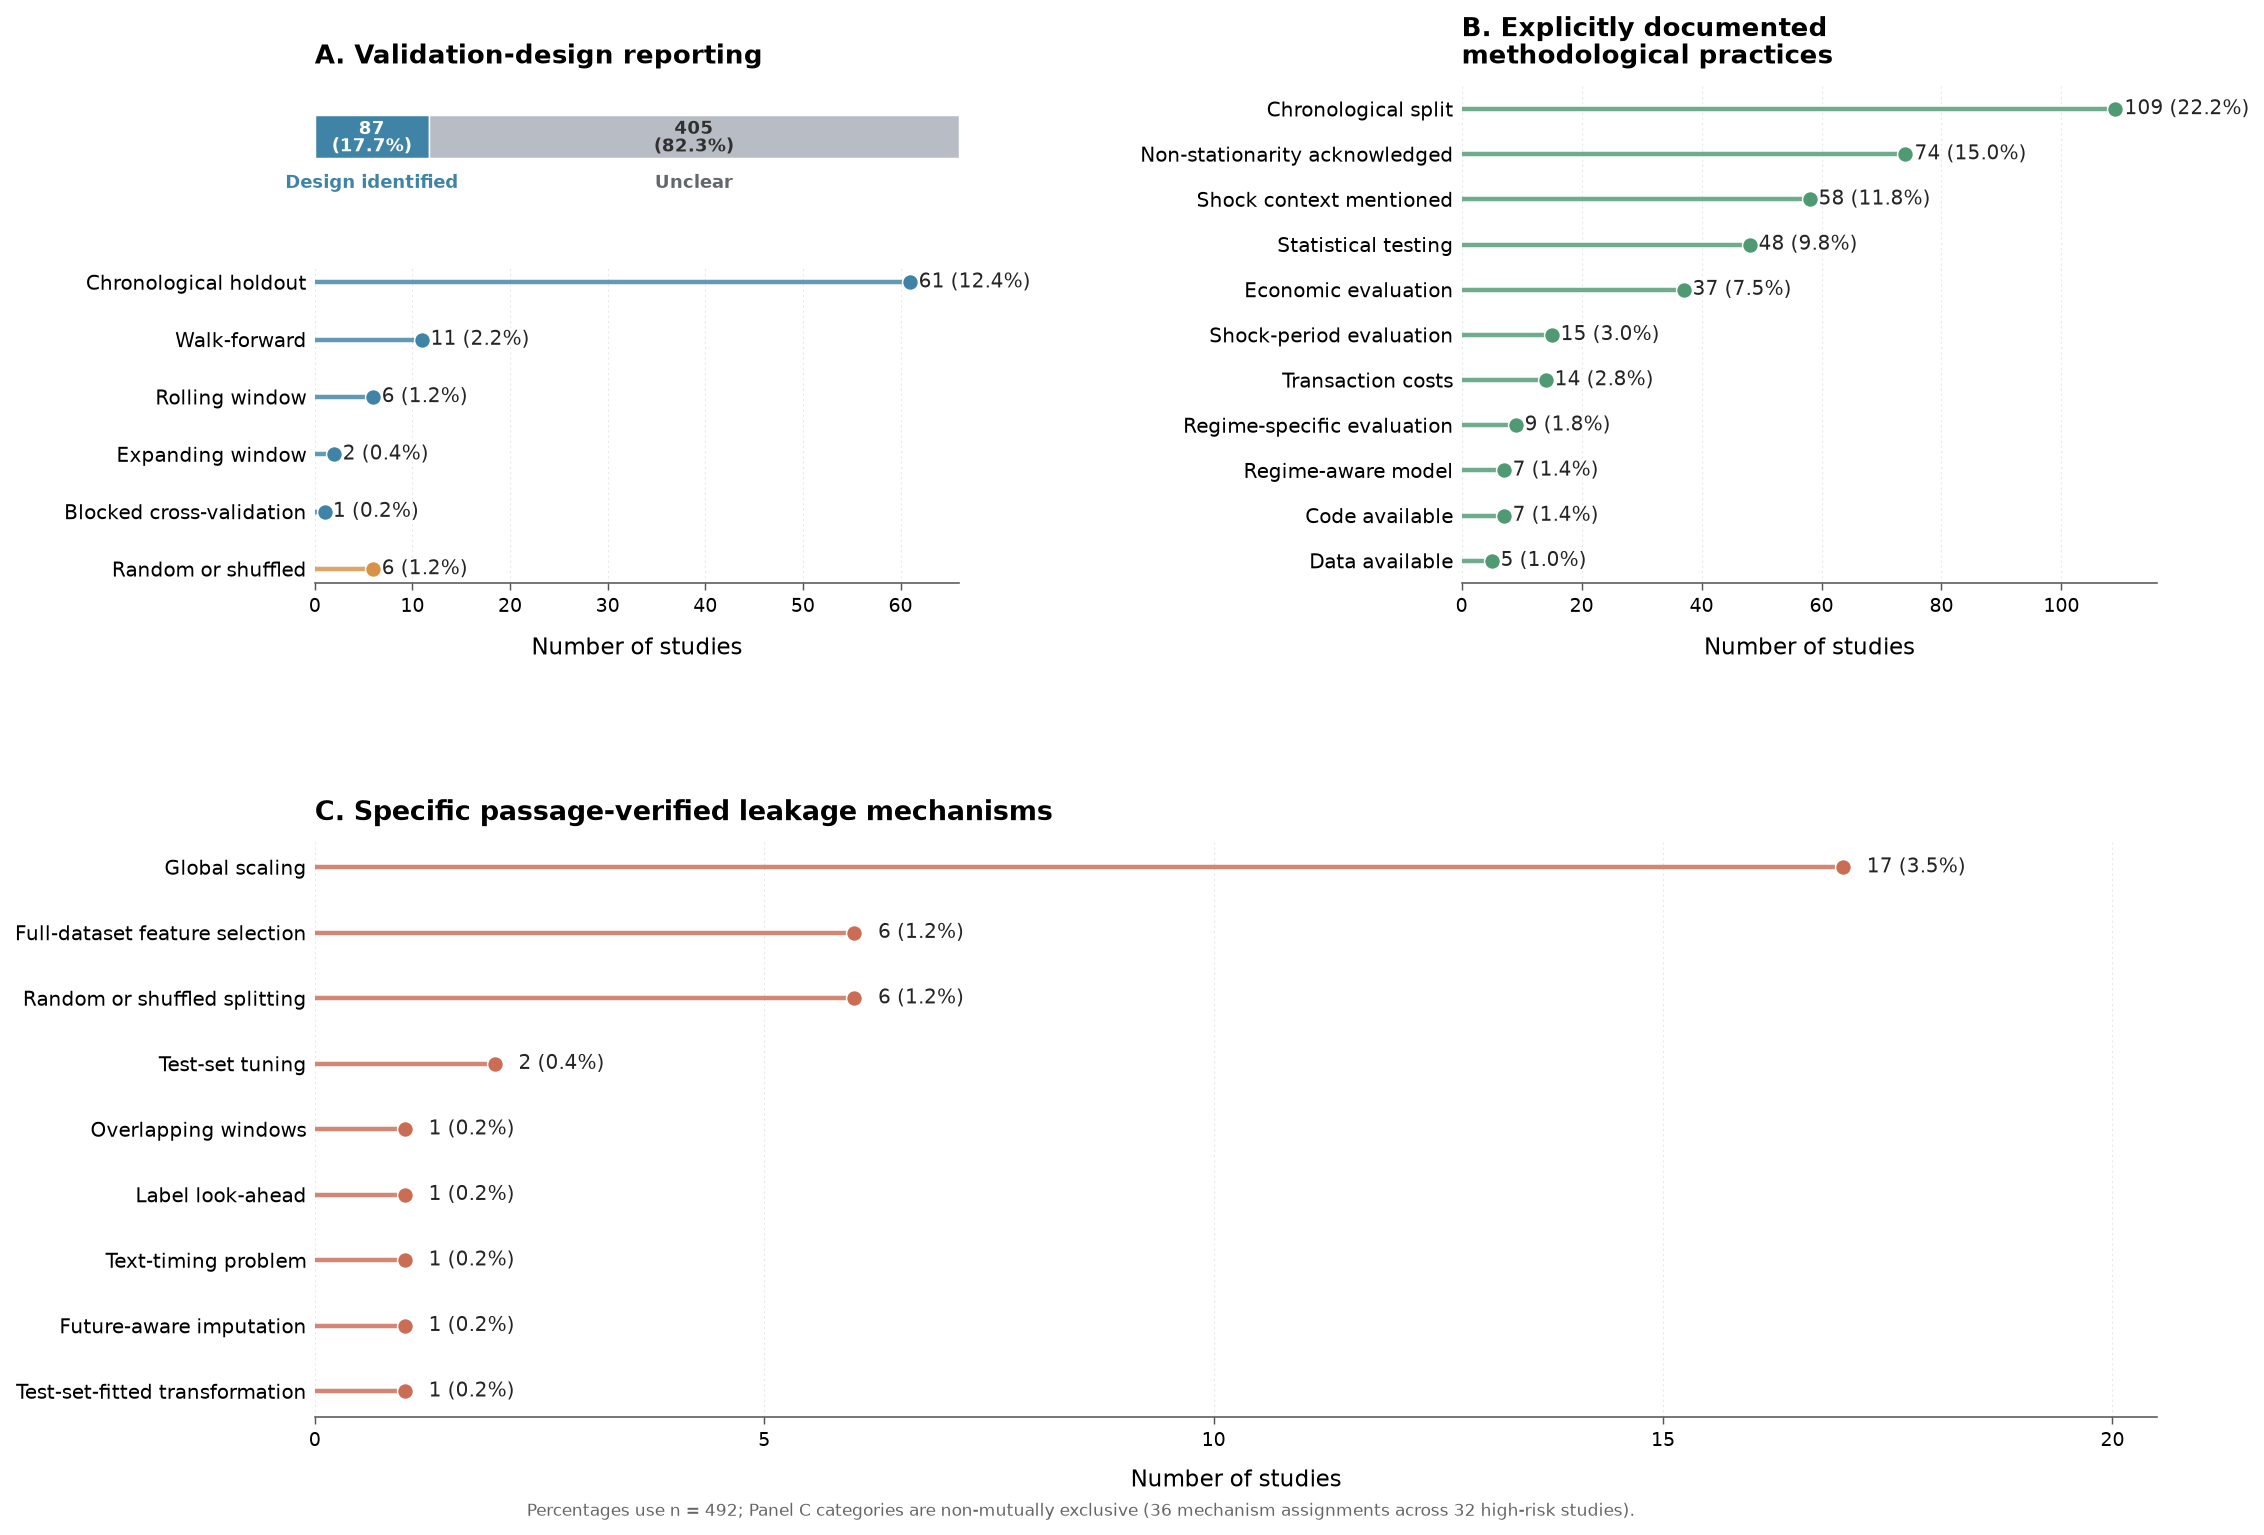


All count and integrity checks passed.

Panel A:
  Design identified       : 87 (17.7%)
  Temporally ordered      : 81 (16.5%)
  Random or shuffled      : 6 (1.2%)
  Unclear                 : 405 (82.3%)

Panel C:
  Mechanism assignments   : 36
  Unique high-risk studies: 32
  Low-risk studies        : 7
  Unclear-risk studies    : 453

Created files:
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Reconciled.png
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Reconciled.pdf
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Methodological_Reliability_Figure_Output/Methodological_Reliability_SCIE_Q1_Reconciled.svg
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Predicti

In [21]:
%reset -f
%run regenerate_figure13_reconciled.py


Authoritative workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Compiled Files.xlsx

Modality coding file:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/06_Quality_Assessment/Section6_Input_Modality_Audit/Section6_Explicit_Modality_Coding_493.csv

Raw modality CSV rows: 493

Old modality records excluded by the final compiled workbook:
['P04845']

Verified modality counts:
                                       Display_Label  Studies Share_Percent
                              Historical market data      293         59.7%
                                Technical indicators      117         23.8%
              Financial news and textual information       93         18.9%
        Decomposition or transformed representations       62         12.6%
          Social media or public-opinion information       42          8.6%
Index, sectoral, relational, or cross-market context       27          5.5%
               

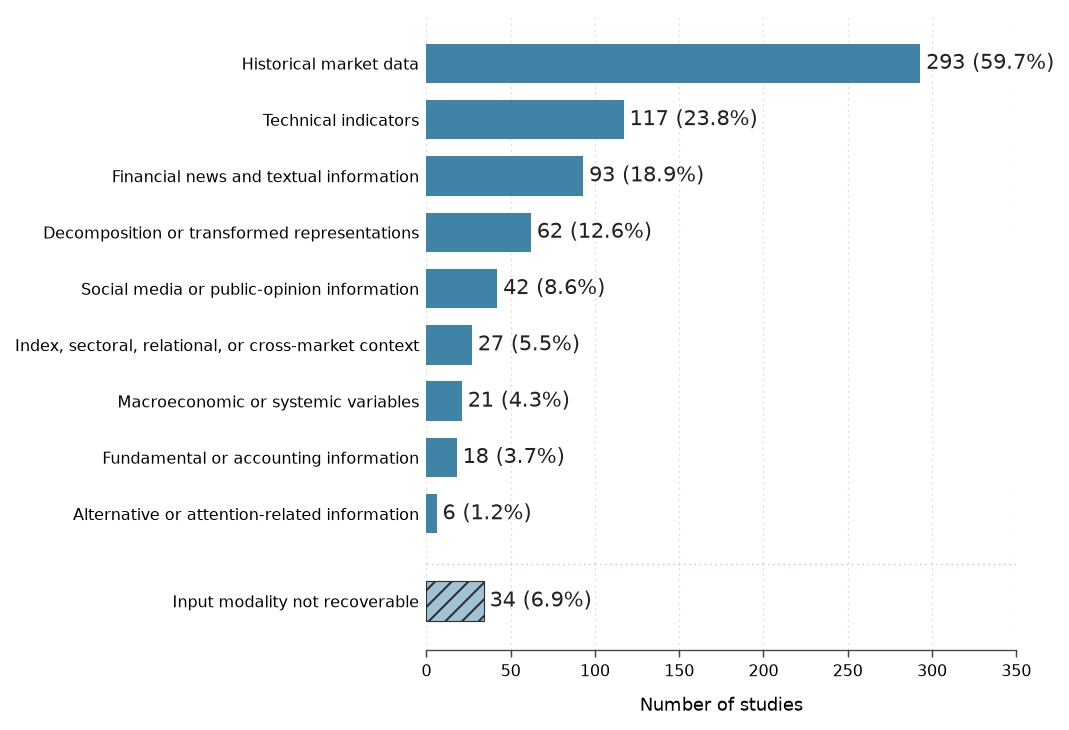


Validation passed:
  Technical-synthesis register : 492
  Section 6 applicable subset  : 491
  Recoverable modalities       : 457
  Not recoverable              : 34

Created files:
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure13_Output/Figure14_Input_Modality_Prevalence_SCIE_Q1.png
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure13_Output/Figure14_Input_Modality_Prevalence_SCIE_Q1.pdf
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure13_Output/Figure14_Input_Modality_Prevalence_SCIE_Q1.svg
created      : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure13_Output/Figure14_Input_Modality_Prevalence_SCIE_Q1_Counts.csv


In [22]:
from __future__ import annotations

from pathlib import Path
import math

import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# FIGURE 14
# Explicit input-data and feature-representation modalities
# SCIE Q1-ready horizontal bar chart
# ============================================================


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/home/harman/projects/SLR Stock Price Prediction/"
    "Stock_Price_Prediction_SLR_ACME"
)

WORKBOOK_FILE = PROJECT_DIR / "Compiled Files.xlsx"

MODALITY_FILE = (
    PROJECT_DIR
    / "06_Quality_Assessment"
    / "Section6_Input_Modality_Audit"
    / "Section6_Explicit_Modality_Coding_493.csv"
)

CODING_SHEET = "Section5_Coding_Consolidated"

OUTPUT_DIR = PROJECT_DIR / "Figure13_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for input_file in [WORKBOOK_FILE, MODALITY_FILE]:
    if not input_file.is_file():
        raise FileNotFoundError(
            f"Input file was not found:\n{input_file}"
        )

# ------------------------------------------------------------
# 2. SECTION 6 CORPUS BOUNDARY
# ------------------------------------------------------------

TECHNICAL_SYNTHESIS_SIZE = 492
SECTION6_APPLICABLE_SIZE = 491

INCLUDED_STATUS = "Included_High_Priority"

# P00814 remains in the frozen 492-study technical register
# but is not applicable to input-modality prevalence because
# it does not report an original forecasting experiment.
NON_APPLICABLE_IDS = {
    "P00814",
}


# ------------------------------------------------------------
# 3. EXACT MODALITY COLUMNS IN THE FINAL CSV
# ------------------------------------------------------------

CATEGORY_META = {
    "Historical_Market_Data":
        "Historical market data",

    "Technical_Indicators":
        "Technical indicators",

    "Financial_News_Text":
        "Financial news and textual information",

    "Decomposition_Transforms":
        "Decomposition or transformed representations",

    "Social_Media_Public_Opinion":
        "Social media or public-opinion information",

    "Index_Sector_CrossMarket":
        "Index, sectoral, relational, or cross-market context",

    "Macroeconomic_Systemic":
        "Macroeconomic or systemic variables",

    "Fundamental_Accounting":
        "Fundamental or accounting information",

    "Alternative_Attention_Data":
        "Alternative or attention-related information",
}

CATEGORY_COLUMNS = list(CATEGORY_META)

MISSING_COLUMN = "No_Recoverable_Input_Category"
MISSING_LABEL = "Input modality not recoverable"


# ------------------------------------------------------------
# 4. FROZEN VERIFIED COUNTS
# ------------------------------------------------------------

EXPECTED_COUNTS = {
    "Historical_Market_Data": 293,
    "Technical_Indicators": 117,
    "Financial_News_Text": 93,
    "Decomposition_Transforms": 62,
    "Social_Media_Public_Opinion": 42,
    "Index_Sector_CrossMarket": 27,
    "Macroeconomic_Systemic": 21,
    "Fundamental_Accounting": 18,
    "Alternative_Attention_Data": 6,
    MISSING_COLUMN: 34,
}


# ------------------------------------------------------------
# 5. FIGURE SETTINGS
# ------------------------------------------------------------

FIGURE_WIDTH = 7.35
FIGURE_HEIGHT = 4.95
PNG_DPI = 600

MAIN_BAR_COLOUR = "#3F83A6"
SPECIAL_BAR_COLOUR = "#9FC3D5"
SPECIAL_BAR_EDGE = "#303030"
SPECIAL_BAR_HATCH = "///"

GRID_COLOUR = "#C8C8C8"
TEXT_COLOUR = "#222222"
SEPARATOR_COLOUR = "#72A9C6"

BAR_HEIGHT = 0.70




# ------------------------------------------------------------
# 6. LOAD AUTHORITATIVE WORKBOOK + MODALITY CODING
# ------------------------------------------------------------

coding_all = pd.read_excel(
    WORKBOOK_FILE,
    sheet_name=CODING_SHEET,
    dtype=str,
    keep_default_na=False,
    engine="openpyxl",
)

modality_df = pd.read_csv(
    MODALITY_FILE,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

for frame in [coding_all, modality_df]:

    frame.columns = [
        str(column).strip()
        for column in frame.columns
    ]

    for column in frame.columns:
        frame[column] = (
            frame[column]
            .fillna("")
            .astype(str)
            .str.strip()
        )

print("\nAuthoritative workbook:")
print(WORKBOOK_FILE)

print("\nModality coding file:")
print(MODALITY_FILE)

print(
    f"\nRaw modality CSV rows: "
    f"{len(modality_df):,}"
)


# ------------------------------------------------------------
# 7. DEFINE THE FINAL 492-STUDY REGISTER FROM COMPILED EXCEL
# ------------------------------------------------------------

required_coding_columns = {
    "Paper_ID",
    "Systematic_Inclusion_Status",
}

missing = (
    required_coding_columns
    - set(coding_all.columns)
)

if missing:
    raise KeyError(
        "Missing required workbook columns:\n"
        f"{sorted(missing)}"
    )


coding = coding_all.loc[
    coding_all[
        "Systematic_Inclusion_Status"
    ].eq(INCLUDED_STATUS)
].copy()


if len(coding) != TECHNICAL_SYNTHESIS_SIZE:
    raise AssertionError(
        f"Expected {TECHNICAL_SYNTHESIS_SIZE} final included studies; "
        f"found {len(coding)}."
    )


if coding["Paper_ID"].nunique() != TECHNICAL_SYNTHESIS_SIZE:
    raise AssertionError(
        "Duplicate Paper_ID values found in the final "
        "technical-synthesis register."
    )


final_ids = set(
    coding["Paper_ID"]
)


csv_ids = set(
    modality_df["Paper_ID"]
)


missing_from_modality = (
    final_ids - csv_ids
)

obsolete_modality_records = (
    csv_ids - final_ids
)


if missing_from_modality:
    raise AssertionError(
        "Final technical studies are missing from the "
        "modality coding file:\n"
        f"{sorted(missing_from_modality)}"
    )


print(
    "\nOld modality records excluded by the "
    "final compiled workbook:"
)

print(
    sorted(obsolete_modality_records)
)

# Keep only studies that survive in the authoritative
# 492-study compiled register.

df = modality_df.loc[
    modality_df["Paper_ID"].isin(final_ids)
].copy()


if len(df) != TECHNICAL_SYNTHESIS_SIZE:
    raise AssertionError(
        f"Expected {TECHNICAL_SYNTHESIS_SIZE} modality rows "
        "after workbook reconciliation; "
        f"found {len(df)}."
    )


if df["Paper_ID"].nunique() != TECHNICAL_SYNTHESIS_SIZE:
    raise AssertionError(
        "Duplicate Paper_ID values remain after "
        "workbook reconciliation."
    )


# ------------------------------------------------------------
# 8. CREATE THE 491-STUDY SECTION 6 APPLICABLE SUBSET
# ------------------------------------------------------------

for paper_id in NON_APPLICABLE_IDS:

    occurrences = int(
        df["Paper_ID"].eq(paper_id).sum()
    )

    if occurrences != 1:
        raise AssertionError(
            f"{paper_id} should occur exactly once in the "
            "final 492-study register; "
            f"found {occurrences}."
        )


analysis_df = df.loc[
    ~df["Paper_ID"].isin(
        NON_APPLICABLE_IDS
    )
].copy()


if len(analysis_df) != SECTION6_APPLICABLE_SIZE:
    raise AssertionError(
        f"Expected {SECTION6_APPLICABLE_SIZE} "
        "Section 6 applicable studies; "
        f"found {len(analysis_df)}."
    )


# ------------------------------------------------------------
# 9. VALIDATE BINARY MODALITY FLAGS
# ------------------------------------------------------------

for column in CATEGORY_COLUMNS:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column],
        errors="raise",
    ).astype(int)

    unexpected_values = sorted(
        set(analysis_df[column].unique()) - {0, 1}
    )

    if unexpected_values:
        raise ValueError(
            f"{column} contains non-binary values:\n"
            f"{unexpected_values}"
        )


# ------------------------------------------------------------
# 10. RECOMPUTE MODALITY RECOVERABILITY
# ------------------------------------------------------------

analysis_df["Identified_Category_Count_Recomputed"] = (
    analysis_df[CATEGORY_COLUMNS]
    .sum(axis=1)
)

analysis_df[MISSING_COLUMN] = (
    analysis_df[
        "Identified_Category_Count_Recomputed"
    ]
    .eq(0)
    .astype(int)
)

recoverable_count = int(
    analysis_df[
        "Identified_Category_Count_Recomputed"
    ]
    .gt(0)
    .sum()
)

not_recoverable_count = int(
    analysis_df[MISSING_COLUMN].sum()
)

if recoverable_count != 457:
    raise AssertionError(
        f"Expected 457 recoverable studies; "
        f"found {recoverable_count}."
    )


if not_recoverable_count != 34:
    raise AssertionError(
        f"Expected 34 non-recoverable studies; "
        f"found {not_recoverable_count}."
    )


if (
    recoverable_count
    + not_recoverable_count
    != SECTION6_APPLICABLE_SIZE
):
    raise AssertionError(
        "Recoverability counts do not total "
        f"{SECTION6_APPLICABLE_SIZE}."
    )


# ------------------------------------------------------------
# 11. COMPUTE COUNTS AND PERCENTAGES
# ------------------------------------------------------------

summary_rows = []

for column in CATEGORY_COLUMNS:
    count = int(analysis_df[column].sum())

    summary_rows.append(
        {
            "Category_Key": column,
            "Display_Label": CATEGORY_META[column],
            "Studies": count,
            "Share_Percent":
                100 * count / SECTION6_APPLICABLE_SIZE,
            "Evidence_Class":
                "Explicit input modality",
        }
    )

summary_rows.append(
    {
        "Category_Key": MISSING_COLUMN,
        "Display_Label": MISSING_LABEL,
        "Studies": not_recoverable_count,
        "Share_Percent":
            100
            * not_recoverable_count
            / SECTION6_APPLICABLE_SIZE,
        "Evidence_Class":
            "Evidence-recovery status",
    }
)

summary_df = pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 12. DRIFT-DETECTION CHECK
# ------------------------------------------------------------

observed_counts = dict(
    zip(
        summary_df["Category_Key"],
        summary_df["Studies"],
    )
)

if observed_counts != EXPECTED_COUNTS:
    comparison_rows = []

    for category, expected in EXPECTED_COUNTS.items():
        comparison_rows.append(
            {
                "Category": category,
                "Expected": expected,
                "Observed": observed_counts.get(category),
            }
        )

    comparison_df = pd.DataFrame(comparison_rows)

    comparison_df = comparison_df.loc[
        comparison_df["Expected"]
        .ne(comparison_df["Observed"])
    ]

    raise AssertionError(
        "The final modality counts differ from the verified "
        "manuscript values:\n\n"
        + comparison_df.to_string(index=False)
    )

print("\nVerified modality counts:")

print(
    summary_df[
        [
            "Display_Label",
            "Studies",
            "Share_Percent",
        ]
    ]
    .assign(
        Share_Percent=lambda frame:
            frame["Share_Percent"].map(
                lambda value: f"{value:.1f}%"
            )
    )
    .to_string(index=False)
)


# ------------------------------------------------------------
# 13. PREPARE PLOT POSITIONS
# ------------------------------------------------------------

explicit_df = summary_df.loc[
    summary_df["Category_Key"].ne(MISSING_COLUMN)
].copy()

missing_df = summary_df.loc[
    summary_df["Category_Key"].eq(MISSING_COLUMN)
].copy()

# The explicit modality categories remain in the verified
# manuscript order. The non-recoverable evidence-status row is
# separated visually because it is not itself a modality.
plot_df = pd.concat(
    [explicit_df, missing_df],
    ignore_index=True,
)

explicit_count = len(explicit_df)

explicit_positions = list(
    range(explicit_count)
)

missing_position = explicit_count + 0.55

y_positions = (
    explicit_positions
    + [missing_position]
)


# ------------------------------------------------------------
# 14. MATPLOTLIB PUBLICATION SETTINGS
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Arial",
        "Liberation Sans",
        "DejaVu Sans",
    ],

    "font.size": 8.2,
    "axes.labelsize": 8.6,
    "axes.titlesize": 9.6,
    "xtick.labelsize": 7.6,
    "ytick.labelsize": 7.9,

    "axes.linewidth": 0.65,
    "axes.edgecolor": "#555555",

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

STEM_WIDTH = 1.45
DOT_SIZE = 30

# ------------------------------------------------------------
# 15. CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    )
)

bars = []

for position, (_, row) in zip(
    y_positions,
    plot_df.iterrows(),
):
    is_missing = (
        row["Category_Key"] == MISSING_COLUMN
    )

    if is_missing:
        container = ax.barh(
            position,
            row["Studies"],
            height=BAR_HEIGHT,
            color=SPECIAL_BAR_COLOUR,
            edgecolor=SPECIAL_BAR_EDGE,
            linewidth=0.55,
            hatch=SPECIAL_BAR_HATCH,
            zorder=3,
        )
    else:
        container = ax.barh(
            position,
            row["Studies"],
            height=BAR_HEIGHT,
            color=MAIN_BAR_COLOUR,
            edgecolor="none",
            linewidth=0,
            zorder=3,
        )

    bars.append(container.patches[0])


# ------------------------------------------------------------
# 16. AXES AND GRID
# ------------------------------------------------------------

ax.set_yticks(y_positions)

ax.set_yticklabels(
    plot_df["Display_Label"]
)

ax.invert_yaxis()

ax.set_xlabel(
    "Number of studies",
    labelpad=8,
)

ax.set_ylabel("")

maximum_count = int(
    plot_df["Studies"].max()
)

x_limit = int(
    math.ceil(
        (maximum_count * 1.18) / 50
    )
    * 50
)

ax.set_xlim(0, x_limit)

ax.set_xticks(
    range(
        0,
        x_limit + 1,
        50,
    )
)

ax.xaxis.grid(
    True,
    linestyle=(0, (2, 3)),
    linewidth=0.55,
    color=GRID_COLOUR,
    alpha=0.55,
    zorder=0,
)

ax.yaxis.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color(
    "#444444"
)

ax.tick_params(
    axis="y",
    length=0,
)

ax.tick_params(
    axis="x",
    direction="out",
    length=3.5,
    width=0.7,
    color="#444444",
)


# ------------------------------------------------------------
# 17. COUNT AND PERCENTAGE LABELS
# ------------------------------------------------------------

label_offset = max(
    2.0,
    maximum_count * 0.012,
)

for bar, (_, row) in zip(
    bars,
    plot_df.iterrows(),
):
    ax.text(
        bar.get_width() + label_offset,
        bar.get_y() + bar.get_height() / 2,
        (
            f"{int(row['Studies'])} "
            f"({float(row['Share_Percent']):.1f}%)"
        ),
        ha="left",
        va="center",
        fontsize=10,
        color=TEXT_COLOUR,
        clip_on=False,
        zorder=5,
    )


# ------------------------------------------------------------
# 18. SEPARATE THE EVIDENCE-STATUS ROW
# ------------------------------------------------------------

separator_y = (
    explicit_count - 0.10
)

ax.axhline(
    y=separator_y,
    color="#9CC7DA",
    linewidth=0.70,
    linestyle=(0, (1.2, 2.4)),
    alpha=0.75,
    zorder=2,
)


# ------------------------------------------------------------
# 19. LAYOUT
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.43,
    right=0.965,
    top=0.975,
    bottom=0.12,
)


# ------------------------------------------------------------
# 20. EXPORT
# ------------------------------------------------------------

BASE_NAME = (
    "Figure14_Input_Modality_"
    "Prevalence_SCIE_Q1"
)

PNG_FILE = OUTPUT_DIR / f"{BASE_NAME}.png"
PDF_FILE = OUTPUT_DIR / f"{BASE_NAME}.pdf"
SVG_FILE = OUTPUT_DIR / f"{BASE_NAME}.svg"
SUMMARY_FILE = OUTPUT_DIR / f"{BASE_NAME}_Counts.csv"

summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig",
    float_format="%.4f",
)

fig.savefig(
    PNG_FILE,
    dpi=PNG_DPI,
    bbox_inches="tight",
    pad_inches=0.04,
)

fig.savefig(
    PDF_FILE,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.04,
)

fig.savefig(
    SVG_FILE,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.04,
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 21. FINAL REPORT
# ------------------------------------------------------------

print("\nValidation passed:")
print(f"  Technical-synthesis register : {len(df):,}")
print(f"  Section 6 applicable subset  : {len(analysis_df):,}")
print(f"  Recoverable modalities       : {recoverable_count:,}")
print(f"  Not recoverable              : {not_recoverable_count:,}")

print("\nCreated files:")

for output_file in [
    PNG_FILE,
    PDF_FILE,
    SVG_FILE,
    SUMMARY_FILE,
]:
    status = (
        "created"
        if output_file.exists()
        else "not created"
    )

    print(
        f"{status:12s} : {output_file}"
    )


Compiled workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Compiled Files.xlsx

Method-family review queue:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Reference_Outputs/Section7_Method_Family_Review_Queue.csv

Finalized baseline family map:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Legacy record removed by final full-text reconciliation:
['P04845']


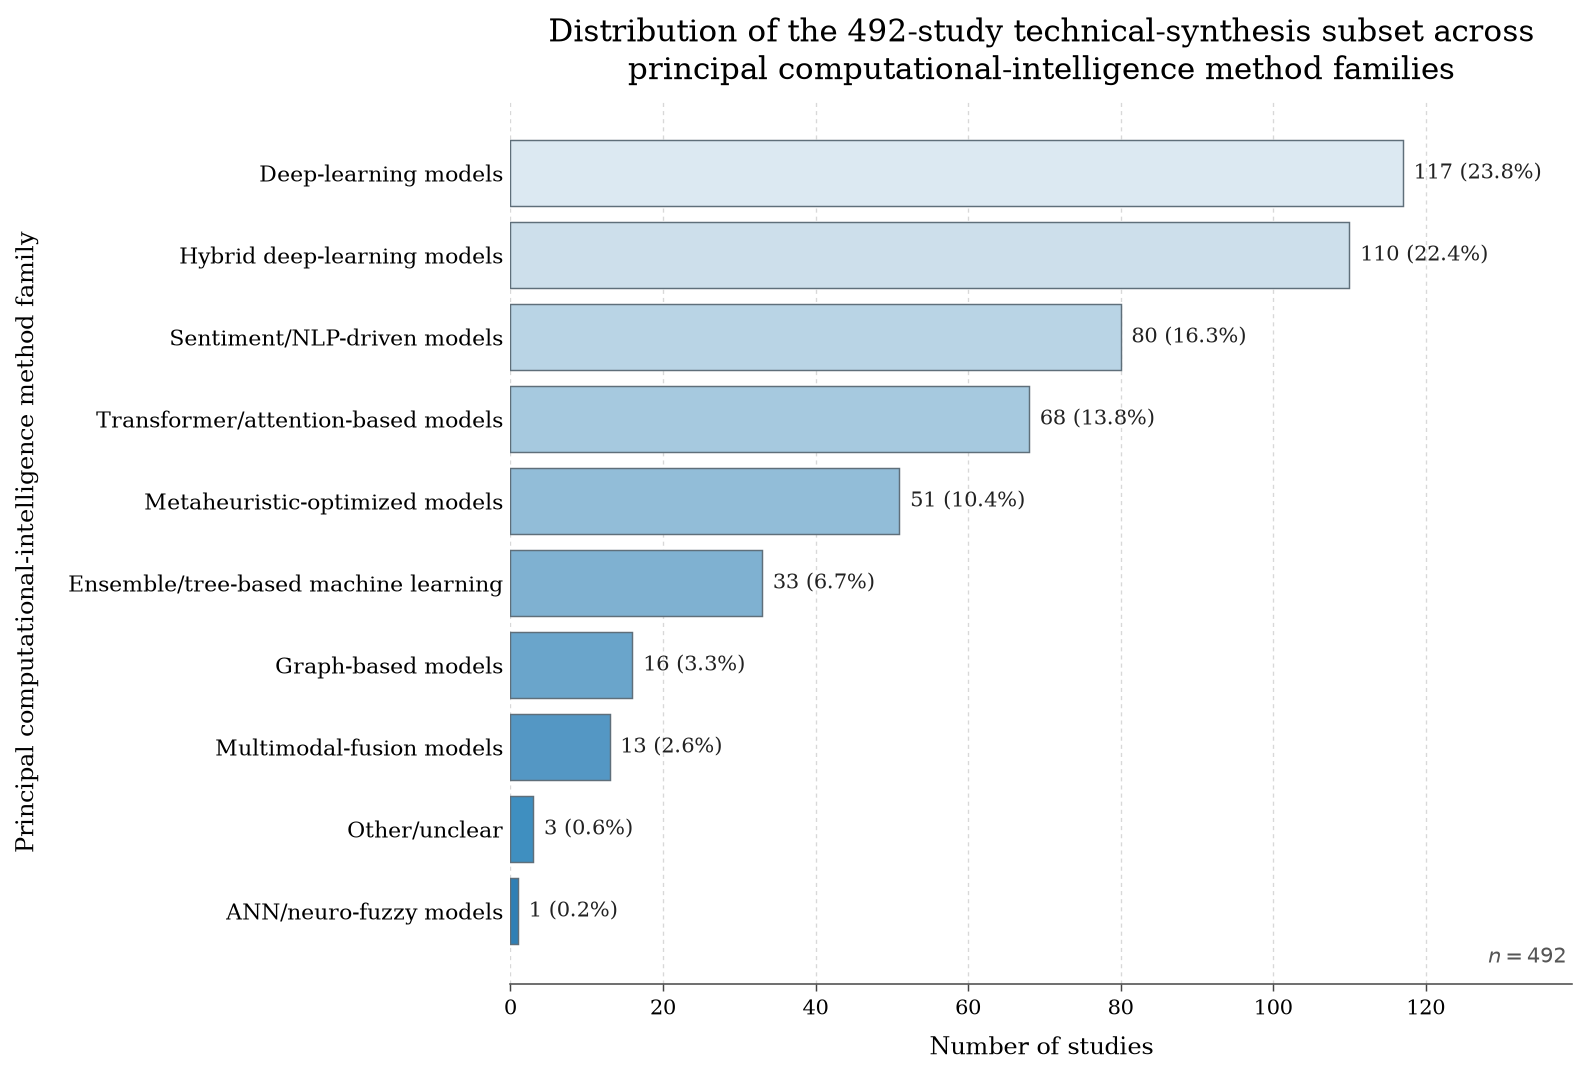


Validation passed:
  Frozen study rows      : 492
  Unique Paper_ID        : 492
  Principal families     : 10
  Total family count     : 492

Final adjudicated records:
  P00057: Deep-learning models
  P00909: Hybrid deep-learning models
  P03446: Other/unclear
  P04845: excluded from final technical synthesis

Observed method-family distribution:
             Principal_Method_Family  Count Percentage
                Deep-learning models    117      23.8%
         Hybrid deep-learning models    110      22.4%
         Sentiment/NLP-driven models     80      16.3%
  Transformer/attention-based models     68      13.8%
      Metaheuristic-optimized models     51      10.4%
Ensemble/tree-based machine learning     33       6.7%
                  Graph-based models     16       3.3%
            Multimodal-fusion models     13       2.6%
                       Other/unclear      3       0.6%
              ANN/neuro-fuzzy models      1       0.2%

Created files:
created      : /home/harman

In [31]:
%reset -f
%run Section7_Method_Family_Distribution_492_Final.py

In [1]:
%reset -f
%run Figure16_Period_Method_Target_Sankey_492_Final.py

Legacy Sankey input:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Authoritative compiled workbook:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Compiled Files.xlsx

Legacy record removed by final reconciliation: ['P04845']



Figure 16 Sankey audit passed.

Input:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/07_Systematic_Review_Dataset/Section7_Final_Study_Level_Sankey_Input.csv

Output directory:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output

Flow audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1_Flows.csv

Validation audit:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1_Audit.csv

Interactive HTML:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1.html

Vector PDF:
/home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure16_Output/Figure16_Period_Method_Target_Sankey_SCIE_Q1.pdf

Vector SVG:
/home/harman/pro

In [3]:
%reset -f
%run Figure17_Method_Validation_Preprocessing_492_Final.py

Project directory : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME
Input directory   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey
Method workbook   : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/14_Sankey/Section7_Sankey_Working_COMPLETED.xlsx
Compiled workbook : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Compiled Files.xlsx
Output directory  : /home/harman/projects/SLR Stock Price Prediction/Stock_Price_Prediction_SLR_ACME/Figure17_Output

All required input files were found successfully.

Legacy method-family records excluded by the frozen workbook:
['P04845']

Merged frozen records: 492

METHOD-FAMILY TOTALS
Method_Group
Deep and hybrid deep learning         227
Transformer, graph, and multimodal     97
Metaheuristic and ensemble             84
Sentiment and NLP                      80
Sparse and other families               4
Na